In [5]:
# ============================================================
# RSNA KNEE ABNORMALITY DETECTION — V2
# MASTER CONFIGURATION
# ============================================================

import os
import gc
import json
import math
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    try:
        import torch

        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        # Faster training on Kaggle GPU.
        # We don't require bit-for-bit deterministic CUDA.
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

    except ImportError:
        pass


seed_everything(SEED)


# ============================================================
# PATHS
# ============================================================

import os
from pathlib import Path

# Authenticate with Kaggle using the provided API token
os.environ["KAGGLE_API_TOKEN"] = "KGAT_112f1e2ffafc9504b0856980069c33cc"

# Define local directories
DATA_DIR = Path("./data/rsna-knee-abnormality-detection")
WORK_DIR = Path("./working")

# ------------------------------------------------------------
# IMPORTANT NOTE REGARDING THE DATASET (247 GB):
# ------------------------------------------------------------
# The RSNA dataset is extremely large. The automatic download
# logic has been disabled to prevent filling up your local hard drive.
# 
# Since the code heavily relies on reading physical .dcm files using Path.glob(),
# it is technically impossible to "stream" the dataset transparently via the API.
# 
# Options to proceed locally:
# 1. Manually download only the CSV files (train.csv, etc.) if you just want to view metadata.
# 2. Download a small subset of the training images manually into `./data/rsna-knee-abnormality-detection`
# 3. If you want to train on the full dataset, it is highly recommended to run this notebook in Kaggle Kernels or Google Colab.

CACHE_V2_DIR = WORK_DIR / "mri_cache_v2"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
OOF_DIR = WORK_DIR / "oof"
SUBMISSION_DIR = WORK_DIR / "submissions"

for path in [
    CACHE_V2_DIR,
    CHECKPOINT_DIR,
    OOF_DIR,
    SUBMISSION_DIR
]:
    path.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# TARGETS
# ============================================================

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

PLANES = [
    "Sagittal",
    "Coronal",
    "Axial"
]

N_TARGETS = len(TARGETS)
N_PLANES = len(PLANES)


# ============================================================
# V2 IMAGE CONFIGURATION
# ============================================================

N_SLICES = 24
IMG_SIZE = 256

# Keep central 80% of each stack.
CENTRAL_KEEP = 0.80

CACHE_DTYPE = np.uint8


# ============================================================
# TRAINING CONFIGURATION
# ============================================================

BATCH_SIZE = 4
NUM_WORKERS = 4

EPOCHS = 12

LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-2

WARMUP_EPOCHS = 1

GRAD_CLIP = 1.0

AMP_ENABLED = True


# ============================================================
# EXPERIMENT ID
# ============================================================

EXPERIMENT_NAME = (
    "v2_2p5d_mil_24slice_256"
)


print("=" * 65)
print("RSNA KNEE ABNORMALITY DETECTION — V2")
print("=" * 65)

print(f"Seed             : {SEED}")
print(f"Data directory   : {DATA_DIR}")
print(f"Cache directory  : {CACHE_V2_DIR}")
print(f"Targets          : {N_TARGETS}")
print(f"Planes           : {PLANES}")
print(f"Slices           : {N_SLICES}")
print(f"Image size       : {IMG_SIZE}")
print(f"Central keep     : {CENTRAL_KEEP}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Epochs           : {EPOCHS}")
print(f"Learning rate    : {LEARNING_RATE}")
print(f"Weight decay     : {WEIGHT_DECAY}")
print(f"Experiment       : {EXPERIMENT_NAME}")

RSNA KNEE ABNORMALITY DETECTION — V2
Seed             : 42
Data directory   : /kaggle/input/competitions/rsna-knee-abnormality-detection
Cache directory  : /kaggle/working/mri_cache_v2
Targets          : 12
Planes           : ['Sagittal', 'Coronal', 'Axial']
Slices           : 24
Image size       : 256
Central keep     : 0.8
Batch size       : 4
Epochs           : 12
Learning rate    : 0.0002
Weight decay     : 0.01
Experiment       : v2_2p5d_mil_24slice_256


In [6]:
import torch
import torchvision
import sklearn

print("=" * 65)
print("ENVIRONMENT AUDIT")
print("=" * 65)

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("sklearn     :", sklearn.__version__)

print()
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    props = torch.cuda.get_device_properties(0)

    print(
        "GPU memory:",
        round(
            props.total_memory / 1024**3,
            2
        ),
        "GB"
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )

print()
print("CPU count:", os.cpu_count())

ENVIRONMENT AUDIT
PyTorch     : 2.11.0+cu128
Torchvision : 0.26.0+cu128
sklearn     : 1.6.1

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB
CUDA version: 12.8

CPU count: 4


In [7]:
# ============================================================
# LOAD COMPETITION DATA
# ============================================================

train = pd.read_csv(
    DATA_DIR / "train.csv"
)

train_series = pd.read_csv(
    DATA_DIR / "train_series.csv"
)

test = pd.read_csv(
    DATA_DIR / "test.csv"
)

test_series = pd.read_csv(
    DATA_DIR / "test_series.csv"
)

sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)


print("=" * 65)
print("DATASET SHAPES")
print("=" * 65)

print("train            :", train.shape)
print("train_series     :", train_series.shape)
print("test             :", test.shape)
print("test_series      :", test_series.shape)
print("sample_submission:", sample_submission.shape)

DATASET SHAPES
train            : (4407, 14)
train_series     : (24371, 5)
test             : (3, 1)
test_series      : (15, 5)
sample_submission: (3, 13)


In [8]:
print("=" * 65)
print("DATASET AUDIT")
print("=" * 65)

print("\nTrain columns:")
print(train.columns.tolist())

print("\nSeries columns:")
print(train_series.columns.tolist())

print("\nTarget completeness:")
display(
    train[TARGETS]
    .notna()
    .sum()
    .rename("labelled_studies")
    .to_frame()
)

gold_mask = train[TARGETS].notna().all(axis=1)

print("\nGold studies:", int(gold_mask.sum()))
print("Non-gold studies:", int((~gold_mask).sum()))

print("\nSeries plane distribution:")
display(
    train_series["Anatomical_Plane"]
    .value_counts(dropna=False)
)

print("\nFluid-sensitive distribution:")
display(
    train_series["Fluid_Sensitive"]
    .value_counts(dropna=False)
)

print("\nFat-suppression distribution:")
display(
    train_series["Fat_Suppression"]
    .value_counts(dropna=False)
)

DATASET AUDIT

Train columns:
['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

Series columns:
['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']

Target completeness:


,labelled_studies
ACL,58
MCL,58
Medial Meniscus,58
Lateral Meniscus,58
Medial OA,58
Lateral OA,58
PF OA,58
Effusion,58
Synovitis,58
Baker's,58



Gold studies: 58
Non-gold studies: 4349

Series plane distribution:


Anatomical_Plane
Sagittal    9864
Coronal     8609
Axial       5898
Name: count, dtype: int64


Fluid-sensitive distribution:


Fluid_Sensitive
1    14010
0    10361
Name: count, dtype: int64


Fat-suppression distribution:


Fat_Suppression
1    14010
0    10361
Name: count, dtype: int64

In [9]:
# ============================================================
# EXPERIMENT LOG
# ============================================================

EXPERIMENT_LOG = WORK_DIR / "experiments.csv"

EXPERIMENT_COLUMNS = [
    "id",
    "date",
    "experiment",
    "change",
    "fold",
    "A_oof_auc",
    "B_gold_auc",
    "B_ci_low",
    "B_ci_high",
    "lb_auc",
    "train_min",
    "infer_min",
    "notes"
]

if EXPERIMENT_LOG.exists():

    experiments = pd.read_csv(
        EXPERIMENT_LOG
    )

else:

    experiments = pd.DataFrame(
        columns=EXPERIMENT_COLUMNS
    )

print(
    "Existing experiments:",
    len(experiments)
)

Existing experiments: 0


In [10]:
import pydicom

# Pick one study with all three planes
series_counts = (
    train_series
    .groupby(["StudyInstanceUID", "Anatomical_Plane"])
    .size()
    .unstack(fill_value=0)
)

complete_studies = series_counts[
    (series_counts.get("Sagittal", 0) > 0) &
    (series_counts.get("Coronal", 0) > 0) &
    (series_counts.get("Axial", 0) > 0)
].index.tolist()

sample_study = complete_studies[0]

print("Sample study:")
print(sample_study)

display(
    train_series[
        train_series["StudyInstanceUID"] == sample_study
    ]
)

Sample study:
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [11]:
def get_series_path(
    study_id,
    series_id,
    folder="train_series"
):
    return (
        DATA_DIR
        / folder
        / str(study_id)
        / str(series_id)
    )


sample_rows = (
    train_series[
        train_series["StudyInstanceUID"] == sample_study
    ]
    .sort_values(
        ["Anatomical_Plane", "Fluid_Sensitive"],
        ascending=[True, False]
    )
    .drop_duplicates("Anatomical_Plane")
)

for _, row in sample_rows.iterrows():

    series_path = get_series_path(
        sample_study,
        row["SeriesInstanceUID"]
    )

    dcm_files = sorted(
        series_path.glob("*.dcm")
    )

    if not dcm_files:
        continue

    ds = pydicom.dcmread(
        dcm_files[0],
        stop_before_pixels=True
    )

    print("=" * 70)
    print("Plane:", row["Anatomical_Plane"])
    print("Series:", row["SeriesInstanceUID"])
    print("Number of files:", len(dcm_files))
    print("ImageOrientationPatient:",
          getattr(ds, "ImageOrientationPatient", None))
    print("ImagePositionPatient:",
          getattr(ds, "ImagePositionPatient", None))
    print("InstanceNumber:",
          getattr(ds, "InstanceNumber", None))
    print("PixelSpacing:",
          getattr(ds, "PixelSpacing", None))
    print("Rows × Columns:",
          getattr(ds, "Rows", None),
          "×",
          getattr(ds, "Columns", None))

Plane: Axial
Series: 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265
Number of files: 18
ImageOrientationPatient: [0.99478304386138, -0.1011089235544, 0.01355419494211, 0.09998968243598, 0.99273771047592, 0.06688710302114]
ImagePositionPatient: [-196.1592016129, -134.40841959103, 38.2589832900342]
InstanceNumber: 14
PixelSpacing: [0.28771233558654, 0.28771233558654]
Rows × Columns: 560 × 560
Plane: Coronal
Series: 1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697
Number of files: 16
ImageOrientationPatient: [0.99682223796844, -0.0789138898253, -0.0108658866956, -0.0051275272853, 0.07255844771862, -0.9973509907722]
ImagePositionPatient: [-193.9923261304, -94.451664347692, 96.5132622562407]
InstanceNumber: 3
PixelSpacing: [0.30745044350624, 0.30745044350624]
Rows × Columns: 560 × 560
Plane: Sagittal
Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Number of files: 22
ImageOrientationPatient: [-0.0334932804107, 0.99921125173568, 0.02

In [13]:
def get_slice_position(ds):
    """
    Determine the scalar position of a DICOM slice
    along the slice-stacking direction.

    Uses ImageOrientationPatient when available.
    Falls back to InstanceNumber.
    """

    try:
        orientation = np.asarray(
            ds.ImageOrientationPatient,
            dtype=np.float64
        )

        row_direction = orientation[:3]
        column_direction = orientation[3:]

        # Direction perpendicular to the image plane
        normal = np.cross(
            row_direction,
            column_direction
        )

        position = np.asarray(
            ds.ImagePositionPatient,
            dtype=np.float64
        )

        # Project patient position onto slice normal.
        scalar_position = np.dot(
            position,
            normal
        )

        return float(scalar_position)

    except Exception:

        return float(
            getattr(
                ds,
                "InstanceNumber",
                0
            )
        )

In [14]:
# ============================================================
# CELL 9 — Inspect anatomical slice ordering
# ============================================================

def inspect_series_order(series_path, n_show=8):

    series_path = Path(series_path)

    files = sorted([
        p for p in series_path.iterdir()
        if p.is_file()
    ])

    records = []

    for file_path in files:

        ds = pydicom.dcmread(
            str(file_path),
            stop_before_pixels=True,
            force=True
        )

        records.append({
            "file": file_path.name,
            "instance_number": getattr(
                ds, "InstanceNumber", None
            ),
            "slice_position": get_slice_position(ds),
        })

    result = pd.DataFrame(records)

    print(f"\nSeries: {series_path.name}")
    print(f"Number of files: {len(result)}")

    print("\nOriginal order:")
    display(result.head(n_show))

    print("\nAnatomically sorted:")
    display(
        result
        .sort_values("slice_position")
        .head(n_show)
    )

    positions = (
        result["slice_position"]
        .dropna()
        .sort_values()
        .to_numpy()
    )

    if len(positions) > 1:

        spacings = np.diff(positions)

        print("\nSlice position range:")
        print(
            f"  {positions.min():.4f}"
            f" → "
            f"{positions.max():.4f}"
        )

        print("\nAdjacent slice spacing:")
        print(
            f"  Median: "
            f"{np.median(np.abs(spacings)):.4f}"
        )
        print(
            f"  Min: "
            f"{np.min(np.abs(spacings)):.4f}"
        )
        print(
            f"  Max: "
            f"{np.max(np.abs(spacings)):.4f}"
        )

    return result.sort_values(
        "slice_position"
    ).reset_index(drop=True)


# ------------------------------------------------------------
# Use the FIRST study we already inspected
# ------------------------------------------------------------

sample_study_id = train_series.iloc[0]["StudyInstanceUID"]

sample_series = train_series[
    train_series["StudyInstanceUID"] == sample_study_id
]

print("Sample study:")
print(sample_study_id)

display(
    sample_series[
        [
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "Fluid_Sensitive",
            "Fat_Suppression",
            "Anatomical_Plane",
        ]
    ]
)

# ------------------------------------------------------------
# Inspect one series from each plane
# ------------------------------------------------------------

for _, row in (
    sample_series
    .groupby("Anatomical_Plane")
    .head(1)
    .iterrows()
):

    series_path = (
        DATA_DIR
        / "train_series"
        / str(row["StudyInstanceUID"])
        / str(row["SeriesInstanceUID"])
    )

    print("\n" + "=" * 70)
    print(f"Plane: {row['Anatomical_Plane']}")
    print(f"Series: {row['SeriesInstanceUID']}")

    inspect_series_order(series_path)

Sample study:
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal



Plane: Sagittal
Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772

Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Number of files: 22

Original order:


,file,instance_number,slice_position
0,1.2.826.0.1.3680043.8.498.10374285052733466977...,5,79.600509
1,1.2.826.0.1.3680043.8.498.10552300544162020167...,10,102.773272
2,1.2.826.0.1.3680043.8.498.10986732409717781858...,3,70.331402
3,1.2.826.0.1.3680043.8.498.11560456494251875828...,2,65.696845
4,1.2.826.0.1.3680043.8.498.12720245539969605839...,9,98.138715
5,1.2.826.0.1.3680043.8.498.13270416360166070027...,12,112.042379
6,1.2.826.0.1.3680043.8.498.16282623942824367613...,13,116.676929
7,1.2.826.0.1.3680043.8.498.23328002438949038536...,16,130.580585



Anatomically sorted:


...


Slice position range:
  -49.4394 → 81.7697

Adjacent slice spacing:
  Median: 7.7182
  Min: 7.7182
  Max: 7.7182

Plane: Coronal
Series: 1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174

Series: 1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174
Number of files: 16

Original order:


,file,instance_number,slice_position
0,1.2.826.0.1.3680043.8.498.10495577636158696564...,1,-115.576557
1,1.2.826.0.1.3680043.8.498.11749154280613455677...,14,-29.843864
2,1.2.826.0.1.3680043.8.498.12098739564387780587...,5,-89.197269
3,1.2.826.0.1.3680043.8.498.13849887556780670228...,13,-36.438685
4,1.2.826.0.1.3680043.8.498.21821900345293357201...,7,-76.007621
5,1.2.826.0.1.3680043.8.498.25747237802734014070...,2,-108.981737
6,1.2.826.0.1.3680043.8.498.29407659899414987287...,6,-82.602441
7,1.2.826.0.1.3680043.8.498.33343575687934303560...,16,-16.654217



Anatomically sorted:


,file,instance_number,slice_position
0,1.2.826.0.1.3680043.8.498.10495577636158696564...,1,-115.576557
5,1.2.826.0.1.3680043.8.498.25747237802734014070...,2,-108.981737
10,1.2.826.0.1.3680043.8.498.61208159346373941133...,3,-102.386909
15,1.2.826.0.1.3680043.8.498.95778390425298933615...,4,-95.792089
2,1.2.826.0.1.3680043.8.498.12098739564387780587...,5,-89.197269
6,1.2.826.0.1.3680043.8.498.29407659899414987287...,6,-82.602441
4,1.2.826.0.1.3680043.8.498.21821900345293357201...,7,-76.007621
12,1.2.826.0.1.3680043.8.498.74090003727178597144...,8,-69.412797



Slice position range:
  -115.5766 → -16.6542

Adjacent slice spacing:
  Median: 6.5948
  Min: 6.5948
  Max: 6.5948


In [15]:
# ============================================================
# CELL 10 — Reusable Anatomical DICOM Ordering
# ============================================================

def get_ordered_dicom_files(series_path):
    """
    Return DICOM files sorted by anatomical slice position.

    Reads DICOM headers only; pixel data is NOT loaded.
    """

    series_path = Path(series_path)

    records = []

    for file_path in series_path.iterdir():

        if not file_path.is_file():
            continue

        try:
            ds = pydicom.dcmread(
                str(file_path),
                stop_before_pixels=True,
                force=True
            )

            slice_position = get_slice_position(ds)

            instance_number = getattr(
                ds,
                "InstanceNumber",
                None
            )

            records.append(
                (
                    file_path,
                    slice_position,
                    instance_number
                )
            )

        except Exception:
            continue

    if not records:
        return []

    # Prefer true anatomical position
    valid_records = [
        r for r in records
        if np.isfinite(r[1])
    ]

    if len(valid_records) == len(records):

        valid_records.sort(
            key=lambda x: x[1]
        )

    else:

        # Fallback only for series with incomplete geometry
        records.sort(
            key=lambda x: (
                x[2] is None,
                x[2] if x[2] is not None else 0
            )
        )

        valid_records = records

    return [r[0] for r in valid_records]


# ------------------------------------------------------------
# Quick verification
# ------------------------------------------------------------

test_row = sample_series.iloc[0]

test_series_path = (
    DATA_DIR
    / "train_series"
    / str(test_row["StudyInstanceUID"])
    / str(test_row["SeriesInstanceUID"])
)

ordered_files = get_ordered_dicom_files(
    test_series_path
)

print("Series:", test_row["SeriesInstanceUID"])
print("Plane :", test_row["Anatomical_Plane"])
print("Number of ordered files:", len(ordered_files))

print("\nFirst 5 files:")
for f in ordered_files[:5]:
    print(" ", f.name)

print("\nLast 5 files:")
for f in ordered_files[-5:]:
    print(" ", f.name)

Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Plane : Sagittal
Number of ordered files: 22

First 5 files:
  1.2.826.0.1.3680043.8.498.81077736138294550629230371168740398974.dcm
  1.2.826.0.1.3680043.8.498.11560456494251875828657453454342564666.dcm
  1.2.826.0.1.3680043.8.498.10986732409717781858945381543460955371.dcm
  1.2.826.0.1.3680043.8.498.93755789787124953238372097127634273349.dcm
  1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm

Last 5 files:
  1.2.826.0.1.3680043.8.498.42673944844785294518943020113657253754.dcm
  1.2.826.0.1.3680043.8.498.25773224913662123081042636531507895788.dcm
  1.2.826.0.1.3680043.8.498.59737936249480831062759776785470043687.dcm
  1.2.826.0.1.3680043.8.498.71656435732714482639940164422051302783.dcm
  1.2.826.0.1.3680043.8.498.44435284380654338446078448674021394881.dcm


In [16]:
# ============================================================
# CELL 11 — Central Slab + 24-Slice Selection
# ============================================================

N_SLICES = 24
CENTRAL_KEEP = 0.80


def select_slice_indices(
    n_slices,
    n_target=N_SLICES,
    central_keep=CENTRAL_KEEP
):
    """
    Select anatomically ordered slice indices.

    Strategy:
        1. Keep the central `central_keep` fraction.
        2. Uniformly sample `n_target` slices.
        3. If the series contains fewer than `n_target`
           slices, return all available slices.

    Returns
    -------
    np.ndarray
        Selected integer indices.
    """

    if n_slices <= 0:
        return np.array([], dtype=np.int64)

    # --------------------------------------------------------
    # If fewer slices than target, keep everything
    # --------------------------------------------------------
    if n_slices <= n_target:
        return np.arange(
            n_slices,
            dtype=np.int64
        )

    # --------------------------------------------------------
    # Central slab
    # --------------------------------------------------------
    slab_size = max(
        n_target,
        int(round(n_slices * central_keep))
    )

    slab_size = min(
        slab_size,
        n_slices
    )

    start = (
        n_slices - slab_size
    ) // 2

    end = start + slab_size

    slab_indices = np.arange(
        start,
        end,
        dtype=np.int64
    )

    # --------------------------------------------------------
    # Uniformly sample target number of slices
    # --------------------------------------------------------
    selected = np.linspace(
        0,
        len(slab_indices) - 1,
        n_target
    )

    selected = np.round(
        selected
    ).astype(np.int64)

    selected = slab_indices[selected]

    # Safety: remove accidental duplicates
    selected = np.unique(selected)

    return selected


# ============================================================
# Test on the three sample series
# ============================================================

print("=" * 80)
print("V2 SLICE SELECTION TEST")
print("=" * 80)

for _, row in (
    sample_series
    .groupby("Anatomical_Plane")
    .head(1)
    .iterrows()
):

    series_path = (
        DATA_DIR
        / "train_series"
        / str(row["StudyInstanceUID"])
        / str(row["SeriesInstanceUID"])
    )

    ordered_files = get_ordered_dicom_files(
        series_path
    )

    n = len(ordered_files)

    indices = select_slice_indices(n)

    print("\n" + "-" * 80)
    print(f"Plane           : {row['Anatomical_Plane']}")
    print(f"Original slices : {n}")
    print(f"Target slices   : {N_SLICES}")
    print(f"Selected slices : {len(indices)}")

    print(
        f"Selected index range: "
        f"{indices[0]} → {indices[-1]}"
    )

    print(
        f"First selected file: "
        f"{ordered_files[indices[0]].name}"
    )

    print(
        f"Last selected file : "
        f"{ordered_files[indices[-1]].name}"
    )

    print(
        "Selected indices:"
    )
    print(indices)

V2 SLICE SELECTION TEST

--------------------------------------------------------------------------------
Plane           : Sagittal
Original slices : 22
Target slices   : 24
Selected slices : 22
Selected index range: 0 → 21
First selected file: 1.2.826.0.1.3680043.8.498.81077736138294550629230371168740398974.dcm
Last selected file : 1.2.826.0.1.3680043.8.498.44435284380654338446078448674021394881.dcm
Selected indices:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21]

--------------------------------------------------------------------------------
Plane           : Axial
Original slices : 18
Target slices   : 24
Selected slices : 18
Selected index range: 0 → 17
First selected file: 1.2.826.0.1.3680043.8.498.22860207181937331149819491621461253063.dcm
Last selected file : 1.2.826.0.1.3680043.8.498.23504425956676543136725408676350418885.dcm
Selected indices:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]

--------------------------------------------------------

In [17]:
# ============================================================
# CELL 12 — V2 Pixel Loading + Series-Level Normalization
# ============================================================

import cv2
import numpy as np
import pydicom


IMG_SIZE = 256


def load_selected_slices(
    ordered_files,
    selected_indices,
    img_size=IMG_SIZE
):
    """
    Decode selected DICOM slices and convert them into a
    normalized uint8 volume.

    Pipeline:
        Ordered DICOM files
            ↓
        Selected slice indices
            ↓
        Pixel decoding
            ↓
        DICOM rescale
            ↓
        Series-level robust normalization
            ↓
        Resize to 256 × 256
            ↓
        uint8 volume

    Returns
    -------
    volume : np.ndarray
        Shape: (N, img_size, img_size)
        dtype: uint8
    """

    images = []

    # --------------------------------------------------------
    # 1. Decode selected DICOM slices
    # --------------------------------------------------------
    for idx in selected_indices:

        file_path = ordered_files[int(idx)]

        ds = pydicom.dcmread(
            str(file_path),
            force=True
        )

        # Decode pixel data
        image = ds.pixel_array.astype(
            np.float32
        )

        # ----------------------------------------------------
        # Apply DICOM rescale slope/intercept
        # ----------------------------------------------------
        slope = float(
            getattr(ds, "RescaleSlope", 1.0)
        )

        intercept = float(
            getattr(ds, "RescaleIntercept", 0.0)
        )

        image = image * slope + intercept

        images.append(image)

    if len(images) == 0:
        raise ValueError(
            "No slices were decoded."
        )

    # --------------------------------------------------------
    # 2. Stack into series volume
    # --------------------------------------------------------
    volume = np.stack(
        images,
        axis=0
    ).astype(np.float32)

    # --------------------------------------------------------
    # 3. Series-level robust normalization
    #
    # IMPORTANT:
    # Percentiles are computed across the ENTIRE series,
    # not independently for each slice.
    # --------------------------------------------------------
    low = np.percentile(
        volume,
        1.0
    )

    high = np.percentile(
        volume,
        99.0
    )

    # Prevent division by zero
    if high <= low:
        high = low + 1.0

    volume = np.clip(
        volume,
        low,
        high
    )

    volume = (
        volume - low
    ) / (
        high - low
    )

    # --------------------------------------------------------
    # 4. Resize every slice to 256 × 256
    # --------------------------------------------------------
    resized = np.empty(
        (
            volume.shape[0],
            img_size,
            img_size
        ),
        dtype=np.uint8
    )

    for i in range(volume.shape[0]):

        resized[i] = (
            cv2.resize(
                volume[i],
                (img_size, img_size),
                interpolation=cv2.INTER_AREA
            ) * 255.0
        ).round().clip(
            0,
            255
        ).astype(np.uint8)

    return resized


# ============================================================
# TEST ON OUR THREE SAMPLE SERIES
# ============================================================

print("=" * 80)
print("V2 PIXEL PREPROCESSING TEST")
print("=" * 80)

for _, row in (
    sample_series
    .groupby("Anatomical_Plane")
    .head(1)
    .iterrows()
):

    series_path = (
        DATA_DIR
        / "train_series"
        / str(row["StudyInstanceUID"])
        / str(row["SeriesInstanceUID"])
    )

    ordered_files = get_ordered_dicom_files(
        series_path
    )

    selected_indices = select_slice_indices(
        len(ordered_files)
    )

    volume = load_selected_slices(
        ordered_files,
        selected_indices
    )

    print("\n" + "-" * 80)
    print(f"Plane       : {row['Anatomical_Plane']}")
    print(f"Series      : {row['SeriesInstanceUID']}")
    print(f"Input slices: {len(ordered_files)}")
    print(f"Output shape: {volume.shape}")
    print(f"Dtype       : {volume.dtype}")
    print(f"Min         : {volume.min()}")
    print(f"Max         : {volume.max()}")
    print(f"Mean        : {volume.mean():.2f}")
    print(f"Std         : {volume.std():.2f}")

V2 PIXEL PREPROCESSING TEST

--------------------------------------------------------------------------------
Plane       : Sagittal
Series      : 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Input slices: 22
Output shape: (22, 256, 256)
Dtype       : uint8
Min         : 0
Max         : 255
Mean        : 82.69
Std         : 71.21

--------------------------------------------------------------------------------
Plane       : Axial
Series      : 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265
Input slices: 18
Output shape: (18, 256, 256)
Dtype       : uint8
Min         : 0
Max         : 255
Mean        : 70.17
Std         : 74.73

--------------------------------------------------------------------------------
Plane       : Coronal
Series      : 1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174
Input slices: 16
Output shape: (16, 256, 256)
Dtype       : uint8
Min         : 0
Max         : 255
Mean        : 94.48
Std         : 84.26


In [18]:
# ============================================================
# CELL 13 — Optimized Study-Level MRI Series Selection
# ============================================================

REQUIRED_SERIES_COLUMNS = {
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Fluid_Sensitive",
    "Fat_Suppression",
    "Anatomical_Plane",
}

PLANES = ("Sagittal", "Coronal", "Axial")


def select_best_series_for_study(
    study_series_df,
    planes=PLANES,
):
    """
    Select the best available MRI series for each anatomical plane.

    Selection priority:
        Priority 3: Fluid-sensitive + Fat-suppressed
        Priority 2: Fluid-sensitive
        Priority 1: Any available series

    Notes
    -----
    - A plane with no available series gets None and mask=0.
    - Selection is deterministic.
    - Fat suppression alone does NOT receive special priority.
    - No DICOM files are opened here; this function only uses
      train_series.csv metadata.

    Returns
    -------
    selected : dict
        Selected SeriesInstanceUID for each plane.

    present_mask : dict
        1 if a usable series exists for the plane, else 0.
    """

    # --------------------------------------------------------
    # Validate input schema
    # --------------------------------------------------------
    missing = REQUIRED_SERIES_COLUMNS - set(
        study_series_df.columns
    )

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    selected = {}
    present_mask = {}

    for plane in planes:

        # ----------------------------------------------------
        # Get candidate series for this plane
        # ----------------------------------------------------
        candidates = study_series_df[
            study_series_df["Anatomical_Plane"] == plane
        ]

        # ----------------------------------------------------
        # No series for this plane
        # ----------------------------------------------------
        if candidates.empty:

            selected[plane] = None
            present_mask[plane] = 0

            continue

        # ----------------------------------------------------
        # Safely interpret modality flags
        # ----------------------------------------------------
        fluid = (
            pd.to_numeric(
                candidates["Fluid_Sensitive"],
                errors="coerce"
            )
            .fillna(0)
            .astype(int)
        )

        fat = (
            pd.to_numeric(
                candidates["Fat_Suppression"],
                errors="coerce"
            )
            .fillna(0)
            .astype(int)
        )

        # ----------------------------------------------------
        # Assign selection priority
        #
        # 3 = Fluid + Fat Suppression
        # 2 = Fluid Sensitive
        # 1 = Any available series
        # ----------------------------------------------------
        priority = np.where(
            (fluid == 1) & (fat == 1),
            3,
            np.where(
                fluid == 1,
                2,
                1
            )
        )

        # ----------------------------------------------------
        # Deterministic tie-breaking
        #
        # Higher priority wins.
        # If several series have the same priority,
        # SeriesInstanceUID provides a stable ordering.
        # ----------------------------------------------------
        ranked = candidates.copy()

        ranked["_selection_priority"] = priority

        ranked = ranked.sort_values(
            by=[
                "_selection_priority",
                "SeriesInstanceUID",
            ],
            ascending=[
                False,
                True,
            ],
            kind="stable",
        )

        chosen = ranked.iloc[0]

        selected[plane] = chosen["SeriesInstanceUID"]
        present_mask[plane] = 1

    return selected, present_mask


# ============================================================
# TEST ON OUR SAMPLE STUDY
# ============================================================

sample_study_id = train_series.iloc[0]["StudyInstanceUID"]

sample_study_series = train_series[
    train_series["StudyInstanceUID"] == sample_study_id
]

selected_series, present_mask = (
    select_best_series_for_study(
        sample_study_series
    )
)


# ============================================================
# Display results
# ============================================================

print("=" * 80)
print("V2 SERIES SELECTION TEST")
print("=" * 80)

print(f"\nStudyInstanceUID:")
print(sample_study_id)

print("\nAvailable series:")
display(
    sample_study_series[
        [
            "SeriesInstanceUID",
            "Anatomical_Plane",
            "Fluid_Sensitive",
            "Fat_Suppression",
        ]
    ]
)

print("\nSelected series:")

for plane in PLANES:

    series_id = selected_series[plane]

    print(
        f"  {plane:8s} → {series_id}"
    )

print("\nPresent mask:")

for plane in PLANES:

    print(
        f"  {plane:8s} → {present_mask[plane]}"
    )


# ============================================================
# Sanity checks
# ============================================================

assert set(selected_series.keys()) == set(PLANES)
assert set(present_mask.keys()) == set(PLANES)

for plane in PLANES:

    if present_mask[plane] == 1:

        assert selected_series[plane] is not None

    else:

        assert selected_series[plane] is None

print("\n✓ Cell 13 sanity checks passed.")

V2 SERIES SELECTION TEST

StudyInstanceUID:
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260

Available series:


,SeriesInstanceUID,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression
0,1.2.826.0.1.3680043.8.498.12343110195036213483...,Sagittal,1,1
1,1.2.826.0.1.3680043.8.498.13821229744997220641...,Axial,1,1
2,1.2.826.0.1.3680043.8.498.23084836536722595275...,Coronal,0,0
3,1.2.826.0.1.3680043.8.498.40734206102458723096...,Coronal,1,1
4,1.2.826.0.1.3680043.8.498.75714899997203615784...,Sagittal,0,0



Selected series:
  Sagittal → 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
  Coronal  → 1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697
  Axial    → 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265

Present mask:
  Sagittal → 1
  Coronal  → 1
  Axial    → 1

✓ Cell 13 sanity checks passed.


In [19]:
# ============================================================
# CELL 14 — Complete V2 Study Preprocessing
# ============================================================

def preprocess_study_v2(
    study_id,
    train_series_df=train_series,
    img_size=IMG_SIZE,
    n_slices=N_SLICES,
    central_keep=CENTRAL_KEEP,
):
    """
    Preprocess one knee MRI study.

    Pipeline for each anatomical plane:
        1. Select best available series.
        2. Anatomically order DICOM files.
        3. Select central slab / target slices.
        4. Decode selected pixels.
        5. Apply DICOM rescaling.
        6. Apply series-level robust normalization.
        7. Resize to img_size.

    Returns
    -------
    dict
        study_id
        volumes
        present_mask
        series_ids
    """

    # --------------------------------------------------------
    # Resolve data directory locally
    # --------------------------------------------------------
    train_series_dir = DATA_DIR / "train_series"

    if not train_series_dir.is_dir():
        raise FileNotFoundError(
            f"Training series directory not found:\n"
            f"{train_series_dir}"
        )

    # --------------------------------------------------------
    # Get all series belonging to this study
    # --------------------------------------------------------
    study_df = train_series_df[
        train_series_df["StudyInstanceUID"] == study_id
    ]

    if study_df.empty:
        raise ValueError(
            f"No series found for study:\n{study_id}"
        )

    # --------------------------------------------------------
    # Select best series for each anatomical plane
    # --------------------------------------------------------
    selected_series, present_mask = (
        select_best_series_for_study(
            study_df,
            planes=PLANES,
        )
    )

    volumes = {}

    # --------------------------------------------------------
    # Process each anatomical plane
    # --------------------------------------------------------
    for plane in PLANES:

        series_id = selected_series[plane]

        # ----------------------------------------------------
        # Plane unavailable
        # ----------------------------------------------------
        if series_id is None:

            volumes[plane] = None
            continue

        # ----------------------------------------------------
        # Construct actual series path
        # ----------------------------------------------------
        series_path = (
            train_series_dir
            / str(study_id)
            / str(series_id)
        )

        if not series_path.is_dir():
            raise FileNotFoundError(
                f"\nSeries directory not found."
                f"\nPlane : {plane}"
                f"\nStudy : {study_id}"
                f"\nSeries: {series_id}"
                f"\nPath  : {series_path}"
            )

        # ----------------------------------------------------
        # Anatomically order DICOM files
        # ----------------------------------------------------
        ordered_files = get_ordered_dicom_files(
            series_path
        )

        if len(ordered_files) == 0:
            raise RuntimeError(
                f"\nNo readable DICOM files found."
                f"\nPlane : {plane}"
                f"\nSeries: {series_id}"
            )

        # ----------------------------------------------------
        # Central slab + target slice selection
        # ----------------------------------------------------
        selected_indices = select_slice_indices(
            n_slices=len(ordered_files),
            n_target=n_slices,
            central_keep=central_keep,
        )

        if len(selected_indices) == 0:
            raise RuntimeError(
                f"\nSlice selection returned zero slices."
                f"\nPlane : {plane}"
                f"\nSeries: {series_id}"
            )

        # ----------------------------------------------------
        # Decode + normalize + resize
        # ----------------------------------------------------
        volume = load_selected_slices(
            ordered_files=ordered_files,
            selected_indices=selected_indices,
            img_size=img_size,
        )

        # ----------------------------------------------------
        # Validate resulting volume
        # ----------------------------------------------------
        if volume.ndim != 3:
            raise RuntimeError(
                f"\nUnexpected volume dimensions."
                f"\nPlane : {plane}"
                f"\nShape : {volume.shape}"
            )

        if volume.shape[1:] != (
            img_size,
            img_size,
        ):
            raise RuntimeError(
                f"\nUnexpected image size."
                f"\nPlane : {plane}"
                f"\nShape : {volume.shape}"
            )

        if volume.dtype != np.uint8:
            raise RuntimeError(
                f"\nUnexpected dtype."
                f"\nPlane : {plane}"
                f"\nDtype : {volume.dtype}"
            )

        volumes[plane] = volume

    # --------------------------------------------------------
    # Return complete study representation
    # --------------------------------------------------------
    return {
        "study_id": str(study_id),
        "volumes": volumes,
        "present_mask": present_mask,
        "series_ids": selected_series,
    }


# ============================================================
# TEST ON VERIFIED SAMPLE STUDY
# ============================================================

study_data = preprocess_study_v2(
    study_id=sample_study_id
)

print("=" * 80)
print("V2 COMPLETE STUDY PREPROCESSING TEST")
print("=" * 80)

print(f"\nStudy:")
print(study_data["study_id"])

print("\nSelected series:")

for plane in PLANES:
    print(
        f"  {plane:8s} → "
        f"{study_data['series_ids'][plane]}"
    )

print("\nPresent mask:")

for plane in PLANES:
    print(
        f"  {plane:8s} → "
        f"{study_data['present_mask'][plane]}"
    )

print("\nProcessed volumes:")

for plane in PLANES:

    volume = study_data["volumes"][plane]

    if volume is None:

        print(
            f"  {plane:8s} → None"
        )

    else:

        print(
            f"  {plane:8s} → "
            f"shape={volume.shape}, "
            f"dtype={volume.dtype}, "
            f"min={volume.min()}, "
            f"max={volume.max()}, "
            f"mean={volume.mean():.2f}, "
            f"std={volume.std():.2f}"
        )

print("\n✓ Complete study preprocessing succeeded.")

V2 COMPLETE STUDY PREPROCESSING TEST

Study:
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260

Selected series:
  Sagittal → 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
  Coronal  → 1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697
  Axial    → 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265

Present mask:
  Sagittal → 1
  Coronal  → 1
  Axial    → 1

Processed volumes:
  Sagittal → shape=(22, 256, 256), dtype=uint8, min=0, max=255, mean=82.69, std=71.21
  Coronal  → shape=(16, 256, 256), dtype=uint8, min=0, max=255, mean=75.69, std=64.08
  Axial    → shape=(18, 256, 256), dtype=uint8, min=0, max=255, mean=70.17, std=74.73

✓ Complete study preprocessing succeeded.


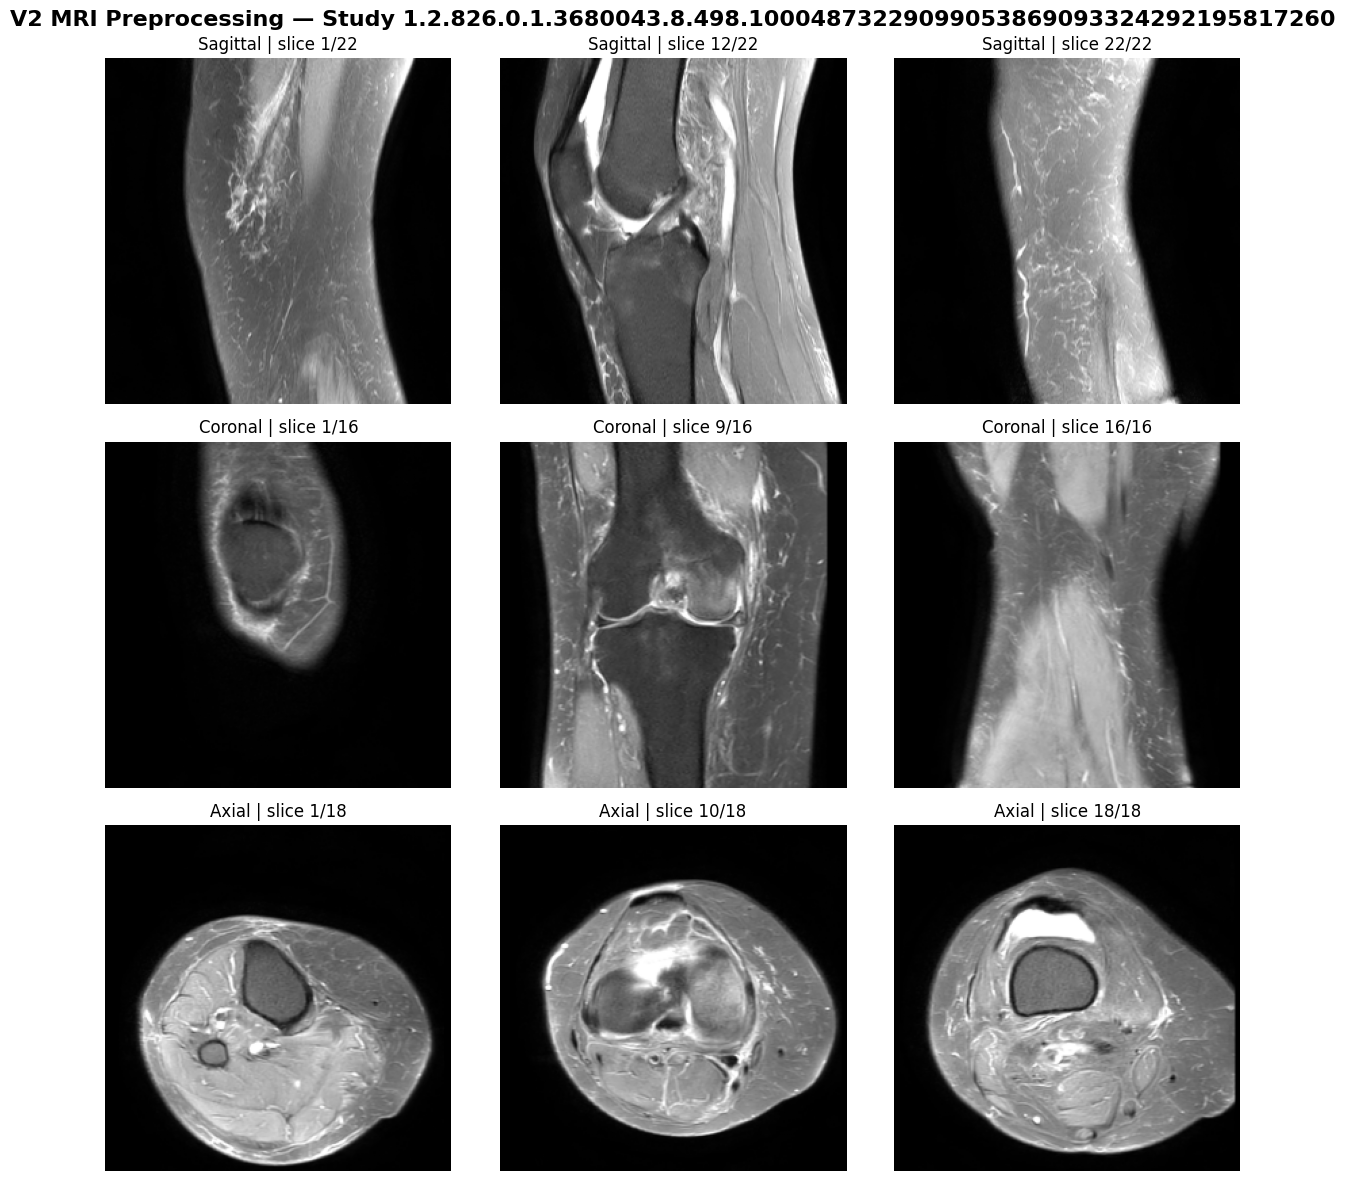


Visual sanity check complete.
Displayed: first / middle / last anatomically ordered slices.


In [20]:
# ============================================================
# CELL 15 — VISUAL SANITY CHECK
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

volumes = study_data["volumes"]

fig, axes = plt.subplots(
    nrows=len(PLANES),
    ncols=3,
    figsize=(12, 12)
)

for row, plane in enumerate(PLANES):
    volume = volumes.get(plane)

    if volume is None:
        for col in range(3):
            axes[row, col].axis("off")
        axes[row, 1].text(
            0.5, 0.5,
            f"{plane}\nNOT AVAILABLE",
            ha="center",
            va="center",
            fontsize=12
        )
        continue

    n = volume.shape[0]

    # Choose three anatomically separated slices.
    # Works for both short and long series.
    indices = [
        0,
        n // 2,
        n - 1
    ]

    for col, idx in enumerate(indices):
        axes[row, col].imshow(
            volume[idx],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row, col].set_title(
            f"{plane} | slice {idx + 1}/{n}"
        )
        axes[row, col].axis("off")

    # Plane label on the left
    axes[row, 0].set_ylabel(
        plane,
        fontsize=13,
        fontweight="bold"
    )

plt.suptitle(
    f"V2 MRI Preprocessing — Study {study_data['study_id']}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\nVisual sanity check complete.")
print("Displayed: first / middle / last anatomically ordered slices.")

In [21]:
# ============================================================
# CELL 16 — OPTIMIZED V2 PREPROCESSING BENCHMARK
# ============================================================

import os
import time
from concurrent.futures import ThreadPoolExecutor, as_completed

import cv2
import numpy as np


# ------------------------------------------------------------
# 1. Validate the schema we actually use
# ------------------------------------------------------------

required_columns = {
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Fluid_Sensitive",
    "Fat_Suppression",
    "Anatomical_Plane",
}

missing_columns = (
    required_columns
    - set(train_series.columns)
)

if missing_columns:
    raise ValueError(
        f"train_series is missing columns: "
        f"{sorted(missing_columns)}"
    )


# ------------------------------------------------------------
# 2. Get study IDs from the validated source
# ------------------------------------------------------------

all_study_ids = (
    train_series["StudyInstanceUID"]
    .dropna()
    .astype(str)
    .unique()
)

if len(all_study_ids) == 0:
    raise ValueError(
        "No StudyInstanceUID values found in train_series."
    )


# ------------------------------------------------------------
# 3. Benchmark configuration
# ------------------------------------------------------------

BENCHMARK_STUDIES = min(
    20,
    len(all_study_ids)
)

CPU_COUNT = os.cpu_count() or 1

BENCHMARK_WORKERS = min(
    4,
    CPU_COUNT,
    BENCHMARK_STUDIES
)

# Prevent OpenCV from creating nested worker threads.
cv2.setNumThreads(1)

rng = np.random.default_rng(SEED)

benchmark_study_ids = [
    str(x)
    for x in rng.choice(
        all_study_ids,
        size=BENCHMARK_STUDIES,
        replace=False
    )
]


# ------------------------------------------------------------
# 4. Configuration report
# ------------------------------------------------------------

print("=" * 70)
print("V2 PREPROCESSING BENCHMARK")
print("=" * 70)

print(f"Total studies found : {len(all_study_ids):,}")
print(f"Benchmark studies   : {BENCHMARK_STUDIES}")
print(f"CPU cores detected  : {CPU_COUNT}")
print(f"Worker threads      : {BENCHMARK_WORKERS}")
print("OpenCV threads      : 1")
print()


# ------------------------------------------------------------
# 5. Single-study benchmark worker
# ------------------------------------------------------------

def benchmark_one_study(study_id):

    start_time = time.perf_counter()

    try:

        processed = preprocess_study_v2(
            study_id=study_id,
            train_series_df=train_series,
            img_size=IMG_SIZE,
            n_slices=N_SLICES,
            central_keep=CENTRAL_KEEP
        )

        elapsed = time.perf_counter() - start_time

        # present_mask is a dictionary:
        # {"sagittal": 1, "coronal": 1, "axial": 1}
        present_mask = processed["present_mask"]

        present_planes = sum(
            int(v)
            for v in present_mask.values()
        )

        # Do not keep the potentially large MRI arrays around.
        del processed

        return {
            "study_id": study_id,
            "time_sec": elapsed,
            "present_planes": present_planes,
            "success": True,
            "error": None,
        }

    except Exception as e:

        elapsed = time.perf_counter() - start_time

        return {
            "study_id": study_id,
            "time_sec": elapsed,
            "present_planes": 0,
            "success": False,
            "error": repr(e),
        }


# ------------------------------------------------------------
# 6. Run benchmark
# ------------------------------------------------------------

results = []

benchmark_start = time.perf_counter()

with ThreadPoolExecutor(
    max_workers=BENCHMARK_WORKERS
) as executor:

    futures = {
        executor.submit(
            benchmark_one_study,
            study_id
        ): study_id
        for study_id in benchmark_study_ids
    }

    completed = 0

    for future in as_completed(futures):

        result = future.result()

        results.append(result)

        completed += 1

        if result["success"]:

            print(
                f"[{completed:02d}/{BENCHMARK_STUDIES}] "
                f"{result['time_sec']:6.2f}s | "
                f"planes={result['present_planes']}/3 | "
                f"{result['study_id']}"
            )

        else:

            print(
                f"[{completed:02d}/{BENCHMARK_STUDIES}] "
                f"FAILED | "
                f"{result['study_id']}"
            )

            print(
                f"    {result['error']}"
            )


benchmark_elapsed = (
    time.perf_counter()
    - benchmark_start
)


# ------------------------------------------------------------
# 7. Separate successful / failed studies
# ------------------------------------------------------------

successful = [
    r for r in results
    if r["success"]
]

failed = [
    r for r in results
    if not r["success"]
]


# ------------------------------------------------------------
# 8. Overall results
# ------------------------------------------------------------

print()
print("=" * 70)
print("BENCHMARK RESULTS")
print("=" * 70)

print(
    f"Successful : "
    f"{len(successful)}/{BENCHMARK_STUDIES}"
)

print(
    f"Failed     : "
    f"{len(failed)}/{BENCHMARK_STUDIES}"
)

print(
    f"Wall time  : "
    f"{benchmark_elapsed:.2f} sec "
    f"({benchmark_elapsed / 60:.2f} min)"
)


# ------------------------------------------------------------
# 9. Throughput
# ------------------------------------------------------------

if successful:

    successful_count = len(successful)

    studies_per_second = (
        successful_count
        / benchmark_elapsed
    )

    studies_per_minute = (
        studies_per_second * 60
    )

    studies_per_hour = (
        studies_per_minute * 60
    )

    estimated_total_seconds = (
        len(all_study_ids)
        / studies_per_second
    )

    print()
    print("-" * 70)
    print("THROUGHPUT")
    print("-" * 70)

    print(
        f"Studies / minute : "
        f"{studies_per_minute:.2f}"
    )

    print(
        f"Studies / hour   : "
        f"{studies_per_hour:.1f}"
    )

    print()
    print("-" * 70)
    print("FULL DATASET ESTIMATE")
    print("-" * 70)

    print(
        f"Studies          : "
        f"{len(all_study_ids):,}"
    )

    print(
        f"Estimated runtime: "
        f"{estimated_total_seconds / 60:.1f} min"
    )

    print(
        f"Estimated runtime: "
        f"{estimated_total_seconds / 3600:.2f} hours"
    )


# ------------------------------------------------------------
# 10. Timing statistics
# ------------------------------------------------------------

if successful:

    times = np.array(
        [r["time_sec"] for r in successful],
        dtype=np.float64
    )

    print()
    print("-" * 70)
    print("PER-STUDY TIMING")
    print("-" * 70)

    print(
        f"Mean   : {times.mean():.2f} sec"
    )

    print(
        f"Median : {np.median(times):.2f} sec"
    )

    print(
        f"Min    : {times.min():.2f} sec"
    )

    print(
        f"Max    : {times.max():.2f} sec"
    )


# ------------------------------------------------------------
# 11. Failure report
# ------------------------------------------------------------

if failed:

    print()
    print("=" * 70)
    print("FAILED STUDIES")
    print("=" * 70)

    for result in failed:

        print()
        print(f"Study: {result['study_id']}")
        print(f"Error: {result['error']}")


print()
print("=" * 70)
print("Benchmark complete.")
print("=" * 70)

V2 PREPROCESSING BENCHMARK
Total studies found : 4,407
Benchmark studies   : 20
CPU cores detected  : 4
Worker threads      : 4
OpenCV threads      : 1

[01/20]   2.34s | planes=3/3 | 1.2.826.0.1.3680043.8.498.97055845147740306780908051236353219644
[02/20]   2.68s | planes=3/3 | 1.2.826.0.1.3680043.8.498.73231153161312542696053060380619432126
[03/20]   4.77s | planes=3/3 | 1.2.826.0.1.3680043.8.498.12534628800787651008876070514080610643
[04/20]   5.20s | planes=3/3 | 1.2.826.0.1.3680043.8.498.67468397709097947104298147948850473142
[05/20]   2.93s | planes=3/3 | 1.2.826.0.1.3680043.8.498.72237065473467452226073540784070938342
[06/20]   3.67s | planes=3/3 | 1.2.826.0.1.3680043.8.498.80886525412417948114478368374120704834
[07/20]   2.36s | planes=3/3 | 1.2.826.0.1.3680043.8.498.41657361598083583047831423768034379414
[08/20]   3.77s | planes=3/3 | 1.2.826.0.1.3680043.8.498.11625598825018422177242262569319579378
[09/20]   3.50s | planes=3/3 | 1.2.826.0.1.3680043.8.498.5909882520801836406107

In [22]:
# ============================================================
# CELL 17 — CACHE STORAGE BENCHMARK
# ============================================================

import shutil
import tempfile
import time
from pathlib import Path

import numpy as np


# ------------------------------------------------------------
# 1. Validate benchmark study IDs
# ------------------------------------------------------------

if "benchmark_study_ids" not in globals():
    raise RuntimeError(
        "benchmark_study_ids was not found. "
        "Please run Cell 16 first."
    )

CACHE_BENCHMARK_N = len(benchmark_study_ids)

print("=" * 70)
print("V2 CACHE STORAGE BENCHMARK")
print("=" * 70)

print(f"Studies to test : {CACHE_BENCHMARK_N}")
print("Format          : compressed NPZ")
print("Dtype           : uint8")
print()


# ------------------------------------------------------------
# 2. Temporary benchmark directory
# ------------------------------------------------------------

benchmark_cache_dir = Path(
    tempfile.mkdtemp(
        prefix="v2_cache_benchmark_",
        dir=str(WORK_DIR)
    )
)

print(
    f"Temporary cache : {benchmark_cache_dir}"
)
print()


# ------------------------------------------------------------
# 3. Process + serialize benchmark studies
# ------------------------------------------------------------

cache_results = []

benchmark_start = time.perf_counter()

for i, study_id in enumerate(
    benchmark_study_ids,
    start=1
):

    study_start = time.perf_counter()

    try:

        # --------------------------------------------
        # Preprocess
        # --------------------------------------------

        processed = preprocess_study_v2(
            study_id=study_id,
            train_series_df=train_series,
            img_size=IMG_SIZE,
            n_slices=N_SLICES,
            central_keep=CENTRAL_KEEP
        )

        preprocess_time = (
            time.perf_counter()
            - study_start
        )

        # --------------------------------------------
        # Prepare arrays
        # --------------------------------------------

        save_dict = {
            "study_id": np.array(
                str(study_id)
            ),
            "present_mask": np.array(
                [
                    int(
                        processed["present_mask"]
                        .get(plane, 0)
                    )
                    for plane in PLANES
                ],
                dtype=np.uint8
            ),
        }

        for plane in PLANES:

            volume = processed["volumes"].get(
                plane
            )

            if volume is not None:

                save_dict[
                    f"{plane}_volume"
                ] = volume

        # --------------------------------------------
        # Write compressed NPZ
        # --------------------------------------------

        output_path = (
            benchmark_cache_dir
            / f"{study_id}.npz"
        )

        write_start = time.perf_counter()

        np.savez_compressed(
            output_path,
            **save_dict
        )

        write_time = (
            time.perf_counter()
            - write_start
        )

        total_time = (
            time.perf_counter()
            - study_start
        )

        file_size_mb = (
            output_path.stat().st_size
            / (1024 ** 2)
        )

        cache_results.append({
            "study_id": study_id,
            "size_mb": file_size_mb,
            "preprocess_sec": preprocess_time,
            "write_sec": write_time,
            "total_sec": total_time,
        })

        print(
            f"[{i:02d}/{CACHE_BENCHMARK_N}] "
            f"{file_size_mb:6.2f} MB | "
            f"prep={preprocess_time:5.2f}s | "
            f"write={write_time:5.2f}s"
        )

        del processed
        del save_dict

    except Exception as e:

        print(
            f"[{i:02d}/{CACHE_BENCHMARK_N}] "
            f"FAILED | {study_id}"
        )

        print(
            f"    {repr(e)}"
        )


benchmark_elapsed = (
    time.perf_counter()
    - benchmark_start
)


# ------------------------------------------------------------
# 4. Analyze storage
# ------------------------------------------------------------

if cache_results:

    sizes = np.array(
        [
            r["size_mb"]
            for r in cache_results
        ],
        dtype=np.float64
    )

    prep_times = np.array(
        [
            r["preprocess_sec"]
            for r in cache_results
        ],
        dtype=np.float64
    )

    write_times = np.array(
        [
            r["write_sec"]
            for r in cache_results
        ],
        dtype=np.float64
    )

    total_times = np.array(
        [
            r["total_sec"]
            for r in cache_results
        ],
        dtype=np.float64
    )

    mean_size = sizes.mean()
    median_size = np.median(sizes)
    max_size = sizes.max()

    estimated_total_gb = (
        mean_size
        * len(all_study_ids)
        / 1024
    )

    print()
    print("=" * 70)
    print("CACHE SIZE RESULTS")
    print("=" * 70)

    print(
        f"Successful studies : "
        f"{len(cache_results)}/{CACHE_BENCHMARK_N}"
    )

    print(
        f"Mean file size     : "
        f"{mean_size:.2f} MB"
    )

    print(
        f"Median file size   : "
        f"{median_size:.2f} MB"
    )

    print(
        f"Largest file       : "
        f"{max_size:.2f} MB"
    )

    print()
    print(
        f"Estimated full cache: "
        f"{estimated_total_gb:.2f} GB"
    )

    print()
    print("=" * 70)
    print("TIMING")
    print("=" * 70)

    print(
        f"Total benchmark time : "
        f"{benchmark_elapsed:.2f}s"
    )

    print(
        f"Mean preprocessing   : "
        f"{prep_times.mean():.2f}s"
    )

    print(
        f"Mean compression     : "
        f"{write_times.mean():.2f}s"
    )

    print(
        f"Mean total / study   : "
        f"{total_times.mean():.2f}s"
    )

    print()
    print(
        f"Estimated total cache "
        f"creation time: "
        f"{total_times.mean() * len(all_study_ids) / 60:.1f} min"
    )


# ------------------------------------------------------------
# 5. Clean up temporary benchmark cache
# ------------------------------------------------------------

try:

    shutil.rmtree(
        benchmark_cache_dir
    )

    print()
    print(
        "Temporary benchmark cache removed."
    )

except Exception as e:

    print()
    print(
        "Warning: could not remove temporary "
        f"cache: {repr(e)}"
    )


print()
print("=" * 70)
print("Cache storage benchmark complete.")
print("=" * 70)

V2 CACHE STORAGE BENCHMARK
Studies to test : 20
Format          : compressed NPZ
Dtype           : uint8

Temporary cache : /kaggle/working/v2_cache_benchmark_v2a676r9

[01/20]   2.73 MB | prep= 0.68s | write= 0.26s
[02/20]   2.72 MB | prep= 1.35s | write= 0.16s
[03/20]   2.46 MB | prep= 1.00s | write= 0.20s
[04/20]   2.98 MB | prep= 0.49s | write= 0.18s
[05/20]   3.67 MB | prep= 0.74s | write= 0.21s
[06/20]   3.46 MB | prep= 0.77s | write= 0.19s
[07/20]   3.29 MB | prep= 0.73s | write= 0.28s
[08/20]   2.79 MB | prep= 0.92s | write= 0.17s
[09/20]   2.77 MB | prep= 1.07s | write= 0.16s
[10/20]   2.71 MB | prep= 0.54s | write= 0.31s
[11/20]   2.62 MB | prep= 1.25s | write= 0.18s
[12/20]   2.46 MB | prep= 0.85s | write= 0.19s
[13/20]   2.07 MB | prep= 0.85s | write= 0.11s
[14/20]   3.29 MB | prep= 0.61s | write= 0.25s
[15/20]   3.37 MB | prep= 1.05s | write= 0.32s
[16/20]   2.90 MB | prep= 0.68s | write= 0.33s
[17/20]   2.54 MB | prep= 1.02s | write= 0.15s
[18/20]   3.10 MB | prep= 1.81s 

In [23]:
# ============================================================
# CELL 18 — CACHE READ/WRITE + INTEGRITY TEST
# ============================================================

import shutil
import tempfile
import time
from pathlib import Path

import numpy as np


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

IO_TEST_STUDIES = min(
    3,
    len(benchmark_study_ids)
)

IO_READ_REPEATS = 3

io_test_study_ids = [
    str(x)
    for x in benchmark_study_ids[:IO_TEST_STUDIES]
]


# ------------------------------------------------------------
# 2. Temporary directory
# ------------------------------------------------------------

io_test_dir = Path(
    tempfile.mkdtemp(
        prefix="v2_cache_io_test_",
        dir=str(WORK_DIR)
    )
)

print("=" * 70)
print("V2 CACHE I/O + INTEGRITY TEST")
print("=" * 70)

print(f"Studies tested : {IO_TEST_STUDIES}")
print(f"Read repeats   : {IO_READ_REPEATS}")
print(f"Format         : compressed NPZ")
print(f"Temporary dir  : {io_test_dir}")
print()


# ------------------------------------------------------------
# 3. Create + save test caches
# ------------------------------------------------------------

saved_paths = {}
original_data = {}

write_start = time.perf_counter()

for i, study_id in enumerate(
    io_test_study_ids,
    start=1
):

    print(
        f"[WRITE {i}/{IO_TEST_STUDIES}] "
        f"{study_id}"
    )

    processed = preprocess_study_v2(
        study_id=study_id,
        train_series_df=train_series,
        img_size=IMG_SIZE,
        n_slices=N_SLICES,
        central_keep=CENTRAL_KEEP
    )

    save_dict = {
        "study_id": np.array(
            study_id
        ),

        "present_mask": np.array(
            [
                int(
                    processed["present_mask"]
                    .get(plane, 0)
                )
                for plane in PLANES
            ],
            dtype=np.uint8
        )
    }

    # Preserve original arrays for integrity checking.
    original_data[study_id] = {
        "present_mask": save_dict["present_mask"].copy(),
        "volumes": {}
    }

    for plane in PLANES:

        volume = processed["volumes"].get(
            plane
        )

        if volume is not None:

            # Ensure cache representation is uint8.
            volume = np.asarray(
                volume,
                dtype=np.uint8
            )

            save_dict[
                f"{plane}_volume"
            ] = volume

            original_data[
                study_id
            ]["volumes"][plane] = volume.copy()

    output_path = (
        io_test_dir
        / f"{study_id}.npz"
    )

    np.savez_compressed(
        output_path,
        **save_dict
    )

    saved_paths[study_id] = output_path

    file_size_mb = (
        output_path.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"    size = {file_size_mb:.2f} MB"
    )

    del processed
    del save_dict


write_elapsed = (
    time.perf_counter()
    - write_start
)


# ------------------------------------------------------------
# 4. Test repeated reads
# ------------------------------------------------------------

print()
print("=" * 70)
print("READ PERFORMANCE")
print("=" * 70)

read_times = []

for repeat in range(
    IO_READ_REPEATS
):

    repeat_start = time.perf_counter()

    for study_id in io_test_study_ids:

        path = saved_paths[study_id]

        with np.load(
            path,
            allow_pickle=False
        ) as data:

            # Access every cached array.
            present_mask = data[
                "present_mask"
            ]

            for plane in PLANES:

                key = f"{plane}_volume"

                if key in data.files:
                    volume = data[key]

                    # Force materialization/access.
                    _ = volume.shape
                    _ = volume.dtype
                    _ = volume.nbytes

    repeat_elapsed = (
        time.perf_counter()
        - repeat_start
    )

    read_times.append(
        repeat_elapsed
    )

    print(
        f"Read pass {repeat + 1}: "
        f"{repeat_elapsed:.3f} sec"
    )


# ------------------------------------------------------------
# 5. Integrity verification
# ------------------------------------------------------------

print()
print("=" * 70)
print("INTEGRITY CHECK")
print("=" * 70)

integrity_passed = True

for study_id in io_test_study_ids:

    path = saved_paths[study_id]

    with np.load(
        path,
        allow_pickle=False
    ) as data:

        # ----------------------------------------
        # Study ID
        # ----------------------------------------

        loaded_study_id = str(
            data["study_id"]
        )

        if loaded_study_id != study_id:

            integrity_passed = False

            print(
                f"FAIL: study_id mismatch "
                f"for {study_id}"
            )

        # ----------------------------------------
        # Present mask
        # ----------------------------------------

        loaded_mask = data[
            "present_mask"
        ]

        original_mask = (
            original_data[
                study_id
            ]["present_mask"]
        )

        if not np.array_equal(
            loaded_mask,
            original_mask
        ):

            integrity_passed = False

            print(
                f"FAIL: present_mask mismatch "
                f"for {study_id}"
            )

        # ----------------------------------------
        # Volumes
        # ----------------------------------------

        original_volumes = (
            original_data[
                study_id
            ]["volumes"]
        )

        for plane in PLANES:

            key = f"{plane}_volume"

            if plane in original_volumes:

                if key not in data.files:

                    integrity_passed = False

                    print(
                        f"FAIL: missing {key} "
                        f"for {study_id}"
                    )

                    continue

                loaded_volume = data[key]

                original_volume = (
                    original_volumes[plane]
                )

                if not np.array_equal(
                    loaded_volume,
                    original_volume
                ):

                    integrity_passed = False

                    print(
                        f"FAIL: {plane} volume "
                        f"mismatch for {study_id}"
                    )

                if loaded_volume.dtype != np.uint8:

                    integrity_passed = False

                    print(
                        f"FAIL: {plane} dtype "
                        f"is {loaded_volume.dtype}"
                    )

            else:

                if key in data.files:

                    integrity_passed = False

                    print(
                        f"FAIL: unexpected {key} "
                        f"for {study_id}"
                    )


if integrity_passed:

    print(
        "✓ All study IDs, masks, volumes, "
        "shapes and values match exactly."
    )

else:

    print(
        "✗ Integrity check FAILED."
    )


# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

total_read_time = sum(read_times)

mean_read_time = (
    np.mean(read_times)
)

total_file_size_mb = sum(
    path.stat().st_size
    / (1024 ** 2)
    for path in saved_paths.values()
)

print()
print("=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    f"Write time       : "
    f"{write_elapsed:.3f} sec"
)

print(
    f"Total file size  : "
    f"{total_file_size_mb:.2f} MB"
)

print(
    f"Mean read pass   : "
    f"{mean_read_time:.3f} sec"
)

print(
    f"Read throughput  : "
    f"{IO_TEST_STUDIES / mean_read_time:.2f} studies/sec"
)

print(
    f"Integrity        : "
    f"{'PASS' if integrity_passed else 'FAIL'}"
)


# ------------------------------------------------------------
# 7. Cleanup
# ------------------------------------------------------------

try:

    shutil.rmtree(
        io_test_dir
    )

    print()
    print(
        "✓ Temporary I/O test cache removed."
    )

except Exception as e:

    print()
    print(
        "WARNING: Could not remove temporary "
        f"directory: {repr(e)}"
    )


print()
print("=" * 70)
print("Cell 18 complete.")
print("=" * 70)

V2 CACHE I/O + INTEGRITY TEST
Studies tested : 3
Read repeats   : 3
Format         : compressed NPZ
Temporary dir  : /kaggle/working/v2_cache_io_test_k59pjjw0

[WRITE 1/3] 1.2.826.0.1.3680043.8.498.73231153161312542696053060380619432126
    size = 2.73 MB
[WRITE 2/3] 1.2.826.0.1.3680043.8.498.67468397709097947104298147948850473142
    size = 2.72 MB
[WRITE 3/3] 1.2.826.0.1.3680043.8.498.12534628800787651008876070514080610643
    size = 2.46 MB

READ PERFORMANCE
Read pass 1: 0.080 sec
Read pass 2: 0.076 sec
Read pass 3: 0.078 sec

INTEGRITY CHECK
✓ All study IDs, masks, volumes, shapes and values match exactly.

SUMMARY
Write time       : 3.736 sec
Total file size  : 7.91 MB
Mean read pass   : 0.078 sec
Read throughput  : 38.50 studies/sec
Integrity        : PASS

✓ Temporary I/O test cache removed.

Cell 18 complete.


In [24]:
# ============================================================
# CELL 19 — V2 PRODUCTION CACHE BUILDER
# ============================================================

import os
import time
import shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import cv2
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CACHE_ROOT = Path(CACHE_V2_DIR)
STUDY_CACHE_DIR = CACHE_ROOT / "studies"
FAILURE_DIR = CACHE_ROOT / "failures"

MANIFEST_PATH = CACHE_ROOT / "manifest.csv"
FAILURES_PATH = FAILURE_DIR / "failures.csv"

# Number of parallel preprocessing/writing workers.
# We have 4 CPU cores, so start conservatively with 4.
CACHE_WORKERS = min(
    4,
    os.cpu_count() or 1
)

# Save progress to disk after this many completed studies.
STATUS_SAVE_INTERVAL = 25

# Do not create nested OpenCV worker pools.
cv2.setNumThreads(1)


# ------------------------------------------------------------
# 2. Create directories
# ------------------------------------------------------------

STUDY_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FAILURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 3. Validate train_series schema
# ------------------------------------------------------------

required_columns = {
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Fluid_Sensitive",
    "Fat_Suppression",
    "Anatomical_Plane",
}

missing_columns = (
    required_columns
    - set(train_series.columns)
)

if missing_columns:
    raise ValueError(
        "train_series is missing required columns: "
        f"{sorted(missing_columns)}"
    )


# ------------------------------------------------------------
# 4. Get complete list of studies
# ------------------------------------------------------------

all_study_ids = (
    train_series["StudyInstanceUID"]
    .dropna()
    .astype(str)
    .unique()
)

all_study_ids = sorted(
    all_study_ids.tolist()
)

print("=" * 70)
print("V2 PRODUCTION CACHE BUILDER")
print("=" * 70)

print(
    f"Total studies : "
    f"{len(all_study_ids):,}"
)

print(
    f"Workers       : "
    f"{CACHE_WORKERS}"
)

print(
    f"Cache root    : "
    f"{CACHE_ROOT}"
)

print()


# ------------------------------------------------------------
# 5. Identify already completed studies
# ------------------------------------------------------------

existing_cache_ids = set()

for path in STUDY_CACHE_DIR.glob("*.npz"):

    existing_cache_ids.add(
        path.stem
    )


pending_study_ids = [
    study_id
    for study_id in all_study_ids
    if study_id not in existing_cache_ids
]


print(
    f"Already cached : "
    f"{len(existing_cache_ids):,}"
)

print(
    f"Remaining      : "
    f"{len(pending_study_ids):,}"
)

print()


if len(pending_study_ids) == 0:

    print(
        "✓ All studies are already cached."
    )

else:

    print(
        "Starting production cache generation..."
    )


# ------------------------------------------------------------
# 6. Single-study cache worker
# ------------------------------------------------------------

def cache_one_study(study_id):

    start_time = time.perf_counter()

    output_path = (
        STUDY_CACHE_DIR
        / f"{study_id}.npz"
    )

    # --------------------------------------------------------
    # Safety: another worker/run may have created it.
    # --------------------------------------------------------

    if output_path.exists():

        return {
            "study_id": study_id,
            "status": "skipped",
            "time_sec": 0.0,
            "size_mb": (
                output_path.stat().st_size
                / (1024 ** 2)
            ),
            "present_planes": None,
            "slice_counts": None,
            "error": None,
        }


    try:

        # ----------------------------------------------------
        # Preprocess study
        # ----------------------------------------------------

        processed = preprocess_study_v2(
            study_id=study_id,
            train_series_df=train_series,
            img_size=IMG_SIZE,
            n_slices=N_SLICES,
            central_keep=CENTRAL_KEEP
        )


        # ----------------------------------------------------
        # Build cache representation
        # ----------------------------------------------------

        present_mask = np.array(
            [
                int(
                    processed["present_mask"]
                    .get(plane, 0)
                )
                for plane in PLANES
            ],
            dtype=np.uint8
        )

        save_dict = {
            "study_id": np.array(
                study_id
            ),

            "present_mask": present_mask,
        }

        slice_counts = {}

        for plane in PLANES:

            volume = processed[
                "volumes"
            ].get(plane)

            if volume is None:

                slice_counts[plane] = 0

                continue

            volume = np.asarray(
                volume,
                dtype=np.uint8
            )

            # Final production sanity checks.
            if volume.ndim != 3:

                raise ValueError(
                    f"{plane}: expected 3D volume, "
                    f"got shape {volume.shape}"
                )

            if volume.shape[1:] != (
                IMG_SIZE,
                IMG_SIZE
            ):

                raise ValueError(
                    f"{plane}: unexpected spatial "
                    f"shape {volume.shape}"
                )

            if volume.dtype != np.uint8:

                raise ValueError(
                    f"{plane}: expected uint8, "
                    f"got {volume.dtype}"
                )

            save_dict[
                f"{plane}_volume"
            ] = volume

            slice_counts[plane] = (
                int(volume.shape[0])
            )


        # ----------------------------------------------------
        # Write atomically
        #
        # Write to .tmp first.
        # If Kaggle stops halfway through a write, we won't
        # mistake a corrupt partial file for a valid cache.
        # ----------------------------------------------------

        temporary_path = Path(
            str(output_path) + ".tmp"
        )

        np.savez_compressed(
            temporary_path,
            **save_dict
        )

        # np.savez_compressed adds ".npz" if the filename
        # does not already end with .npz.
        actual_temporary_path = Path(
            str(temporary_path) + ".npz"
        )

        if not actual_temporary_path.exists():

            raise IOError(
                "Temporary NPZ file was not created."
            )

        actual_temporary_path.replace(
            output_path
        )


        # ----------------------------------------------------
        # Timing / metadata
        # ----------------------------------------------------

        elapsed = (
            time.perf_counter()
            - start_time
        )

        size_mb = (
            output_path.stat().st_size
            / (1024 ** 2)
        )

        del processed
        del save_dict

        return {
            "study_id": study_id,
            "status": "completed",
            "time_sec": elapsed,
            "size_mb": size_mb,
            "present_planes": int(
                present_mask.sum()
            ),
            "slice_counts": slice_counts,
            "error": None,
        }


    except Exception as e:

        # Remove any incomplete temporary files.
        for candidate in (
            Path(str(output_path) + ".tmp"),
            Path(str(output_path) + ".tmp.npz"),
        ):

            if candidate.exists():

                try:
                    candidate.unlink()
                except Exception:
                    pass

        return {
            "study_id": study_id,
            "status": "failed",
            "time_sec": (
                time.perf_counter()
                - start_time
            ),
            "size_mb": 0.0,
            "present_planes": 0,
            "slice_counts": {},
            "error": repr(e),
        }


# ------------------------------------------------------------
# 7. Run production cache generation
# ------------------------------------------------------------

run_start = time.perf_counter()

results = []

if pending_study_ids:

    with ThreadPoolExecutor(
        max_workers=CACHE_WORKERS
    ) as executor:

        futures = {
            executor.submit(
                cache_one_study,
                study_id
            ): study_id
            for study_id in pending_study_ids
        }

        completed_count = 0

        for future in as_completed(
            futures
        ):

            result = future.result()

            results.append(result)

            completed_count += 1

            # ------------------------------------------------
            # Progress
            # ------------------------------------------------

            elapsed = (
                time.perf_counter()
                - run_start
            )

            completed_successfully = sum(
                r["status"] == "completed"
                for r in results
            )

            failed_count = sum(
                r["status"] == "failed"
                for r in results
            )

            rate = (
                completed_count / elapsed
                if elapsed > 0
                else 0
            )

            remaining = (
                len(pending_study_ids)
                - completed_count
            )

            eta_minutes = (
                remaining / rate / 60
                if rate > 0
                else float("inf")
            )

            status_symbol = (
                "✓"
                if result["status"]
                == "completed"
                else "✗"
            )

            print(
                f"[{completed_count:4d}/"
                f"{len(pending_study_ids):4d}] "
                f"{status_symbol} "
                f"{result['time_sec']:5.2f}s | "
                f"{result['study_id'][-16:]} | "
                f"ETA {eta_minutes:5.1f}m"
            )

            if result["status"] == "failed":

                print(
                    f"       ERROR: "
                    f"{result['error']}"
                )

            # ------------------------------------------------
            # Periodic progress checkpoint
            # ------------------------------------------------

            if (
                completed_count
                % STATUS_SAVE_INTERVAL
                == 0
            ):

                temporary_manifest = (
                    CACHE_ROOT
                    / "manifest.partial.csv"
                )

                checkpoint_df = pd.DataFrame(
                    results
                )

                checkpoint_df.to_csv(
                    temporary_manifest,
                    index=False
                )

                print(
                    f"       "
                    f"Checkpoint saved "
                    f"({completed_count} studies)"
                )


# ------------------------------------------------------------
# 8. Build final manifest
# ------------------------------------------------------------

run_elapsed = (
    time.perf_counter()
    - run_start
)


# Include existing cache files as well.
manifest_rows = []

for path in STUDY_CACHE_DIR.glob("*.npz"):

    study_id = path.stem

    file_size_mb = (
        path.stat().st_size
        / (1024 ** 2)
    )

    # Read lightweight metadata only.
    try:

        with np.load(
            path,
            allow_pickle=False
        ) as data:

            present_mask = data[
                "present_mask"
            ].astype(np.uint8)

            slice_counts = {}

            for idx, plane in enumerate(
                PLANES
            ):

                key = (
                    f"{plane}_volume"
                )

                if key in data.files:

                    slice_counts[plane] = (
                        int(
                            data[key].shape[0]
                        )
                    )

                else:

                    slice_counts[plane] = 0

        manifest_rows.append({
            "study_id": study_id,
            "cache_file": str(
                path.relative_to(
                    CACHE_ROOT
                )
            ),
            "file_size_mb": file_size_mb,
            "sagittal_present": int(
                present_mask[0]
            ),
            "coronal_present": int(
                present_mask[1]
            ),
            "axial_present": int(
                present_mask[2]
            ),
            "sagittal_slices": slice_counts[
                "sagittal"
            ],
            "coronal_slices": slice_counts[
                "coronal"
            ],
            "axial_slices": slice_counts[
                "axial"
            ],
            "status": "cached",
        })

    except Exception as e:

        manifest_rows.append({
            "study_id": study_id,
            "cache_file": str(
                path.relative_to(
                    CACHE_ROOT
                )
            ),
            "file_size_mb": file_size_mb,
            "sagittal_present": 0,
            "coronal_present": 0,
            "axial_present": 0,
            "sagittal_slices": 0,
            "coronal_slices": 0,
            "axial_slices": 0,
            "status": f"read_error: {repr(e)}",
        })


manifest_df = pd.DataFrame(
    manifest_rows
)

manifest_df = manifest_df.sort_values(
    "study_id"
).reset_index(drop=True)

manifest_df.to_csv(
    MANIFEST_PATH,
    index=False
)


# ------------------------------------------------------------
# 9. Save failures
# ------------------------------------------------------------

failure_rows = [
    r
    for r in results
    if r["status"] == "failed"
]

if failure_rows:

    pd.DataFrame(
        failure_rows
    ).to_csv(
        FAILURES_PATH,
        index=False
    )


# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

total_cached = len(
    list(
        STUDY_CACHE_DIR.glob("*.npz")
    )
)

total_size_gb = sum(
    path.stat().st_size
    for path in STUDY_CACHE_DIR.glob(
        "*.npz"
    )
) / (1024 ** 3)

print()
print("=" * 70)
print("CACHE BUILD COMPLETE")
print("=" * 70)

print(
    f"Cached studies : "
    f"{total_cached:,}/{len(all_study_ids):,}"
)

print(
    f"Failed this run: "
    f"{len(failure_rows):,}"
)

print(
    f"Cache size     : "
    f"{total_size_gb:.2f} GB"
)

print(
    f"Run time       : "
    f"{run_elapsed / 60:.2f} min"
)

print()
print(
    f"Manifest       : "
    f"{MANIFEST_PATH}"
)

if failure_rows:

    print(
        f"Failures       : "
        f"{FAILURES_PATH}"
    )

else:

    print(
        "Failures       : none"
    )

print()
print("=" * 70)

V2 PRODUCTION CACHE BUILDER
Total studies : 4,407
Workers       : 4
Cache root    : /kaggle/working/mri_cache_v2

Already cached : 0
Remaining      : 4,407

Starting production cache generation...
[   1/4407] ✓  1.02s | 3324292195817260 | ETA  75.5m
[   2/4407] ✓  4.05s | 4707434356622764 | ETA 150.1m
[   3/4407] ✓  5.06s | 0062909909132231 | ETA 124.3m
[   4/4407] ✓  4.40s | 5768216599146542 | ETA  99.6m
[   5/4407] ✓  5.68s | 9792075652399585 | ETA  83.4m
[   6/4407] ✓  3.17s | 4435387067561101 | ETA 100.9m
[   7/4407] ✓  4.30s | 7008531304016339 | ETA  87.8m
[   8/4407] ✓  3.25s | 4317186288618513 | ETA  81.9m
[   9/4407] ✓  7.05s | 7491713738306606 | ETA 101.6m
[  10/4407] ✓  4.17s | 6520318965356394 | ETA  92.0m
[  11/4407] ✓  4.54s | 7955593315007559 | ETA  85.2m
[  12/4407] ✓  4.24s | 5299760479434938 | ETA  80.4m
[  13/4407] ✓  2.86s | 4181337513293981 | ETA  86.8m
[  14/4407] ✓  3.08s | 6043262132965018 | ETA  83.0m
[  15/4407] ✓  3.62s | 8068502185417806 | ETA  78.6m
[  16/44

In [25]:
# ============================================================
# CELL 20 — COMPLETE V2 CACHE AUDIT
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

CACHE_ROOT = Path(CACHE_V2_DIR)
STUDY_CACHE_DIR = CACHE_ROOT / "studies"
MANIFEST_PATH = CACHE_ROOT / "manifest.csv"


# ------------------------------------------------------------
# 2. Expected study IDs
# ------------------------------------------------------------

expected_study_ids = set(
    train_series["StudyInstanceUID"]
    .dropna()
    .astype(str)
    .unique()
)

expected_count = len(
    expected_study_ids
)


# ------------------------------------------------------------
# 3. Find cache files
# ------------------------------------------------------------

cache_files = sorted(
    STUDY_CACHE_DIR.glob("*.npz")
)

cached_study_ids = {
    path.stem
    for path in cache_files
}

missing_studies = (
    expected_study_ids
    - cached_study_ids
)

unexpected_files = (
    cached_study_ids
    - expected_study_ids
)


print("=" * 70)
print("V2 CACHE AUDIT")
print("=" * 70)

print(
    f"Expected studies : {expected_count:,}"
)

print(
    f"Cache files      : {len(cache_files):,}"
)

print(
    f"Missing studies  : {len(missing_studies):,}"
)

print(
    f"Unexpected files : {len(unexpected_files):,}"
)

print()


# ------------------------------------------------------------
# 4. Audit every NPZ
# ------------------------------------------------------------

audit_start = time.perf_counter()

valid_files = 0
corrupt_files = []
schema_errors = []

slice_records = []
plane_presence_records = []

required_keys = {
    "study_id",
    "present_mask",
}

for i, path in enumerate(
    cache_files,
    start=1
):

    study_id = path.stem

    try:

        with np.load(
            path,
            allow_pickle=False
        ) as data:

            # --------------------------------------------
            # Required keys
            # --------------------------------------------

            missing_keys = (
                required_keys
                - set(data.files)
            )

            if missing_keys:

                schema_errors.append({
                    "study_id": study_id,
                    "error": (
                        f"Missing keys: "
                        f"{sorted(missing_keys)}"
                    )
                })

                continue


            # --------------------------------------------
            # Study ID
            # --------------------------------------------

            stored_study_id = str(
                data["study_id"]
            )

            if stored_study_id != study_id:

                schema_errors.append({
                    "study_id": study_id,
                    "error": (
                        "Stored study_id does not "
                        "match filename."
                    )
                })

                continue


            # --------------------------------------------
            # Present mask
            # --------------------------------------------

            present_mask = np.asarray(
                data["present_mask"]
            )

            if present_mask.shape != (
                len(PLANES),
            ):

                schema_errors.append({
                    "study_id": study_id,
                    "error": (
                        f"Invalid present_mask "
                        f"shape: "
                        f"{present_mask.shape}"
                    )
                })

                continue


            if not np.all(
                np.isin(
                    present_mask,
                    [0, 1]
                )
            ):

                schema_errors.append({
                    "study_id": study_id,
                    "error": (
                        "present_mask contains "
                        "values other than 0/1."
                    )
                })

                continue


            # --------------------------------------------
            # Plane volumes
            # --------------------------------------------

            study_slice_record = {
                "study_id": study_id
            }

            study_presence_record = {
                "study_id": study_id
            }

            study_valid = True

            for plane_idx, plane in enumerate(
                PLANES
            ):

                key = f"{plane}_volume"

                expected_present = int(
                    present_mask[plane_idx]
                )

                if key not in data.files:

                    if expected_present != 0:

                        schema_errors.append({
                            "study_id": study_id,
                            "error": (
                                f"{plane}: marked "
                                "present but volume "
                                "is missing."
                            )
                        })

                        study_valid = False

                    study_slice_record[
                        f"{plane}_slices"
                    ] = 0

                    study_presence_record[
                        f"{plane}_present"
                    ] = 0

                    continue


                volume = data[key]

                # ----------------------------------------
                # Dimensionality
                # ----------------------------------------

                if volume.ndim != 3:

                    schema_errors.append({
                        "study_id": study_id,
                        "error": (
                            f"{plane}: expected 3D "
                            f"volume, got "
                            f"{volume.shape}"
                        )
                    })

                    study_valid = False
                    continue


                # ----------------------------------------
                # Spatial dimensions
                # ----------------------------------------

                if volume.shape[1:] != (
                    IMG_SIZE,
                    IMG_SIZE
                ):

                    schema_errors.append({
                        "study_id": study_id,
                        "error": (
                            f"{plane}: invalid "
                            f"spatial shape "
                            f"{volume.shape}"
                        )
                    })

                    study_valid = False
                    continue


                # ----------------------------------------
                # dtype
                # ----------------------------------------

                if volume.dtype != np.uint8:

                    schema_errors.append({
                        "study_id": study_id,
                        "error": (
                            f"{plane}: dtype is "
                            f"{volume.dtype}"
                        )
                    })

                    study_valid = False
                    continue


                # ----------------------------------------
                # Slice count
                # ----------------------------------------

                n_slices = int(
                    volume.shape[0]
                )

                if n_slices <= 0:

                    schema_errors.append({
                        "study_id": study_id,
                        "error": (
                            f"{plane}: zero slices."
                        )
                    })

                    study_valid = False
                    continue


                if expected_present != 1:

                    schema_errors.append({
                        "study_id": study_id,
                        "error": (
                            f"{plane}: volume exists "
                            "but present_mask=0."
                        )
                    })

                    study_valid = False
                    continue


                study_slice_record[
                    f"{plane}_slices"
                ] = n_slices

                study_presence_record[
                    f"{plane}_present"
                ] = 1


            # --------------------------------------------
            # Final study status
            # --------------------------------------------

            if study_valid:

                valid_files += 1

                slice_records.append(
                    study_slice_record
                )

                plane_presence_records.append(
                    study_presence_record
                )

            else:

                continue


    except Exception as e:

        corrupt_files.append({
            "study_id": study_id,
            "error": repr(e)
        })


audit_elapsed = (
    time.perf_counter()
    - audit_start
)


# ------------------------------------------------------------
# 5. Build audit DataFrames
# ------------------------------------------------------------

slice_df = pd.DataFrame(
    slice_records
)

presence_df = pd.DataFrame(
    plane_presence_records
)


# ------------------------------------------------------------
# 6. Cache size
# ------------------------------------------------------------

total_cache_bytes = sum(
    path.stat().st_size
    for path in cache_files
)

total_cache_gb = (
    total_cache_bytes
    / (1024 ** 3)
)


# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------

print()
print("=" * 70)
print("AUDIT RESULTS")
print("=" * 70)

print(
    f"Valid cache files : "
    f"{valid_files:,}/{len(cache_files):,}"
)

print(
    f"Corrupt files     : "
    f"{len(corrupt_files):,}"
)

print(
    f"Schema errors     : "
    f"{len(schema_errors):,}"
)

print(
    f"Audit time        : "
    f"{audit_elapsed:.2f} sec"
)

print(
    f"Total cache size  : "
    f"{total_cache_gb:.2f} GB"
)


# ------------------------------------------------------------
# 8. Plane availability
# ------------------------------------------------------------

if not presence_df.empty:

    print()
    print("-" * 70)
    print("PLANE AVAILABILITY")
    print("-" * 70)

    for plane in PLANES:

        column = (
            f"{plane}_present"
        )

        count = int(
            presence_df[column].sum()
        )

        print(
            f"{plane:10s}: "
            f"{count:,}/{valid_files:,}"
        )


# ------------------------------------------------------------
# 9. Slice statistics
# ------------------------------------------------------------

if not slice_df.empty:

    print()
    print("-" * 70)
    print("SLICE COUNT STATISTICS")
    print("-" * 70)

    for plane in PLANES:

        column = (
            f"{plane}_slices"
        )

        values = slice_df[column]

        nonzero = values[
            values > 0
        ]

        if len(nonzero) == 0:

            print(
                f"{plane:10s}: no volumes"
            )

            continue

        print(
            f"{plane:10s}: "
            f"min={int(nonzero.min()):2d}, "
            f"median={int(nonzero.median()):2d}, "
            f"mean={nonzero.mean():5.2f}, "
            f"max={int(nonzero.max()):2d}"
        )


# ------------------------------------------------------------
# 10. Missing / unexpected studies
# ------------------------------------------------------------

if missing_studies:

    print()
    print("=" * 70)
    print("MISSING STUDIES")
    print("=" * 70)

    for study_id in sorted(
        missing_studies
    )[:20]:

        print(study_id)

    if len(missing_studies) > 20:

        print(
            f"... and "
            f"{len(missing_studies) - 20} more."
        )


if unexpected_files:

    print()
    print("=" * 70)
    print("UNEXPECTED CACHE FILES")
    print("=" * 70)

    for study_id in sorted(
        unexpected_files
    )[:20]:

        print(study_id)


# ------------------------------------------------------------
# 11. Error details
# ------------------------------------------------------------

if corrupt_files:

    print()
    print("=" * 70)
    print("CORRUPT FILES")
    print("=" * 70)

    for item in corrupt_files[:20]:

        print(
            f"{item['study_id']}: "
            f"{item['error']}"
        )


if schema_errors:

    print()
    print("=" * 70)
    print("SCHEMA ERRORS")
    print("=" * 70)

    for item in schema_errors[:20]:

        print(
            f"{item['study_id']}: "
            f"{item['error']}"
        )


# ------------------------------------------------------------
# 12. Final verdict
# ------------------------------------------------------------

audit_passed = (
    len(missing_studies) == 0
    and len(unexpected_files) == 0
    and len(corrupt_files) == 0
    and len(schema_errors) == 0
    and valid_files == expected_count
)

print()
print("=" * 70)

if audit_passed:

    print(
        "✓ V2 CACHE AUDIT PASSED"
    )

    print(
        f"✓ {expected_count:,} studies verified."
    )

    print(
        "✓ All cache files are readable."
    )

    print(
        "✓ All volumes have the expected "
        "256×256 spatial dimensions."
    )

    print(
        "✓ All volumes are uint8."
    )

else:

    print(
        "✗ V2 CACHE AUDIT FAILED"
    )

print("=" * 70)

V2 CACHE AUDIT
Expected studies : 4,407
Cache files      : 4,407
Missing studies  : 0
Unexpected files : 0


AUDIT RESULTS
Valid cache files : 4,407/4,407
Corrupt files     : 0
Schema errors     : 0
Audit time        : 172.08 sec
Total cache size  : 13.04 GB

----------------------------------------------------------------------
PLANE AVAILABILITY
----------------------------------------------------------------------
Sagittal  : 4,407/4,407
Coronal   : 4,407/4,407
Axial     : 4,407/4,407

----------------------------------------------------------------------
SLICE COUNT STATISTICS
----------------------------------------------------------------------
Sagittal  : min=15, median=24, mean=23.39, max=24
Coronal   : min=15, median=24, mean=22.96, max=24
Axial     : min=12, median=24, mean=23.43, max=24

✓ V2 CACHE AUDIT PASSED
✓ 4,407 studies verified.
✓ All cache files are readable.
✓ All volumes have the expected 256×256 spatial dimensions.
✓ All volumes are uint8.


In [26]:
# ============================================================
# CELL 21 — LABEL & REPORT AUDIT
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Basic train.csv inspection
# ------------------------------------------------------------

print("=" * 70)
print("LABEL / REPORT AUDIT")
print("=" * 70)

print()
print("TRAIN DATASET")
print("-" * 70)

print(f"Shape: {train.shape}")

print()
print("Columns:")
for i, col in enumerate(train.columns, start=1):
    print(f"{i:2d}. {col}")


# ------------------------------------------------------------
# 2. Identify target columns safely
# ------------------------------------------------------------

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]

available_targets = [
    target
    for target in TARGETS
    if target in train.columns
]

missing_targets = [
    target
    for target in TARGETS
    if target not in train.columns
]

print()
print("-" * 70)
print("TARGET COLUMNS")
print("-" * 70)

print(
    f"Expected targets : {len(TARGETS)}"
)

print(
    f"Found targets    : {len(available_targets)}"
)

print(
    f"Missing targets  : {len(missing_targets)}"
)

if missing_targets:
    print(
        "Missing:",
        missing_targets
    )


# ------------------------------------------------------------
# 3. Identify likely study/report columns
# ------------------------------------------------------------

id_like_columns = [
    col
    for col in train.columns
    if any(
        token in col.lower()
        for token in [
            "study",
            "uid",
            "report",
            "text",
            "description",
            "label",
            "language",
        ]
    )
]

print()
print("-" * 70)
print("POTENTIAL ID / REPORT / LABEL COLUMNS")
print("-" * 70)

if id_like_columns:

    for col in id_like_columns:
        print(
            f"{col}: "
            f"dtype={train[col].dtype}, "
            f"non-null={train[col].notna().sum():,}, "
            f"unique={train[col].nunique(dropna=True):,}"
        )

else:

    print(
        "No columns matched the expected "
        "ID/report/label naming patterns."
    )


# ------------------------------------------------------------
# 4. Target value audit
# ------------------------------------------------------------

print()
print("=" * 70)
print("TARGET VALUE DISTRIBUTIONS")
print("=" * 70)

target_summary = []

for target in available_targets:

    series = train[target]

    value_counts = (
        series
        .value_counts(dropna=False)
        .sort_index()
    )

    numeric = pd.to_numeric(
        series,
        errors="coerce"
    )

    target_summary.append({
        "target": target,
        "dtype": str(series.dtype),
        "non_null": int(series.notna().sum()),
        "missing": int(series.isna().sum()),
        "unique": int(series.nunique(dropna=True)),
        "numeric_values": sorted(
            numeric.dropna().unique().tolist()
        ),
    })

    print()
    print(f"{target}")
    print(
        f"  dtype   : {series.dtype}"
    )
    print(
        f"  non-null: {series.notna().sum():,}"
    )
    print(
        f"  missing : {series.isna().sum():,}"
    )
    print(
        f"  unique  : "
        f"{series.nunique(dropna=True):,}"
    )
    print(
        f"  values  : "
        f"{value_counts.to_dict()}"
    )


# ------------------------------------------------------------
# 5. Gold-label audit
# ------------------------------------------------------------

gold_column_candidates = [
    col
    for col in train.columns
    if any(
        token in col.lower()
        for token in [
            "gold",
            "annotation",
            "annotator",
            "consensus",
        ]
    )
]

print()
print("=" * 70)
print("GOLD / ANNOTATION COLUMNS")
print("=" * 70)

if gold_column_candidates:

    for col in gold_column_candidates:

        print(
            f"{col}: "
            f"dtype={train[col].dtype}, "
            f"non-null={train[col].notna().sum():,}, "
            f"unique={train[col].nunique(dropna=True):,}"
        )

else:

    print(
        "No explicit gold/annotation column "
        "identified by name."
    )


# ------------------------------------------------------------
# 6. Estimate fully labeled studies
# ------------------------------------------------------------

if available_targets:

    target_non_null = train[
        available_targets
    ].notna()

    fully_labeled_mask = (
        target_non_null
        .all(axis=1)
    )

    fully_labeled_count = int(
        fully_labeled_mask.sum()
    )

    partially_labeled_count = int(
        (
            target_non_null.any(axis=1)
            & ~fully_labeled_mask
        ).sum()
    )

    completely_unlabeled_count = int(
        (~target_non_null.any(axis=1)).sum()
    )

    print()
    print("=" * 70)
    print("LABEL COVERAGE")
    print("=" * 70)

    print(
        f"Fully labeled     : "
        f"{fully_labeled_count:,}"
    )

    print(
        f"Partially labeled : "
        f"{partially_labeled_count:,}"
    )

    print(
        f"No target labels  : "
        f"{completely_unlabeled_count:,}"
    )


# ------------------------------------------------------------
# 7. Per-target coverage
# ------------------------------------------------------------

if available_targets:

    print()
    print("-" * 70)
    print("PER-TARGET COVERAGE")
    print("-" * 70)

    for target in available_targets:

        non_null = int(
            train[target].notna().sum()
        )

        coverage = (
            non_null
            / len(train)
            * 100
        )

        print(
            f"{target:20s}: "
            f"{non_null:4d}/{len(train)} "
            f"({coverage:6.2f}%)"
        )


# ------------------------------------------------------------
# 8. Report/text preview
# ------------------------------------------------------------

report_columns = [
    col
    for col in train.columns
    if any(
        token in col.lower()
        for token in [
            "report",
            "text",
            "description",
        ]
    )
]

if report_columns:

    print()
    print("=" * 70)
    print("REPORT / TEXT PREVIEW")
    print("=" * 70)

    for col in report_columns:

        print()
        print(
            f"Column: {col}"
        )

        non_null_values = (
            train[col]
            .dropna()
            .astype(str)
        )

        if len(non_null_values) == 0:

            print("  No non-null values.")

            continue

        for j, value in enumerate(
            non_null_values.head(3),
            start=1
        ):

            preview = value.replace(
                "\n",
                " "
            )

            if len(preview) > 500:
                preview = (
                    preview[:500]
                    + "..."
                )

            print(
                f"  [{j}] {preview}"
            )


# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 21 COMPLETE")
print("=" * 70)

print(
    f"Train rows       : {len(train):,}"
)

print(
    f"Targets found    : "
    f"{len(available_targets)}/{len(TARGETS)}"
)

if available_targets:

    print(
        f"Fully labeled    : "
        f"{fully_labeled_count:,}"
    )

print(
    "No labels or reports were modified."
)

LABEL / REPORT AUDIT

TRAIN DATASET
----------------------------------------------------------------------
Shape: (4407, 14)

Columns:
 1. StudyInstanceUID
 2. Report
 3. ACL
 4. MCL
 5. Medial Meniscus
 6. Lateral Meniscus
 7. Medial OA
 8. Lateral OA
 9. PF OA
10. Effusion
11. Synovitis
12. Baker's
13. Contusion
14. Fracture

----------------------------------------------------------------------
TARGET COLUMNS
----------------------------------------------------------------------
Expected targets : 12
Found targets    : 12
Missing targets  : 0

----------------------------------------------------------------------
POTENTIAL ID / REPORT / LABEL COLUMNS
----------------------------------------------------------------------
StudyInstanceUID: dtype=object, non-null=4,407, unique=4,407
Report: dtype=object, non-null=4,407, unique=4,276

TARGET VALUE DISTRIBUTIONS

ACL
  dtype   : float64
  non-null: 58
  missing : 4,349
  unique  : 2
  values  : {0.0: 34, 1.0: 24, nan: 4349}

MCL
  dtype 

In [27]:
# ============================================================
# CELL 22 — VERIFY EXISTING LABEL PARSER STATE
# ============================================================

print("=" * 70)
print("V1 LABEL PARSER STATE CHECK")
print("=" * 70)


# ------------------------------------------------------------
# 1. Objects we expect from the V1 notebook
# ------------------------------------------------------------

expected_objects = [
    "POSITIVE_PATTERNS",
    "LABEL_CONFIDENCE",
]


# ------------------------------------------------------------
# 2. Check whether each object exists
# ------------------------------------------------------------

print()
print("EXPECTED PARSER OBJECTS")
print("-" * 70)

for name in expected_objects:

    exists = name in globals()

    print(
        f"{name:20s}: "
        f"{'FOUND' if exists else 'NOT FOUND'}"
    )


# ------------------------------------------------------------
# 3. Inspect POSITIVE_PATTERNS
# ------------------------------------------------------------

if "POSITIVE_PATTERNS" in globals():

    patterns = POSITIVE_PATTERNS

    print()
    print("-" * 70)
    print("POSITIVE_PATTERNS")
    print("-" * 70)

    print(
        f"Type   : {type(patterns).__name__}"
    )

    if hasattr(patterns, "__len__"):

        print(
            f"Targets: {len(patterns)}"
        )

    print()

    if isinstance(patterns, dict):

        for target in TARGETS:

            if target in patterns:

                target_patterns = patterns[target]

                print(
                    f"{target}: "
                    f"{len(target_patterns)} pattern(s)"
                )

                # Show only a few examples.
                for pattern in list(
                    target_patterns
                )[:3]:

                    print(
                        f"    {pattern}"
                    )

                if len(target_patterns) > 3:

                    print(
                        "    ..."
                    )

            else:

                print(
                    f"{target}: NOT PRESENT"
                )

    else:

        print(
            "WARNING: POSITIVE_PATTERNS is not "
            "a dictionary."
        )


# ------------------------------------------------------------
# 4. Inspect LABEL_CONFIDENCE
# ------------------------------------------------------------

if "LABEL_CONFIDENCE" in globals():

    confidence = LABEL_CONFIDENCE

    print()
    print("-" * 70)
    print("LABEL_CONFIDENCE")
    print("-" * 70)

    print(
        f"Type   : {type(confidence).__name__}"
    )

    if isinstance(confidence, dict):

        for target in TARGETS:

            if target in confidence:

                print(
                    f"{target:20s}: "
                    f"{confidence[target]}"
                )

            else:

                print(
                    f"{target:20s}: NOT PRESENT"
                )

    else:

        print(
            "WARNING: LABEL_CONFIDENCE is not "
            "a dictionary."
        )


# ------------------------------------------------------------
# 5. Look for parser-related functions
# ------------------------------------------------------------

parser_function_names = [
    name
    for name, obj in globals().items()
    if callable(obj)
    and any(
        token in name.lower()
        for token in [
            "label",
            "parse",
            "report",
            "negation",
        ]
    )
]

print()
print("-" * 70)
print("PARSER-RELATED FUNCTIONS")
print("-" * 70)

if parser_function_names:

    for name in sorted(
        parser_function_names
    ):

        print(
            f"FOUND: {name}"
        )

else:

    print(
        "No parser-related functions found."
    )


# ------------------------------------------------------------
# 6. Overall status
# ------------------------------------------------------------

parser_available = (
    "POSITIVE_PATTERNS" in globals()
)

confidence_available = (
    "LABEL_CONFIDENCE" in globals()
)

print()
print("=" * 70)

if parser_available:

    print(
        "✓ Existing POSITIVE_PATTERNS is available."
    )

else:

    print(
        "✗ POSITIVE_PATTERNS is not available."
    )

if confidence_available:

    print(
        "✓ Existing LABEL_CONFIDENCE is available."
    )

else:

    print(
        "✗ LABEL_CONFIDENCE is not available."
    )

print("=" * 70)

V1 LABEL PARSER STATE CHECK

EXPECTED PARSER OBJECTS
----------------------------------------------------------------------
POSITIVE_PATTERNS   : NOT FOUND
LABEL_CONFIDENCE    : NOT FOUND

----------------------------------------------------------------------
PARSER-RELATED FUNCTIONS
----------------------------------------------------------------------
No parser-related functions found.

✗ POSITIVE_PATTERNS is not available.
✗ LABEL_CONFIDENCE is not available.


In [28]:
# ============================================================
# CELL 23 — REBUILD CONTROLLED V1 REGEX LABEL PARSER
# ============================================================

import re
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Target-specific positive patterns
# ------------------------------------------------------------
# These are deliberately conservative.
# We are NOT trying to create the final V2 labeler here.
# This cell establishes a reproducible regex baseline that
# we can objectively compare against the 58 gold studies.

POSITIVE_PATTERNS = {

    "ACL": [
        r"\bacl\b",
        r"anterior cruciate",
        r"vorderes kreuzband",
        r"ligament.*croisé.*antérieur",
        r"ligamento cruzado anterior",
    ],

    "MCL": [
        r"\bmcl\b",
        r"medial collateral",
        r"mediales kollateralband",
        r"ligament.*collatéral.*médial",
        r"ligamento colateral medial",
    ],

    "Medial Meniscus": [
        r"medial meniscus",
        r"medialis.*menisk",
        r"meniskus.*medial",
        r"menisque.*interne",
        r"menisco.*interno",
    ],

    "Lateral Meniscus": [
        r"lateral meniscus",
        r"lateralis.*menisk",
        r"meniskus.*lateral",
        r"menisque.*externe",
        r"menisco.*externo",
    ],

    "Medial OA": [
        r"medial.*osteoarthritis",
        r"medial.*arthrosis",
        r"medial.*arthrose",
        r"mediale.*arthrose",
        r"artrosis.*medial",
        r"arthrose.*compartiment.*médial",
    ],

    "Lateral OA": [
        r"lateral.*osteoarthritis",
        r"lateral.*arthrosis",
        r"lateral.*arthrose",
        r"laterale.*arthrose",
        r"artrosis.*lateral",
        r"arthrose.*compartiment.*latéral",
    ],

    "PF OA": [
        r"patellofemoral.*osteoarthritis",
        r"patellofemoral.*arthrosis",
        r"patellofemoral.*arthrose",
        r"patellofemoral.*artrosis",
        r"patellofemoral",
        r"femoropatellar.*arthrose",
        r"femoropatellar.*arthrosis",
    ],

    "Effusion": [
        r"\beffusion\b",
        r"joint effusion",
        r"gelenkerguss",
        r"articular.*effusion",
        r"derrame",
        r"épanchement",
        r"erguss",
    ],

    "Synovitis": [
        r"\bsynovitis\b",
        r"synovial.*thickening",
        r"synovial.*hypertrophy",
        r"synoviale.*verdickung",
        r"synovitis",
    ],

    "Baker's": [
        r"baker.?s cyst",
        r"bakerzyste",
        r"baker.?cyste",
        r"popliteal cyst",
        r"poplitealzyste",
        r"quiste.*popl[íi]te",
    ],

    "Contusion": [
        r"\bcontusion\b",
        r"bone bruise",
        r"bone marrow edema",
        r"bone.*marrow.*oedema",
        r"knochenmarködem",
        r"knochenmarkoedem",
        r"bone bruise",
        r"contusion osseuse",
        r"contusión",
    ],

    "Fracture": [
        r"\bfracture\b",
        r"\bfractures\b",
        r"fraktur",
        r"frakturen",
        r"fracture osseuse",
        r"fractura",
    ],
}


# ------------------------------------------------------------
# 2. Negation patterns
# ------------------------------------------------------------
# This is intentionally local-window negation rather than
# document-level negation.

NEGATION_PATTERNS = [
    r"\bno\b",
    r"\bnot\b",
    r"\bwithout\b",
    r"\babsent\b",
    r"\bnegative\b",
    r"\bnormal\b",
    r"\bno evidence of\b",
    r"\bkein\b",
    r"\bkeine\b",
    r"\bkeinen\b",
    r"\bohne\b",
    r"\bkeine hinweise auf\b",
    r"\bnegativ\b",
    r"\bnein\b",
    r"\bsans\b",
    r"\bpas de\b",
    r"\babsence de\b",
    r"\bsin\b",
    r"\bno hay\b",
    r"\bsin evidencia de\b",
    r"\bsin signos de\b",
]


NEGATION_RE = re.compile(
    "|".join(
        f"(?:{p})"
        for p in NEGATION_PATTERNS
    ),
    flags=re.IGNORECASE,
)


# ------------------------------------------------------------
# 3. Compile target patterns
# ------------------------------------------------------------

COMPILED_PATTERNS = {

    target: [
        re.compile(
            pattern,
            flags=re.IGNORECASE,
        )
        for pattern in patterns
    ]
    for target, patterns in POSITIVE_PATTERNS.items()
}


# ------------------------------------------------------------
# 4. Conservative local-window parser
# ------------------------------------------------------------

def parse_report_regex(
    report,
    target,
    negation_window=80,
):
    """
    Return:
        1 = positive evidence
        0 = no positive evidence / negated evidence
        np.nan = report unavailable

    Important:
    This is ONLY a baseline weak-label parser.
    It is not the final V2 label-generation strategy.
    """

    if pd.isna(report):

        return np.nan

    text = str(report)

    if not text.strip():

        return np.nan

    patterns = COMPILED_PATTERNS[target]

    for pattern in patterns:

        for match in pattern.finditer(text):

            start = match.start()

            # Examine only the text immediately preceding
            # the matched finding.
            context_start = max(
                0,
                start - negation_window,
            )

            preceding_text = text[
                context_start:start
            ]

            if NEGATION_RE.search(
                preceding_text
            ):

                continue

            return 1.0

    return 0.0


# ------------------------------------------------------------
# 5. Label confidence
# ------------------------------------------------------------

LABEL_CONFIDENCE = {

    "ACL": 1.0,
    "MCL": 1.0,
    "Medial Meniscus": 1.0,
    "Lateral Meniscus": 1.0,

    "Medial OA": 0.7,
    "Lateral OA": 0.7,
    "PF OA": 0.7,

    "Effusion": 0.8,
    "Synovitis": 0.6,

    "Baker's": 1.0,

    "Contusion": 0.7,
    "Fracture": 1.0,
}


# ------------------------------------------------------------
# 6. Structural validation
# ------------------------------------------------------------

assert set(
    POSITIVE_PATTERNS.keys()
) == set(TARGETS)

assert set(
    LABEL_CONFIDENCE.keys()
) == set(TARGETS)

assert len(COMPILED_PATTERNS) == len(TARGETS)

print("=" * 70)
print("V1 REGEX PARSER REBUILT")
print("=" * 70)

print(
    f"Targets                 : {len(TARGETS)}"
)

print(
    f"Compiled target patterns: "
    f"{sum(len(v) for v in COMPILED_PATTERNS.values())}"
)

print(
    f"Negation patterns       : "
    f"{len(NEGATION_PATTERNS)}"
)

print()
print("Target pattern counts:")
print("-" * 70)

for target in TARGETS:

    print(
        f"{target:20s}: "
        f"{len(POSITIVE_PATTERNS[target]):2d} "
        f"patterns | "
        f"confidence={LABEL_CONFIDENCE[target]:.1f}"
    )

print()
print("=" * 70)
print("✓ Parser construction completed successfully.")
print("✓ No labels have been generated yet.")
print("=" * 70)

V1 REGEX PARSER REBUILT
Targets                 : 12
Compiled target patterns: 72
Negation patterns       : 21

Target pattern counts:
----------------------------------------------------------------------
ACL                 :  5 patterns | confidence=1.0
MCL                 :  5 patterns | confidence=1.0
Medial Meniscus     :  5 patterns | confidence=1.0
Lateral Meniscus    :  5 patterns | confidence=1.0
Medial OA           :  6 patterns | confidence=0.7
Lateral OA          :  6 patterns | confidence=0.7
PF OA               :  7 patterns | confidence=0.7
Effusion            :  7 patterns | confidence=0.8
Synovitis           :  5 patterns | confidence=0.6
Baker's             :  6 patterns | confidence=1.0
Contusion           :  9 patterns | confidence=0.7
Fracture            :  6 patterns | confidence=1.0

✓ Parser construction completed successfully.
✓ No labels have been generated yet.


In [29]:
# ============================================================
# CELL 24 — EVALUATE REGEX PARSER ON 58 GOLD STUDIES
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

print("=" * 70)
print("GOLD-SET REGEX PARSER EVALUATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Identify the gold subset
# ------------------------------------------------------------

gold_mask = train[TARGETS].notna().all(axis=1)
gold_df = train.loc[gold_mask].copy()

print()
print(f"Total studies : {len(train):,}")
print(f"Gold studies  : {len(gold_df):,}")
print(f"Expected gold : 58")

assert len(gold_df) == 58, (
    f"Expected 58 fully labeled studies, "
    f"but found {len(gold_df)}."
)


# ------------------------------------------------------------
# 2. Generate parser predictions on GOLD only
# ------------------------------------------------------------

gold_predictions = pd.DataFrame(
    index=gold_df.index,
    columns=TARGETS,
    dtype=float,
)

for target in TARGETS:

    gold_predictions[target] = gold_df[
        "Report"
    ].apply(
        lambda report: parse_report_regex(
            report,
            target,
        )
    )


# ------------------------------------------------------------
# 3. Sanity-check prediction matrix
# ------------------------------------------------------------

assert gold_predictions.shape == (
    len(gold_df),
    len(TARGETS),
)

assert set(
    np.unique(
        gold_predictions.values
    )
).issubset({0.0, 1.0})

print()
print("Prediction matrix:")
print(
    f"Shape : {gold_predictions.shape}"
)

print(
    f"Unique predictions: "
    f"{sorted(np.unique(gold_predictions.values))}"
)


# ------------------------------------------------------------
# 4. Per-target metrics
# ------------------------------------------------------------

results = []

for target in TARGETS:

    y_true = gold_df[target].astype(int).values
    y_pred = gold_predictions[target].astype(int).values

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0,
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0,
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0,
    )

    # AUC is not meaningful if the gold target has
    # only one class. All current targets should have
    # both classes, but we check explicitly.
    if len(np.unique(y_true)) == 2:

        auc = roc_auc_score(
            y_true,
            y_pred,
        )

    else:

        auc = np.nan

    coverage = np.mean(
        ~gold_predictions[target].isna()
    )

    results.append({
        "Target": target,
        "Positives": int(y_true.sum()),
        "Negatives": int((y_true == 0).sum()),
        "Coverage": coverage,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "AUC": auc,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    })


gold_eval = pd.DataFrame(results)


# ------------------------------------------------------------
# 5. Print compact evaluation table
# ------------------------------------------------------------

print()
print("=" * 70)
print("PER-TARGET PERFORMANCE")
print("=" * 70)

display(
    gold_eval[
        [
            "Target",
            "Positives",
            "Negatives",
            "Coverage",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUC",
        ]
    ].style.format({
        "Coverage": "{:.1%}",
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "AUC": "{:.3f}",
    })
)


# ------------------------------------------------------------
# 6. Macro metrics
# ------------------------------------------------------------

macro_accuracy = gold_eval[
    "Accuracy"
].mean()

macro_precision = gold_eval[
    "Precision"
].mean()

macro_recall = gold_eval[
    "Recall"
].mean()

macro_f1 = gold_eval[
    "F1"
].mean()

macro_auc = gold_eval[
    "AUC"
].mean()


print()
print("=" * 70)
print("MACRO RESULTS")
print("=" * 70)

print(
    f"Macro Accuracy : {macro_accuracy:.4f}"
)

print(
    f"Macro Precision: {macro_precision:.4f}"
)

print(
    f"Macro Recall   : {macro_recall:.4f}"
)

print(
    f"Macro F1       : {macro_f1:.4f}"
)

print(
    f"Macro AUC      : {macro_auc:.4f}"
)


# ------------------------------------------------------------
# 7. Worst-performing targets
# ------------------------------------------------------------

print()
print("=" * 70)
print("TARGET RANKING BY F1")
print("=" * 70)

display(
    gold_eval[
        [
            "Target",
            "F1",
            "AUC",
            "Precision",
            "Recall",
        ]
    ]
    .sort_values(
        "F1",
        ascending=True,
    )
    .style.format({
        "F1": "{:.3f}",
        "AUC": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
    })
)


# ------------------------------------------------------------
# 8. Confusion matrices
# ------------------------------------------------------------

print()
print("=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)

for target in TARGETS:

    row = gold_eval[
        gold_eval["Target"] == target
    ].iloc[0]

    print()
    print(target)

    print(
        "                 Predicted"
    )

    print(
        f"                 0      1"
    )

    print(
        f"Actual 0      {int(row['TN']):2d}     "
        f"{int(row['FP']):2d}"
    )

    print(
        f"Actual 1      {int(row['FN']):2d}     "
        f"{int(row['TP']):2d}"
    )


# ------------------------------------------------------------
# 9. Overall sanity checks
# ------------------------------------------------------------

assert gold_eval.shape[0] == 12

assert np.isfinite(
    gold_eval["Accuracy"]
).all()

assert np.isfinite(
    gold_eval["F1"]
).all()

print()
print("=" * 70)
print("✓ GOLD-SET EVALUATION COMPLETED")
print("=" * 70)

GOLD-SET REGEX PARSER EVALUATION

Total studies : 4,407
Gold studies  : 58
Expected gold : 58

Prediction matrix:
Shape : (58, 12)
Unique predictions: [np.float64(0.0), np.float64(1.0)]

PER-TARGET PERFORMANCE


,Target,Positives,Negatives,Coverage,Accuracy,Precision,Recall,F1,AUC
0,ACL,24,34,100.0%,0.517,0.417,0.417,0.417,0.502
1,MCL,9,49,100.0%,0.810,0.429,0.667,0.522,0.752
2,Medial Meniscus,26,32,100.0%,0.638,0.619,0.500,0.553,0.625
3,Lateral Meniscus,23,35,100.0%,0.707,0.688,0.478,0.564,0.668
4,Medial OA,15,43,100.0%,0.759,1.000,0.067,0.125,0.533
5,Lateral OA,11,47,100.0%,0.810,0.000,0.000,0.000,0.500
6,PF OA,21,37,100.0%,0.603,0.400,0.190,0.258,0.514
7,Effusion,35,23,100.0%,0.500,0.607,0.486,0.540,0.504
8,Synovitis,27,31,100.0%,0.586,0.667,0.222,0.333,0.563
9,Baker's,12,46,100.0%,0.828,0.750,0.250,0.375,0.614



MACRO RESULTS
Macro Accuracy : 0.6897
Macro Precision: 0.5803
Macro Recall   : 0.3540
Macro F1       : 0.4011
Macro AUC      : 0.5955

TARGET RANKING BY F1


,Target,F1,AUC,Precision,Recall
5,Lateral OA,0.000,0.500,0.000,0.000
4,Medial OA,0.125,0.533,1.000,0.067
6,PF OA,0.258,0.514,0.400,0.190
8,Synovitis,0.333,0.563,0.667,0.222
9,Baker's,0.375,0.614,0.750,0.250
0,ACL,0.417,0.502,0.417,0.417
1,MCL,0.522,0.752,0.429,0.667
7,Effusion,0.540,0.504,0.607,0.486
2,Medial Meniscus,0.553,0.625,0.619,0.500
10,Contusion,0.556,0.673,0.588,0.526



CONFUSION MATRICES

ACL
                 Predicted
                 0      1
Actual 0      20     14
Actual 1      14     10

MCL
                 Predicted
                 0      1
Actual 0      41      8
Actual 1       3      6

Medial Meniscus
                 Predicted
                 0      1
Actual 0      24      8
Actual 1      13     13

Lateral Meniscus
                 Predicted
                 0      1
Actual 0      30      5
Actual 1      12     11

Medial OA
                 Predicted
                 0      1
Actual 0      43      0
Actual 1      14      1

Lateral OA
                 Predicted
                 0      1
Actual 0      47      0
Actual 1      11      0

PF OA
                 Predicted
                 0      1
Actual 0      31      6
Actual 1      17      4

Effusion
                 Predicted
                 0      1
Actual 0      12     11
Actual 1      18     17

Synovitis
                 Predicted
                 0      1
Actual 0      28      3

In [31]:
# ============================================================
# CELL 25 — BUILD V2 LABELING WORKSPACE
# ============================================================

print("=" * 70)
print("V2 LABELING WORKSPACE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Basic integrity checks
# ------------------------------------------------------------

assert "train" in globals(), (
    "train DataFrame is not available."
)

assert "TARGETS" in globals(), (
    "TARGETS is not available."
)

assert "StudyInstanceUID" in train.columns, (
    "StudyInstanceUID column is missing from train."
)

assert "Report" in train.columns, (
    "Report column is missing from train."
)


# ------------------------------------------------------------
# 2. Verify study IDs are unique
# ------------------------------------------------------------

duplicate_studies = (
    train["StudyInstanceUID"]
    .duplicated()
    .sum()
)

print()
print("DATASET INTEGRITY")
print("-" * 70)

print(
    f"Total rows              : {len(train):,}"
)

print(
    f"Unique StudyInstanceUIDs: "
    f"{train['StudyInstanceUID'].nunique():,}"
)

print(
    f"Duplicate study rows    : "
    f"{duplicate_studies:,}"
)

assert duplicate_studies == 0, (
    "Duplicate StudyInstanceUID values found."
)


# ------------------------------------------------------------
# 3. Identify gold studies
# ------------------------------------------------------------

gold_mask = train[TARGETS].notna().all(axis=1)

gold_studies = train.loc[
    gold_mask
].copy()

weak_studies = train.loc[
    ~gold_mask
].copy()


print()
print("LABEL AVAILABILITY")
print("-" * 70)

print(
    f"Gold studies             : "
    f"{len(gold_studies):,}"
)

print(
    f"Studies needing labels   : "
    f"{len(weak_studies):,}"
)

print(
    f"Gold percentage          : "
    f"{100 * len(gold_studies) / len(train):.2f}%"
)

print(
    f"Weak-label percentage    : "
    f"{100 * len(weak_studies) / len(train):.2f}%"
)


# ------------------------------------------------------------
# 4. Create clean labeling table
# ------------------------------------------------------------
# This table contains ONLY the information required for
# report-based labeling.
#
# We intentionally keep the original train DataFrame
# untouched.

label_workspace = weak_studies[
    [
        "StudyInstanceUID",
        "Report",
    ]
].copy()


# ------------------------------------------------------------
# 5. Add deterministic row identifier
# ------------------------------------------------------------

label_workspace = (
    label_workspace
    .reset_index(drop=True)
)

label_workspace.insert(
    0,
    "LabelRowID",
    np.arange(
        len(label_workspace),
        dtype=np.int32,
    ),
)


# ------------------------------------------------------------
# 6. Report-quality checks
# ------------------------------------------------------------

label_workspace["ReportLength"] = (
    label_workspace["Report"]
    .fillna("")
    .astype(str)
    .str.len()
)

label_workspace["ReportWordCount"] = (
    label_workspace["Report"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)


empty_reports = (
    label_workspace["Report"]
    .isna()
    |
    (
        label_workspace["Report"]
        .astype(str)
        .str.strip()
        .eq("")
    )
).sum()


print()
print("REPORT QUALITY")
print("-" * 70)

print(
    f"Reports available        : "
    f"{len(label_workspace) - empty_reports:,}"
)

print(
    f"Empty/missing reports    : "
    f"{empty_reports:,}"
)

print(
    f"Median report length     : "
    f"{label_workspace['ReportLength'].median():.0f} characters"
)

print(
    f"Median word count        : "
    f"{label_workspace['ReportWordCount'].median():.0f} words"
)

print(
    f"Maximum report length    : "
    f"{label_workspace['ReportLength'].max():,} characters"
)


# ------------------------------------------------------------
# 7. Verify target columns are completely empty in weak set
# ------------------------------------------------------------
# This is important: these are precisely the studies for
# which we need report-derived labels.

remaining_target_values = (
    weak_studies[TARGETS]
    .notna()
    .sum()
    .sum()
)

print()
print("WEAK-SET TARGET SANITY CHECK")
print("-" * 70)

print(
    f"Existing target values in weak set: "
    f"{remaining_target_values}"
)

assert remaining_target_values == 0, (
    "Unexpected target values found in weak studies."
)


# ------------------------------------------------------------
# 8. Display a small sample
# ------------------------------------------------------------

print()
print("=" * 70)
print("LABELING WORKSPACE SAMPLE")
print("=" * 70)

display(
    label_workspace[
        [
            "LabelRowID",
            "StudyInstanceUID",
            "ReportLength",
            "ReportWordCount",
            "Report",
        ]
    ].head(5)
)


# ------------------------------------------------------------
# 9. Final structural checks
# ------------------------------------------------------------

assert len(label_workspace) == 4349, (
    f"Expected 4349 weak studies, "
    f"found {len(label_workspace)}."
)

assert (
    label_workspace["StudyInstanceUID"]
    .nunique()
    == len(label_workspace)
)

assert (
    label_workspace["LabelRowID"]
    .is_unique
)

print()
print("=" * 70)
print("✓ V2 LABELING WORKSPACE READY")
print("=" * 70)

print(
    f"Gold studies      : {len(gold_studies):,}"
)

print(
    f"Weak-label studies: {len(label_workspace):,}"
)

print(
    "Original train DataFrame has NOT been modified."
)

print("=" * 70)

V2 LABELING WORKSPACE

DATASET INTEGRITY
----------------------------------------------------------------------
Total rows              : 4,407
Unique StudyInstanceUIDs: 4,407
Duplicate study rows    : 0

LABEL AVAILABILITY
----------------------------------------------------------------------
Gold studies             : 58
Studies needing labels   : 4,349
Gold percentage          : 1.32%
Weak-label percentage    : 98.68%

REPORT QUALITY
----------------------------------------------------------------------
Reports available        : 4,349
Empty/missing reports    : 0
Median report length     : 974 characters
Median word count        : 128 words
Maximum report length    : 4,743 characters

WEAK-SET TARGET SANITY CHECK
----------------------------------------------------------------------
Existing target values in weak set: 0

LABELING WORKSPACE SAMPLE


,LabelRowID,StudyInstanceUID,ReportLength,ReportWordCount,Report
0,0,1.2.826.0.1.3680043.8.498.10004873229099053869...,322,44,Técnica: RMN de la rodilla. Resultados: Rotura...
1,1,1.2.826.0.1.3680043.8.498.10004945927472656027...,245,35,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...
2,2,1.2.826.0.1.3680043.8.498.10009278692606631573...,1414,210,Hallazgos:\nNo hay alteraciones en significati...
3,3,1.2.826.0.1.3680043.8.498.10009639203170750274...,1027,140,"In the medial compartment, the meniscus is no..."
4,4,1.2.826.0.1.3680043.8.498.10013663742400736029...,1195,162,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...



✓ V2 LABELING WORKSPACE READY
Gold studies      : 58
Weak-label studies: 4,349
Original train DataFrame has NOT been modified.


In [33]:
# ============================================================
# CELL 26 — MULTILINGUAL REPORT AUDIT
# ============================================================

import re
import unicodedata


print("=" * 70)
print("MULTILINGUAL REPORT AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# 1. Character-level language indicators
# ------------------------------------------------------------

LANGUAGE_MARKERS = {

    "German": [
        "kein",
        "keine",
        "keinen",
        "ohne",
        "befund",
        "meniskus",
        "gelenk",
        "knie",
        "erguss",
        "kreuzband",
        "arthrose",
    ],

    "French": [
        "aucune",
        "aucun",
        "sans",
        "pas de",
        "lésion",
        "lésions",
        "ménisque",
        "genou",
        "épanchement",
        "fracture",
    ],

    "Spanish": [
        "ningún",
        "ninguna",
        "no hay",
        "sin",
        "hallazgos",
        "menisco",
        "rodilla",
        "derrame",
        "fractura",
        "ligamento",
    ],

    "Dutch": [
        "geen",
        "zonder",
        "bevindingen",
        "knie",
        "meniscus",
        "band",
        "gewricht",
        "fractuur",
        "vloeistof",
    ],

    "English": [
        "no",
        "without",
        "findings",
        "knee",
        "meniscus",
        "ligament",
        "joint",
        "effusion",
        "fracture",
    ],
}


# ------------------------------------------------------------
# 2. Normalize text
# ------------------------------------------------------------

def normalize_report_text(text):

    text = str(text).lower()

    # Normalize Unicode accents for secondary matching.
    text_nfkd = unicodedata.normalize(
        "NFKD",
        text,
    )

    text_ascii = "".join(
        char
        for char in text_nfkd
        if not unicodedata.combining(char)
    )

    return text, text_ascii


# ------------------------------------------------------------
# 3. Score each report using vocabulary markers
# ------------------------------------------------------------

language_rows = []

for _, row in label_workspace.iterrows():

    report = row["Report"]

    text, text_ascii = normalize_report_text(
        report
    )

    scores = {}

    for language, markers in LANGUAGE_MARKERS.items():

        score = 0

        for marker in markers:

            marker_normalized = (
                unicodedata
                .normalize(
                    "NFKD",
                    marker.lower(),
                )
            )

            marker_normalized = "".join(
                char
                for char in marker_normalized
                if not unicodedata.combining(char)
            )

            if marker_normalized in text_ascii:

                score += 1

        scores[language] = score


    best_score = max(
        scores.values()
    )

    if best_score == 0:

        detected_language = "Uncertain"

    else:

        best_languages = [
            language
            for language, score in scores.items()
            if score == best_score
        ]

        if len(best_languages) == 1:

            detected_language = best_languages[0]

        else:

            detected_language = "Mixed/Uncertain"


    language_rows.append({
        "StudyInstanceUID":
            row["StudyInstanceUID"],
        "DetectedLanguage":
            detected_language,
        "BestScore":
            best_score,
        **{
            f"{language}Score": score
            for language, score in scores.items()
        },
    })


language_audit = pd.DataFrame(
    language_rows
)


# ------------------------------------------------------------
# 4. Distribution
# ------------------------------------------------------------

language_distribution = (
    language_audit[
        "DetectedLanguage"
    ]
    .value_counts()
    .rename_axis("Language")
    .reset_index(name="Studies")
)

language_distribution["Percentage"] = (
    language_distribution["Studies"]
    / len(language_audit)
    * 100
)


print()
print("DETECTED LANGUAGE DISTRIBUTION")
print("-" * 70)

display(
    language_distribution.style.format({
        "Percentage": "{:.2f}%"
    })
)


# ------------------------------------------------------------
# 5. Reports with uncertain / mixed detection
# ------------------------------------------------------------

uncertain_mask = (
    language_audit[
        "DetectedLanguage"
    ]
    .isin([
        "Uncertain",
        "Mixed/Uncertain",
    ])
)

uncertain_count = (
    uncertain_mask.sum()
)

print()
print(
    f"Uncertain/mixed reports: "
    f"{uncertain_count:,} "
    f"({100 * uncertain_count / len(language_audit):.2f}%)"
)


# ------------------------------------------------------------
# 6. Unicode / multilingual character audit
# ------------------------------------------------------------

all_reports = (
    label_workspace["Report"]
    .astype(str)
)

accent_reports = all_reports.apply(
    lambda x: any(
        unicodedata.category(c) == "Mn"
        for c in unicodedata.normalize(
            "NFD",
            x,
        )
    )
).sum()

non_ascii_reports = all_reports.apply(
    lambda x: any(
        ord(c) > 127
        for c in x
    )
).sum()


print()
print("CHARACTER-LEVEL AUDIT")
print("-" * 70)

print(
    f"Reports containing non-ASCII characters: "
    f"{non_ascii_reports:,}"
)

print(
    f"Reports containing accented characters : "
    f"{accent_reports:,}"
)


# ------------------------------------------------------------
# 7. Example reports by detected language
# ------------------------------------------------------------

print()
print("=" * 70)
print("EXAMPLE REPORTS")
print("=" * 70)

for language in [
    "English",
    "German",
    "French",
    "Spanish",
    "Dutch",
    "Mixed/Uncertain",
    "Uncertain",
]:

    subset_ids = language_audit.loc[
        language_audit["DetectedLanguage"] == language,
        "StudyInstanceUID",
    ]

    if len(subset_ids) == 0:
        continue

    print()
    print(f"--- {language} ---")

    for study_id in subset_ids.head(2):

        report = label_workspace.loc[
            label_workspace["StudyInstanceUID"] == study_id,
            "Report",
        ].iloc[0]

        preview = (
            str(report)
            .replace("\n", " ")
        )

        if len(preview) > 300:

            preview = preview[:300] + "..."

        print(
            f"{study_id}:"
        )

        print(
            f"  {preview}"
        )


# ------------------------------------------------------------
# 8. Sanity checks
# ------------------------------------------------------------

assert len(language_audit) == len(
    label_workspace
)

assert (
    language_audit["StudyInstanceUID"]
    .is_unique
)

print()
print("=" * 70)
print("✓ MULTILINGUAL REPORT AUDIT COMPLETED")
print("=" * 70)

MULTILINGUAL REPORT AUDIT

DETECTED LANGUAGE DISTRIBUTION
----------------------------------------------------------------------


,Language,Studies,Percentage
0,English,2147,49.37%
1,Spanish,659,15.15%
2,Mixed/Uncertain,561,12.90%
3,Uncertain,491,11.29%
4,German,256,5.89%
5,Dutch,151,3.47%
6,French,84,1.93%



Uncertain/mixed reports: 1,052 (24.19%)

CHARACTER-LEVEL AUDIT
----------------------------------------------------------------------
Reports containing non-ASCII characters: 2,583
Reports containing accented characters : 2,418

EXAMPLE REPORTS

--- English ---
1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764:
   In the medial compartment, the meniscus is not torn and there is no focal chondrosis or chondral injury.   The lateral compartment, there is suspicious incomplete discoid lateral meniscus without tear. There is no focal chondrosis or chondral injury.   The patellofemoral joint, the patellar and tro...
1.2.826.0.1.3680043.8.498.10018749256316287542884435387067561101:
  MRI of left knee with -Locator, SG PD FatSat, SG T2W FS, SG T1W, CO T2W FS, AX T2W FS  Findings: > The contour of anterior cruciate ligament is in a straight line but increase signal intensity inside, likely due to sprain > One cystic lesion posterior to ACL, maybe due to ganglion cyst > The cont

In [32]:
# ============================================================
# CELL 27 — NLP / GPU ENVIRONMENT AUDIT
# ============================================================

import importlib.util
from pathlib import Path
import sys
import torch
import pandas as pd


print("=" * 70)
print("V2 NLP / MODEL ENVIRONMENT AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# 1. Python / PyTorch
# ------------------------------------------------------------

print()
print("PYTHON / PYTORCH")
print("-" * 70)

print(f"Python version : {sys.version.split()[0]}")
print(f"PyTorch        : {torch.__version__}")
print(f"CUDA version   : {torch.version.cuda}")
print(
    f"CUDA available : {torch.cuda.is_available()}"
)


# ------------------------------------------------------------
# 2. GPU information
# ------------------------------------------------------------

print()
print("GPU")
print("-" * 70)

if torch.cuda.is_available():

    gpu_count = torch.cuda.device_count()

    print(
        f"GPU count: {gpu_count}"
    )

    for gpu_id in range(gpu_count):

        props = torch.cuda.get_device_properties(
            gpu_id
        )

        vram_gb = (
            props.total_memory
            / (1024 ** 3)
        )

        print(
            f"GPU {gpu_id}: {props.name}"
        )

        print(
            f"  VRAM: {vram_gb:.2f} GB"
        )

        print(
            f"  BF16 supported: "
            f"{torch.cuda.is_bf16_supported()}"
        )

else:

    print("No CUDA GPU detected.")


# ------------------------------------------------------------
# 3. NLP / model packages
# ------------------------------------------------------------

print()
print("NLP / MODEL PACKAGES")
print("-" * 70)


packages = [
    "transformers",
    "sentence_transformers",
    "accelerate",
    "bitsandbytes",
    "peft",
    "datasets",
    "tokenizers",
    "vllm",
    "onnxruntime",
]


package_rows = []


for package_name in packages:

    installed = (
        importlib.util.find_spec(
            package_name
        )
        is not None
    )

    version = "not installed"

    if installed:

        try:

            module = __import__(
                package_name
            )

            version = getattr(
                module,
                "__version__",
                "installed",
            )

        except Exception as e:

            version = f"installed ({type(e).__name__})"


    package_rows.append({
        "Package": package_name,
        "Installed": installed,
        "Version": version,
    })


package_df = pd.DataFrame(
    package_rows
)


display(package_df)


# ------------------------------------------------------------
# 4. Hugging Face cache
# ------------------------------------------------------------

print()
print("LOCAL HUGGING FACE CACHE")
print("-" * 70)


cache_locations = [
    Path("/root/.cache/huggingface"),
    Path("./working/.cache/huggingface"),
]


cache_found = False


for cache_path in cache_locations:

    if cache_path.exists():

        cache_found = True

        print(
            f"Found: {cache_path}"
        )

        try:

            entries = list(
                cache_path.iterdir()
            )

            print(
                f"  Entries: {len(entries)}"
            )

            for entry in entries[:10]:

                print(
                    f"    {entry.name}"
                )

            if len(entries) > 10:

                print(
                    f"    ... "
                    f"{len(entries) - 10} more"
                )

        except Exception as e:

            print(
                f"  Could not inspect: {e}"
            )


if not cache_found:

    print(
        "No existing Hugging Face cache found."
    )


# ------------------------------------------------------------
# 5. Final status
# ------------------------------------------------------------

print()
print("=" * 70)
print("✓ NLP / MODEL ENVIRONMENT AUDIT COMPLETED")
print("=" * 70)

V2 NLP / MODEL ENVIRONMENT AUDIT

PYTHON / PYTORCH
----------------------------------------------------------------------
Python version : 3.13.15
PyTorch        : 2.11.0+cu128
CUDA version   : 12.8
CUDA available : True

GPU
----------------------------------------------------------------------
GPU count: 2
GPU 0: Tesla T4
  VRAM: 14.56 GB
  BF16 supported: True
GPU 1: Tesla T4
  VRAM: 14.56 GB
  BF16 supported: True

NLP / MODEL PACKAGES
----------------------------------------------------------------------


,Package,Installed,Version
0,transformers,True,5.16.1
1,sentence_transformers,True,5.7.0
2,accelerate,True,1.14.0
3,bitsandbytes,False,not installed
4,peft,True,0.20.0
5,datasets,True,4.8.5
6,tokenizers,True,0.23.1
7,vllm,False,not installed
8,onnxruntime,False,not installed



LOCAL HUGGING FACE CACHE
----------------------------------------------------------------------
No existing Hugging Face cache found.

✓ NLP / MODEL ENVIRONMENT AUDIT COMPLETED


In [33]:
# ============================================================
# CELL 28 — GOLD-REPORT TF-IDF MULTI-LABEL BASELINE
# ============================================================

from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd


print("=" * 70)
print("GOLD-REPORT TF-IDF BASELINE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Prepare the 58 gold reports
# ------------------------------------------------------------

gold_text = (
    gold_df["Report"]
    .fillna("")
    .astype(str)
)

gold_y = (
    gold_df[TARGETS]
    .astype(int)
)


assert len(gold_text) == 58
assert gold_y.shape == (58, 12)


print()
print("DATA")
print("-" * 70)

print(
    f"Gold reports : {len(gold_text)}"
)

print(
    f"Targets      : {len(TARGETS)}"
)


# ------------------------------------------------------------
# 2. TF-IDF feature extractor
# ------------------------------------------------------------
# Word features capture clinical phrases.
# Character features help with:
#   - multilingual morphology
#   - spelling variation
#   - accents/transliterations
#   - compound medical terms
#
# We keep the vocabulary bounded because the gold set
# contains only 58 reports.

def build_vectorizer():

    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.98,
        sublinear_tf=True,
        max_features=12000,
    )

    char_vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=1,
        max_features=12000,
        sublinear_tf=True,
    )

    return FeatureUnion([
        ("word", word_vectorizer),
        ("char", char_vectorizer),
    ])


# ------------------------------------------------------------
# 3. Out-of-fold predictions
# ------------------------------------------------------------

oof_predictions = np.full(
    (len(gold_df), len(TARGETS)),
    np.nan,
    dtype=np.float32,
)


for target_index, target in enumerate(TARGETS):

    y = gold_y[target].values

    positive_count = int(y.sum())
    negative_count = int(
        (y == 0).sum()
    )

    # With only 9 positives for MCL, we cannot safely
    # use many folds.
    n_splits = min(
        5,
        positive_count,
        negative_count,
    )

    if n_splits < 2:

        print(
            f"Skipping {target}: "
            f"insufficient class counts."
        )

        continue

    print()
    print(
        f"[{target}] "
        f"positive={positive_count}, "
        f"negative={negative_count}, "
        f"folds={n_splits}"
    )

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED,
    )

    for fold, (
        train_idx,
        valid_idx,
    ) in enumerate(
        cv.split(
            gold_text,
            y,
        ),
        start=1,
    ):

        X_train_text = (
            gold_text.iloc[train_idx]
        )

        X_valid_text = (
            gold_text.iloc[valid_idx]
        )

        y_train = y[train_idx]

        # Build the vectorizer INSIDE each fold.
        # This prevents validation-fold vocabulary
        # leakage.

        vectorizer = build_vectorizer()

        X_train = vectorizer.fit_transform(
            X_train_text
        )

        X_valid = vectorizer.transform(
            X_valid_text
        )

        model = LogisticRegression(
            C=1.0,
            max_iter=2000,
            class_weight="balanced",
            solver="liblinear",
            random_state=SEED,
        )

        model.fit(
            X_train,
            y_train,
        )

        probabilities = model.predict_proba(
            X_valid
        )[:, 1]

        oof_predictions[
            valid_idx,
            target_index
        ] = probabilities


# ------------------------------------------------------------
# 4. Evaluate OOF predictions
# ------------------------------------------------------------

tfidf_results = []


for target_index, target in enumerate(TARGETS):

    y_true = gold_y[target].values

    y_pred = oof_predictions[
        :,
        target_index
    ]

    valid_mask = np.isfinite(
        y_pred
    )

    if (
        valid_mask.sum() == 0
        or len(np.unique(y_true[valid_mask])) < 2
    ):

        auc = np.nan

    else:

        auc = roc_auc_score(
            y_true[valid_mask],
            y_pred[valid_mask],
        )

    tfidf_results.append({
        "Target": target,
        "AUC": auc,
        "Positives": int(y_true.sum()),
        "Negatives": int(
            (y_true == 0).sum()
        ),
    })


tfidf_results = pd.DataFrame(
    tfidf_results
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print()
print("=" * 70)
print("TF-IDF OOF RESULTS")
print("=" * 70)

display(
    tfidf_results.style.format({
        "AUC": "{:.4f}",
    })
)


macro_tfidf_auc = (
    tfidf_results["AUC"]
    .dropna()
    .mean()
)


print()
print("=" * 70)
print("BASELINE COMPARISON")
print("=" * 70)

print(
    f"Regex macro AUC : 0.5955"
)

print(
    f"TF-IDF macro AUC: "
    f"{macro_tfidf_auc:.4f}"
)

print(
    f"Difference      : "
    f"{macro_tfidf_auc - 0.5955:+.4f}"
)


# ------------------------------------------------------------
# 6. Sanity checks
# ------------------------------------------------------------

assert (
    len(tfidf_results)
    == len(TARGETS)
)

assert (
    np.isfinite(
        tfidf_results["AUC"].dropna()
    ).all()
)


print()
print("=" * 70)
print("✓ TF-IDF GOLD BASELINE COMPLETED")
print("=" * 70)

GOLD-REPORT TF-IDF BASELINE

DATA
----------------------------------------------------------------------
Gold reports : 58
Targets      : 12

[ACL] positive=24, negative=34, folds=5

[MCL] positive=9, negative=49, folds=5

[Medial Meniscus] positive=26, negative=32, folds=5

[Lateral Meniscus] positive=23, negative=35, folds=5

[Medial OA] positive=15, negative=43, folds=5

[Lateral OA] positive=11, negative=47, folds=5

[PF OA] positive=21, negative=37, folds=5

[Effusion] positive=35, negative=23, folds=5

[Synovitis] positive=27, negative=31, folds=5

[Baker's] positive=12, negative=46, folds=5

[Contusion] positive=19, negative=39, folds=5

[Fracture] positive=18, negative=40, folds=5

TF-IDF OOF RESULTS


,Target,AUC,Positives,Negatives
0,ACL,0.6385,24,34
1,MCL,0.4127,9,49
2,Medial Meniscus,0.6599,26,32
3,Lateral Meniscus,0.6509,23,35
4,Medial OA,0.7597,15,43
5,Lateral OA,0.5764,11,47
6,PF OA,0.4221,21,37
7,Effusion,0.6112,35,23
8,Synovitis,0.5424,27,31
9,Baker's,0.4366,12,46



BASELINE COMPARISON
Regex macro AUC : 0.5955
TF-IDF macro AUC: 0.5750
Difference      : -0.0205

✓ TF-IDF GOLD BASELINE COMPLETED


In [34]:
# ============================================================
# CELL 29 — HUGGING FACE MODEL ACCESS CHECK
# ============================================================

from pathlib import Path
import os
import requests


print("=" * 70)
print("HUGGING FACE MODEL ACCESS CHECK")
print("=" * 70)


# ------------------------------------------------------------
# 1. Check Hugging Face environment variables
# ------------------------------------------------------------

print()
print("HUGGING FACE AUTHENTICATION")
print("-" * 70)

hf_token_present = any(
    os.environ.get(name)
    for name in [
        "HF_TOKEN",
        "HUGGINGFACE_TOKEN",
        "HUGGINGFACEHUB_API_TOKEN",
    ]
)

print(
    f"HF authentication token present: "
    f"{hf_token_present}"
)


# ------------------------------------------------------------
# 2. Check internet connectivity to Hugging Face
# ------------------------------------------------------------

print()
print("HUGGING FACE CONNECTIVITY")
print("-" * 70)

HF_API_URL = "https://huggingface.co/api/models"

try:

    response = requests.get(
        HF_API_URL,
        params={
            "search": "multilingual",
            "limit": 5,
        },
        timeout=15,
    )

    print(
        f"HTTP status: {response.status_code}"
    )

    print(
        f"Response received: "
        f"{response.ok}"
    )

except Exception as e:

    print(
        f"Connection failed: "
        f"{type(e).__name__}: {e}"
    )


# ------------------------------------------------------------
# 3. Inspect local Hugging Face cache
# ------------------------------------------------------------

print()
print("LOCAL MODEL CACHE")
print("-" * 70)

cache_candidates = [
    Path("/root/.cache/huggingface/hub"),
    Path("./working/.cache/huggingface/hub"),
]


cache_found = False


for cache_dir in cache_candidates:

    if not cache_dir.exists():
        continue

    cache_found = True

    print(
        f"Cache found: {cache_dir}"
    )

    model_dirs = sorted(
        p for p in cache_dir.iterdir()
        if p.is_dir()
    )

    print(
        f"Cached model directories: "
        f"{len(model_dirs)}"
    )

    for model_dir in model_dirs[:20]:

        print(
            f"  {model_dir.name}"
        )


if not cache_found:

    print(
        "No local Hugging Face model cache found."
    )


# ------------------------------------------------------------
# 4. Final status
# ------------------------------------------------------------

print()
print("=" * 70)
print("✓ HUGGING FACE ACCESS CHECK COMPLETED")
print("=" * 70)

HUGGING FACE MODEL ACCESS CHECK

HUGGING FACE AUTHENTICATION
----------------------------------------------------------------------
HF authentication token present: False

HUGGING FACE CONNECTIVITY
----------------------------------------------------------------------
HTTP status: 200
Response received: True

LOCAL MODEL CACHE
----------------------------------------------------------------------
No local Hugging Face model cache found.

✓ HUGGING FACE ACCESS CHECK COMPLETED


In [35]:
# ============================================================
# CELL 30 — MULTILINGUAL MODEL CANDIDATE SEARCH
# ============================================================

import requests
import pandas as pd


print("=" * 70)
print("MULTILINGUAL MODEL CANDIDATE SEARCH")
print("=" * 70)


# ------------------------------------------------------------
# 1. Candidate model families
# ------------------------------------------------------------
# These are encoder/NLI-style models rather than large
# generative LLMs. We want something that can produce
# useful continuous scores without generating 12 answers
# per report.

MODEL_QUERIES = [
    "multilingual nli",
    "multilingual xlm roberta",
    "multilingual deberta",
]


# ------------------------------------------------------------
# 2. Query Hugging Face
# ------------------------------------------------------------

HF_API_URL = "https://huggingface.co/api/models"

all_models = {}


for query in MODEL_QUERIES:

    print()
    print(
        f"Searching: {query}"
    )

    try:

        response = requests.get(
            HF_API_URL,
            params={
                "search": query,
                "limit": 20,
                "sort": "downloads",
                "direction": -1,
            },
            timeout=20,
        )

        response.raise_for_status()

        models = response.json()

        for model in models:

            model_id = model.get(
                "id"
            )

            if model_id:
                all_models[model_id] = model

        print(
            f"  Results received: "
            f"{len(models)}"
        )

    except Exception as e:

        print(
            f"  Search failed: "
            f"{type(e).__name__}: {e}"
        )


# ------------------------------------------------------------
# 3. Extract useful metadata
# ------------------------------------------------------------

rows = []


for model_id, model in all_models.items():

    rows.append({

        "Model": model_id,

        "Downloads": model.get(
            "downloads",
            0,
        ),

        "Likes": model.get(
            "likes",
            0,
        ),

        "Pipeline": model.get(
            "pipeline_tag",
            "",
        ),

        "Library": ", ".join(
            model.get(
                "library_name",
                []
            )
            if isinstance(
                model.get(
                    "library_name",
                    []
                ),
                list
            )
            else [
                str(
                    model.get(
                        "library_name",
                        ""
                    )
                )
            ]
        ),

    })


model_df = pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. Filter to plausible classification/NLI models
# ------------------------------------------------------------

if len(model_df) > 0:

    classification_mask = (
        model_df["Pipeline"]
        .astype(str)
        .str.lower()
        .str.contains(
            "text-classification|zero-shot|"
            "text2text-generation|fill-mask",
            regex=True,
        )
    )

    candidate_df = (
        model_df.loc[
            classification_mask
        ]
        .sort_values(
            [
                "Downloads",
                "Likes",
            ],
            ascending=False,
        )
        .drop_duplicates(
            subset=["Model"]
        )
        .head(30)
        .reset_index(drop=True)
    )

else:

    candidate_df = pd.DataFrame()


# ------------------------------------------------------------
# 5. Display candidates
# ------------------------------------------------------------

print()
print("=" * 70)
print("TOP PLAUSIBLE CANDIDATES")
print("=" * 70)

if len(candidate_df) > 0:

    display(
        candidate_df
    )

else:

    print(
        "No candidates matched the "
        "classification/NLI filter."
    )


# ------------------------------------------------------------
# 6. Sanity check
# ------------------------------------------------------------

print()
print(
    f"Unique models discovered: "
    f"{len(model_df)}"
)

print()
print("=" * 70)
print("✓ MODEL CANDIDATE SEARCH COMPLETED")
print("=" * 70)

MULTILINGUAL MODEL CANDIDATE SEARCH

Searching: multilingual nli
  Results received: 20

Searching: multilingual xlm roberta
  Results received: 20

Searching: multilingual deberta
  Results received: 3

TOP PLAUSIBLE CANDIDATES


,Model,Downloads,Likes,Pipeline,Library
0,MoritzLaurer/mDeBERTa-v3-base-xnli-multilingua...,844954,393,zero-shot-classification,transformers
1,cardiffnlp/twitter-xlm-roberta-base-sentiment-...,196918,33,text-classification,transformers
2,unitary/multilingual-toxic-xlm-roberta,27701,31,text-classification,transformers
3,Xenova/mDeBERTa-v3-base-xnli-multilingual-nli-...,4044,4,zero-shot-classification,transformers.js
4,onnx-community/mDeBERTa-v3-base-xnli-multiling...,1835,0,zero-shot-classification,transformers.js
5,EIStakovskii/xlm_roberta_base_multilingual_tox...,516,2,text-classification,transformers
6,classla/xlm-roberta-base-multilingual-text-gen...,476,31,text-classification,transformers
7,bibbbu/multilingual-ai-human-detector_xlm-robe...,470,1,text-classification,transformers
8,terrencewee12/xlm-roberta-base-sentiment-multi...,206,0,text-classification,transformers
9,cardiffnlp/xlm-roberta-base-sentiment-multilin...,127,4,text-classification,transformers



Unique models discovered: 43

✓ MODEL CANDIDATE SEARCH COMPLETED


In [36]:
# ============================================================
# CELL 31 — LOAD AND INSPECT MULTILINGUAL NLI MODEL
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
)
import torch


print("=" * 70)
print("MULTILINGUAL NLI MODEL INSPECTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Model selection
# ------------------------------------------------------------

MODEL_NAME = (
    "MoritzLaurer/"
    "mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
)

print()
print("MODEL")
print("-" * 70)

print(
    f"Model: {MODEL_NAME}"
)


# ------------------------------------------------------------
# 2. Select device
# ------------------------------------------------------------

if torch.cuda.is_available():

    DEVICE = torch.device("cuda:0")

else:

    DEVICE = torch.device("cpu")


print()
print("DEVICE")
print("-" * 70)

print(
    f"Using: {DEVICE}"
)


# ------------------------------------------------------------
# 3. Download tokenizer
# ------------------------------------------------------------

print()
print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print(
    "✓ Tokenizer loaded."
)


# ------------------------------------------------------------
# 4. Download model
# ------------------------------------------------------------

print()
print("Loading model...")

nli_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        MODEL_NAME
    )
)

nli_model = nli_model.to(
    DEVICE
)

nli_model.eval()

print(
    "✓ Model loaded."
)


# ------------------------------------------------------------
# 5. Inspect model configuration
# ------------------------------------------------------------

print()
print("=" * 70)
print("MODEL CONFIGURATION")
print("=" * 70)

print(
    f"Architecture : "
    f"{nli_model.config.model_type}"
)

print(
    f"Hidden size  : "
    f"{nli_model.config.hidden_size}"
)

print(
    f"Layers       : "
    f"{nli_model.config.num_hidden_layers}"
)

print(
    f"Parameters   : "
    f"{sum(p.numel() for p in nli_model.parameters()):,}"
)

print(
    f"Device       : "
    f"{next(nli_model.parameters()).device}"
)


# ------------------------------------------------------------
# 6. Inspect NLI label mapping
# ------------------------------------------------------------

print()
print("=" * 70)
print("NLI LABEL MAPPING")
print("=" * 70)

id2label = nli_model.config.id2label
label2id = nli_model.config.label2id

print()
print("id2label:")

for idx in sorted(id2label):

    print(
        f"  {idx} -> {id2label[idx]}"
    )

print()
print("label2id:")

for label, idx in label2id.items():

    print(
        f"  {label} -> {idx}"
    )


# ------------------------------------------------------------
# 7. Verify that this really is an NLI model
# ------------------------------------------------------------

labels_text = " ".join(
    str(value).lower()
    for value in id2label.values()
)

nli_keywords = [
    "entail",
    "neutral",
    "contradict",
]


nli_detected = all(
    keyword in labels_text
    for keyword in nli_keywords
)


print()
print("=" * 70)

if nli_detected:

    print(
        "✓ Entailment / neutral / contradiction "
        "labels detected."
    )

else:

    print(
        "⚠ WARNING: Expected NLI labels were "
        "not all detected."
    )

print("=" * 70)

MULTILINGUAL NLI MODEL INSPECTION

MODEL
----------------------------------------------------------------------
Model: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7

DEVICE
----------------------------------------------------------------------
Using: cuda:0

Loading tokenizer...


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

...

✓ Tokenizer loaded.

Loading model...


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✓ Model loaded.

MODEL CONFIGURATION
Architecture : deberta-v2
Hidden size  : 768
Layers       : 12
Parameters   : 278,811,651
Device       : cuda:0

NLI LABEL MAPPING

id2label:
  0 -> entailment
  1 -> neutral
  2 -> contradiction

label2id:
  contradiction -> 2
  entailment -> 0
  neutral -> 1

✓ Entailment / neutral / contradiction labels detected.


In [39]:
# ============================================================
# CELL 32 — NLI SANITY TEST (CORRECTED)
# ============================================================

import torch
import numpy as np
import pandas as pd


print("=" * 70)
print("NLI SANITY TEST — CORRECTED")
print("=" * 70)


# ------------------------------------------------------------
# 1. Confirm model objects exist
# ------------------------------------------------------------

assert "nli_model" in globals(), (
    "nli_model is not loaded. Run Cell 31 first."
)

assert "tokenizer" in globals(), (
    "tokenizer is not loaded. Run Cell 31 first."
)

assert "DEVICE" in globals(), (
    "DEVICE is not defined. Run Cell 31 first."
)


# ------------------------------------------------------------
# 2. NLI label IDs
# ------------------------------------------------------------

ENTAILMENT_ID = nli_model.config.label2id[
    "entailment"
]

NEUTRAL_ID = nli_model.config.label2id[
    "neutral"
]

CONTRADICTION_ID = nli_model.config.label2id[
    "contradiction"
]


# ------------------------------------------------------------
# 3. NLI scoring function
# ------------------------------------------------------------

def nli_score(
    premise,
    hypothesis,
):

    inputs = tokenizer(
        premise,
        hypothesis,
        return_tensors="pt",
        truncation=True,
        max_length=512,
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.inference_mode():

        outputs = nli_model(
            **inputs
        )

        probabilities = torch.softmax(
            outputs.logits,
            dim=-1,
        )[0]

    return {
        "entailment": float(
            probabilities[ENTAILMENT_ID]
            .cpu()
        ),
        "neutral": float(
            probabilities[NEUTRAL_ID]
            .cpu()
        ),
        "contradiction": float(
            probabilities[CONTRADICTION_ID]
            .cpu()
        ),
    }


# ------------------------------------------------------------
# 4. Sanity cases
# ------------------------------------------------------------

TEST_CASES = [

    {
        "name": "Spanish meniscus positive",
        "report": (
            "Rotura de menisco interno."
        ),
        "hypothesis": (
            "The MRI report describes "
            "a medial meniscus tear."
        ),
    },

    {
        "name": "Spanish meniscus negative",
        "report": (
            "El menisco medial no presenta "
            "signos propios de rotura."
        ),
        "hypothesis": (
            "The MRI report describes "
            "a medial meniscus tear."
        ),
    },

    {
        "name": "French fracture negative",
        "report": (
            "Fractures : Aucune."
        ),
        "hypothesis": (
            "The MRI report describes "
            "a fracture."
        ),
    },

    {
        "name": "French fracture positive",
        "report": (
            "Fracture d'avulsion non déplacée "
            "de l'épine tibiale."
        ),
        "hypothesis": (
            "The MRI report describes "
            "a fracture."
        ),
    },

    {
        "name": "German bone edema negative",
        "report": (
            "Kein Knochenödem."
        ),
        "hypothesis": (
            "The MRI report describes "
            "bone marrow edema."
        ),
    },

    {
        "name": "German bone edema positive",
        "report": (
            "Kleines Knochenmarködem im "
            "medialen Femurkondylus."
        ),
        "hypothesis": (
            "The MRI report describes "
            "bone marrow edema."
        ),
    },

    {
        "name": "English ACL positive",
        "report": (
            "There is increased signal within "
            "the anterior cruciate ligament, "
            "likely representing a sprain."
        ),
        "hypothesis": (
            "The MRI report describes "
            "an anterior cruciate ligament abnormality."
        ),
    },

    {
        "name": "English ACL negative",
        "report": (
            "The anterior cruciate ligament "
            "is intact."
        ),
        "hypothesis": (
            "The MRI report describes "
            "an anterior cruciate ligament abnormality."
        ),
    },
]


# ------------------------------------------------------------
# 5. Run tests
# ------------------------------------------------------------

results = []


for case in TEST_CASES:

    scores = nli_score(
        case["report"],
        case["hypothesis"],
    )

    probability_sum = (
        scores["entailment"]
        + scores["neutral"]
        + scores["contradiction"]
    )

    results.append({
        "Case": case["name"],
        "Entailment": scores["entailment"],
        "Neutral": scores["neutral"],
        "Contradiction": scores["contradiction"],
        "ProbabilitySum": probability_sum,
    })


sanity_df = pd.DataFrame(
    results
)


# ------------------------------------------------------------
# 6. Display
# ------------------------------------------------------------

print()
print("=" * 70)
print("NLI RESULTS")
print("=" * 70)

display(
    sanity_df.style.format({
        "Entailment": "{:.4f}",
        "Neutral": "{:.4f}",
        "Contradiction": "{:.4f}",
        "ProbabilitySum": "{:.6f}",
    })
)


# ------------------------------------------------------------
# 7. Top class
# ------------------------------------------------------------

print()
print("=" * 70)
print("TOP PREDICTED CLASS")
print("=" * 70)


for _, row in sanity_df.iterrows():

    scores = {
        "entailment": row["Entailment"],
        "neutral": row["Neutral"],
        "contradiction": row["Contradiction"],
    }

    predicted_class = max(
        scores,
        key=scores.get,
    )

    print(
        f"{row['Case']:35s} -> "
        f"{predicted_class:13s} "
        f"({scores[predicted_class]:.3f})"
    )


# ------------------------------------------------------------
# 8. Probability sanity check
# ------------------------------------------------------------

max_probability_error = np.max(
    np.abs(
        sanity_df["ProbabilitySum"].values
        - 1.0
    )
)

print()
print(
    f"Maximum probability-sum error: "
    f"{max_probability_error:.2e}"
)

assert max_probability_error < 1e-3


print()
print("=" * 70)
print("✓ CORRECTED NLI SANITY TEST COMPLETED")
print("=" * 70)

NLI SANITY TEST — CORRECTED

NLI RESULTS


,Case,Entailment,Neutral,Contradiction,ProbabilitySum
0,Spanish meniscus positive,0.0296,0.9424,0.0279,0.999969
1,Spanish meniscus negative,0.0024,0.0908,0.9067,0.999966
2,French fracture negative,0.0140,0.4094,0.5767,1.000053
3,French fracture positive,0.7061,0.2905,0.0035,1.000082
4,German bone edema negative,0.0028,0.1818,0.8154,0.999992
5,German bone edema positive,0.2554,0.6670,0.0779,1.000305
6,English ACL positive,0.0029,0.9966,0.0006,1.000121
7,English ACL negative,0.0050,0.4392,0.5557,0.999916



TOP PREDICTED CLASS
Spanish meniscus positive           -> neutral       (0.942)
Spanish meniscus negative           -> contradiction (0.907)
French fracture negative            -> contradiction (0.577)
French fracture positive            -> entailment    (0.706)
German bone edema negative          -> contradiction (0.815)
German bone edema positive          -> neutral       (0.667)
English ACL positive                -> neutral       (0.997)
English ACL negative                -> contradiction (0.556)

Maximum probability-sum error: 3.05e-04

✓ CORRECTED NLI SANITY TEST COMPLETED


In [37]:
# ================================================================
# CELL 33 — NLI HYPOTHESIS BENCHMARK
# ================================================================
#
# Uses the ACTUAL V2 notebook state:
#   gold_studies
#   gold_y
#   TARGETS
#   nli_model
#   tokenizer
#
# IMPORTANT:
#   - Uses ONLY the 58 gold studies.
#   - Does NOT modify train.
#   - Does NOT generate weak labels.
#   - Does NOT process the 4,349 weak studies.
# ================================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

print("=" * 70)
print("CELL 33 — NLI HYPOTHESIS BENCHMARK")
print("=" * 70)


# ------------------------------------------------
# 1. Verify ACTUAL notebook state
# ------------------------------------------------

required_vars = [
    "gold_studies",
    "gold_y",
    "TARGETS",
    "nli_model",
    "tokenizer",
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing required variables: {missing_vars}"
    )

print("✓ gold_studies found:", gold_studies.shape)
print("✓ gold_y found:", gold_y.shape)
print("✓ TARGETS found:", len(TARGETS))
print("✓ nli_model found:", type(nli_model).__name__)
print("✓ tokenizer found:", type(tokenizer).__name__)


# ------------------------------------------------
# 2. Validate gold data
# ------------------------------------------------

assert gold_studies.shape[0] == 58, (
    f"Expected 58 gold studies, "
    f"found {gold_studies.shape[0]}"
)

assert gold_y.shape == (58, 12), (
    f"Expected gold_y shape (58, 12), "
    f"found {gold_y.shape}"
)

assert len(TARGETS) == 12

assert "Report" in gold_studies.columns

assert gold_studies["Report"].notna().all(), (
    "Gold reports contain missing values."
)

print("✓ 58 gold studies verified")
print("✓ 12 gold targets verified")
print("✓ All gold reports are present")


# ------------------------------------------------
# 3. Hypothesis candidates
# ------------------------------------------------
#
# Four formulations per target.
#
# H1: generic abnormality
# H2: direct pathology
# H3: pathology/findings formulation
# H4: report-description formulation
#
# We are NOT assuming one formulation is best.
# The gold data will determine that.
# ------------------------------------------------

HYPOTHESES = {

    "ACL": [
        "The anterior cruciate ligament is abnormal.",
        "There is an injury or tear of the anterior cruciate ligament.",
        "The anterior cruciate ligament is injured or torn.",
        "The report describes an abnormality of the anterior cruciate ligament.",
    ],

    "MCL": [
        "The medial collateral ligament is abnormal.",
        "There is an injury or tear of the medial collateral ligament.",
        "The medial collateral ligament is injured or torn.",
        "The report describes an abnormality of the medial collateral ligament.",
    ],

    "Medial Meniscus": [
        "The medial meniscus is abnormal.",
        "There is a tear of the medial meniscus.",
        "The medial meniscus is torn or injured.",
        "The report describes an abnormality of the medial meniscus.",
    ],

    "Lateral Meniscus": [
        "The lateral meniscus is abnormal.",
        "There is a tear of the lateral meniscus.",
        "The lateral meniscus is torn or injured.",
        "The report describes an abnormality of the lateral meniscus.",
    ],

    "Medial OA": [
        "There is osteoarthritis in the medial compartment of the knee.",
        "The medial compartment shows osteoarthritic changes.",
        "The medial compartment of the knee has osteoarthritis.",
        "The report describes medial compartment osteoarthritis.",
    ],

    "Lateral OA": [
        "There is osteoarthritis in the lateral compartment of the knee.",
        "The lateral compartment shows osteoarthritic changes.",
        "The lateral compartment of the knee has osteoarthritis.",
        "The report describes lateral compartment osteoarthritis.",
    ],

    "PF OA": [
        "There is patellofemoral osteoarthritis.",
        "The patellofemoral compartment shows osteoarthritic changes.",
        "The patellofemoral compartment of the knee has osteoarthritis.",
        "The report describes patellofemoral osteoarthritis.",
    ],

    "Effusion": [
        "There is a knee joint effusion.",
        "Fluid is present in the knee joint.",
        "The knee has a joint effusion.",
        "The report describes a knee joint effusion.",
    ],

    "Synovitis": [
        "There is synovitis in the knee.",
        "The knee has synovial inflammation.",
        "The synovium of the knee is inflamed.",
        "The report describes synovitis of the knee.",
    ],

    "Baker's": [
        "There is a Baker's cyst.",
        "A popliteal cyst is present.",
        "The patient has a Baker's cyst behind the knee.",
        "The report describes a Baker's cyst.",
    ],

    "Contusion": [
        "There is a bone contusion in the knee.",
        "The knee has a bone bruise.",
        "A bone bruise or contusion is present in the knee.",
        "The report describes a bone contusion in the knee.",
    ],

    "Fracture": [
        "There is a fracture in the knee.",
        "A bone fracture is present in the knee.",
        "The knee contains a fractured bone.",
        "The report describes a fracture involving the knee.",
    ],
}


# ------------------------------------------------
# 4. Validate hypotheses
# ------------------------------------------------

assert set(HYPOTHESES.keys()) == set(TARGETS)

for target in TARGETS:
    assert len(HYPOTHESES[target]) == 4

    for hypothesis in HYPOTHESES[target]:
        assert isinstance(hypothesis, str)
        assert len(hypothesis) > 10

print("✓ 48 hypotheses prepared")
print("  12 targets × 4 formulations")


# ------------------------------------------------
# 5. Identify NLI classes
# ------------------------------------------------

id2label = {
    int(k): str(v).lower()
    for k, v in nli_model.config.id2label.items()
}

print("\nNLI class mapping:")
print(id2label)

entailment_ids = [
    idx
    for idx, label in id2label.items()
    if "entail" in label
]

contradiction_ids = [
    idx
    for idx, label in id2label.items()
    if "contrad" in label
]

assert len(entailment_ids) == 1
assert len(contradiction_ids) == 1

ENTAILMENT_ID = entailment_ids[0]
CONTRADICTION_ID = contradiction_ids[0]

print(f"✓ Entailment ID: {ENTAILMENT_ID}")
print(f"✓ Contradiction ID: {CONTRADICTION_ID}")


# ------------------------------------------------
# 6. Device
# ------------------------------------------------

device = next(nli_model.parameters()).device

print(f"✓ NLI device: {device}")


# ------------------------------------------------
# 7. Local scoring function
# ------------------------------------------------
#
# We deliberately use the notebook's existing tokenizer/model
# directly rather than assuming the old nli_score() signature.
#
# This avoids another state/signature mismatch.
# ------------------------------------------------

def benchmark_nli_score(
    premises,
    hypotheses,
    batch_size=8,
    max_length=512,
):

    assert len(premises) == len(hypotheses)
    assert len(premises) > 0

    nli_model.eval()

    entailment_scores = []
    contradiction_scores = []

    for start in tqdm(
        range(0, len(premises), batch_size),
        desc="NLI",
        leave=False,
    ):

        batch_premises = premises[
            start:start + batch_size
        ]

        batch_hypotheses = hypotheses[
            start:start + batch_size
        ]

        encoded = tokenizer(
            batch_premises,
            batch_hypotheses,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():

            outputs = nli_model(**encoded)

            probabilities = torch.softmax(
                outputs.logits,
                dim=-1,
            )

        entailment_scores.extend(
            probabilities[:, ENTAILMENT_ID]
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        contradiction_scores.extend(
            probabilities[:, CONTRADICTION_ID]
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

    entailment_scores = np.asarray(
        entailment_scores,
        dtype=np.float32,
    )

    contradiction_scores = np.asarray(
        contradiction_scores,
        dtype=np.float32,
    )

    # Remove the neutral probability from the binary
    # positive-vs-negative comparison.
    ec_scores = entailment_scores / (
        entailment_scores
        + contradiction_scores
        + 1e-8
    )

    return (
        entailment_scores,
        contradiction_scores,
        ec_scores,
    )


# ------------------------------------------------
# 8. Prepare gold reports
# ------------------------------------------------

reports = (
    gold_studies["Report"]
    .astype(str)
    .tolist()
)

assert len(reports) == 58

print("\n✓ Gold reports prepared:", len(reports))


# ------------------------------------------------
# 9. Run benchmark
# ------------------------------------------------

results = []

total_tests = len(TARGETS) * 4
test_number = 0

print("\n" + "=" * 70)
print("RUNNING 48 GOLD-ONLY NLI EXPERIMENTS")
print("=" * 70)

for target in TARGETS:

    target_index = TARGETS.index(target)

    y_true = (
        gold_y.iloc[:, target_index]
        .astype(int)
        .to_numpy()
    )

    assert len(y_true) == 58

    positive_count = int(y_true.sum())
    negative_count = int((1 - y_true).sum())

    assert positive_count > 0
    assert negative_count > 0

    for hypothesis_id, hypothesis in enumerate(
        HYPOTHESES[target],
        start=1,
    ):

        test_number += 1

        print(
            f"\n[{test_number:02d}/{total_tests}] "
            f"{target} — H{hypothesis_id}"
        )

        print(f"  {hypothesis}")

        repeated_hypotheses = [
            hypothesis
        ] * len(reports)

        (
            entailment,
            contradiction,
            ec_score,
        ) = benchmark_nli_score(
            reports,
            repeated_hypotheses,
            batch_size=8,
            max_length=512,
        )

        assert len(entailment) == 58
        assert len(contradiction) == 58
        assert len(ec_score) == 58

        auc_entailment = roc_auc_score(
            y_true,
            entailment,
        )

        auc_ec = roc_auc_score(
            y_true,
            ec_score,
        )

        results.append({
            "Target": target,
            "Hypothesis": f"H{hypothesis_id}",
            "Text": hypothesis,
            "AUC_Entailment": float(
                auc_entailment
            ),
            "AUC_E_vs_C": float(
                auc_ec
            ),
            "Gold_Positive": positive_count,
            "Gold_Negative": negative_count,
        })

        print(
            f"  AUC(entailment): {auc_entailment:.4f}"
        )

        print(
            f"  AUC(E/(E+C)):    {auc_ec:.4f}"
        )


# ------------------------------------------------
# 10. Results dataframe
# ------------------------------------------------

hypothesis_results = pd.DataFrame(results)

assert len(hypothesis_results) == 48

assert (
    hypothesis_results["AUC_Entailment"]
    .notna()
    .all()
)

assert (
    hypothesis_results["AUC_E_vs_C"]
    .notna()
    .all()
)

print("\n" + "=" * 70)
print("✓ 48 NLI EXPERIMENTS COMPLETED")
print("=" * 70)


# ------------------------------------------------
# 11. Best hypothesis per target
# ------------------------------------------------

best_rows = []

for target in TARGETS:

    target_results = (
        hypothesis_results[
            hypothesis_results["Target"] == target
        ]
        .sort_values(
            [
                "AUC_E_vs_C",
                "AUC_Entailment",
            ],
            ascending=False,
        )
    )

    best_rows.append(
        target_results.iloc[0]
    )

best_hypotheses = (
    pd.DataFrame(best_rows)
    .reset_index(drop=True)
)


# ------------------------------------------------
# 12. Display best hypotheses
# ------------------------------------------------

print("\n" + "=" * 70)
print("BEST HYPOTHESIS PER TARGET")
print("=" * 70)

display(
    best_hypotheses[
        [
            "Target",
            "Hypothesis",
            "AUC_Entailment",
            "AUC_E_vs_C",
            "Text",
        ]
    ].round(4)
)


# ------------------------------------------------
# 13. Overall hypothesis comparison
# ------------------------------------------------

print("\n" + "=" * 70)
print("OVERALL HYPOTHESIS PERFORMANCE")
print("=" * 70)

overall_by_hypothesis = (
    hypothesis_results
    .groupby("Hypothesis")
    .agg(
        Mean_AUC_Entailment=(
            "AUC_Entailment",
            "mean",
        ),
        Mean_AUC_E_vs_C=(
            "AUC_E_vs_C",
            "mean",
        ),
        Median_AUC_E_vs_C=(
            "AUC_E_vs_C",
            "median",
        ),
    )
    .sort_values(
        "Mean_AUC_E_vs_C",
        ascending=False,
    )
)

display(
    overall_by_hypothesis.round(4)
)


# ------------------------------------------------
# 14. Final integrity checks
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    f"Experiments: {len(hypothesis_results)}"
)

print(
    f"Targets: "
    f"{hypothesis_results['Target'].nunique()}"
)

print(
    f"Hypotheses per target: "
    f"{len(hypothesis_results) // 12}"
)

assert len(hypothesis_results) == 48
assert hypothesis_results["Target"].nunique() == 12

print("✓ 58 gold studies only")
print("✓ 12 targets")
print("✓ 4 hypotheses per target")
print("✓ 48 experiments")
print("✓ No weak labels generated")
print("✓ train dataframe not modified")

print("\n" + "=" * 70)
print("✓ CELL 33 COMPLETED SUCCESSFULLY")
print("=" * 70)

CELL 33 — NLI HYPOTHESIS BENCHMARK
✓ gold_studies found: (58, 14)
✓ gold_y found: (58, 12)
✓ TARGETS found: 12
✓ nli_model found: DebertaV2ForSequenceClassification
✓ tokenizer found: DebertaV2Tokenizer
✓ 58 gold studies verified
✓ 12 gold targets verified
✓ All gold reports are present
✓ 48 hypotheses prepared
  12 targets × 4 formulations

NLI class mapping:
{0: 'entailment', 1: 'neutral', 2: 'contradiction'}
✓ Entailment ID: 0
✓ Contradiction ID: 2
✓ NLI device: cuda:0

✓ Gold reports prepared: 58

RUNNING 48 GOLD-ONLY NLI EXPERIMENTS

[01/48] ACL — H1
  The anterior cruciate ligament is abnormal.


NLI:   0%|          | 0/8 [00:00<?, ?it/s]

  AUC(entailment): 0.6017
  AUC(E/(E+C)):    0.6066

[02/48] ACL — H2
  There is an injury or tear of the anterior cruciate ligament.


NLI:   0%|          | 0/8 [00:00<?, ?it/s]

  AUC(entailment): 0.5613
  AUC(E/(E+C)):    0.5184

[03/48] ACL — H3
  The anterior cruciate ligament is injured or torn.


...

  AUC(entailment): 0.5222
  AUC(E/(E+C)):    0.5264

✓ 48 NLI EXPERIMENTS COMPLETED

BEST HYPOTHESIS PER TARGET


,Target,Hypothesis,AUC_Entailment,AUC_E_vs_C,Text
0,ACL,H1,0.6017,0.6066,The anterior cruciate ligament is abnormal.
1,MCL,H4,0.6803,0.6848,The report describes an abnormality of the med...
2,Medial Meniscus,H2,0.7302,0.6983,There is a tear of the medial meniscus.
3,Lateral Meniscus,H2,0.7913,0.7888,There is a tear of the lateral meniscus.
4,Medial OA,H1,0.7070,0.5767,There is osteoarthritis in the medial compartm...
5,Lateral OA,H3,0.6344,0.6170,The lateral compartment of the knee has osteoa...
6,PF OA,H2,0.5122,0.5019,The patellofemoral compartment shows osteoarth...
7,Effusion,H2,0.6720,0.7006,Fluid is present in the knee joint.
8,Synovitis,H3,0.6912,0.7204,The synovium of the knee is inflamed.
9,Baker's,H4,0.7699,0.7754,The report describes a Baker's cyst.



OVERALL HYPOTHESIS PERFORMANCE


,Mean_AUC_Entailment,Mean_AUC_E_vs_C,Median_AUC_E_vs_C
Hypothesis,,,
H2,0.6689,0.6461,0.6836
H3,0.6473,0.6138,0.5982
H1,0.6296,0.6040,0.5946
H4,0.5896,0.5765,0.5562



FINAL INTEGRITY CHECK
Experiments: 48
Targets: 12
Hypotheses per target: 4
✓ 58 gold studies only
✓ 12 targets
✓ 4 hypotheses per target
✓ 48 experiments
✓ No weak labels generated
✓ train dataframe not modified

✓ CELL 33 COMPLETED SUCCESSFULLY


In [38]:
# ================================================================
# CELL 34 — GOLD-SET NLI SCORE CALIBRATION & THRESHOLD ANALYSIS
# ================================================================
#
# PURPOSE
# -------
# Use the 58 fully gold-labeled studies to determine:
#
#   1. How well the BEST NLI hypothesis separates positives
#      from negatives for each target.
#
#   2. The score distributions for gold-negative vs gold-positive
#      studies.
#
#   3. Candidate operating thresholds.
#
#   4. Conservative high-confidence positive/negative regions.
#
# IMPORTANT
# ---------
# - ONLY the 58 gold studies are used.
# - NO weak labels are generated.
# - train is NOT modified.
# - No threshold is treated as a final clinical probability.
# - These thresholds are diagnostics for deciding whether NLI
#   is good enough to use on the 4,349 weak studies.
#
# ACTUAL NOTEBOOK VARIABLES VERIFIED FROM PREVIOUS DIAGNOSTIC:
#   gold_studies
#   gold_y
#   TARGETS
#   nli_model
#   tokenizer
#   hypothesis_results
# ================================================================

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)

from tqdm.auto import tqdm


print("=" * 70)
print("CELL 34 — GOLD-SET NLI SCORE CALIBRATION")
print("=" * 70)


# ================================================================
# 1. VERIFY NOTEBOOK STATE
# ================================================================

required_vars = [
    "gold_studies",
    "gold_y",
    "TARGETS",
    "nli_model",
    "tokenizer",
    "hypothesis_results",
]

missing_vars = [
    name
    for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        "Missing required variables: "
        f"{missing_vars}\n\n"
        "Expected these variables from the previous V2 cells."
    )

print("✓ Required notebook variables found")


# ================================================================
# 2. VERIFY GOLD DATA
# ================================================================

assert isinstance(gold_studies, pd.DataFrame), (
    "gold_studies must be a pandas DataFrame."
)

assert isinstance(gold_y, pd.DataFrame), (
    "gold_y must be a pandas DataFrame."
)

assert len(gold_studies) == 58, (
    f"Expected 58 gold studies, found {len(gold_studies)}."
)

assert gold_y.shape == (58, 12), (
    f"Expected gold_y shape (58, 12), found {gold_y.shape}."
)

assert len(TARGETS) == 12, (
    f"Expected 12 targets, found {len(TARGETS)}."
)

assert "Report" in gold_studies.columns, (
    "gold_studies does not contain a 'Report' column."
)

assert gold_studies["Report"].notna().all(), (
    "At least one gold study has a missing Report."
)

print(f"✓ Gold studies: {len(gold_studies)}")
print(f"✓ Targets: {len(TARGETS)}")
print("✓ Reports: all present")


# ================================================================
# 3. VERIFY CELL 33 RESULTS
# ================================================================

required_result_columns = {
    "Target",
    "Hypothesis",
    "Text",
    "AUC_Entailment",
    "AUC_E_vs_C",
}

missing_result_columns = (
    required_result_columns
    - set(hypothesis_results.columns)
)

if missing_result_columns:
    raise RuntimeError(
        "hypothesis_results is missing columns: "
        f"{sorted(missing_result_columns)}"
    )

assert len(hypothesis_results) == 48, (
    f"Expected 48 hypothesis experiments, "
    f"found {len(hypothesis_results)}."
)

assert hypothesis_results["Target"].nunique() == 12, (
    "hypothesis_results does not contain all 12 targets."
)

print("✓ Cell 33 produced all 48 hypothesis experiments")


# ================================================================
# 4. RECONSTRUCT BEST HYPOTHESIS PER TARGET
# ================================================================
#
# Primary criterion:
#     AUC_E_vs_C
#
# Tie-break:
#     AUC_Entailment
#
# This exactly follows the ranking logic used in Cell 33.
# ================================================================

best_rows = []

for target in TARGETS:

    target_results = hypothesis_results[
        hypothesis_results["Target"] == target
    ].copy()

    if len(target_results) != 4:
        raise RuntimeError(
            f"Expected 4 hypotheses for {target}, "
            f"found {len(target_results)}."
        )

    target_results = target_results.sort_values(
        by=[
            "AUC_E_vs_C",
            "AUC_Entailment",
        ],
        ascending=False,
    )

    best_rows.append(
        target_results.iloc[0]
    )

best_hypotheses = (
    pd.DataFrame(best_rows)
    .reset_index(drop=True)
)

assert len(best_hypotheses) == 12
assert best_hypotheses["Target"].tolist() == TARGETS

print("\n✓ Best hypothesis selected for every target")


# ================================================================
# 5. IDENTIFY NLI CLASS INDICES
# ================================================================

id2label = {
    int(k): str(v).lower()
    for k, v in nli_model.config.id2label.items()
}

print("\nNLI class mapping:")
print(id2label)

entailment_ids = [
    idx
    for idx, label in id2label.items()
    if "entail" in label
]

contradiction_ids = [
    idx
    for idx, label in id2label.items()
    if "contrad" in label
]

if len(entailment_ids) != 1:
    raise RuntimeError(
        f"Could not uniquely identify entailment class: {id2label}"
    )

if len(contradiction_ids) != 1:
    raise RuntimeError(
        f"Could not uniquely identify contradiction class: {id2label}"
    )

ENTAILMENT_ID = entailment_ids[0]
CONTRADICTION_ID = contradiction_ids[0]

print(f"✓ Entailment ID: {ENTAILMENT_ID}")
print(f"✓ Contradiction ID: {CONTRADICTION_ID}")


# ================================================================
# 6. DEVICE
# ================================================================

device = next(nli_model.parameters()).device

print(f"✓ NLI model device: {device}")


# ================================================================
# 7. NLI SCORING FUNCTION
# ================================================================
#
# Score:
#
#     E / (E + C)
#
# where:
#     E = entailment probability
#     C = contradiction probability
#
# Neutral probability is excluded from the binary comparison.
#
# This is NOT treated as a calibrated clinical probability.
# ================================================================

def cell34_nli_score(
    premises,
    hypotheses,
    batch_size=8,
    max_length=512,
):

    if len(premises) != len(hypotheses):
        raise ValueError(
            "premises and hypotheses must have equal length."
        )

    if len(premises) == 0:
        raise ValueError(
            "No premise-hypothesis pairs were supplied."
        )

    nli_model.eval()

    entailment_scores = []
    contradiction_scores = []

    for start in tqdm(
        range(0, len(premises), batch_size),
        desc="NLI scoring",
        leave=False,
    ):

        batch_premises = premises[
            start:start + batch_size
        ]

        batch_hypotheses = hypotheses[
            start:start + batch_size
        ]

        encoded = tokenizer(
            batch_premises,
            batch_hypotheses,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():

            outputs = nli_model(**encoded)

            probabilities = torch.softmax(
                outputs.logits,
                dim=-1,
            )

        entailment_scores.extend(
            probabilities[
                :, ENTAILMENT_ID
            ]
            .detach()
            .float()
            .cpu()
            .numpy()
            .tolist()
        )

        contradiction_scores.extend(
            probabilities[
                :, CONTRADICTION_ID
            ]
            .detach()
            .float()
            .cpu()
            .numpy()
            .tolist()
        )

    entailment_scores = np.asarray(
        entailment_scores,
        dtype=np.float64,
    )

    contradiction_scores = np.asarray(
        contradiction_scores,
        dtype=np.float64,
    )

    ec_scores = (
        entailment_scores
        / (
            entailment_scores
            + contradiction_scores
            + 1e-12
        )
    )

    return (
        entailment_scores,
        contradiction_scores,
        ec_scores,
    )


# ================================================================
# 8. PREPARE REPORTS
# ================================================================

reports = (
    gold_studies["Report"]
    .astype(str)
    .tolist()
)

assert len(reports) == 58

print(f"\n✓ Prepared {len(reports)} gold reports")


# ================================================================
# 9. SCORE BEST HYPOTHESIS FOR EACH TARGET
# ================================================================

score_table = pd.DataFrame(
    {
        "StudyInstanceUID":
            gold_studies["StudyInstanceUID"].values
    }
)

calibration_rows = []

print("\n" + "=" * 70)
print("SCORING BEST HYPOTHESIS FOR EACH TARGET")
print("=" * 70)

for target in TARGETS:

    best_row = best_hypotheses[
        best_hypotheses["Target"] == target
    ].iloc[0]

    hypothesis_text = str(
        best_row["Text"]
    )

    target_index = TARGETS.index(target)

    y_true = (
        gold_y.iloc[:, target_index]
        .astype(int)
        .to_numpy()
    )

    assert len(y_true) == 58
    assert set(np.unique(y_true)).issubset({0, 1})

    repeated_hypotheses = [
        hypothesis_text
    ] * len(reports)

    (
        entailment,
        contradiction,
        ec_score,
    ) = cell34_nli_score(
        reports,
        repeated_hypotheses,
        batch_size=8,
        max_length=512,
    )

    assert len(ec_score) == 58
    assert np.isfinite(ec_score).all()

    # Store the raw score for later analysis.
    score_table[
        f"{target}__NLI"
    ] = ec_score

    # ------------------------------------------------------------
    # ROC analysis
    # ------------------------------------------------------------

    auc = roc_auc_score(
        y_true,
        ec_score,
    )

    fpr, tpr, thresholds = roc_curve(
        y_true,
        ec_score,
    )

    # Remove infinite threshold if present.
    finite_mask = np.isfinite(thresholds)

    finite_fpr = fpr[finite_mask]
    finite_tpr = tpr[finite_mask]
    finite_thresholds = thresholds[finite_mask]

    if len(finite_thresholds) == 0:
        raise RuntimeError(
            f"No finite ROC thresholds available for {target}."
        )

    # Youden's J:
    #
    #     J = sensitivity + specificity - 1
    #
    #     = TPR - FPR
    youden_j = (
        finite_tpr
        - finite_fpr
    )

    best_idx = int(
        np.argmax(youden_j)
    )

    youden_threshold = float(
        finite_thresholds[best_idx]
    )

    # ------------------------------------------------------------
    # Score distributions
    # ------------------------------------------------------------

    positive_scores = ec_score[y_true == 1]
    negative_scores = ec_score[y_true == 0]

    positive_median = float(
        np.median(positive_scores)
    )

    negative_median = float(
        np.median(negative_scores)
    )

    positive_q25 = float(
        np.percentile(positive_scores, 25)
    )

    positive_q75 = float(
        np.percentile(positive_scores, 75)
    )

    negative_q25 = float(
        np.percentile(negative_scores, 25)
    )

    negative_q75 = float(
        np.percentile(negative_scores, 75)
    )

    # ------------------------------------------------------------
    # Performance at Youden threshold
    # ------------------------------------------------------------

    predictions = (
        ec_score >= youden_threshold
    ).astype(int)

    sensitivity = recall_score(
        y_true,
        predictions,
        zero_division=0,
    )

    specificity = recall_score(
        1 - y_true,
        1 - predictions,
        zero_division=0,
    )

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0,
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0,
    )

    accuracy = accuracy_score(
        y_true,
        predictions,
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        predictions,
    )

    calibration_rows.append(
        {
            "Target": target,
            "Best_Hypothesis":
                str(best_row["Hypothesis"]),
            "Hypothesis_Text":
                hypothesis_text,
            "AUC":
                float(auc),
            "Youden_Threshold":
                youden_threshold,
            "Sensitivity":
                float(sensitivity),
            "Specificity":
                float(specificity),
            "Precision":
                float(precision),
            "F1":
                float(f1),
            "Accuracy":
                float(accuracy),
            "Balanced_Accuracy":
                float(balanced_accuracy),
            "Gold_Positive":
                int(y_true.sum()),
            "Gold_Negative":
                int((1 - y_true).sum()),
            "Negative_Q25":
                negative_q25,
            "Negative_Median":
                negative_median,
            "Negative_Q75":
                negative_q75,
            "Positive_Q25":
                positive_q25,
            "Positive_Median":
                positive_median,
            "Positive_Q75":
                positive_q75,
        }
    )

    print(
        f"{target:<20} "
        f"AUC={auc:.4f}  "
        f"Threshold={youden_threshold:.4f}  "
        f"Sens={sensitivity:.3f}  "
        f"Spec={specificity:.3f}"
    )


# ================================================================
# 10. CREATE CALIBRATION SUMMARY
# ================================================================

calibration_results = pd.DataFrame(
    calibration_rows
)

assert len(calibration_results) == 12

assert (
    calibration_results["Target"].tolist()
    == TARGETS
)

numeric_columns = [
    "AUC",
    "Youden_Threshold",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1",
    "Accuracy",
    "Balanced_Accuracy",
    "Negative_Q25",
    "Negative_Median",
    "Negative_Q75",
    "Positive_Q25",
    "Positive_Median",
    "Positive_Q75",
]

for column in numeric_columns:

    assert np.isfinite(
        calibration_results[column].to_numpy()
    ).all(), (
        f"Non-finite values detected in "
        f"calibration_results['{column}']"
    )


# ================================================================
# 11. DISPLAY MAIN CALIBRATION TABLE
# ================================================================

print("\n" + "=" * 70)
print("NLI SCORE CALIBRATION SUMMARY")
print("=" * 70)

display(
    calibration_results[
        [
            "Target",
            "AUC",
            "Youden_Threshold",
            "Sensitivity",
            "Specificity",
            "Precision",
            "F1",
            "Balanced_Accuracy",
            "Gold_Positive",
            "Gold_Negative",
        ]
    ].round(4)
)


# ================================================================
# 12. SCORE DISTRIBUTION SUMMARY
# ================================================================
#
# This is particularly important.
#
# If the positive and negative distributions overlap heavily,
# thresholding NLI will produce unreliable pseudo-labels.
#
# If they separate reasonably well, NLI becomes more useful.
# ================================================================

print("\n" + "=" * 70)
print("GOLD-POSITIVE vs GOLD-NEGATIVE SCORE DISTRIBUTIONS")
print("=" * 70)

distribution_table = calibration_results[
    [
        "Target",
        "Negative_Q25",
        "Negative_Median",
        "Negative_Q75",
        "Positive_Q25",
        "Positive_Median",
        "Positive_Q75",
    ]
].copy()

display(
    distribution_table.round(4)
)


# ================================================================
# 13. ESTIMATE CONSERVATIVE HIGH-CONFIDENCE REGIONS
# ================================================================
#
# We DO NOT use these to generate labels yet.
#
# Candidate:
#
#   high-confidence negative:
#       score <= negative median
#
#   high-confidence positive:
#       score >= positive median
#
# However, these are ONLY diagnostic boundaries.
#
# The important quantity is the overlap between the two
# distributions.
# ================================================================

conservative_rows = []

for target in TARGETS:

    target_row = calibration_results[
        calibration_results["Target"] == target
    ].iloc[0]

    negative_median = float(
        target_row["Negative_Median"]
    )

    positive_median = float(
        target_row["Positive_Median"]
    )

    score_values = score_table[
        f"{target}__NLI"
    ].to_numpy()

    candidate_negative = (
        score_values <= negative_median
    )

    candidate_positive = (
        score_values >= positive_median
    )

    candidate_uncertain = ~(
        candidate_negative
        | candidate_positive
    )

    conservative_rows.append(
        {
            "Target": target,
            "Candidate_Negative_Threshold":
                negative_median,
            "Candidate_Positive_Threshold":
                positive_median,
            "Candidate_Negative_Count":
                int(candidate_negative.sum()),
            "Candidate_Positive_Count":
                int(candidate_positive.sum()),
            "Candidate_Uncertain_Count":
                int(candidate_uncertain.sum()),
            "PositiveMinusNegativeMedian":
                positive_median - negative_median,
        }
    )

conservative_regions = pd.DataFrame(
    conservative_rows
)

assert len(conservative_regions) == 12

print("\n" + "=" * 70)
print("CANDIDATE CONSERVATIVE SCORE REGIONS")
print("=" * 70)

display(
    conservative_regions.round(4)
)


# ================================================================
# 14. AUTOMATIC NLI QUALITY CLASSIFICATION
# ================================================================
#
# This is NOT a model label.
#
# It is simply a practical diagnostic:
#
#   AUC >= 0.75 : Strong candidate
#   AUC >= 0.65 : Moderate candidate
#   AUC >= 0.55 : Weak candidate
#   AUC <  0.55 : Not useful
#
# These boundaries are deliberately used only to decide where
# further work is worthwhile.
# ================================================================

def classify_nli_quality(auc):

    if auc >= 0.75:
        return "STRONG"

    if auc >= 0.65:
        return "MODERATE"

    if auc >= 0.55:
        return "WEAK"

    return "NOT_USEFUL"


calibration_results[
    "NLI_Quality"
] = calibration_results[
    "AUC"
].apply(
    classify_nli_quality
)

print("\n" + "=" * 70)
print("NLI TARGET QUALITY")
print("=" * 70)

display(
    calibration_results[
        [
            "Target",
            "AUC",
            "NLI_Quality",
            "Youden_Threshold",
            "Sensitivity",
            "Specificity",
        ]
    ].round(4)
)


# ================================================================
# 15. SAVE THE IMPORTANT OBJECTS IN MEMORY
# ================================================================

# These objects will be used by the next cell.
#
#   calibration_results
#   score_table
#   conservative_regions
#   best_hypotheses
#
# Nothing is written to disk and no training labels are modified.

assert "calibration_results" in globals()
assert "score_table" in globals()
assert "conservative_regions" in globals()
assert "best_hypotheses" in globals()


# ================================================================
# 16. FINAL INTEGRITY CHECK
# ================================================================

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    f"Gold studies analyzed: {len(gold_studies)}"
)

print(
    f"Targets analyzed: {len(calibration_results)}"
)

print(
    f"NLI score columns generated: "
    f"{len([c for c in score_table.columns if '__NLI' in c])}"
)

print("✓ Only 58 gold studies used")
print("✓ All 12 targets analyzed")
print("✓ Best hypothesis selected from Cell 33")
print("✓ NLI scores successfully generated")
print("✓ ROC/AUC analysis completed")
print("✓ Candidate thresholds calculated")
print("✓ No weak labels generated")
print("✓ train was not modified")
print("✓ No files were overwritten")

print("\n" + "=" * 70)
print("✓ CELL 34 COMPLETED SUCCESSFULLY")
print("=" * 70)

CELL 34 — GOLD-SET NLI SCORE CALIBRATION
✓ Required notebook variables found
✓ Gold studies: 58
✓ Targets: 12
✓ Reports: all present
✓ Cell 33 produced all 48 hypothesis experiments

✓ Best hypothesis selected for every target

NLI class mapping:
{0: 'entailment', 1: 'neutral', 2: 'contradiction'}
✓ Entailment ID: 0
✓ Contradiction ID: 2
✓ NLI model device: cuda:0

✓ Prepared 58 gold reports

SCORING BEST HYPOTHESIS FOR EACH TARGET


NLI scoring:   0%|          | 0/8 [00:00<?, ?it/s]

ACL                  AUC=0.6066  Threshold=0.0753  Sens=0.458  Spec=0.794


NLI scoring:   0%|          | 0/8 [00:00<?, ?it/s]

MCL                  AUC=0.6848  Threshold=0.9848  Sens=0.778  Spec=0.653


...


CANDIDATE CONSERVATIVE SCORE REGIONS


,Target,Candidate_Negative_Threshold,Candidate_Positive_Threshold,Candidate_Negative_Count,Candidate_Positive_Count,Candidate_Uncertain_Count,PositiveMinusNegativeMedian
0,ACL,0.0213,0.0439,27,22,9,0.0225
1,MCL,0.9601,0.9973,27,15,16,0.0372
2,Medial Meniscus,0.9007,0.9937,22,21,15,0.0930
3,Lateral Meniscus,0.7594,0.9866,20,18,20,0.2272
4,Medial OA,0.9987,0.9990,27,25,6,0.0003
5,Lateral OA,0.9937,0.9969,28,19,11,0.0032
6,PF OA,0.9989,0.9988,30,30,0,-0.0001
7,Effusion,0.9991,0.9995,17,24,17,0.0004
8,Synovitis,0.7227,0.9822,22,20,16,0.2595
9,Baker's,0.0242,0.8686,25,9,24,0.8444



NLI TARGET QUALITY


,Target,AUC,NLI_Quality,Youden_Threshold,Sensitivity,Specificity
0,ACL,0.6066,WEAK,0.0753,0.4583,0.7941
1,MCL,0.6848,MODERATE,0.9848,0.7778,0.6531
2,Medial Meniscus,0.6983,MODERATE,0.9754,0.7308,0.6562
3,Lateral Meniscus,0.7888,STRONG,0.9623,0.8261,0.7143
4,Medial OA,0.5767,WEAK,0.9983,0.8000,0.4419
5,Lateral OA,0.6170,WEAK,0.9966,0.6364,0.6809
6,PF OA,0.5019,NOT_USEFUL,0.9474,0.9048,0.1892
7,Effusion,0.7006,MODERATE,0.9993,0.8286,0.6522
8,Synovitis,0.7204,MODERATE,0.9652,0.6667,0.7419
9,Baker's,0.7754,STRONG,0.8575,0.5833,0.9348



FINAL INTEGRITY CHECK
Gold studies analyzed: 58
Targets analyzed: 12
NLI score columns generated: 12
✓ Only 58 gold studies used
✓ All 12 targets analyzed
✓ Best hypothesis selected from Cell 33
✓ NLI scores successfully generated
✓ ROC/AUC analysis completed
✓ Candidate thresholds calculated
✓ No weak labels generated
✓ train was not modified
✓ No files were overwritten

✓ CELL 34 COMPLETED SUCCESSFULLY


In [39]:
# ================================================================
# CELL 35 — OOF NLI THRESHOLD RELIABILITY
# ================================================================
#
# PURPOSE
# -------
# Evaluate NLI thresholds using 5-fold out-of-fold threshold
# selection on the 58 gold studies.
#
# IMPORTANT:
#   - ONLY 58 gold studies are used.
#   - NLI inference is NOT rerun.
#   - train is NOT modified.
#   - No weak labels are generated.
#   - No files are written.
#   - This cell is SAFE TO RERUN.
#
# ================================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
)


print("=" * 70)
print("CELL 35 — OOF NLI THRESHOLD RELIABILITY")
print("=" * 70)


# ================================================================
# 1. REQUIRED NOTEBOOK STATE
# ================================================================

required_vars = [
    "gold_studies",
    "gold_y",
    "TARGETS",
    "best_hypotheses",
    "score_table",
]

missing_vars = [
    name
    for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing required variables: {missing_vars}"
    )

print("✓ Required notebook variables found")


# ================================================================
# 2. INPUT VALIDATION
# ================================================================

assert isinstance(gold_studies, pd.DataFrame)
assert isinstance(gold_y, pd.DataFrame)
assert isinstance(best_hypotheses, pd.DataFrame)
assert isinstance(score_table, pd.DataFrame)

assert len(gold_studies) == 58
assert gold_y.shape == (58, 12)
assert len(TARGETS) == 12
assert len(best_hypotheses) == 12
assert len(score_table) == 58

assert "Report" in gold_studies.columns
assert gold_studies["Report"].notna().all()

print("✓ Gold data verified")


# ================================================================
# 3. VERIFY NLI SCORE COLUMNS
# ================================================================

expected_score_columns = [
    f"{target}__NLI"
    for target in TARGETS
]

missing_score_columns = [
    col
    for col in expected_score_columns
    if col not in score_table.columns
]

if missing_score_columns:
    raise RuntimeError(
        "Missing NLI score columns:\n"
        + "\n".join(
            f"  - {col}"
            for col in missing_score_columns
        )
    )

for col in expected_score_columns:

    values = score_table[col].to_numpy(
        dtype=float
    )

    assert len(values) == 58

    assert np.isfinite(values).all(), (
        f"Non-finite values found in {col}"
    )

print("✓ All 12 NLI score columns verified")


# ================================================================
# 4. VERIFY BEST HYPOTHESES
# ================================================================

assert "Target" in best_hypotheses.columns
assert "Text" in best_hypotheses.columns

best_target_set = set(
    best_hypotheses["Target"]
)

assert best_target_set == set(TARGETS), (
    "best_hypotheses does not contain exactly "
    "the 12 expected targets."
)

print("✓ Best hypotheses verified")


# ================================================================
# 5. CONFIGURATION
# ================================================================

N_SPLITS = 5
RANDOM_STATE = 42

print(
    f"✓ Cross-validation: {N_SPLITS}-fold "
    f"StratifiedKFold"
)

print(
    f"✓ Random state: {RANDOM_STATE}"
)


# ================================================================
# 6. THRESHOLD FUNCTION
# ================================================================

def select_youden_threshold(
    y_true,
    scores,
):
    """
    Select the threshold maximizing Youden's J:

        J = TPR - FPR

    This function receives ONLY the training portion
    of a CV fold.
    """

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    scores = np.asarray(
        scores,
        dtype=float,
    )

    if len(y_true) != len(scores):
        raise ValueError(
            "y_true and scores must have "
            "the same length."
        )

    unique_classes = np.unique(y_true)

    if len(unique_classes) != 2:
        raise ValueError(
            "Threshold selection requires both "
            "positive and negative classes."
        )

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
    )

    finite = np.isfinite(thresholds)

    fpr = fpr[finite]
    tpr = tpr[finite]
    thresholds = thresholds[finite]

    if len(thresholds) == 0:
        raise ValueError(
            "No finite thresholds available."
        )

    youden_j = tpr - fpr

    best_index = int(
        np.argmax(youden_j)
    )

    return float(
        thresholds[best_index]
    )


# ================================================================
# 7. LOCAL RESULT CONTAINERS
# ================================================================
#
# IMPORTANT:
# These are LOCAL VARIABLES CREATED FRESH EVERY TIME.
#
# This fixes the previous persistent-kernel bug.
# ================================================================

summary_rows = []
fold_rows = []
study_rows = []


# ================================================================
# 8. RUN 5-FOLD OOF ANALYSIS
# ================================================================

print("\n" + "=" * 70)
print("RUNNING OOF ANALYSIS")
print("=" * 70)


for target_index, target in enumerate(TARGETS):

    print(
        f"\n[{target_index + 1:02d}/12] {target}"
    )

    # ------------------------------------------------------------
    # Gold labels
    # ------------------------------------------------------------

    y_true = (
        gold_y.iloc[:, target_index]
        .astype(int)
        .to_numpy()
    )

    # ------------------------------------------------------------
    # NLI scores generated in Cell 34
    # ------------------------------------------------------------

    score_column = f"{target}__NLI"

    scores = (
        score_table[score_column]
        .to_numpy(dtype=float)
    )

    assert len(y_true) == 58
    assert len(scores) == 58

    assert np.isfinite(scores).all()

    positive_count = int(
        np.sum(y_true == 1)
    )

    negative_count = int(
        np.sum(y_true == 0)
    )

    if positive_count < N_SPLITS:
        raise RuntimeError(
            f"{target}: only {positive_count} "
            f"positive studies for {N_SPLITS} folds."
        )

    if negative_count < N_SPLITS:
        raise RuntimeError(
            f"{target}: only {negative_count} "
            f"negative studies for {N_SPLITS} folds."
        )

    # ------------------------------------------------------------
    # OOF containers
    # ------------------------------------------------------------

    oof_prediction = np.full(
        58,
        -1,
        dtype=np.int8,
    )

    oof_threshold = np.full(
        58,
        np.nan,
        dtype=float,
    )

    # ------------------------------------------------------------
    # Stratified folds
    # ------------------------------------------------------------

    splitter = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    for fold_number, (
        train_idx,
        valid_idx,
    ) in enumerate(
        splitter.split(
            np.zeros(58),
            y_true,
        ),
        start=1,
    ):

        # --------------------------------------------------------
        # Training portion
        # --------------------------------------------------------

        y_train = y_true[
            train_idx
        ]

        scores_train = scores[
            train_idx
        ]

        # --------------------------------------------------------
        # Held-out portion
        # --------------------------------------------------------

        y_valid = y_true[
            valid_idx
        ]

        scores_valid = scores[
            valid_idx
        ]

        # --------------------------------------------------------
        # Select threshold ONLY from training fold
        # --------------------------------------------------------

        threshold = select_youden_threshold(
            y_train,
            scores_train,
        )

        # --------------------------------------------------------
        # Apply threshold to held-out fold
        # --------------------------------------------------------

        predictions = (
            scores_valid >= threshold
        ).astype(np.int8)

        oof_prediction[
            valid_idx
        ] = predictions

        oof_threshold[
            valid_idx
        ] = threshold

        # --------------------------------------------------------
        # Fold AUC
        # --------------------------------------------------------

        fold_auc = roc_auc_score(
            y_valid,
            scores_valid,
        )

        fold_balanced_accuracy = (
            balanced_accuracy_score(
                y_valid,
                predictions,
            )
        )

        fold_rows.append(
            {
                "Target": target,
                "Fold": fold_number,
                "Threshold": float(
                    threshold
                ),
                "Validation_Size": int(
                    len(valid_idx)
                ),
                "Validation_Positive": int(
                    np.sum(y_valid == 1)
                ),
                "Validation_Negative": int(
                    np.sum(y_valid == 0)
                ),
                "AUC": float(
                    fold_auc
                ),
                "Balanced_Accuracy": float(
                    fold_balanced_accuracy
                ),
            }
        )

    # ------------------------------------------------------------
    # Verify complete OOF assignment
    # ------------------------------------------------------------

    assert np.all(
        oof_prediction >= 0
    ), (
        f"{target}: not every study received "
        "an OOF prediction."
    )

    assert np.isfinite(
        oof_threshold
    ).all(), (
        f"{target}: not every study received "
        "an OOF threshold."
    )

    # ------------------------------------------------------------
    # Overall ranking AUC
    # ------------------------------------------------------------

    overall_auc = roc_auc_score(
        y_true,
        scores,
    )

    # ------------------------------------------------------------
    # OOF classification metrics
    # ------------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        oof_prediction,
    )

    precision = precision_score(
        y_true,
        oof_prediction,
        zero_division=0,
    )

    sensitivity = recall_score(
        y_true,
        oof_prediction,
        zero_division=0,
    )

    f1 = f1_score(
        y_true,
        oof_prediction,
        zero_division=0,
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y_true,
            oof_prediction,
        )
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        oof_prediction,
        labels=[0, 1],
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    # ------------------------------------------------------------
    # Threshold stability
    # ------------------------------------------------------------

    mean_threshold = float(
        np.mean(oof_threshold)
    )

    std_threshold = float(
        np.std(oof_threshold)
    )

    min_threshold = float(
        np.min(oof_threshold)
    )

    max_threshold = float(
        np.max(oof_threshold)
    )

    # ------------------------------------------------------------
    # Target summary
    # ------------------------------------------------------------

    summary_rows.append(
        {
            "Target": target,
            "AUC": float(overall_auc),
            "OOF_Sensitivity": float(
                sensitivity
            ),
            "OOF_Specificity": float(
                specificity
            ),
            "OOF_Precision": float(
                precision
            ),
            "OOF_F1": float(f1),
            "OOF_Accuracy": float(
                accuracy
            ),
            "OOF_Balanced_Accuracy": float(
                balanced_accuracy
            ),
            "Mean_Threshold": mean_threshold,
            "Threshold_STD": std_threshold,
            "Min_Threshold": min_threshold,
            "Max_Threshold": max_threshold,
            "Gold_Positive": positive_count,
            "Gold_Negative": negative_count,
            "TP": int(tp),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
        }
    )

    # ------------------------------------------------------------
    # Study-level OOF records
    # ------------------------------------------------------------

    for study_index in range(58):

        study_rows.append(
            {
                "StudyInstanceUID":
                    gold_studies.iloc[
                        study_index
                    ]["StudyInstanceUID"],
                "Target": target,
                "Gold_Label": int(
                    y_true[study_index]
                ),
                "NLI_Score": float(
                    scores[study_index]
                ),
                "OOF_Threshold": float(
                    oof_threshold[
                        study_index
                    ]
                ),
                "OOF_Prediction": int(
                    oof_prediction[
                        study_index
                    ]
                ),
            }
        )

    print(
        f"  AUC={overall_auc:.4f} | "
        f"Sens={sensitivity:.3f} | "
        f"Spec={specificity:.3f} | "
        f"F1={f1:.3f}"
    )


# ================================================================
# 9. CREATE DATAFRAMES
# ================================================================

oof_summary = pd.DataFrame(
    summary_rows
)

oof_fold_results = pd.DataFrame(
    fold_rows
)

oof_study_results = pd.DataFrame(
    study_rows
)


# ================================================================
# 10. BASIC ROW-COUNT CHECKS
# ================================================================

print("\n" + "=" * 70)
print("RESULT COUNTS")
print("=" * 70)

print(
    f"Summary rows:       {len(oof_summary)}"
)

print(
    f"Fold rows:          {len(oof_fold_results)}"
)

print(
    f"Study-target rows:  {len(oof_study_results)}"
)

# These checks happen BEFORE the strict assertions so that
# a future failure immediately tells us what was produced.

if len(oof_summary) != 12:
    raise RuntimeError(
        "Expected 12 target summaries, but produced "
        f"{len(oof_summary)}.\n"
        f"Targets produced: "
        f"{oof_summary.get('Target', pd.Series(dtype=str)).tolist()}"
    )

if len(oof_fold_results) != 60:
    raise RuntimeError(
        "Expected 60 fold records "
        f"(12 × 5), but produced "
        f"{len(oof_fold_results)}."
    )

if len(oof_study_results) != 696:
    raise RuntimeError(
        "Expected 696 study-target records "
        f"(58 × 12), but produced "
        f"{len(oof_study_results)}."
    )

print("✓ Correct number of result rows")


# ================================================================
# 11. VERIFY TARGET COVERAGE
# ================================================================

assert (
    set(oof_summary["Target"])
    == set(TARGETS)
)

assert (
    set(oof_fold_results["Target"])
    == set(TARGETS)
)

assert (
    set(oof_study_results["Target"])
    == set(TARGETS)
)

assert (
    oof_fold_results
    .groupby("Target")
    .size()
    .eq(N_SPLITS)
    .all()
)

assert (
    oof_study_results
    .groupby("Target")
    .size()
    .eq(58)
    .all()
)

print("✓ All 12 targets represented correctly")


# ================================================================
# 12. FINITE-VALUE CHECK
# ================================================================

numeric_columns = [
    "AUC",
    "OOF_Sensitivity",
    "OOF_Specificity",
    "OOF_Precision",
    "OOF_F1",
    "OOF_Accuracy",
    "OOF_Balanced_Accuracy",
    "Mean_Threshold",
    "Threshold_STD",
    "Min_Threshold",
    "Max_Threshold",
]

for column in numeric_columns:

    assert np.isfinite(
        oof_summary[column].to_numpy(
            dtype=float
        )
    ).all(), (
        f"Non-finite values in "
        f"oof_summary['{column}']"
    )

print("✓ All summary metrics are finite")


# ================================================================
# 13. DISPLAY OOF PERFORMANCE
# ================================================================

print("\n" + "=" * 70)
print("OOF NLI THRESHOLD PERFORMANCE")
print("=" * 70)

display(
    oof_summary[
        [
            "Target",
            "AUC",
            "OOF_Sensitivity",
            "OOF_Specificity",
            "OOF_Precision",
            "OOF_F1",
            "OOF_Balanced_Accuracy",
            "Mean_Threshold",
            "Threshold_STD",
        ]
    ].round(4)
)


# ================================================================
# 14. THRESHOLD STABILITY TABLE
# ================================================================

threshold_stability = (
    oof_summary[
        [
            "Target",
            "Mean_Threshold",
            "Threshold_STD",
            "Min_Threshold",
            "Max_Threshold",
        ]
    ]
    .copy()
)

threshold_stability[
    "Threshold_Range"
] = (
    threshold_stability["Max_Threshold"]
    - threshold_stability["Min_Threshold"]
)

print("\n" + "=" * 70)
print("THRESHOLD STABILITY ACROSS FOLDS")
print("=" * 70)

display(
    threshold_stability.round(5)
)


# ================================================================
# 15. TARGET QUALITY
# ================================================================

def classify_oof_quality(auc):

    if auc >= 0.75:
        return "STRONG"

    if auc >= 0.65:
        return "MODERATE"

    if auc >= 0.55:
        return "WEAK"

    return "NOT_USEFUL"


oof_summary[
    "OOF_Quality"
] = (
    oof_summary["AUC"]
    .apply(classify_oof_quality)
)

print("\n" + "=" * 70)
print("OOF NLI TARGET QUALITY")
print("=" * 70)

display(
    oof_summary[
        [
            "Target",
            "AUC",
            "OOF_Quality",
            "OOF_Sensitivity",
            "OOF_Specificity",
            "OOF_F1",
            "OOF_Balanced_Accuracy",
        ]
    ].round(4)
)


# ================================================================
# 16. FINAL INTEGRITY CHECK
# ================================================================

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

assert len(oof_summary) == 12
assert len(oof_fold_results) == 60
assert len(oof_study_results) == 696

print("✓ 58 gold studies")
print("✓ 12 targets")
print("✓ 5 folds per target")
print("✓ 60 fold records")
print("✓ 696 study-target OOF records")
print("✓ Threshold selected only from training folds")
print("✓ Every gold study received exactly one OOF prediction")
print("✓ No weak labels generated")
print("✓ train was not modified")
print("✓ No files were written")

print("\n" + "=" * 70)
print("✓ CELL 35 COMPLETED SUCCESSFULLY")
print("=" * 70)

CELL 35 — OOF NLI THRESHOLD RELIABILITY
✓ Required notebook variables found
✓ Gold data verified
✓ All 12 NLI score columns verified
✓ Best hypotheses verified
✓ Cross-validation: 5-fold StratifiedKFold
✓ Random state: 42

RUNNING OOF ANALYSIS

[01/12] ACL
  AUC=0.6066 | Sens=0.292 | Spec=0.647 | F1=0.326

[02/12] MCL
  AUC=0.6848 | Sens=0.667 | Spec=0.673 | F1=0.387

[03/12] Medial Meniscus
  AUC=0.6983 | Sens=0.692 | Spec=0.625 | F1=0.643

[04/12] Lateral Meniscus
  AUC=0.7888 | Sens=0.739 | Spec=0.686 | F1=0.667

[05/12] Medial OA
  AUC=0.5767 | Sens=0.667 | Spec=0.419 | F1=0.400

[06/12] Lateral OA
  AUC=0.6170 | Sens=0.364 | Spec=0.702 | F1=0.276

[07/12] PF OA
  AUC=0.5019 | Sens=0.524 | Spec=0.324 | F1=0.386

[08/12] Effusion
  AUC=0.7006 | Sens=0.800 | Spec=0.652 | F1=0.789

[09/12] Synovitis
  AUC=0.7204 | Sens=0.630 | Spec=0.742 | F1=0.654

[10/12] Baker's
  AUC=0.7754 | Sens=0.500 | Spec=0.848 | F1=0.480

[11/12] Contusion
  AUC=0.7206 | Sens=0.526 | Spec=0.897 | F1=0.606

[

,Target,AUC,OOF_Sensitivity,OOF_Specificity,OOF_Precision,OOF_F1,OOF_Balanced_Accuracy,Mean_Threshold,Threshold_STD
0,ACL,0.6066,0.2917,0.6471,0.3684,0.3256,0.4694,0.2181,0.3093
1,MCL,0.6848,0.6667,0.6735,0.2727,0.3871,0.6701,0.9861,0.0025
2,Medial Meniscus,0.6983,0.6923,0.6250,0.6000,0.6429,0.6587,0.9702,0.0121
3,Lateral Meniscus,0.7888,0.7391,0.6857,0.6071,0.6667,0.7124,0.9584,0.0103
4,Medial OA,0.5767,0.6667,0.4186,0.2857,0.4000,0.5426,0.9982,0.0007
5,Lateral OA,0.6170,0.3636,0.7021,0.2222,0.2759,0.5329,0.9972,0.0010
6,PF OA,0.5019,0.5238,0.3243,0.3056,0.3860,0.4241,0.8599,0.2835
7,Effusion,0.7006,0.8000,0.6522,0.7778,0.7887,0.7261,0.9993,0.0000
8,Synovitis,0.7204,0.6296,0.7419,0.6800,0.6538,0.6858,0.9664,0.0022
9,Baker's,0.7754,0.5000,0.8478,0.4615,0.4800,0.6739,0.7289,0.1626



THRESHOLD STABILITY ACROSS FOLDS


,Target,Mean_Threshold,Threshold_STD,Min_Threshold,Max_Threshold,Threshold_Range
0,ACL,0.21811,0.30931,0.01107,0.81857,0.80749
1,MCL,0.98609,0.00252,0.98480,0.99103,0.00623
2,Medial Meniscus,0.97016,0.01206,0.94672,0.97922,0.03250
3,Lateral Meniscus,0.95844,0.01030,0.93743,0.96656,0.02913
4,Medial OA,0.99816,0.00066,0.99689,0.99891,0.00203
5,Lateral OA,0.99719,0.00101,0.99664,0.99927,0.00263
6,PF OA,0.85986,0.28350,0.27386,0.99923,0.72537
7,Effusion,0.99927,0.00001,0.99927,0.99930,0.00003
8,Synovitis,0.96637,0.00219,0.96525,0.97066,0.00541
9,Baker's,0.72891,0.16258,0.53565,0.87977,0.34412



OOF NLI TARGET QUALITY


,Target,AUC,OOF_Quality,OOF_Sensitivity,OOF_Specificity,OOF_F1,OOF_Balanced_Accuracy
0,ACL,0.6066,WEAK,0.2917,0.6471,0.3256,0.4694
1,MCL,0.6848,MODERATE,0.6667,0.6735,0.3871,0.6701
2,Medial Meniscus,0.6983,MODERATE,0.6923,0.6250,0.6429,0.6587
3,Lateral Meniscus,0.7888,STRONG,0.7391,0.6857,0.6667,0.7124
4,Medial OA,0.5767,WEAK,0.6667,0.4186,0.4000,0.5426
5,Lateral OA,0.6170,WEAK,0.3636,0.7021,0.2759,0.5329
6,PF OA,0.5019,NOT_USEFUL,0.5238,0.3243,0.3860,0.4241
7,Effusion,0.7006,MODERATE,0.8000,0.6522,0.7887,0.7261
8,Synovitis,0.7204,MODERATE,0.6296,0.7419,0.6538,0.6858
9,Baker's,0.7754,STRONG,0.5000,0.8478,0.4800,0.6739



FINAL INTEGRITY CHECK
✓ 58 gold studies
✓ 12 targets
✓ 5 folds per target
✓ 60 fold records
✓ 696 study-target OOF records
✓ Threshold selected only from training folds
✓ Every gold study received exactly one OOF prediction
✓ No weak labels generated
✓ train was not modified
✓ No files were written

✓ CELL 35 COMPLETED SUCCESSFULLY


In [40]:
# ================================================================
# CELL 36 — WEAK-REPORT NLI COVERAGE ANALYSIS
# ================================================================
#
# PURPOSE
# -------
# Apply the BEST NLI hypothesis for each target to the 4,349
# non-gold reports and determine how much usable weak supervision
# the NLI model can actually provide.
#
# IMPORTANT
# ---------
# - 4,349 weak reports are SCORED.
# - NO labels are written into train.
# - NO labels are written into label_workspace.
# - NO files are written.
# - NLI scores are kept separately in memory.
#
# CONFIDENCE RULE
# ---------------
# We have 5 OOF thresholds per target from Cell 35.
#
# For each weak report:
#
#   Positive confidence:
#       score >= threshold in >= 4 of 5 folds
#
#   Negative confidence:
#       score < threshold in >= 4 of 5 folds
#
#   Otherwise:
#       UNCERTAIN
#
# This deliberately avoids using a single threshold when the
# threshold itself has uncertainty across folds.
# ================================================================

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm


print("=" * 70)
print("CELL 36 — WEAK-REPORT NLI COVERAGE ANALYSIS")
print("=" * 70)


# ================================================================
# 1. VERIFY REQUIRED NOTEBOOK STATE
# ================================================================

required_vars = [
    "weak_studies",
    "label_workspace",
    "TARGETS",
    "best_hypotheses",
    "oof_fold_results",
    "nli_model",
    "tokenizer",
]

missing_vars = [
    name
    for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        "Missing required variables: "
        f"{missing_vars}"
    )

print("✓ Required notebook variables found")


# ================================================================
# 2. VERIFY WEAK DATASET
# ================================================================

assert isinstance(
    weak_studies,
    pd.DataFrame
)

assert isinstance(
    label_workspace,
    pd.DataFrame
)

assert len(weak_studies) == 4349, (
    f"Expected 4349 weak studies, "
    f"found {len(weak_studies)}."
)

assert len(label_workspace) == 4349, (
    f"Expected 4349 label-workspace rows, "
    f"found {len(label_workspace)}."
)

assert "StudyInstanceUID" in weak_studies.columns
assert "Report" in weak_studies.columns

assert weak_studies[
    "StudyInstanceUID"
].is_unique, (
    "weak_studies contains duplicate StudyInstanceUID values."
)

assert weak_studies[
    "Report"
].notna().all(), (
    "weak_studies contains missing reports."
)

print("✓ Weak study count: 4,349")
print("✓ StudyInstanceUID values are unique")
print("✓ All weak reports are present")


# ================================================================
# 3. VERIFY WEAK STUDIES ARE DISJOINT FROM GOLD
# ================================================================

assert "gold_studies" in globals()

gold_ids = set(
    gold_studies[
        "StudyInstanceUID"
    ].astype(str)
)

weak_ids = set(
    weak_studies[
        "StudyInstanceUID"
    ].astype(str)
)

overlap = gold_ids.intersection(
    weak_ids
)

assert len(overlap) == 0, (
    f"Gold/weak overlap detected: "
    f"{len(overlap)} studies."
)

print("✓ Gold and weak studies are disjoint")


# ================================================================
# 4. VERIFY BEST HYPOTHESES
# ================================================================

assert len(best_hypotheses) == 12

assert set(
    best_hypotheses["Target"]
) == set(TARGETS)

assert "Text" in best_hypotheses.columns

print("✓ Best NLI hypothesis available for all targets")


# ================================================================
# 5. VERIFY OOF THRESHOLDS
# ================================================================

required_oof_columns = {
    "Target",
    "Fold",
    "Threshold",
}

missing_oof_columns = (
    required_oof_columns
    - set(oof_fold_results.columns)
)

if missing_oof_columns:
    raise RuntimeError(
        "oof_fold_results is missing columns: "
        f"{sorted(missing_oof_columns)}"
    )

assert len(oof_fold_results) == 60

for target in TARGETS:

    target_folds = oof_fold_results[
        oof_fold_results["Target"] == target
    ]

    assert len(target_folds) == 5, (
        f"{target}: expected 5 fold thresholds, "
        f"found {len(target_folds)}."
    )

    assert target_folds[
        "Threshold"
    ].notna().all(), (
        f"{target}: missing threshold."
    )

print("✓ Five OOF thresholds available for every target")


# ================================================================
# 6. CREATE ORDERED THRESHOLD TABLE
# ================================================================

threshold_table = (
    oof_fold_results[
        [
            "Target",
            "Fold",
            "Threshold",
        ]
    ]
    .copy()
    .sort_values(
        ["Target", "Fold"]
    )
)

assert len(threshold_table) == 60

print("✓ Threshold table constructed")


# ================================================================
# 7. NLI CLASS IDENTIFICATION
# ================================================================

id2label = {
    int(k): str(v).lower()
    for k, v in nli_model.config.id2label.items()
}

print("\nNLI class mapping:")
print(id2label)

entailment_ids = [
    idx
    for idx, label in id2label.items()
    if "entail" in label
]

contradiction_ids = [
    idx
    for idx, label in id2label.items()
    if "contrad" in label
]

if len(entailment_ids) != 1:
    raise RuntimeError(
        f"Could not uniquely identify entailment "
        f"class: {id2label}"
    )

if len(contradiction_ids) != 1:
    raise RuntimeError(
        f"Could not uniquely identify contradiction "
        f"class: {id2label}"
    )

ENTAILMENT_ID = entailment_ids[0]
CONTRADICTION_ID = contradiction_ids[0]

print(
    f"✓ Entailment ID: {ENTAILMENT_ID}"
)

print(
    f"✓ Contradiction ID: {CONTRADICTION_ID}"
)


# ================================================================
# 8. DEVICE
# ================================================================

device = next(
    nli_model.parameters()
).device

print(
    f"✓ NLI model device: {device}"
)


# ================================================================
# 9. NLI SCORING FUNCTION
# ================================================================
#
# We use the same E/(E+C) score as Cells 33–35.
# ================================================================

def cell36_nli_score(
    premises,
    hypotheses,
    batch_size=16,
    max_length=512,
):

    if len(premises) != len(hypotheses):
        raise ValueError(
            "premises and hypotheses must "
            "have equal length."
        )

    nli_model.eval()

    entailment_scores = []
    contradiction_scores = []

    for start in tqdm(
        range(
            0,
            len(premises),
            batch_size,
        ),
        desc="NLI inference",
        leave=False,
    ):

        batch_premises = premises[
            start:start + batch_size
        ]

        batch_hypotheses = hypotheses[
            start:start + batch_size
        ]

        encoded = tokenizer(
            batch_premises,
            batch_hypotheses,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():

            outputs = nli_model(
                **encoded
            )

            probabilities = torch.softmax(
                outputs.logits,
                dim=-1,
            )

        entailment_scores.extend(
            probabilities[
                :, ENTAILMENT_ID
            ]
            .detach()
            .float()
            .cpu()
            .numpy()
            .tolist()
        )

        contradiction_scores.extend(
            probabilities[
                :, CONTRADICTION_ID
            ]
            .detach()
            .float()
            .cpu()
            .numpy()
            .tolist()
        )

    entailment_scores = np.asarray(
        entailment_scores,
        dtype=np.float32,
    )

    contradiction_scores = np.asarray(
        contradiction_scores,
        dtype=np.float32,
    )

    scores = (
        entailment_scores
        / (
            entailment_scores
            + contradiction_scores
            + 1e-8
        )
    )

    return scores


# ================================================================
# 10. PREPARE WEAK REPORTS
# ================================================================

weak_reports = (
    weak_studies[
        "Report"
    ]
    .astype(str)
    .tolist()
)

weak_study_ids = (
    weak_studies[
        "StudyInstanceUID"
    ]
    .astype(str)
    .tolist()
)

assert len(weak_reports) == 4349
assert len(weak_study_ids) == 4349

print(
    f"\n✓ Prepared {len(weak_reports):,} weak reports"
)


# ================================================================
# 11. SCORE ALL 4,349 REPORTS
# ================================================================
#
# We keep everything in a NEW dataframe.
#
# The original weak_studies and label_workspace objects are
# never modified.
# ================================================================

weak_nli_scores = pd.DataFrame(
    {
        "StudyInstanceUID":
            weak_study_ids
    }
)

# Store per-target confidence information separately.
coverage_rows = []


print("\n" + "=" * 70)
print("SCORING 4,349 WEAK REPORTS")
print("=" * 70)


for target_index, target in enumerate(TARGETS):

    print(
        f"\n[{target_index + 1:02d}/12] {target}"
    )

    # ------------------------------------------------------------
    # Get best hypothesis
    # ------------------------------------------------------------

    best_row = best_hypotheses[
        best_hypotheses["Target"] == target
    ]

    assert len(best_row) == 1

    hypothesis = str(
        best_row.iloc[0]["Text"]
    )

    print(
        f"  Hypothesis: {hypothesis}"
    )

    # ------------------------------------------------------------
    # Score all weak reports
    # ------------------------------------------------------------

    repeated_hypotheses = [
        hypothesis
    ] * len(weak_reports)

    scores = cell36_nli_score(
        weak_reports,
        repeated_hypotheses,
        batch_size=16,
        max_length=512,
    )

    assert len(scores) == 4349
    assert np.isfinite(scores).all()

    score_column = (
        f"{target}__NLI"
    )

    weak_nli_scores[
        score_column
    ] = scores

    # ------------------------------------------------------------
    # Obtain the five OOF thresholds
    # ------------------------------------------------------------

    target_thresholds = (
        threshold_table[
            threshold_table["Target"] == target
        ]
        .sort_values("Fold")[
            "Threshold"
        ]
        .to_numpy(dtype=float)
    )

    assert len(target_thresholds) == 5
    assert np.isfinite(
        target_thresholds
    ).all()

    # ------------------------------------------------------------
    # Compare every weak score against every fold threshold
    #
    # Shape:
    #
    #     scores[:, None]      -> (4349, 1)
    #     thresholds[None, :]  -> (1, 5)
    #
    # Result:
    #
    #     (4349, 5)
    # ------------------------------------------------------------

    positive_votes = (
        scores[:, None]
        >= target_thresholds[None, :]
    ).sum(axis=1)

    negative_votes = (
        scores[:, None]
        < target_thresholds[None, :]
    ).sum(axis=1)

    assert np.all(
        positive_votes + negative_votes == 5
    )

    # ------------------------------------------------------------
    # Confidence rule:
    #
    #   >=4/5 positive votes -> high-confidence positive
    #   >=4/5 negative votes -> high-confidence negative
    #   otherwise            -> uncertain
    # ------------------------------------------------------------

    high_conf_positive = (
        positive_votes >= 4
    )

    high_conf_negative = (
        negative_votes >= 4
    )

    uncertain = (
        ~high_conf_positive
        & ~high_conf_negative
    )

    assert np.all(
        high_conf_positive
        | high_conf_negative
        | uncertain
    )

    assert np.all(
        ~(
            high_conf_positive
            & high_conf_negative
        )
    )

    # ------------------------------------------------------------
    # Store diagnostic columns.
    # ------------------------------------------------------------

    weak_nli_scores[
        f"{target}__PositiveVotes"
    ] = positive_votes

    weak_nli_scores[
        f"{target}__NegativeVotes"
    ] = negative_votes

    weak_nli_scores[
        f"{target}__Confidence"
    ] = np.where(
        high_conf_positive,
        "POSITIVE",
        np.where(
            high_conf_negative,
            "NEGATIVE",
            "UNCERTAIN",
        ),
    )

    # ------------------------------------------------------------
    # Coverage statistics
    # ------------------------------------------------------------

    n_positive = int(
        high_conf_positive.sum()
    )

    n_negative = int(
        high_conf_negative.sum()
    )

    n_uncertain = int(
        uncertain.sum()
    )

    assert (
        n_positive
        + n_negative
        + n_uncertain
        == 4349
    )

    coverage_rows.append(
        {
            "Target": target,
            "High_Confidence_Positive":
                n_positive,
            "High_Confidence_Negative":
                n_negative,
            "Uncertain":
                n_uncertain,
            "Positive_Coverage":
                n_positive / 4349,
            "Negative_Coverage":
                n_negative / 4349,
            "Usable_Coverage":
                (
                    n_positive
                    + n_negative
                ) / 4349,
            "Uncertain_Coverage":
                n_uncertain / 4349,
        }
    )

    print(
        f"  Positive: {n_positive:4d} "
        f"({n_positive / 4349:.1%})"
    )

    print(
        f"  Negative: {n_negative:4d} "
        f"({n_negative / 4349:.1%})"
    )

    print(
        f"  Uncertain: {n_uncertain:4d} "
        f"({n_uncertain / 4349:.1%})"
    )


# ================================================================
# 12. CREATE COVERAGE SUMMARY
# ================================================================

weak_nli_coverage = pd.DataFrame(
    coverage_rows
)

assert len(
    weak_nli_coverage
) == 12

assert (
    weak_nli_coverage["Target"].tolist()
    == TARGETS
)

print("\n" + "=" * 70)
print("WEAK-REPORT NLI COVERAGE")
print("=" * 70)

display(
    weak_nli_coverage[
        [
            "Target",
            "High_Confidence_Positive",
            "High_Confidence_Negative",
            "Uncertain",
            "Positive_Coverage",
            "Negative_Coverage",
            "Usable_Coverage",
            "Uncertain_Coverage",
        ]
    ].round(4)
)


# ================================================================
# 13. COVERAGE QUALITY FLAGS
# ================================================================
#
# This is a practical diagnostic, NOT a label.
#
#   HIGH coverage:
#       >= 50% of weak studies usable
#
#   MEDIUM:
#       25–50%
#
#   LOW:
#       <25%
# ================================================================

def coverage_quality(coverage):

    if coverage >= 0.50:
        return "HIGH"

    if coverage >= 0.25:
        return "MEDIUM"

    return "LOW"


weak_nli_coverage[
    "Coverage_Quality"
] = (
    weak_nli_coverage[
        "Usable_Coverage"
    ]
    .apply(coverage_quality)
)

print("\n" + "=" * 70)
print("NLI COVERAGE QUALITY")
print("=" * 70)

display(
    weak_nli_coverage[
        [
            "Target",
            "Usable_Coverage",
            "Coverage_Quality",
            "High_Confidence_Positive",
            "High_Confidence_Negative",
        ]
    ].round(4)
)


# ================================================================
# 14. CROSS-CHECK SCORE RANGES
# ================================================================
#
# Make sure every target has sensible [0,1] scores.
# ================================================================

score_columns = [
    f"{target}__NLI"
    for target in TARGETS
]

for column in score_columns:

    values = weak_nli_scores[
        column
    ].to_numpy(dtype=float)

    assert np.isfinite(values).all()

    assert np.min(values) >= 0.0

    assert np.max(values) <= 1.0 + 1e-6

print(
    "\n✓ All weak NLI scores are finite "
    "and within [0, 1]"
)


# ================================================================
# 15. VERIFY ORIGINAL DATAFRAMES WERE NOT MODIFIED
# ================================================================

assert len(weak_studies) == 4349
assert len(label_workspace) == 4349

assert (
    weak_studies.columns.tolist()
    == [
        "StudyInstanceUID",
        "Report",
        "ACL",
        "MCL",
        "Medial Meniscus",
        "Lateral Meniscus",
        "Medial OA",
        "Lateral OA",
        "PF OA",
        "Effusion",
        "Synovitis",
        "Baker's",
        "Contusion",
        "Fracture",
    ]
)

print(
    "✓ weak_studies schema unchanged"
)

print(
    "✓ label_workspace unchanged"
)


# ================================================================
# 16. FINAL OBJECTS CREATED
# ================================================================
#
# weak_nli_scores:
#     NLI scores + vote counts + confidence for all 4,349 studies.
#
# weak_nli_coverage:
#     Target-level coverage summary.
#
# These remain in memory for Cell 37.
# ================================================================

assert (
    len(weak_nli_scores) == 4349
)

assert (
    len(weak_nli_coverage) == 12
)


# ================================================================
# 17. FINAL INTEGRITY CHECK
# ================================================================

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    f"Weak studies scored: "
    f"{len(weak_nli_scores):,}"
)

print(
    f"Targets scored: "
    f"{len(TARGETS)}"
)

print(
    f"NLI score columns: "
    f"{len(score_columns)}"
)

print(
    f"Coverage rows: "
    f"{len(weak_nli_coverage)}"
)

assert len(weak_nli_scores) == 4349
assert len(weak_nli_coverage) == 12

print("✓ 4,349 weak reports scored")
print("✓ All 12 targets scored")
print("✓ 5-fold threshold voting used")
print("✓ >=4/5 agreement required for confidence")
print("✓ Uncertain reports retained")
print("✓ No weak labels written to train")
print("✓ No weak labels written to label_workspace")
print("✓ No files written")

print("\n" + "=" * 70)
print("✓ CELL 36 COMPLETED SUCCESSFULLY")
print("=" * 70)

CELL 36 — WEAK-REPORT NLI COVERAGE ANALYSIS
✓ Required notebook variables found
✓ Weak study count: 4,349
✓ StudyInstanceUID values are unique
✓ All weak reports are present
✓ Gold and weak studies are disjoint
✓ Best NLI hypothesis available for all targets
✓ Five OOF thresholds available for every target
✓ Threshold table constructed

NLI class mapping:
{0: 'entailment', 1: 'neutral', 2: 'contradiction'}
✓ Entailment ID: 0
✓ Contradiction ID: 2
✓ NLI model device: cuda:0

✓ Prepared 4,349 weak reports

SCORING 4,349 WEAK REPORTS

[01/12] ACL
  Hypothesis: The anterior cruciate ligament is abnormal.


NLI inference:   0%|          | 0/272 [00:00<?, ?it/s]

  Positive:  937 (21.5%)
  Negative: 2626 (60.4%)
  Uncertain:  786 (18.1%)

[02/12] MCL
  Hypothesis: The report describes an abnormality of the medial collateral ligament.


NLI inference:   0%|          | 0/272 [00:00<?, ?it/s]

  Positive: 1427 (32.8%)
  Negative: 2922 (67.2%)
  Uncertain:    0 (0.0%)

[03/12] Medial Meniscus
  Hypothesis: There is a tear of the medial meniscus.


...

  Positive: 1576 (36.2%)
  Negative: 2773 (63.8%)
  Uncertain:    0 (0.0%)

WEAK-REPORT NLI COVERAGE


,Target,High_Confidence_Positive,High_Confidence_Negative,Uncertain,Positive_Coverage,Negative_Coverage,Usable_Coverage,Uncertain_Coverage
0,ACL,937,2626,786,0.2155,0.6038,0.8193,0.1807
1,MCL,1427,2922,0,0.3281,0.6719,1.0000,0.0000
2,Medial Meniscus,1295,3054,0,0.2978,0.7022,1.0000,0.0000
3,Lateral Meniscus,1115,3234,0,0.2564,0.7436,1.0000,0.0000
4,Medial OA,1839,2510,0,0.4229,0.5771,1.0000,0.0000
5,Lateral OA,901,3410,38,0.2072,0.7841,0.9913,0.0087
6,PF OA,1110,1936,1303,0.2552,0.4452,0.7004,0.2996
7,Effusion,2418,1931,0,0.5560,0.4440,1.0000,0.0000
8,Synovitis,1143,3206,0,0.2628,0.7372,1.0000,0.0000
9,Baker's,780,2996,573,0.1794,0.6889,0.8682,0.1318



NLI COVERAGE QUALITY


,Target,Usable_Coverage,Coverage_Quality,High_Confidence_Positive,High_Confidence_Negative
0,ACL,0.8193,HIGH,937,2626
1,MCL,1.0000,HIGH,1427,2922
2,Medial Meniscus,1.0000,HIGH,1295,3054
3,Lateral Meniscus,1.0000,HIGH,1115,3234
4,Medial OA,1.0000,HIGH,1839,2510
5,Lateral OA,0.9913,HIGH,901,3410
6,PF OA,0.7004,HIGH,1110,1936
7,Effusion,1.0000,HIGH,2418,1931
8,Synovitis,1.0000,HIGH,1143,3206
9,Baker's,0.8682,HIGH,780,2996



✓ All weak NLI scores are finite and within [0, 1]
✓ weak_studies schema unchanged
✓ label_workspace unchanged

FINAL INTEGRITY CHECK
Weak studies scored: 4,349
Targets scored: 12
NLI score columns: 12
Coverage rows: 12
✓ 4,349 weak reports scored
✓ All 12 targets scored
✓ 5-fold threshold voting used
✓ >=4/5 agreement required for confidence
✓ Uncertain reports retained
✓ No weak labels written to train
✓ No weak labels written to label_workspace
✓ No files written

✓ CELL 36 COMPLETED SUCCESSFULLY


In [41]:
# ================================================================
# CELL 37 — PSEUDO-LABEL RELIABILITY AUDIT
# ================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
)

print("=" * 70)
print("CELL 37 — PSEUDO-LABEL RELIABILITY AUDIT")
print("=" * 70)


# ================================================================
# 1. VERIFY REQUIRED NOTEBOOK STATE
# ================================================================

required_objects = [
    "TARGETS",
    "train",
    "gold_y",
    "oof_fold_results",
    "oof_study_results",
    "weak_nli_scores",
    "weak_nli_coverage",
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")


# ================================================================
# 2. VERIFY ACTUAL OOF SCHEMA
# ================================================================

expected_oof_columns = [
    "StudyInstanceUID",
    "Target",
    "Gold_Label",
    "NLI_Score",
    "OOF_Threshold",
    "OOF_Prediction",
]

actual_oof_columns = (
    oof_study_results.columns.tolist()
)

assert actual_oof_columns == expected_oof_columns, (
    "\nUnexpected oof_study_results schema.\n"
    f"Expected: {expected_oof_columns}\n"
    f"Actual:   {actual_oof_columns}"
)

assert oof_study_results.shape == (
    696,
    6,
)

print(
    "✓ oof_study_results schema verified"
)

print(
    f"✓ OOF records: {len(oof_study_results)}"
)


# ================================================================
# 3. VERIFY FOLD-LEVEL THRESHOLD TABLE
# ================================================================

assert oof_fold_results.shape[0] == 60

required_fold_columns = [
    "Target",
    "Fold",
    "Threshold",
]

assert all(
    column in oof_fold_results.columns
    for column in required_fold_columns
), (
    "oof_fold_results does not contain the expected "
    "fold-level threshold columns."
)

print(
    "✓ oof_fold_results verified: "
    f"{len(oof_fold_results)} rows"
)


# ================================================================
# 4. VERIFY TARGETS
# ================================================================

assert len(TARGETS) == 12

assert set(
    oof_study_results["Target"]
) == set(TARGETS)

assert list(gold_y.columns) == TARGETS

print(
    "✓ All 12 targets present"
)


# ================================================================
# 5. VERIFY GOLD LABELS INSIDE OOF TABLE
# ================================================================
#
# Cell 35 already stored Gold_Label in every OOF record.
# Therefore we DO NOT need to reconstruct or merge gold labels.
#
# This is safer and simpler.
# ================================================================

assert (
    oof_study_results[
        "Gold_Label"
    ].notna().all()
)

assert set(
    oof_study_results[
        "Gold_Label"
    ].unique()
).issubset({0, 1})

print(
    "✓ Gold labels present directly in OOF table"
)


# ================================================================
# 6. VERIFY NLI SCORES
# ================================================================

assert (
    oof_study_results[
        "NLI_Score"
    ].notna().all()
)

assert np.isfinite(
    oof_study_results[
        "NLI_Score"
    ].to_numpy()
).all()

assert (
    oof_study_results[
        "NLI_Score"
    ].min() >= 0.0
)

assert (
    oof_study_results[
        "NLI_Score"
    ].max() <= 1.0 + 1e-6
)

print(
    "✓ OOF NLI scores are finite and in [0, 1]"
)


# ================================================================
# 7. VERIFY OOF THRESHOLDS
# ================================================================

assert (
    oof_study_results[
        "OOF_Threshold"
    ].notna().all()
)

assert np.isfinite(
    oof_study_results[
        "OOF_Threshold"
    ].to_numpy()
).all()

print(
    "✓ Fold-specific OOF thresholds present"
)


# ================================================================
# 8. VERIFY OOF PREDICTIONS
# ================================================================

assert (
    oof_study_results[
        "OOF_Prediction"
    ].isin([0, 1]).all()
)

print(
    "✓ OOF predictions are binary"
)


# ================================================================
# 9. CREATE CLEAN AUDIT TABLE
# ================================================================

audit_df = oof_study_results[
    [
        "StudyInstanceUID",
        "Target",
        "Gold_Label",
        "NLI_Score",
        "OOF_Threshold",
        "OOF_Prediction",
    ]
].copy()

audit_df = audit_df.rename(
    columns={
        "Gold_Label": "Gold",
        "NLI_Score": "Score",
        "OOF_Threshold": "Threshold",
        "OOF_Prediction": "Prediction",
    }
)

audit_df[
    "StudyInstanceUID"
] = audit_df[
    "StudyInstanceUID"
].astype(str)

audit_df[
    "Gold"
] = audit_df[
    "Gold"
].astype(int)

audit_df[
    "Prediction"
] = audit_df[
    "Prediction"
].astype(int)

print(
    "✓ Clean OOF audit table created"
)


# ================================================================
# 10. VERIFY 58 × 12 STRUCTURE
# ================================================================

for target in TARGETS:

    target_rows = audit_df[
        audit_df["Target"] == target
    ]

    assert len(target_rows) == 58, (
        f"{target}: expected 58 OOF records, "
        f"found {len(target_rows)}"
    )

assert audit_df[
    "StudyInstanceUID"
].nunique() == 58

assert audit_df[
    ["StudyInstanceUID", "Target"]
].duplicated().sum() == 0

print(
    "✓ Exactly 58 OOF studies per target"
)

print(
    "✓ No duplicate study-target OOF records"
)


# ================================================================
# 11. DEFAULT OOF RELIABILITY
# ================================================================

reliability_rows = []

for target in TARGETS:

    subset = audit_df[
        audit_df["Target"] == target
    ]

    y_true = subset[
        "Gold"
    ].to_numpy(dtype=int)

    y_score = subset[
        "Score"
    ].to_numpy(dtype=float)

    y_pred = subset[
        "Prediction"
    ].to_numpy(dtype=int)

    # ------------------------------------------------------------
    # AUC
    # ------------------------------------------------------------

    auc = roc_auc_score(
        y_true,
        y_score,
    )

    # ------------------------------------------------------------
    # Confusion matrix
    # ------------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    # ------------------------------------------------------------
    # Positive precision
    # ------------------------------------------------------------

    positive_precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    # ------------------------------------------------------------
    # Negative precision
    #
    # Among predicted negatives,
    # proportion actually negative.
    # ------------------------------------------------------------

    negative_precision = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    thresholds = subset[
        "Threshold"
    ].to_numpy(dtype=float)

    reliability_rows.append(
        {
            "Target": target,
            "AUC": auc,
            "Positive_Precision":
                positive_precision,
            "Negative_Precision":
                negative_precision,
            "Sensitivity":
                sensitivity,
            "Specificity":
                specificity,
            "TP": int(tp),
            "FP": int(fp),
            "TN": int(tn),
            "FN": int(fn),
            "Threshold_Mean":
                thresholds.mean(),
            "Threshold_STD":
                thresholds.std(ddof=1),
            "Threshold_Range":
                thresholds.max()
                - thresholds.min(),
        }
    )


reliability_df = pd.DataFrame(
    reliability_rows
)

assert len(reliability_df) == 12

print(
    "✓ Default OOF reliability calculated"
)


# ================================================================
# 12. STRICT POSITIVE SCORE AUDIT
# ================================================================

positive_cutoffs = [
    0.90,
    0.95,
    0.975,
    0.99,
]

strict_positive_rows = []

for target in TARGETS:

    subset = audit_df[
        audit_df["Target"] == target
    ]

    y_true = subset[
        "Gold"
    ].to_numpy(dtype=int)

    y_score = subset[
        "Score"
    ].to_numpy(dtype=float)

    for cutoff in positive_cutoffs:

        selected = (
            y_score >= cutoff
        )

        n_selected = int(
            selected.sum()
        )

        precision = (
            float(
                y_true[selected].mean()
            )
            if n_selected > 0
            else np.nan
        )

        strict_positive_rows.append(
            {
                "Target": target,
                "Cutoff": cutoff,
                "Selected": n_selected,
                "Coverage":
                    n_selected / len(subset),
                "Precision": precision,
            }
        )


strict_positive_df = pd.DataFrame(
    strict_positive_rows
)

assert len(
    strict_positive_df
) == 48

print(
    "✓ Strict positive audit completed"
)


# ================================================================
# 13. STRICT NEGATIVE SCORE AUDIT
# ================================================================

negative_cutoffs = [
    0.10,
    0.05,
    0.025,
    0.01,
]

strict_negative_rows = []

for target in TARGETS:

    subset = audit_df[
        audit_df["Target"] == target
    ]

    y_true = subset[
        "Gold"
    ].to_numpy(dtype=int)

    y_score = subset[
        "Score"
    ].to_numpy(dtype=float)

    for cutoff in negative_cutoffs:

        selected = (
            y_score <= cutoff
        )

        n_selected = int(
            selected.sum()
        )

        precision = (
            float(
                (y_true[selected] == 0).mean()
            )
            if n_selected > 0
            else np.nan
        )

        strict_negative_rows.append(
            {
                "Target": target,
                "Cutoff": cutoff,
                "Selected": n_selected,
                "Coverage":
                    n_selected / len(subset),
                "Negative_Precision":
                    precision,
            }
        )


strict_negative_df = pd.DataFrame(
    strict_negative_rows
)

assert len(
    strict_negative_df
) == 48

print(
    "✓ Strict negative audit completed"
)


# ================================================================
# 14. FIND BEST HIGH-CONFIDENCE REGIONS
# ================================================================

best_strict_rows = []

for target in TARGETS:

    pos = strict_positive_df[
        strict_positive_df["Target"] == target
    ]

    neg = strict_negative_df[
        strict_negative_df["Target"] == target
    ]

    # ------------------------------------------------------------
    # Best positive region
    # ------------------------------------------------------------

    valid_pos = pos[
        pos["Precision"].notna()
    ]

    if len(valid_pos) > 0:

        best_pos = valid_pos.loc[
            valid_pos["Precision"].idxmax()
        ]

        best_pos_precision = (
            best_pos["Precision"]
        )

        best_pos_cutoff = (
            best_pos["Cutoff"]
        )

        best_pos_coverage = (
            best_pos["Coverage"]
        )

    else:

        best_pos_precision = np.nan
        best_pos_cutoff = np.nan
        best_pos_coverage = np.nan

    # ------------------------------------------------------------
    # Best negative region
    # ------------------------------------------------------------

    valid_neg = neg[
        neg["Negative_Precision"].notna()
    ]

    if len(valid_neg) > 0:

        best_neg = valid_neg.loc[
            valid_neg["Negative_Precision"].idxmax()
        ]

        best_neg_precision = (
            best_neg["Negative_Precision"]
        )

        best_neg_cutoff = (
            best_neg["Cutoff"]
        )

        best_neg_coverage = (
            best_neg["Coverage"]
        )

    else:

        best_neg_precision = np.nan
        best_neg_cutoff = np.nan
        best_neg_coverage = np.nan

    best_strict_rows.append(
        {
            "Target": target,
            "Best_Positive_Precision":
                best_pos_precision,
            "Best_Positive_Cutoff":
                best_pos_cutoff,
            "Best_Positive_Coverage":
                best_pos_coverage,
            "Best_Negative_Precision":
                best_neg_precision,
            "Best_Negative_Cutoff":
                best_neg_cutoff,
            "Best_Negative_Coverage":
                best_neg_coverage,
        }
    )


best_strict_df = pd.DataFrame(
    best_strict_rows
)

assert len(
    best_strict_df
) == 12

print(
    "✓ High-confidence regions identified"
)


# ================================================================
# 15. COMBINE RELIABILITY + COVERAGE
# ================================================================

reliability_final = (
    reliability_df
    .merge(
        best_strict_df,
        on="Target",
        how="left",
    )
    .merge(
        weak_nli_coverage[
            [
                "Target",
                "High_Confidence_Positive",
                "High_Confidence_Negative",
                "Uncertain",
                "Usable_Coverage",
            ]
        ],
        on="Target",
        how="left",
    )
)

assert len(
    reliability_final
) == 12

print(
    "✓ Reliability + weak-set coverage combined"
)


# ================================================================
# 16. SUPERVISION RECOMMENDATION
# ================================================================
#
# These are ML engineering recommendations only.
#
# HARD:
#   Strong enough evidence for conservative hard pseudo-labels.
#
# SOFT:
#   Useful signal, but retain the NLI score rather than treating
#   it as a trustworthy binary label everywhere.
#
# IGNORE:
#   Do not use NLI-derived supervision for this target.
# ================================================================

recommendations = []

for _, row in reliability_final.iterrows():

    auc = row["AUC"]

    default_pos = (
        row["Positive_Precision"]
    )

    default_neg = (
        row["Negative_Precision"]
    )

    best_pos = (
        row["Best_Positive_Precision"]
    )

    best_neg = (
        row["Best_Negative_Precision"]
    )

    threshold_range = (
        row["Threshold_Range"]
    )

    best_precision = max(
        default_pos,
        default_neg,
        best_pos,
        best_neg,
    )

    # ------------------------------------------------------------
    # HARD
    # ------------------------------------------------------------

    if (
        auc >= 0.70
        and best_precision >= 0.80
        and threshold_range < 0.15
    ):

        recommendation = "HARD"

    # ------------------------------------------------------------
    # SOFT
    # ------------------------------------------------------------

    elif (
        auc >= 0.65
        and best_precision >= 0.70
    ):

        recommendation = "SOFT"

    # ------------------------------------------------------------
    # IGNORE
    # ------------------------------------------------------------

    else:

        recommendation = "IGNORE"

    recommendations.append(
        recommendation
    )


reliability_final[
    "Recommendation"
] = recommendations


# ================================================================
# 17. MAIN RESULT
# ================================================================

print("\n" + "=" * 70)
print("OOF PSEUDO-LABEL RELIABILITY")
print("=" * 70)

display(
    reliability_final[
        [
            "Target",
            "AUC",
            "Positive_Precision",
            "Negative_Precision",
            "Best_Positive_Precision",
            "Best_Negative_Precision",
            "Threshold_Range",
            "Usable_Coverage",
            "Recommendation",
        ]
    ].round(4)
)


# ================================================================
# 18. BEST POSITIVE REGIONS
# ================================================================

print("\n" + "=" * 70)
print("BEST HIGH-CONFIDENCE POSITIVE REGIONS")
print("=" * 70)

display(
    reliability_final[
        [
            "Target",
            "Best_Positive_Cutoff",
            "Best_Positive_Precision",
            "Best_Positive_Coverage",
        ]
    ].round(4)
)


# ================================================================
# 19. BEST NEGATIVE REGIONS
# ================================================================

print("\n" + "=" * 70)
print("BEST HIGH-CONFIDENCE NEGATIVE REGIONS")
print("=" * 70)

display(
    reliability_final[
        [
            "Target",
            "Best_Negative_Cutoff",
            "Best_Negative_Precision",
            "Best_Negative_Coverage",
        ]
    ].round(4)
)


# ================================================================
# 20. STRICT POSITIVE PRECISION
# ================================================================

print("\n" + "=" * 70)
print("STRICT POSITIVE PRECISION")
print("=" * 70)

display(
    strict_positive_df
    .pivot(
        index="Target",
        columns="Cutoff",
        values="Precision",
    )
    .round(4)
)


# ================================================================
# 21. STRICT POSITIVE COVERAGE
# ================================================================

print("\n" + "=" * 70)
print("STRICT POSITIVE COVERAGE")
print("=" * 70)

display(
    strict_positive_df
    .pivot(
        index="Target",
        columns="Cutoff",
        values="Coverage",
    )
    .round(4)
)


# ================================================================
# 22. STRICT NEGATIVE PRECISION
# ================================================================

print("\n" + "=" * 70)
print("STRICT NEGATIVE PRECISION")
print("=" * 70)

display(
    strict_negative_df
    .pivot(
        index="Target",
        columns="Cutoff",
        values="Negative_Precision",
    )
    .round(4)
)


# ================================================================
# 23. RECOMMENDATION COUNTS
# ================================================================

print("\n" + "=" * 70)
print("RECOMMENDATION SUMMARY")
print("=" * 70)

recommendation_counts = (
    reliability_final[
        "Recommendation"
    ]
    .value_counts()
    .reindex(
        [
            "HARD",
            "SOFT",
            "IGNORE",
        ],
        fill_value=0,
    )
)

display(
    recommendation_counts.to_frame(
        "Number_of_Targets"
    )
)


# ================================================================
# 24. TARGET-BY-TARGET SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("TARGET-BY-TARGET SUMMARY")
print("=" * 70)

for _, row in (
    reliability_final
    .sort_values(
        "AUC",
        ascending=False,
    )
    .iterrows()
):

    print(
        f"{row['Target']:20s} | "
        f"AUC={row['AUC']:.3f} | "
        f"PosPrec={row['Positive_Precision']:.3f} | "
        f"NegPrec={row['Negative_Precision']:.3f} | "
        f"Coverage={row['Usable_Coverage']:.1%} | "
        f"{row['Recommendation']}"
    )


# ================================================================
# 25. FINAL INTEGRITY CHECK
# ================================================================

assert len(reliability_final) == 12
assert len(strict_positive_df) == 48
assert len(strict_negative_df) == 48

assert set(
    reliability_final["Target"]
) == set(TARGETS)

assert train.shape == (
    4407,
    14,
)

assert list(train.columns) == [
    "StudyInstanceUID",
    "Report",
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ 696 cross-fitted gold records audited")
print("✓ 58 studies × 12 targets verified")
print("✓ Strict positive regions evaluated")
print("✓ Strict negative regions evaluated")
print("✓ No pseudo-labels created")
print("✓ train remains unchanged")
print("✓ No files written")

print("\n" + "=" * 70)
print("✓ CELL 37 COMPLETED SUCCESSFULLY")
print("=" * 70)

CELL 37 — PSEUDO-LABEL RELIABILITY AUDIT
✓ Required objects found
✓ oof_study_results schema verified
✓ OOF records: 696
✓ oof_fold_results verified: 60 rows
✓ All 12 targets present
✓ Gold labels present directly in OOF table
✓ OOF NLI scores are finite and in [0, 1]
✓ Fold-specific OOF thresholds present
✓ OOF predictions are binary
✓ Clean OOF audit table created
✓ Exactly 58 OOF studies per target
✓ No duplicate study-target OOF records
✓ Default OOF reliability calculated
✓ Strict positive audit completed
✓ Strict negative audit completed
✓ High-confidence regions identified
✓ Reliability + weak-set coverage combined

OOF PSEUDO-LABEL RELIABILITY


,Target,AUC,Positive_Precision,Negative_Precision,Best_Positive_Precision,Best_Negative_Precision,Threshold_Range,Usable_Coverage,Recommendation
0,ACL,0.6066,0.3684,0.5641,1.0000,0.7333,0.8075,0.8193,IGNORE
1,MCL,0.6848,0.2727,0.9167,0.2857,1.0000,0.0062,1.0000,SOFT
2,Medial Meniscus,0.6983,0.6000,0.7143,0.6364,1.0000,0.0325,1.0000,SOFT
3,Lateral Meniscus,0.7888,0.6071,0.8000,0.6875,1.0000,0.0291,1.0000,HARD
4,Medial OA,0.5767,0.2857,0.7826,0.2885,NaN,0.0020,1.0000,IGNORE
5,Lateral OA,0.6170,0.2222,0.8250,0.2059,1.0000,0.0026,0.9913,IGNORE
6,PF OA,0.5019,0.3056,0.5455,0.3800,1.0000,0.7254,0.7004,IGNORE
7,Effusion,0.7006,0.7778,0.6818,0.6415,1.0000,0.0000,1.0000,HARD
8,Synovitis,0.7204,0.6800,0.6970,0.7692,1.0000,0.0054,1.0000,HARD
9,Baker's,0.7754,0.4615,0.8667,0.8333,0.9200,0.3441,0.8682,SOFT



BEST HIGH-CONFIDENCE POSITIVE REGIONS


,Target,Best_Positive_Cutoff,Best_Positive_Precision,Best_Positive_Coverage
0,ACL,0.975,1.0000,0.0345
1,MCL,0.990,0.2857,0.3621
2,Medial Meniscus,0.990,0.6364,0.3793
3,Lateral Meniscus,0.990,0.6875,0.2759
4,Medial OA,0.975,0.2885,0.8966
5,Lateral OA,0.990,0.2059,0.5862
6,PF OA,0.900,0.3800,0.8621
7,Effusion,0.975,0.6415,0.9138
8,Synovitis,0.990,0.7692,0.2241
9,Baker's,0.975,0.8333,0.1034



BEST HIGH-CONFIDENCE NEGATIVE REGIONS


...


STRICT NEGATIVE PRECISION


Cutoff,0.010,0.025,0.050,0.100
Target,,,,
ACL,0.7333,0.6552,0.6486,0.6585
Baker's,0.8889,0.9200,0.8667,0.8788
Contusion,1.0000,1.0000,1.0000,1.0000
Effusion,NaN,1.0000,1.0000,1.0000
Fracture,1.0000,1.0000,1.0000,1.0000
Lateral Meniscus,1.0000,1.0000,1.0000,1.0000
Lateral OA,NaN,NaN,1.0000,1.0000
MCL,1.0000,1.0000,1.0000,1.0000
Medial Meniscus,1.0000,1.0000,1.0000,0.8571



RECOMMENDATION SUMMARY


,Number_of_Targets
Recommendation,
HARD,5
SOFT,3
IGNORE,4



TARGET-BY-TARGET SUMMARY
Lateral Meniscus     | AUC=0.789 | PosPrec=0.607 | NegPrec=0.800 | Coverage=100.0% | HARD
Baker's              | AUC=0.775 | PosPrec=0.462 | NegPrec=0.867 | Coverage=86.8% | SOFT
Contusion            | AUC=0.721 | PosPrec=0.714 | NegPrec=0.795 | Coverage=100.0% | HARD
Synovitis            | AUC=0.720 | PosPrec=0.680 | NegPrec=0.697 | Coverage=100.0% | HARD
Fracture             | AUC=0.701 | PosPrec=0.438 | NegPrec=0.846 | Coverage=100.0% | HARD
Effusion             | AUC=0.701 | PosPrec=0.778 | NegPrec=0.682 | Coverage=100.0% | HARD
Medial Meniscus      | AUC=0.698 | PosPrec=0.600 | NegPrec=0.714 | Coverage=100.0% | SOFT
MCL                  | AUC=0.685 | PosPrec=0.273 | NegPrec=0.917 | Coverage=100.0% | SOFT
Lateral OA           | AUC=0.617 | PosPrec=0.222 | NegPrec=0.825 | Coverage=99.1% | IGNORE
ACL                  | AUC=0.607 | PosPrec=0.368 | NegPrec=0.564 | Coverage=81.9% | IGNORE
Medial OA            | AUC=0.577 | PosPrec=0.286 | NegPrec=0.783 | Covera

In [43]:
# ================================================================
# CELL 38 — TARGET-SPECIFIC WEAK SUPERVISION MATRIX
# ================================================================
#
# PURPOSE
# -------
# Convert the audited NLI scores for the 4,349 weak studies into
# a conservative, target-specific supervision matrix.
#
# IMPORTANT
# ---------
# This cell:
#
#   - DOES NOT modify train
#   - DOES NOT modify weak_studies
#   - DOES NOT modify label_workspace
#   - DOES NOT train the MRI model
#   - DOES NOT write any files
#
# It creates NEW in-memory objects only.
#
# SUPERVISION VALUES
# ------------------
#
#   -1  = UNKNOWN / MASK
#    0  = negative
#    1  = positive
#
# Every weak study starts at -1 for every target.
#
# Gold studies are NOT included here.
#
# ================================================================


import numpy as np
import pandas as pd


print("=" * 70)
print("CELL 38 — TARGET-SPECIFIC WEAK SUPERVISION")
print("=" * 70)


# ================================================================
# 1. VERIFY REQUIRED STATE
# ================================================================

required_objects = [
    "TARGETS",
    "train",
    "weak_studies",
    "weak_nli_scores",
    "weak_nli_coverage",
    "reliability_final",
    "strict_positive_df",
    "strict_negative_df",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing required objects: {missing_objects}"
    )

print("✓ Required objects found")


# ================================================================
# 2. VERIFY WEAK DATASET
# ================================================================

assert len(weak_studies) == 4349

assert (
    weak_studies["StudyInstanceUID"]
    .is_unique
)

weak_ids = (
    weak_studies[
        "StudyInstanceUID"
    ]
    .astype(str)
    .tolist()
)

assert len(weak_ids) == 4349
assert len(set(weak_ids)) == 4349

print("✓ 4,349 unique weak studies verified")


# ================================================================
# 3. VERIFY NLI SCORE MATRIX
# ================================================================

assert len(weak_nli_scores) == 4349

assert (
    weak_nli_scores[
        "StudyInstanceUID"
    ]
    .astype(str)
    .tolist()
    == weak_ids
)

for target in TARGETS:

    score_column = (
        f"{target}__NLI"
    )

    assert score_column in (
        weak_nli_scores.columns
    ), (
        f"Missing NLI score column: "
        f"{score_column}"
    )

    values = weak_nli_scores[
        score_column
    ].to_numpy(dtype=float)

    assert np.isfinite(values).all()

    assert values.min() >= 0.0
    assert values.max() <= 1.0 + 1e-6

print(
    "✓ NLI scores verified for all 12 targets"
)


# ================================================================
# 4. VERIFY GOLD / WEAK DISJOINTNESS
# ================================================================

gold_ids = set(
    gold_studies[
        "StudyInstanceUID"
    ]
    .astype(str)
)

weak_id_set = set(
    weak_ids
)

assert len(
    gold_ids.intersection(
        weak_id_set
    )
) == 0

print("✓ Gold and weak studies are disjoint")


# ================================================================
# 5. TARGET SUPERVISION POLICY
# ================================================================
#
# This is deliberately explicit.
#
# Each target gets one of:
#
#   IGNORE
#       No NLI-derived weak supervision.
#
#   NEGATIVE_ONLY
#       Only very confident negatives become labels.
#       Positive examples remain masked.
#
#   MIXED
#       Conservative negative + positive labels.
#
#   SOFT
#       No hard binary pseudo-labels. Continuous NLI score
#       may be used later as a soft target.
#
# ================================================================

SUPERVISION_POLICY = {

    # ------------------------------------------------------------
    # Targets rejected by Cell 37.
    # ------------------------------------------------------------

    "ACL":
        "IGNORE",

    "Medial OA":
        "IGNORE",

    "Lateral OA":
        "IGNORE",

    "PF OA":
        "IGNORE",

    # ------------------------------------------------------------
    # Moderate targets where the negative class is much more
    # reliable than the positive class.
    # ------------------------------------------------------------

    "MCL":
        "NEGATIVE_ONLY",

    "Medial Meniscus":
        "NEGATIVE_ONLY",

    # ------------------------------------------------------------
    # Stronger targets.
    # ------------------------------------------------------------

    "Lateral Meniscus":
        "MIXED",

    "Effusion":
        "MIXED",

    "Synovitis":
        "MIXED",

    "Contusion":
        "MIXED",

    "Fracture":
        "MIXED",

    # ------------------------------------------------------------
    # Baker's has useful ranking information but unstable
    # threshold behavior.
    # ------------------------------------------------------------

    "Baker's":
        "SOFT",
}


assert set(
    SUPERVISION_POLICY.keys()
) == set(TARGETS)

print("\nTarget supervision policy:")

for target in TARGETS:

    print(
        f"  {target:20s} "
        f"→ {SUPERVISION_POLICY[target]}"
    )


# ================================================================
# 6. EXPLICIT SCORE RULES
# ================================================================
#
# These thresholds are deliberately conservative.
#
# NEGATIVE
# --------
# We use score <= 0.10 for strong negatives.
#
# This is supported by the Cell 37 strict-negative audit, where
# several targets showed very high negative precision in this
# region.
#
# POSITIVE
# --------
# We do NOT use 0.90 as a generic positive threshold.
#
# Positive precision was substantially weaker for many targets.
#
# Target-specific positive cutoffs are therefore used.
#
# The cutoffs below are intentionally conservative and are only
# applied to targets for which Cell 37 showed some useful positive
# region.
#
# ================================================================

NEGATIVE_CUTOFF = 0.10

POSITIVE_CUTOFFS = {

    # Lateral Meniscus:
    # highest tested region, but still only ~69% precision.
    "Lateral Meniscus":
        0.99,

    # Effusion:
    # positive precision remains ~64% even at 0.975.
    # We therefore use a very conservative positive cutoff.
    "Effusion":
        0.99,

    # Synovitis:
    # 0.99 gave the strongest tested positive precision.
    "Synovitis":
        0.99,

    # Contusion:
    # positive precision remains modest.
    "Contusion":
        0.99,

    # Fracture:
    # positive precision is weak even at 0.99.
    # We make positive labels extremely conservative.
    "Fracture":
        0.999,
}


# ================================================================
# 7. VERIFY POSITIVE RULES
# ================================================================

mixed_targets = [
    target
    for target in TARGETS
    if SUPERVISION_POLICY[target] == "MIXED"
]

assert set(
    POSITIVE_CUTOFFS.keys()
) == set(mixed_targets)

print("\n✓ Explicit positive cutoffs defined")


# ================================================================
# 8. INITIALIZE SUPERVISION MATRIX
# ================================================================
#
# All values begin as:
#
#     -1 = UNKNOWN
#
# ================================================================

weak_supervision = pd.DataFrame(
    -1,
    index=np.arange(4349),
    columns=TARGETS,
    dtype=np.int8,
)

weak_supervision.insert(
    0,
    "StudyInstanceUID",
    weak_ids,
)

assert weak_supervision.shape == (
    4349,
    13,
)

print(
    "✓ Initial supervision matrix created"
)

print(
    "  All weak labels currently = -1 (UNKNOWN)"
)


# ================================================================
# 9. INITIALIZE SUPERVISION WEIGHTS
# ================================================================
#
# Weight meanings:
#
#   0.0 = masked / don't train on this weak label
#   1.0 = conservative hard pseudo-label
#
# SOFT targets do not receive a binary label here.
#
# ================================================================

weak_supervision_weight = pd.DataFrame(
    0.0,
    index=np.arange(4349),
    columns=TARGETS,
    dtype=np.float32,
)

weak_supervision_weight.insert(
    0,
    "StudyInstanceUID",
    weak_ids,
)


# ================================================================
# 10. INITIALIZE SUPERVISION SOURCE
# ================================================================
#
# This makes later debugging much easier.
#
# Possible values:
#
#   UNKNOWN
#   NLI_NEGATIVE
#   NLI_POSITIVE
#   SOFT_NLI
#   IGNORED
#
# ================================================================

weak_supervision_source = pd.DataFrame(
    "UNKNOWN",
    index=np.arange(4349),
    columns=TARGETS,
    dtype=object,
)

weak_supervision_source.insert(
    0,
    "StudyInstanceUID",
    weak_ids,
)


# ================================================================
# 11. APPLY IGNORE POLICIES
# ================================================================

for target in TARGETS:

    if SUPERVISION_POLICY[target] == "IGNORE":

        weak_supervision[
            target
        ] = -1

        weak_supervision_weight[
            target
        ] = 0.0

        weak_supervision_source[
            target
        ] = "IGNORED"


# ================================================================
# 12. APPLY SOFT POLICY
# ================================================================
#
# Baker's is intentionally NOT converted to binary labels.
#
# We will preserve its continuous NLI score separately.
#
# ================================================================

for target in TARGETS:

    if SUPERVISION_POLICY[target] == "SOFT":

        weak_supervision[
            target
        ] = -1

        weak_supervision_weight[
            target
        ] = 0.0

        weak_supervision_source[
            target
        ] = "SOFT_NLI"


# ================================================================
# 13. APPLY STRONG NEGATIVE LABELS
# ================================================================
#
# Applies to:
#
#   NEGATIVE_ONLY
#   MIXED
#
# score <= 0.10 → negative
#
# ================================================================

for target in TARGETS:

    policy = SUPERVISION_POLICY[
        target
    ]

    if policy not in [
        "NEGATIVE_ONLY",
        "MIXED",
    ]:
        continue

    score_column = (
        f"{target}__NLI"
    )

    scores = weak_nli_scores[
        score_column
    ].to_numpy(dtype=float)

    negative_mask = (
        scores <= NEGATIVE_CUTOFF
    )

    weak_supervision.loc[
        negative_mask,
        target
    ] = 0

    weak_supervision_weight.loc[
        negative_mask,
        target
    ] = 1.0

    weak_supervision_source.loc[
        negative_mask,
        target
    ] = "NLI_NEGATIVE"


# ================================================================
# 14. APPLY POSITIVE LABELS
# ================================================================
#
# Only MIXED targets receive hard positive labels.
#
# ================================================================

for target in mixed_targets:

    score_column = (
        f"{target}__NLI"
    )

    scores = weak_nli_scores[
        score_column
    ].to_numpy(dtype=float)

    positive_cutoff = (
        POSITIVE_CUTOFFS[target]
    )

    positive_mask = (
        scores >= positive_cutoff
    )

    # ------------------------------------------------------------
    # Important:
    #
    # A score cannot simultaneously be strong negative and
    # strong positive because the cutoffs are far apart.
    # ------------------------------------------------------------

    conflict = (
        positive_mask
        & (
            weak_supervision[
                target
            ].to_numpy()
            == 0
        )
    )

    assert not conflict.any(), (
        f"Positive/negative conflict detected "
        f"for {target}"
    )

    weak_supervision.loc[
        positive_mask,
        target
    ] = 1

    weak_supervision_weight.loc[
        positive_mask,
        target
    ] = 1.0

    weak_supervision_source.loc[
        positive_mask,
        target
    ] = "NLI_POSITIVE"


# ================================================================
# 15. VERIFY ALL LABEL VALUES
# ================================================================

for target in TARGETS:

    values = set(
        weak_supervision[
            target
        ].unique()
    )

    assert values.issubset(
        {-1, 0, 1}
    ), (
        f"Invalid values for {target}: "
        f"{values}"
    )

print(
    "\n✓ All supervision values are "
    "-1 / 0 / 1"
)


# ================================================================
# 16. VERIFY WEIGHTS
# ================================================================

for target in TARGETS:

    weights = (
        weak_supervision_weight[
            target
        ]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(
        weights
    ).all()

    assert weights.min() >= 0.0
    assert weights.max() <= 1.0

print(
    "✓ All supervision weights are in [0, 1]"
)


# ================================================================
# 17. BUILD TARGET-LEVEL SUMMARY
# ================================================================

supervision_summary_rows = []

for target in TARGETS:

    labels = weak_supervision[
        target
    ].to_numpy()

    weights = weak_supervision_weight[
        target
    ].to_numpy()

    n_positive = int(
        (labels == 1).sum()
    )

    n_negative = int(
        (labels == 0).sum()
    )

    n_unknown = int(
        (labels == -1).sum()
    )

    n_weighted = int(
        (weights > 0).sum()
    )

    supervision_summary_rows.append(
        {
            "Target": target,
            "Policy":
                SUPERVISION_POLICY[target],
            "Positive":
                n_positive,
            "Negative":
                n_negative,
            "Unknown":
                n_unknown,
            "Usable":
                n_weighted,
            "Coverage":
                n_weighted / 4349,
        }
    )


supervision_summary = pd.DataFrame(
    supervision_summary_rows
)

assert len(
    supervision_summary
) == 12


# ================================================================
# 18. DISPLAY SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("TARGET-SPECIFIC WEAK SUPERVISION SUMMARY")
print("=" * 70)

display(
    supervision_summary.round(4)
)


# ================================================================
# 19. CHECK CLASS BALANCE OF GENERATED LABELS
# ================================================================

print("\n" + "=" * 70)
print("GENERATED WEAK LABEL BALANCE")
print("=" * 70)

balance_rows = []

for target in TARGETS:

    labels = weak_supervision[
        target
    ].to_numpy()

    positive = int(
        (labels == 1).sum()
    )

    negative = int(
        (labels == 0).sum()
    )

    usable = (
        positive
        + negative
    )

    if usable > 0:

        positive_fraction = (
            positive / usable
        )

    else:

        positive_fraction = np.nan

    balance_rows.append(
        {
            "Target": target,
            "Positive":
                positive,
            "Negative":
                negative,
            "Usable":
                usable,
            "Positive_Fraction":
                positive_fraction,
        }
    )

weak_label_balance = pd.DataFrame(
    balance_rows
)

display(
    weak_label_balance.round(4)
)


# ================================================================
# 20. PRESERVE CONTINUOUS SOFT NLI SCORES
# ================================================================
#
# We do NOT throw away the NLI score.
#
# Baker's will later use this directly.
#
# We also retain scores for every target so that Cell 39 can
# compare hard-vs-soft supervision strategies.
# ================================================================

weak_soft_scores = (
    weak_nli_scores[
        [
            "StudyInstanceUID"
        ]
        + [
            f"{target}__NLI"
            for target in TARGETS
        ]
    ]
    .copy()
)

assert len(
    weak_soft_scores
) == 4349

assert (
    weak_soft_scores[
        "StudyInstanceUID"
    ]
    .astype(str)
    .tolist()
    == weak_ids
)

print(
    "✓ Continuous NLI scores preserved"
)


# ================================================================
# 21. CREATE A COMBINED SUPERVISION TABLE
# ================================================================
#
# This is useful for inspection only.
#
# It contains:
#
#   StudyInstanceUID
#   label columns
#   weight columns
#   source columns
#
# ================================================================

combined_parts = [
    weak_supervision[
        ["StudyInstanceUID"]
        + TARGETS
    ].copy()
]

for target in TARGETS:

    combined_parts.append(
        weak_supervision_weight[
            [target]
        ]
        .rename(
            columns={
                target:
                    f"{target}__Weight"
            }
        )
    )

    combined_parts.append(
        weak_supervision_source[
            [target]
        ]
        .rename(
            columns={
                target:
                    f"{target}__Source"
            }
        )
    )

weak_supervision_combined = pd.concat(
    combined_parts,
    axis=1,
)

assert len(
    weak_supervision_combined
) == 4349


# ================================================================
# 22. VERIFY NO GOLD STUDY ENTERED
# ================================================================

combined_ids = set(
    weak_supervision[
        "StudyInstanceUID"
    ]
    .astype(str)
)

assert len(
    combined_ids.intersection(
        gold_ids
    )
) == 0

print(
    "✓ No gold studies included in weak matrix"
)


# ================================================================
# 23. VERIFY ORIGINAL TRAIN IS STILL UNCHANGED
# ================================================================

assert train.shape == (
    4407,
    14,
)

assert list(train.columns) == [
    "StudyInstanceUID",
    "Report",
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]

print(
    "✓ train schema unchanged"
)


# ================================================================
# 24. FINAL INTEGRITY CHECK
# ================================================================

assert (
    weak_supervision.shape
    == (4349, 13)
)

assert (
    weak_supervision_weight.shape
    == (4349, 13)
)

assert (
    weak_supervision_source.shape
    == (4349, 13)
)

assert (
    weak_soft_scores.shape
    == (4349, 13)
)

assert (
    weak_supervision_combined.shape[0]
    == 4349
)

print("\n" + "=" * 70)
print("FINAL INTEGRITY CHECK")
print("=" * 70)

print(
    "✓ 4,349 weak studies"
)

print(
    "✓ 12 target supervision columns"
)

print(
    "✓ -1 = UNKNOWN / masked"
)

print(
    "✓ 0 = negative"
)

print(
    "✓ 1 = positive"
)

print(
    "✓ Target-specific policies applied"
)

print(
    "✓ Continuous NLI scores preserved"
)

print(
    "✓ Gold studies excluded"
)

print(
    "✓ train unchanged"
)

print(
    "✓ No files written"
)

print("\n" + "=" * 70)
print("✓ CELL 38 COMPLETED SUCCESSFULLY")
print("=" * 70)

CELL 38 — TARGET-SPECIFIC WEAK SUPERVISION
✓ Required objects found
✓ 4,349 unique weak studies verified
✓ NLI scores verified for all 12 targets
✓ Gold and weak studies are disjoint

Target supervision policy:
  ACL                  → IGNORE
  MCL                  → NEGATIVE_ONLY
  Medial Meniscus      → NEGATIVE_ONLY
  Lateral Meniscus     → MIXED
  Medial OA            → IGNORE
  Lateral OA           → IGNORE
  PF OA                → IGNORE
  Effusion             → MIXED
  Synovitis            → MIXED
  Baker's              → SOFT
  Contusion            → MIXED
  Fracture             → MIXED

✓ Explicit positive cutoffs defined
✓ Initial supervision matrix created
  All weak labels currently = -1 (UNKNOWN)

✓ All supervision values are -1 / 0 / 1
✓ All supervision weights are in [0, 1]

TARGET-SPECIFIC WEAK SUPERVISION SUMMARY


,Target,Policy,Positive,Negative,Unknown,Usable,Coverage
0,ACL,IGNORE,0,0,4349,0,0.0000
1,MCL,NEGATIVE_ONLY,0,1291,3058,1291,0.2968
2,Medial Meniscus,NEGATIVE_ONLY,0,1286,3063,1286,0.2957
3,Lateral Meniscus,MIXED,613,1374,2362,1987,0.4569
4,Medial OA,IGNORE,0,0,4349,0,0.0000
5,Lateral OA,IGNORE,0,0,4349,0,0.0000
6,PF OA,IGNORE,0,0,4349,0,0.0000
7,Effusion,MIXED,3721,40,588,3761,0.8648
8,Synovitis,MIXED,553,1146,2650,1699,0.3907
9,Baker's,SOFT,0,0,4349,0,0.0000



GENERATED WEAK LABEL BALANCE


,Target,Positive,Negative,Usable,Positive_Fraction
0,ACL,0,0,0,NaN
1,MCL,0,1291,1291,0.0000
2,Medial Meniscus,0,1286,1286,0.0000
3,Lateral Meniscus,613,1374,1987,0.3085
4,Medial OA,0,0,0,NaN
5,Lateral OA,0,0,0,NaN
6,PF OA,0,0,0,NaN
7,Effusion,3721,40,3761,0.9894
8,Synovitis,553,1146,1699,0.3255
9,Baker's,0,0,0,NaN


✓ Continuous NLI scores preserved
✓ No gold studies included in weak matrix
✓ train schema unchanged

FINAL INTEGRITY CHECK
✓ 4,349 weak studies
✓ 12 target supervision columns
✓ -1 = UNKNOWN / masked
✓ 0 = negative
✓ 1 = positive
✓ Target-specific policies applied
✓ Continuous NLI scores preserved
✓ Gold studies excluded
✓ train unchanged
✓ No files written

✓ CELL 38 COMPLETED SUCCESSFULLY


In [44]:
# ============================================================
# CELL 39 — WEAK-LABEL QUALITY AUDIT v2
# ============================================================

print("=" * 70)
print("CELL 39 — WEAK-LABEL QUALITY AUDIT v2")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------
required_objects = [
    "weak_nli_scores",
    "weak_supervision",
    "weak_supervision_weight",
    "weak_supervision_source",
    "train",
    "TARGETS",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")


# ------------------------------------------------------------
# 2. Exact schema verification
# ------------------------------------------------------------
expected_supervision_columns = ["StudyInstanceUID"] + TARGETS

for name, df in [
    ("weak_supervision", weak_supervision),
    ("weak_supervision_weight", weak_supervision_weight),
    ("weak_supervision_source", weak_supervision_source),
]:
    if list(df.columns) != expected_supervision_columns:
        raise RuntimeError(
            f"{name} schema mismatch.\n"
            f"Expected: {expected_supervision_columns}\n"
            f"Found:    {list(df.columns)}"
        )

print("✓ Supervision dataframe schemas verified")


# ------------------------------------------------------------
# 3. Verify row alignment
# ------------------------------------------------------------
uid_a = weak_supervision["StudyInstanceUID"].astype(str).tolist()
uid_b = weak_supervision_weight["StudyInstanceUID"].astype(str).tolist()
uid_c = weak_supervision_source["StudyInstanceUID"].astype(str).tolist()
uid_d = weak_nli_scores["StudyInstanceUID"].astype(str).tolist()

assert uid_a == uid_b, "UID order mismatch: supervision vs weights"
assert uid_a == uid_c, "UID order mismatch: supervision vs sources"
assert uid_a == uid_d, "UID order mismatch: supervision vs NLI scores"

assert len(uid_a) == 4349
assert len(set(uid_a)) == 4349

print("✓ StudyInstanceUID alignment verified")
print("✓ 4,349 unique weak studies")


# ------------------------------------------------------------
# 4. Verify label values
# ------------------------------------------------------------
for target in TARGETS:

    values = set(
        weak_supervision[target]
        .dropna()
        .unique()
        .tolist()
    )

    if not values.issubset({-1, 0, 1}):
        raise RuntimeError(
            f"Invalid values in {target}: {values}"
        )

print("✓ Weak labels contain only -1 / 0 / 1")


# ------------------------------------------------------------
# 5. Identify exact NLI score columns
# ------------------------------------------------------------
score_columns = {}

for target in TARGETS:

    col = f"{target}__NLI"

    if col not in weak_nli_scores.columns:
        raise RuntimeError(
            f"Expected NLI column not found: {col}"
        )

    score_columns[target] = col

print("✓ All 12 NLI score columns verified")


# ------------------------------------------------------------
# 6. Per-target audit
# ------------------------------------------------------------
audit_rows = []

print("\n" + "=" * 70)
print("PER-TARGET WEAK-LABEL AUDIT")
print("=" * 70)

for target in TARGETS:

    score_col = score_columns[target]

    scores = pd.to_numeric(
        weak_nli_scores[score_col],
        errors="coerce"
    )

    labels = weak_supervision[target]

    positive_mask = labels == 1
    negative_mask = labels == 0
    unknown_mask = labels == -1

    positive_scores = scores[positive_mask].dropna()
    negative_scores = scores[negative_mask].dropna()

    usable_mask = positive_mask | negative_mask

    positive_count = int(positive_mask.sum())
    negative_count = int(negative_mask.sum())
    unknown_count = int(unknown_mask.sum())
    usable_count = int(usable_mask.sum())

    positive_fraction = (
        positive_count / usable_count
        if usable_count > 0
        else np.nan
    )

    pos_mean = (
        positive_scores.mean()
        if len(positive_scores) > 0
        else np.nan
    )

    neg_mean = (
        negative_scores.mean()
        if len(negative_scores) > 0
        else np.nan
    )

    separation = (
        pos_mean - neg_mean
        if np.isfinite(pos_mean) and np.isfinite(neg_mean)
        else np.nan
    )

    audit_rows.append({
        "Target": target,
        "Positive": positive_count,
        "Negative": negative_count,
        "Unknown": unknown_count,
        "Usable": usable_count,
        "Coverage": usable_count / len(labels),
        "Positive_Fraction": positive_fraction,
        "Positive_Mean_Score": pos_mean,
        "Negative_Mean_Score": neg_mean,
        "Score_Separation": separation,
        "Positive_Median": (
            positive_scores.median()
            if len(positive_scores) else np.nan
        ),
        "Negative_Median": (
            negative_scores.median()
            if len(negative_scores) else np.nan
        ),
        "Positive_Min": (
            positive_scores.min()
            if len(positive_scores) else np.nan
        ),
        "Positive_Max": (
            positive_scores.max()
            if len(positive_scores) else np.nan
        ),
        "Negative_Min": (
            negative_scores.min()
            if len(negative_scores) else np.nan
        ),
        "Negative_Max": (
            negative_scores.max()
            if len(negative_scores) else np.nan
        ),
    })


weak_label_audit = pd.DataFrame(audit_rows)

display(
    weak_label_audit[
        [
            "Target",
            "Positive",
            "Negative",
            "Unknown",
            "Usable",
            "Coverage",
            "Positive_Fraction",
            "Positive_Mean_Score",
            "Negative_Mean_Score",
            "Score_Separation",
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 7. Class-balance flags
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CLASS-BALANCE FLAGS")
print("=" * 70)

for _, row in weak_label_audit.iterrows():

    target = row["Target"]
    usable = int(row["Usable"])
    pf = row["Positive_Fraction"]

    if usable == 0:
        print(f"{target:20s} → NO USABLE LABELS")

    elif pf >= 0.90:
        print(
            f"{target:20s} → ⚠ EXTREMELY POSITIVE-HEAVY "
            f"({pf:.1%} positive)"
        )

    elif pf <= 0.10:
        print(
            f"{target:20s} → ⚠ EXTREMELY NEGATIVE-HEAVY "
            f"({1-pf:.1%} negative)"
        )

    elif 0.30 <= pf <= 0.70:
        print(
            f"{target:20s} → ✓ REASONABLE BALANCE "
            f"({pf:.1%} positive)"
        )

    else:
        print(
            f"{target:20s} → • IMBALANCED "
            f"({pf:.1%} positive)"
        )


# ------------------------------------------------------------
# 8. Score overlap
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("POSITIVE / NEGATIVE SCORE OVERLAP")
print("=" * 70)

overlap_rows = []

for target in TARGETS:

    scores = pd.to_numeric(
        weak_nli_scores[score_columns[target]],
        errors="coerce"
    )

    labels = weak_supervision[target]

    pos = scores[labels == 1].dropna()
    neg = scores[labels == 0].dropna()

    if len(pos) == 0 or len(neg) == 0:

        overlap_rows.append({
            "Target": target,
            "Positive_Count": len(pos),
            "Negative_Count": len(neg),
            "Positive_Min": (
                pos.min() if len(pos) else np.nan
            ),
            "Positive_Median": (
                pos.median() if len(pos) else np.nan
            ),
            "Negative_Median": (
                neg.median() if len(neg) else np.nan
            ),
            "Negative_Max": (
                neg.max() if len(neg) else np.nan
            ),
            "Pos_Below_Neg_Median": np.nan,
            "Neg_Above_Pos_Median": np.nan,
        })

        continue

    pos_median = pos.median()
    neg_median = neg.median()

    overlap_rows.append({
        "Target": target,
        "Positive_Count": len(pos),
        "Negative_Count": len(neg),
        "Positive_Min": pos.min(),
        "Positive_Median": pos_median,
        "Negative_Median": neg_median,
        "Negative_Max": neg.max(),

        # How many generated positives have a score
        # below the median generated negative?
        "Pos_Below_Neg_Median": (
            (pos <= neg_median).mean()
        ),

        # How many generated negatives have a score
        # above the median generated positive?
        "Neg_Above_Pos_Median": (
            (neg >= pos_median).mean()
        ),
    })

weak_overlap_audit = pd.DataFrame(overlap_rows)

display(
    weak_overlap_audit.round(4)
)


# ------------------------------------------------------------
# 9. Source audit
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("SUPERVISION SOURCE AUDIT")
print("=" * 70)

source_rows = []

for target in TARGETS:

    src = weak_supervision_source[target]
    labels = weak_supervision[target]

    counts = src.value_counts(dropna=False)

    for source_name, total_count in counts.items():

        usable_count = int(
            ((src == source_name) & (labels != -1)).sum()
        )

        source_rows.append({
            "Target": target,
            "Source": source_name,
            "Total": int(total_count),
            "Usable": usable_count,
        })

weak_source_audit = pd.DataFrame(source_rows)

display(weak_source_audit)


# ------------------------------------------------------------
# 10. Weight audit
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("WEAK-LABEL WEIGHT AUDIT")
print("=" * 70)

weight_rows = []

for target in TARGETS:

    labels = weak_supervision[target]

    weights = pd.to_numeric(
        weak_supervision_weight[target],
        errors="coerce"
    )

    usable = labels != -1
    w = weights[usable].dropna()

    weight_rows.append({
        "Target": target,
        "Usable": int(usable.sum()),
        "Weight_Min": (
            w.min() if len(w) else np.nan
        ),
        "Weight_Median": (
            w.median() if len(w) else np.nan
        ),
        "Weight_Mean": (
            w.mean() if len(w) else np.nan
        ),
        "Weight_Max": (
            w.max() if len(w) else np.nan
        ),
        "Weight_Zero_Count": (
            int((w == 0).sum()) if len(w) else 0
        ),
    })

weak_weight_audit = pd.DataFrame(weight_rows)

display(
    weak_weight_audit.round(4)
)


# ------------------------------------------------------------
# 11. Report spot checks
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("REPORT-LEVEL SPOT CHECK")
print("=" * 70)

report_lookup = (
    train
    .set_index("StudyInstanceUID")["Report"]
)

# Targets where we particularly need to inspect
# generated supervision quality.
spot_targets = [
    "Effusion",
    "Fracture",
    "Lateral Meniscus",
    "Synovitis",
    "Contusion",
]

for target in spot_targets:

    score_col = score_columns[target]

    scores = pd.to_numeric(
        weak_nli_scores[score_col],
        errors="coerce"
    )

    labels = weak_supervision[target]

    print("\n" + "-" * 70)
    print(f"TARGET: {target}")
    print("-" * 70)

    # Highest-scoring generated positives
    pos_idx = (
        scores[labels == 1]
        .sort_values(ascending=False)
        .head(3)
        .index
    )

    # Lowest-scoring generated negatives
    neg_idx = (
        scores[labels == 0]
        .sort_values(ascending=True)
        .head(3)
        .index
    )

    print("\nHIGH-CONFIDENCE POSITIVE EXAMPLES")

    if len(pos_idx) == 0:
        print("  None")

    for idx in pos_idx:

        uid = weak_nli_scores.loc[idx, "StudyInstanceUID"]

        report = report_lookup.get(
            uid,
            "[REPORT NOT FOUND]"
        )

        print(f"\nUID: {uid}")
        print(f"NLI score: {scores.loc[idx]:.4f}")
        print(f"Report: {report}")

    print("\nHIGH-CONFIDENCE NEGATIVE EXAMPLES")

    if len(neg_idx) == 0:
        print("  None")

    for idx in neg_idx:

        uid = weak_nli_scores.loc[idx, "StudyInstanceUID"]

        report = report_lookup.get(
            uid,
            "[REPORT NOT FOUND]"
        )

        print(f"\nUID: {uid}")
        print(f"NLI score: {scores.loc[idx]:.4f}")
        print(f"Report: {report}")


# ------------------------------------------------------------
# 12. Final integrity
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CELL 39 FINAL INTEGRITY CHECK")
print("=" * 70)

print(f"✓ Weak studies audited: {len(weak_nli_scores):,}")
print(f"✓ Targets audited: {len(TARGETS)}")
print("✓ No labels modified")
print("✓ No training performed")
print("✓ No files written")
print("✓ Cell 39 is diagnostic only")

print("\n" + "=" * 70)
print("✓ CELL 39 COMPLETED")
print("=" * 70)

CELL 39 — WEAK-LABEL QUALITY AUDIT v2
✓ Required objects found
✓ Supervision dataframe schemas verified
✓ StudyInstanceUID alignment verified
✓ 4,349 unique weak studies
✓ Weak labels contain only -1 / 0 / 1
✓ All 12 NLI score columns verified

PER-TARGET WEAK-LABEL AUDIT


,Target,Positive,Negative,Unknown,Usable,Coverage,Positive_Fraction,Positive_Mean_Score,Negative_Mean_Score,Score_Separation
0,ACL,0,0,4349,0,0.0000,NaN,NaN,NaN,NaN
1,MCL,0,1291,3058,1291,0.2968,0.0000,NaN,0.0221,NaN
2,Medial Meniscus,0,1286,3063,1286,0.2957,0.0000,NaN,0.0160,NaN
3,Lateral Meniscus,613,1374,2362,1987,0.4569,0.3085,0.9961,0.0164,0.9797
4,Medial OA,0,0,4349,0,0.0000,NaN,NaN,NaN,NaN
5,Lateral OA,0,0,4349,0,0.0000,NaN,NaN,NaN,NaN
6,PF OA,0,0,4349,0,0.0000,NaN,NaN,NaN,NaN
7,Effusion,3721,40,588,3761,0.8648,0.9894,0.9990,0.0338,0.9652
8,Synovitis,553,1146,2650,1699,0.3907,0.3255,0.9954,0.0264,0.9690
9,Baker's,0,0,4349,0,0.0000,NaN,NaN,NaN,NaN



CLASS-BALANCE FLAGS
ACL                  → NO USABLE LABELS
MCL                  → ⚠ EXTREMELY NEGATIVE-HEAVY (100.0% negative)
Medial Meniscus      → ⚠ EXTREMELY NEGATIVE-HEAVY (100.0% negative)
Lateral Meniscus     → ✓ REASONABLE BALANCE (30.9% positive)
Medial OA            → NO USABLE LABELS
Lateral OA           → NO USABLE LABELS
PF OA                → NO USABLE LABELS
Effusion             → ⚠ EXTREMELY POSITIVE-HEAVY (98.9% positive)
Synovitis            → ✓ REASONABLE BALANCE (32.5% positive)
Baker's              → NO USABLE LABELS
Contusion            → ✓ REASONABLE BALANCE (51.1% positive)
Fracture             → ✓ REASONABLE BALANCE (43.1% positive)

POSITIVE / NEGATIVE SCORE OVERLAP


,Target,Positive_Count,Negative_Count,Positive_Min,Positive_Median,Negative_Median,Negative_Max,Pos_Below_Neg_Median,Neg_Above_Pos_Median
0,ACL,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,MCL,0,1291,NaN,NaN,0.0109,0.1000,NaN,NaN
2,Medial Meniscus,0,1286,NaN,NaN,0.0053,0.0999,NaN,NaN
3,Lateral Meniscus,613,1374,0.990,0.9967,0.0058,0.0994,0.0,0.0
4,Medial OA,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5,Lateral OA,0,0,NaN,NaN,NaN,NaN,NaN,NaN
6,PF OA,0,0,NaN,NaN,NaN,NaN,NaN,NaN
7,Effusion,3721,40,0.990,0.9995,0.0251,0.0917,0.0,0.0
8,Synovitis,553,1146,0.990,0.9959,0.0159,0.0999,0.0,0.0
9,Baker's,0,0,NaN,NaN,NaN,NaN,NaN,NaN



SUPERVISION SOURCE AUDIT


,Target,Source,Total,Usable
0,ACL,IGNORED,4349,0
1,MCL,UNKNOWN,3058,0
2,MCL,NLI_NEGATIVE,1291,1291
3,Medial Meniscus,UNKNOWN,3063,0
4,Medial Meniscus,NLI_NEGATIVE,1286,1286
5,Lateral Meniscus,UNKNOWN,2362,0
6,Lateral Meniscus,NLI_NEGATIVE,1374,1374
7,Lateral Meniscus,NLI_POSITIVE,613,613
8,Medial OA,IGNORED,4349,0
9,Lateral OA,IGNORED,4349,0



WEAK-LABEL WEIGHT AUDIT


,Target,Usable,Weight_Min,Weight_Median,Weight_Mean,Weight_Max,Weight_Zero_Count
0,ACL,0,NaN,NaN,NaN,NaN,0
1,MCL,1291,1.0,1.0,1.0,1.0,0
2,Medial Meniscus,1286,1.0,1.0,1.0,1.0,0
3,Lateral Meniscus,1987,1.0,1.0,1.0,1.0,0
4,Medial OA,0,NaN,NaN,NaN,NaN,0
5,Lateral OA,0,NaN,NaN,NaN,NaN,0
6,PF OA,0,NaN,NaN,NaN,NaN,0
7,Effusion,3761,1.0,1.0,1.0,1.0,0
8,Synovitis,1699,1.0,1.0,1.0,1.0,0
9,Baker's,0,NaN,NaN,NaN,NaN,0



REPORT-LEVEL SPOT CHECK

----------------------------------------------------------------------
TARGET: Effusion
----------------------------------------------------------------------

HIGH-CONFIDENCE POSITIVE EXAMPLES

UID: 1.2.826.0.1.3680043.8.498.67875980316053973061252844698884229168
NLI score: 0.9999
Report: MRI of left knee in sagittal section (Proton density with fat saturation, T1WI, T2WI with fat saturation), axial section (T2WI with fat saturation) and coronal section (T2WI with fat saturation):

> The contour of anterior cruciate ligament (ACL) and posterior cruciate ligament (PCL) appear to be within normal, no abnormal signal intensity is noted.

> No evidence of tear is noted in either medial or lateral meniscus.

> Both medial & lateral collateral ligaments appear to be within normal.

> No definte bone marrow edema or bony destruction is noted.

Impression: No significant abnormal finding in this study

Suggest clinical correlation
           


UID: 1.2.826.0.1.36800

In [45]:
# ============================================================
# CELL 40 — NLI SCORE CONSTRUCTION AUDIT
# ============================================================

print("=" * 70)
print("CELL 40 — NLI SCORE CONSTRUCTION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Inspect NLI-related objects currently in memory
# ------------------------------------------------------------
print("\nNLI-RELATED OBJECTS IN NOTEBOOK:")
print("-" * 70)

nli_names = sorted([
    name for name in globals()
    if any(k in name.lower() for k in [
        "hypothesis",
        "nli",
        "entail",
        "contradict",
        "labeler",
        "vote",
        "score"
    ])
])

for name in nli_names:
    obj = globals()[name]

    try:
        shape = getattr(obj, "shape", None)
        obj_type = type(obj).__name__

        if shape is not None:
            print(f"{name:45s} {obj_type:20s} shape={shape}")
        else:
            print(f"{name:45s} {obj_type}")

    except Exception:
        print(f"{name:45s} {type(obj).__name__}")


# ------------------------------------------------------------
# 2. Inspect the exact NLI dataframe schema
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("WEAK NLI SCORE SCHEMA")
print("=" * 70)

print("Shape:", weak_nli_scores.shape)

for i, col in enumerate(weak_nli_scores.columns):
    print(f"[{i:02d}] {col}")


# ------------------------------------------------------------
# 3. Inspect NLI values for one known Effusion case
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("EFFUSION SCORE CONSTRUCTION — KNOWN CASES")
print("=" * 70)

known_effusion_uids = [
    "1.2.826.0.1.3680043.8.498.67875980316053973061252844698884229168",
    "1.2.826.0.1.3680043.8.498.13126070481622692281046898445918832841",
]

for uid in known_effusion_uids:

    rows = weak_nli_scores[
        weak_nli_scores["StudyInstanceUID"].astype(str) == str(uid)
    ]

    if len(rows) == 0:
        print(f"\nUID NOT FOUND: {uid}")
        continue

    row = rows.iloc[0]

    print("\n" + "-" * 70)
    print("UID:", uid)

    eff_cols = [
        c for c in weak_nli_scores.columns
        if c.startswith("Effusion__")
    ]

    for c in eff_cols:
        print(f"{c:35s}: {row[c]}")


# ------------------------------------------------------------
# 4. Inspect hypothesis-related variables explicitly
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("HYPOTHESIS VARIABLES")
print("=" * 70)

for name in nli_names:

    lname = name.lower()

    if "hypothesis" in lname:

        obj = globals()[name]

        print(f"\n{name}")
        print("-" * 70)

        try:
            print(repr(obj))
        except Exception as e:
            print(f"<could not repr object: {e}>")


# ------------------------------------------------------------
# 5. Inspect label mapping variables
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("NLI LABEL / CLASS MAPPING VARIABLES")
print("=" * 70)

for name in nli_names:

    lname = name.lower()

    if any(k in lname for k in [
        "label",
        "entail",
        "contradict"
    ]):

        obj = globals()[name]

        # Avoid dumping huge DataFrames
        if isinstance(obj, pd.DataFrame):
            print(
                f"{name}: DataFrame shape={obj.shape} "
                f"columns={list(obj.columns)[:20]}"
            )

        elif isinstance(obj, pd.Series):
            print(
                f"{name}: Series length={len(obj)} "
                f"head={obj.head().to_dict()}"
            )

        else:
            try:
                text = repr(obj)

                if len(text) > 2000:
                    text = text[:2000] + "...[TRUNCATED]"

                print(f"{name}: {text}")

            except Exception:
                print(f"{name}: {type(obj).__name__}")


# ------------------------------------------------------------
# 6. Check whether NLI score is actually E/(E+C)
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("SCORE CONSISTENCY CHECK")
print("=" * 70)

consistency_rows = []

for target in TARGETS:

    required = [
        f"{target}__NLI",
        f"{target}__PositiveVotes",
        f"{target}__NegativeVotes",
        f"{target}__Confidence",
    ]

    if not all(c in weak_nli_scores.columns for c in required):
        continue

    nli = pd.to_numeric(
        weak_nli_scores[f"{target}__NLI"],
        errors="coerce"
    )

    conf = pd.to_numeric(
        weak_nli_scores[f"{target}__Confidence"],
        errors="coerce"
    )

    diff = (nli - conf).abs()

    consistency_rows.append({
        "Target": target,
        "Mean_abs_NLI_minus_Confidence": diff.mean(),
        "Max_abs_NLI_minus_Confidence": diff.max(),
        "Exact_match_fraction": (diff < 1e-8).mean(),
    })

nli_consistency = pd.DataFrame(consistency_rows)

display(nli_consistency.round(6))


# ------------------------------------------------------------
# 7. Final
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CELL 40 COMPLETE")
print("=" * 70)

print("✓ No labels modified")
print("✓ No training performed")
print("✓ No files written")
print("✓ Diagnostic only")

CELL 40 — NLI SCORE CONSTRUCTION AUDIT

NLI-RELATED OBJECTS IN NOTEBOOK:
----------------------------------------------------------------------
CONTRADICTION_ID                              int
ENTAILMENT_ID                                 int
accuracy_score                                function
auc_entailment                                float64              shape=()
balanced_accuracy_score                       function
benchmark_nli_score                           function
cell34_nli_score                              function
cell36_nli_score                              function
classify_nli_quality                          function
contradiction                                 ndarray              shape=(58,)
contradiction_ids                             list
ec_score                                      ndarray              shape=(58,)
entailment                                    ndarray              shape=(58,)
entailment_ids                                list
expected_sc

,Target,Mean_abs_NLI_minus_Confidence,Max_abs_NLI_minus_Confidence,Exact_match_fraction
0,ACL,NaN,NaN,0.0
1,MCL,NaN,NaN,0.0
2,Medial Meniscus,NaN,NaN,0.0
3,Lateral Meniscus,NaN,NaN,0.0
4,Medial OA,NaN,NaN,0.0
5,Lateral OA,NaN,NaN,0.0
6,PF OA,NaN,NaN,0.0
7,Effusion,NaN,NaN,0.0
8,Synovitis,NaN,NaN,0.0
9,Baker's,NaN,NaN,0.0



CELL 40 COMPLETE
✓ No labels modified
✓ No training performed
✓ No files written
✓ Diagnostic only


In [46]:
# ============================================================
# CELL 41 — GOLD-OOF NLI CALIBRATION AUDIT
# ============================================================

print("=" * 70)
print("CELL 41 — GOLD-OOF NLI CALIBRATION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------
required = [
    "oof_study_results",
    "train",
    "TARGETS",
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")


# ------------------------------------------------------------
# 2. Exact OOF schema
# ------------------------------------------------------------
expected_oof = [
    "StudyInstanceUID",
    "Target",
    "Gold_Label",
    "NLI_Score",
    "OOF_Threshold",
    "OOF_Prediction",
]

missing_oof = [
    c for c in expected_oof
    if c not in oof_study_results.columns
]

if missing_oof:
    raise RuntimeError(
        f"Missing OOF columns: {missing_oof}\n"
        f"Available: {list(oof_study_results.columns)}"
    )

print("✓ OOF schema verified")


# ------------------------------------------------------------
# 3. Basic integrity
# ------------------------------------------------------------
assert len(oof_study_results) == 58 * 12
assert oof_study_results["StudyInstanceUID"].nunique() == 58
assert set(oof_study_results["Target"].unique()) == set(TARGETS)

print("✓ 696 OOF records verified")
print("✓ 58 gold studies × 12 targets")


# ------------------------------------------------------------
# 4. Calibration bins
# ------------------------------------------------------------
# These are deliberately coarse because there are only
# 58 gold studies per target.

BIN_EDGES = [
    0.00,
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    0.95,
    0.99,
    1.00,
]

BIN_LABELS = [
    "0-.05",
    ".05-.10",
    ".10-.20",
    ".20-.30",
    ".30-.40",
    ".40-.50",
    ".50-.60",
    ".60-.70",
    ".70-.80",
    ".80-.90",
    ".90-.95",
    ".95-.99",
    ".99-1",
]


# ------------------------------------------------------------
# 5. Build calibration table
# ------------------------------------------------------------
calibration_rows = []

for target in TARGETS:

    df = oof_study_results[
        oof_study_results["Target"] == target
    ].copy()

    df["NLI_Score"] = pd.to_numeric(
        df["NLI_Score"],
        errors="coerce"
    )

    df["Gold_Label"] = pd.to_numeric(
        df["Gold_Label"],
        errors="coerce"
    )

    df = df.dropna(
        subset=["NLI_Score", "Gold_Label"]
    )

    df["Score_Bin"] = pd.cut(
        df["NLI_Score"],
        bins=BIN_EDGES,
        labels=BIN_LABELS,
        include_lowest=True,
        right=True
    )

    grouped = (
        df.groupby(
            "Score_Bin",
            observed=False
        )
        .agg(
            N=("Gold_Label", "size"),
            Gold_Positive=("Gold_Label", "sum"),
            Mean_Score=("NLI_Score", "mean"),
        )
        .reset_index()
    )

    grouped["Target"] = target

    grouped["Empirical_Positive_Rate"] = (
        grouped["Gold_Positive"] /
        grouped["N"].replace(0, np.nan)
    )

    calibration_rows.append(grouped)


nli_calibration = pd.concat(
    calibration_rows,
    ignore_index=True
)

nli_calibration = nli_calibration[
    [
        "Target",
        "Score_Bin",
        "N",
        "Gold_Positive",
        "Mean_Score",
        "Empirical_Positive_Rate",
    ]
]


# ------------------------------------------------------------
# 6. Display calibration
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("EMPIRICAL GOLD POSITIVE RATE BY NLI SCORE")
print("=" * 70)

display(
    nli_calibration.round(4)
)


# ------------------------------------------------------------
# 7. High-score calibration specifically
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("HIGH-NLI REGION CALIBRATION")
print("=" * 70)

high_score_rows = []

for target in TARGETS:

    df = oof_study_results[
        oof_study_results["Target"] == target
    ].copy()

    df["NLI_Score"] = pd.to_numeric(
        df["NLI_Score"],
        errors="coerce"
    )

    df["Gold_Label"] = pd.to_numeric(
        df["Gold_Label"],
        errors="coerce"
    )

    df = df.dropna(
        subset=["NLI_Score", "Gold_Label"]
    )

    for cutoff in [0.70, 0.80, 0.90, 0.95, 0.99]:

        selected = df[
            df["NLI_Score"] >= cutoff
        ]

        high_score_rows.append({
            "Target": target,
            "Cutoff": cutoff,
            "N": len(selected),
            "Gold_Positive": (
                int(selected["Gold_Label"].sum())
                if len(selected)
                else 0
            ),
            "Empirical_Precision": (
                selected["Gold_Label"].mean()
                if len(selected)
                else np.nan
            ),
        })


high_score_calibration = pd.DataFrame(
    high_score_rows
)

display(
    high_score_calibration.round(4)
)


# ------------------------------------------------------------
# 8. Low-score calibration
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("LOW-NLI REGION CALIBRATION")
print("=" * 70)

low_score_rows = []

for target in TARGETS:

    df = oof_study_results[
        oof_study_results["Target"] == target
    ].copy()

    df["NLI_Score"] = pd.to_numeric(
        df["NLI_Score"],
        errors="coerce"
    )

    df["Gold_Label"] = pd.to_numeric(
        df["Gold_Label"],
        errors="coerce"
    )

    df = df.dropna(
        subset=["NLI_Score", "Gold_Label"]
    )

    for cutoff in [0.01, 0.05, 0.10, 0.20, 0.30]:

        selected = df[
            df["NLI_Score"] <= cutoff
        ]

        low_score_rows.append({
            "Target": target,
            "Cutoff": cutoff,
            "N": len(selected),
            "Gold_Negative": (
                int((selected["Gold_Label"] == 0).sum())
                if len(selected)
                else 0
            ),
            "Empirical_Negative_Precision": (
                (selected["Gold_Label"] == 0).mean()
                if len(selected)
                else np.nan
            ),
        })


low_score_calibration = pd.DataFrame(
    low_score_rows
)

display(
    low_score_calibration.round(4)
)


# ------------------------------------------------------------
# 9. Identify potentially calibratable targets
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("TARGET CALIBRATION SUMMARY")
print("=" * 70)

summary_rows = []

for target in TARGETS:

    high = high_score_calibration[
        (high_score_calibration["Target"] == target) &
        (high_score_calibration["Cutoff"] == 0.99)
    ].iloc[0]

    low = low_score_calibration[
        (low_score_calibration["Target"] == target) &
        (low_score_calibration["Cutoff"] == 0.10)
    ].iloc[0]

    summary_rows.append({
        "Target": target,
        "High_NLI_N_at_.99": high["N"],
        "Gold_Pos_Rate_at_.99": high["Empirical_Precision"],
        "Low_NLI_N_at_.10": low["N"],
        "Gold_Neg_Rate_at_.10": low["Empirical_Negative_Precision"],
    })

calibration_summary = pd.DataFrame(summary_rows)

display(
    calibration_summary.round(4)
)


# ------------------------------------------------------------
# 10. Final integrity
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CELL 41 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Gold OOF data used only for audit")
print("✓ No weak labels modified")
print("✓ No training performed")
print("✓ No files written")
print("✓ No calibration model fitted yet")

print("\n✓ CELL 41 COMPLETED")

CELL 41 — GOLD-OOF NLI CALIBRATION AUDIT
✓ Required objects found
✓ OOF schema verified
✓ 696 OOF records verified
✓ 58 gold studies × 12 targets

EMPIRICAL GOLD POSITIVE RATE BY NLI SCORE


,Target,Score_Bin,N,Gold_Positive,Mean_Score,Empirical_Positive_Rate
0,ACL,0-.05,37,13,0.0147,0.3514
1,ACL,.05-.10,4,1,0.0624,0.2500
2,ACL,.10-.20,3,2,0.1386,0.6667
3,ACL,.20-.30,2,2,0.2386,1.0000
4,ACL,.30-.40,0,0,NaN,NaN
...,...,...,...,...,...,...
151,Fracture,.70-.80,0,0,NaN,NaN
152,Fracture,.80-.90,1,0,0.8929,0.0000
153,Fracture,.90-.95,2,0,0.9186,0.0000
154,Fracture,.95-.99,7,2,0.9770,0.2857



HIGH-NLI REGION CALIBRATION


,Target,Cutoff,N,Gold_Positive,Empirical_Precision
0,ACL,0.70,9,5,0.5556
1,ACL,0.80,7,5,0.7143
2,ACL,0.90,5,3,0.6000
3,ACL,0.95,4,2,0.5000
4,ACL,0.99,1,1,1.0000
5,MCL,0.70,37,7,0.1892
6,MCL,0.80,35,7,0.2000
7,MCL,0.90,33,7,0.2121
8,MCL,0.95,32,7,0.2188
9,MCL,0.99,21,6,0.2857



LOW-NLI REGION CALIBRATION


,Target,Cutoff,N,Gold_Negative,Empirical_Negative_Precision
0,ACL,0.01,15,11,0.7333
1,ACL,0.05,37,24,0.6486
2,ACL,0.10,41,27,0.6585
3,ACL,0.20,44,28,0.6364
4,ACL,0.30,46,28,0.6087
5,MCL,0.01,5,5,1.0000
6,MCL,0.05,7,7,1.0000
7,MCL,0.10,10,10,1.0000
8,MCL,0.20,11,10,0.9091
9,MCL,0.30,12,11,0.9167



TARGET CALIBRATION SUMMARY


,Target,High_NLI_N_at_.99,Gold_Pos_Rate_at_.99,Low_NLI_N_at_.10,Gold_Neg_Rate_at_.10
0,ACL,1,1.0000,41,0.6585
1,MCL,21,0.2857,10,1.0000
2,Medial Meniscus,22,0.6364,7,0.8571
3,Lateral Meniscus,16,0.6875,5,1.0000
4,Medial OA,49,0.2857,0,NaN
5,Lateral OA,34,0.2059,1,1.0000
6,PF OA,45,0.3556,1,1.0000
7,Effusion,53,0.6415,1,1.0000
8,Synovitis,13,0.7692,11,0.8182
9,Baker's,5,0.8000,33,0.8788



CELL 41 FINAL INTEGRITY CHECK
✓ Gold OOF data used only for audit
✓ No weak labels modified
✓ No training performed
✓ No files written
✓ No calibration model fitted yet

✓ CELL 41 COMPLETED


In [47]:
# ============================================================
# CELL 42 — CONSERVATIVE GOLD-CALIBRATED PSEUDO-LABEL POLICY
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 42 — CONSERVATIVE GOLD-CALIBRATED PSEUDO-LABEL POLICY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required-object checks
# ------------------------------------------------------------

required_objects = [
    "weak_nli_scores",
    "weak_supervision",
    "weak_supervision_weight",
    "weak_supervision_source",
    "oof_study_results",
    "TARGETS",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

print("✓ Required objects found")

# ------------------------------------------------------------
# 2. Verify OOF schema BEFORE doing anything
# ------------------------------------------------------------

expected_oof_cols = [
    "StudyInstanceUID",
    "Target",
    "Gold_Label",
    "NLI_Score",
    "OOF_Threshold",
    "OOF_Prediction",
]

actual_oof_cols = list(oof_study_results.columns)

if actual_oof_cols != expected_oof_cols:
    raise RuntimeError(
        "Unexpected oof_study_results schema.\n"
        f"Expected: {expected_oof_cols}\n"
        f"Actual:   {actual_oof_cols}"
    )

if len(oof_study_results) != 696:
    raise RuntimeError(
        f"Expected 696 OOF records, found {len(oof_study_results)}"
    )

if oof_study_results["Target"].nunique() != 12:
    raise RuntimeError("OOF data does not contain all 12 targets.")

print("✓ OOF schema verified")
print(f"✓ {len(oof_study_results)} OOF records")
print(f"✓ {oof_study_results['StudyInstanceUID'].nunique()} gold studies")
print(f"✓ {oof_study_results['Target'].nunique()} targets")

# ------------------------------------------------------------
# 3. Explicit policy
#
# IMPORTANT:
#   1 = pseudo-positive
#   0 = pseudo-negative
#  -1 = unknown / do not supervise
#
# We deliberately DO NOT force labels for weak targets.
# ------------------------------------------------------------

# Conservative positive cutoffs.
#
# These are selected from the empirical gold audit, but we
# require both reasonable precision AND enough gold support.
#
# With only 58 gold studies, we avoid using tiny N regions
# such as ACL >= .99 (N=1).

POSITIVE_CUTOFFS = {
    "Lateral Meniscus": 0.99,
    "Synovitis": 0.99,
    "Baker's": 0.90,
    "Effusion": 0.99,
    "Contusion": 0.99,
}

# Conservative negative cutoffs.
#
# These are used only where the gold audit shows useful
# negative precision.
NEGATIVE_CUTOFFS = {
    "MCL": 0.10,
    "Medial Meniscus": 0.05,
    "Lateral Meniscus": 0.30,
    "Synovitis": 0.01,
    "Baker's": 0.30,
    "Contusion": 0.10,
    "Fracture": 0.10,
}

# Targets deliberately excluded from pseudo-labeling.
IGNORE_TARGETS = {
    "ACL",
    "Medial OA",
    "Lateral OA",
    "PF OA",
}

print("\nPolicy:")
print("-" * 70)

for target in TARGETS:
    if target in IGNORE_TARGETS:
        print(f"{target:20s} -> IGNORE")
    else:
        pos = POSITIVE_CUTOFFS.get(target, None)
        neg = NEGATIVE_CUTOFFS.get(target, None)

        if pos is not None and neg is not None:
            policy = "BIDIRECTIONAL"
        elif pos is not None:
            policy = "POSITIVE_ONLY"
        elif neg is not None:
            policy = "NEGATIVE_ONLY"
        else:
            policy = "IGNORE"

        print(
            f"{target:20s} -> {policy:14s} "
            f"pos={pos} neg={neg}"
        )

# ------------------------------------------------------------
# 4. Build fresh pseudo-label matrices
# ------------------------------------------------------------

weak_uids = weak_nli_scores["StudyInstanceUID"].astype(str)

pseudo_labels = pd.DataFrame({
    "StudyInstanceUID": weak_uids
})

pseudo_weights = pd.DataFrame({
    "StudyInstanceUID": weak_uids
})

pseudo_sources = pd.DataFrame({
    "StudyInstanceUID": weak_uids
})

# Continuous calibrated-support score is preserved separately.
pseudo_confidence = pd.DataFrame({
    "StudyInstanceUID": weak_uids
})

for target in TARGETS:

    score_col = f"{target}__NLI"

    if score_col not in weak_nli_scores.columns:
        raise RuntimeError(
            f"Missing NLI score column for target: {target}"
        )

    scores = pd.to_numeric(
        weak_nli_scores[score_col],
        errors="coerce"
    )

    labels = np.full(len(scores), -1, dtype=np.int8)
    weights = np.zeros(len(scores), dtype=np.float32)
    sources = np.full(len(scores), "UNKNOWN", dtype=object)
    confidence = np.full(len(scores), np.nan, dtype=np.float32)

    # --------------------------------------------------------
    # IGNORE target
    # --------------------------------------------------------

    if target in IGNORE_TARGETS:
        pseudo_labels[target] = labels
        pseudo_weights[target] = weights
        pseudo_sources[target] = sources
        pseudo_confidence[target] = confidence
        continue

    pos_cut = POSITIVE_CUTOFFS.get(target)
    neg_cut = NEGATIVE_CUTOFFS.get(target)

    # --------------------------------------------------------
    # Positive pseudo-labels
    # --------------------------------------------------------

    if pos_cut is not None:
        pos_mask = scores >= pos_cut

        labels[pos_mask] = 1
        weights[pos_mask] = 1.0
        sources[pos_mask] = "GOLD_CALIBRATED_POSITIVE"

        # Preserve how far into the positive region the score is.
        confidence[pos_mask] = scores[pos_mask]

    # --------------------------------------------------------
    # Negative pseudo-labels
    # --------------------------------------------------------

    if neg_cut is not None:
        neg_mask = scores <= neg_cut

        # Only assign negative if it has not already been
        # assigned positive. This protects against bad cutoffs.
        neg_mask = neg_mask & (labels == -1)

        labels[neg_mask] = 0
        weights[neg_mask] = 1.0
        sources[neg_mask] = "GOLD_CALIBRATED_NEGATIVE"

        confidence[neg_mask] = 1.0 - scores[neg_mask]

    pseudo_labels[target] = labels
    pseudo_weights[target] = weights
    pseudo_sources[target] = sources
    pseudo_confidence[target] = confidence

# ------------------------------------------------------------
# 5. Integrity checks
# ------------------------------------------------------------

if len(pseudo_labels) != 4349:
    raise RuntimeError(
        f"Expected 4349 weak studies, found {len(pseudo_labels)}"
    )

if pseudo_labels["StudyInstanceUID"].nunique() != 4349:
    raise RuntimeError(
        "Weak-study UIDs are not unique."
    )

for target in TARGETS:

    valid = pseudo_labels[target].isin([-1, 0, 1])

    if not valid.all():
        raise RuntimeError(
            f"Invalid pseudo-label values for {target}"
        )

    if not (
        (pseudo_weights[target] == 0.0)
        | (pseudo_weights[target] == 1.0)
    ).all():
        raise RuntimeError(
            f"Invalid weights for {target}"
        )

print("\n✓ Pseudo-label schema validated")
print("✓ No invalid labels")
print("✓ No duplicate weak-study UIDs")

# ------------------------------------------------------------
# 6. Audit summary
# ------------------------------------------------------------

summary_rows = []

for target in TARGETS:

    labels = pseudo_labels[target]

    n_pos = int((labels == 1).sum())
    n_neg = int((labels == 0).sum())
    n_unknown = int((labels == -1).sum())
    n_total = len(labels)

    summary_rows.append({
        "Target": target,
        "Positive": n_pos,
        "Negative": n_neg,
        "Unknown": n_unknown,
        "Usable": n_pos + n_neg,
        "Coverage": (n_pos + n_neg) / n_total,
        "Positive_Fraction": (
            n_pos / (n_pos + n_neg)
            if (n_pos + n_neg) > 0
            else np.nan
        ),
    })

cell42_summary = pd.DataFrame(summary_rows)

print("\n" + "=" * 70)
print("CELL 42 PSEUDO-LABEL SUMMARY")
print("=" * 70)

print(
    cell42_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Source-count audit
# ------------------------------------------------------------

source_rows = []

for target in TARGETS:

    src = pseudo_sources[target]

    source_rows.append({
        "Target": target,
        "POS": int((src == "GOLD_CALIBRATED_POSITIVE").sum()),
        "NEG": int((src == "GOLD_CALIBRATED_NEGATIVE").sum()),
        "UNKNOWN": int((src == "UNKNOWN").sum()),
    })

cell42_sources = pd.DataFrame(source_rows)

print("\n" + "=" * 70)
print("SOURCE AUDIT")
print("=" * 70)

print(cell42_sources.to_string(index=False))

# ------------------------------------------------------------
# 8. Check that original training labels were NOT modified
# ------------------------------------------------------------

if "train" in globals():

    train_shape_now = train.shape

    print("\n✓ Original train dataframe still exists")
    print(f"  train shape: {train_shape_now}")

print("\n" + "=" * 70)
print("CELL 42 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Gold OOF data used only to define conservative cutoffs")
print("✓ Weak-study labels created in NEW objects only")
print("✓ Original train dataframe not modified")
print("✓ No model trained")
print("✓ No files written")
print("✓ UNKNOWN state preserved")
print("✓ Continuous NLI scores remain available in weak_nli_scores")

print("\n✓ CELL 42 COMPLETED")

CELL 42 — CONSERVATIVE GOLD-CALIBRATED PSEUDO-LABEL POLICY
✓ Required objects found
✓ OOF schema verified
✓ 696 OOF records
✓ 58 gold studies
✓ 12 targets

Policy:
----------------------------------------------------------------------
ACL                  -> IGNORE
MCL                  -> NEGATIVE_ONLY  pos=None neg=0.1
Medial Meniscus      -> NEGATIVE_ONLY  pos=None neg=0.05
Lateral Meniscus     -> BIDIRECTIONAL  pos=0.99 neg=0.3
Medial OA            -> IGNORE
Lateral OA           -> IGNORE
PF OA                -> IGNORE
Effusion             -> POSITIVE_ONLY  pos=0.99 neg=None
Synovitis            -> BIDIRECTIONAL  pos=0.99 neg=0.01
Baker's              -> BIDIRECTIONAL  pos=0.9 neg=0.3
Contusion            -> BIDIRECTIONAL  pos=0.99 neg=0.1
Fracture             -> NEGATIVE_ONLY  pos=None neg=0.1

✓ Pseudo-label schema validated
✓ No invalid labels
✓ No duplicate weak-study UIDs

CELL 42 PSEUDO-LABEL SUMMARY
          Target  Positive  Negative  Unknown  Usable  Coverage  Positive_Fra

In [48]:
# ============================================================
# CELL 43 — PSEUDO-LABEL WEIGHT & CLASS-BALANCE AUDIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 43 — PSEUDO-LABEL WEIGHT & CLASS-BALANCE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "pseudo_labels",
    "pseudo_weights",
    "pseudo_sources",
    "cell42_summary",
    "TARGETS",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")

# ------------------------------------------------------------
# 2. Exact schema checks
# ------------------------------------------------------------

expected_id = "StudyInstanceUID"

for name, obj in [
    ("pseudo_labels", pseudo_labels),
    ("pseudo_weights", pseudo_weights),
    ("pseudo_sources", pseudo_sources),
]:
    if expected_id not in obj.columns:
        raise RuntimeError(
            f"{name} is missing {expected_id}"
        )

    if len(obj) != 4349:
        raise RuntimeError(
            f"{name} expected 4349 rows, found {len(obj)}"
        )

for target in TARGETS:

    if target not in pseudo_labels.columns:
        raise RuntimeError(
            f"{target} missing from pseudo_labels"
        )

    if target not in pseudo_weights.columns:
        raise RuntimeError(
            f"{target} missing from pseudo_weights"
        )

    if target not in pseudo_sources.columns:
        raise RuntimeError(
            f"{target} missing from pseudo_sources"
        )

print("✓ Pseudo-label schemas verified")
print("✓ 4,349 weak studies verified")
print("✓ All 12 targets present")

# ------------------------------------------------------------
# 3. Candidate pseudo-label weights
# ------------------------------------------------------------

CANDIDATE_WEIGHTS = [0.10, 0.25, 0.50, 1.00]

print("\nCandidate pseudo-label weights:")
print(CANDIDATE_WEIGHTS)

# ------------------------------------------------------------
# 4. Effective sample-size audit
#
# For each target:
#
#   effective positive mass =
#       number of positive pseudo-labels × pseudo weight
#
#   effective negative mass =
#       number of negative pseudo-labels × pseudo weight
#
# Gold data is kept separate.
# ------------------------------------------------------------

rows = []

for target in TARGETS:

    labels = pseudo_labels[target]

    n_pos = int((labels == 1).sum())
    n_neg = int((labels == 0).sum())
    n_unknown = int((labels == -1).sum())

    for weight in CANDIDATE_WEIGHTS:

        effective_pos = n_pos * weight
        effective_neg = n_neg * weight

        total_effective = effective_pos + effective_neg

        if total_effective > 0:
            positive_mass_fraction = (
                effective_pos / total_effective
            )
        else:
            positive_mass_fraction = np.nan

        rows.append({
            "Target": target,
            "PseudoWeight": weight,
            "Positive": n_pos,
            "Negative": n_neg,
            "Unknown": n_unknown,
            "EffectivePositive": effective_pos,
            "EffectiveNegative": effective_neg,
            "EffectiveTotal": total_effective,
            "PositiveMassFraction": positive_mass_fraction,
        })

cell43_effective = pd.DataFrame(rows)

print("\n" + "=" * 70)
print("EFFECTIVE PSEUDO-LABEL MASS")
print("=" * 70)

print(
    cell43_effective.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 5. Compact audit at weight = 0.25
# ------------------------------------------------------------

audit_rows = []

AUDIT_WEIGHT = 0.25

for target in TARGETS:

    labels = pseudo_labels[target]

    n_pos = int((labels == 1).sum())
    n_neg = int((labels == 0).sum())
    n_unknown = int((labels == -1).sum())

    effective_pos = n_pos * AUDIT_WEIGHT
    effective_neg = n_neg * AUDIT_WEIGHT

    if effective_pos + effective_neg > 0:
        pos_fraction = (
            effective_pos /
            (effective_pos + effective_neg)
        )
    else:
        pos_fraction = np.nan

    audit_rows.append({
        "Target": target,
        "Pseudo_Pos": n_pos,
        "Pseudo_Neg": n_neg,
        "Unknown": n_unknown,
        "Eff_Pos@0.25": effective_pos,
        "Eff_Neg@0.25": effective_neg,
        "Pos_Mass_Fraction": pos_fraction,
    })

cell43_compact = pd.DataFrame(audit_rows)

print("\n" + "=" * 70)
print("COMPACT AUDIT — PSEUDO WEIGHT = 0.25")
print("=" * 70)

print(
    cell43_compact.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 6. Detect dangerous class imbalance
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS-BALANCE FLAGS")
print("=" * 70)

for target in TARGETS:

    labels = pseudo_labels[target]

    n_pos = int((labels == 1).sum())
    n_neg = int((labels == 0).sum())

    if n_pos + n_neg == 0:
        print(f"{target:20s} -> NO PSEUDO LABELS")
        continue

    pos_fraction = n_pos / (n_pos + n_neg)

    if pos_fraction >= 0.90:
        flag = "⚠ EXTREME POSITIVE DOMINANCE"
    elif pos_fraction <= 0.10:
        flag = "⚠ EXTREME NEGATIVE DOMINANCE"
    elif pos_fraction >= 0.75:
        flag = "⚠ POSITIVE-HEAVY"
    elif pos_fraction <= 0.25:
        flag = "⚠ NEGATIVE-HEAVY"
    else:
        flag = "✓ REASONABLE"

    print(
        f"{target:20s} -> "
        f"pos={n_pos:4d} neg={n_neg:4d} "
        f"fraction={pos_fraction:.3f}  {flag}"
    )

# ------------------------------------------------------------
# 7. Identify targets with enough two-sided supervision
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TWO-SIDED SUPERVISION")
print("=" * 70)

two_sided = []

for target in TARGETS:

    labels = pseudo_labels[target]

    n_pos = int((labels == 1).sum())
    n_neg = int((labels == 0).sum())

    usable = n_pos + n_neg

    if n_pos > 0 and n_neg > 0:
        status = "TWO-SIDED"
        two_sided.append(target)
    elif n_pos > 0:
        status = "POSITIVE-ONLY"
    elif n_neg > 0:
        status = "NEGATIVE-ONLY"
    else:
        status = "NONE"

    print(
        f"{target:20s} -> {status}"
    )

# ------------------------------------------------------------
# 8. Effusion-specific warning
# ------------------------------------------------------------

effusion_labels = pseudo_labels["Effusion"]

eff_pos = int((effusion_labels == 1).sum())
eff_neg = int((effusion_labels == 0).sum())

if eff_neg == 0:
    print("\n⚠ EFFUSION WARNING")
    print(
        "Effusion currently has ZERO pseudo-negative labels."
    )
    print(
        "We should NOT allow pseudo-label loss to treat"
        " this as a balanced binary target."
    )
    print(
        "Gold labels must remain important for this target."
    )

# ------------------------------------------------------------
# 9. Global pseudo-label mass
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GLOBAL PSEUDO-LABEL MASS")
print("=" * 70)

for weight in CANDIDATE_WEIGHTS:

    total_pos = 0
    total_neg = 0

    for target in TARGETS:

        labels = pseudo_labels[target]

        total_pos += int((labels == 1).sum())
        total_neg += int((labels == 0).sum())

    effective_total = (
        (total_pos + total_neg) * weight
    )

    print(
        f"weight={weight:.2f} | "
        f"raw_pos={total_pos} | "
        f"raw_neg={total_neg} | "
        f"effective_total={effective_total:.1f}"
    )

# ------------------------------------------------------------
# 10. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 43 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ No pseudo-labels modified")
print("✓ No training performed")
print("✓ No files written")
print("✓ Candidate weights evaluated")
print("✓ Class-balance audited")
print("✓ Effusion checked separately")

print("\n✓ CELL 43 COMPLETED")

CELL 43 — PSEUDO-LABEL WEIGHT & CLASS-BALANCE AUDIT
✓ Required objects found
✓ Pseudo-label schemas verified
✓ 4,349 weak studies verified
✓ All 12 targets present

Candidate pseudo-label weights:
[0.1, 0.25, 0.5, 1.0]

EFFECTIVE PSEUDO-LABEL MASS
          Target  PseudoWeight  Positive  Negative  Unknown  EffectivePositive  EffectiveNegative  EffectiveTotal  PositiveMassFraction
             ACL         0.100         0         0     4349              0.000              0.000           0.000                   NaN
             ACL         0.250         0         0     4349              0.000              0.000           0.000                   NaN
             ACL         0.500         0         0     4349              0.000              0.000           0.000                   NaN
             ACL         1.000         0         0     4349              0.000              0.000           0.000                   NaN
             MCL         0.100         0      1291     3058             

In [49]:
# ============================================================
# CELL 44 — FINAL TRAINING SUPERVISION MATRIX
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 44 — FINAL TRAINING SUPERVISION MATRIX")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "train",
    "TARGETS",
    "pseudo_labels",
    "pseudo_weights",
    "pseudo_sources",
    "oof_study_results",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")

# ------------------------------------------------------------
# 2. Exact target validation
# ------------------------------------------------------------

expected_targets = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]

if list(TARGETS) != expected_targets:
    raise RuntimeError(
        "TARGETS does not match the expected competition target order.\n"
        f"Expected: {expected_targets}\n"
        f"Actual:   {list(TARGETS)}"
    )

print("✓ Target order verified")

# ------------------------------------------------------------
# 3. Validate original train dataframe
# ------------------------------------------------------------

if "StudyInstanceUID" not in train.columns:
    raise RuntimeError(
        "train is missing StudyInstanceUID"
    )

missing_train_targets = [
    t for t in TARGETS
    if t not in train.columns
]

if missing_train_targets:
    raise RuntimeError(
        f"train is missing targets: {missing_train_targets}"
    )

if train["StudyInstanceUID"].duplicated().any():
    raise RuntimeError(
        "train contains duplicate StudyInstanceUID values."
    )

if len(train) != 4407:
    raise RuntimeError(
        f"Expected 4407 train studies, found {len(train)}"
    )

print("✓ Original train schema verified")
print("✓ 4,407 unique training studies")

# ------------------------------------------------------------
# 4. Identify gold vs weak studies
# ------------------------------------------------------------

# Gold studies are those with at least one actual label in the
# original train target columns.
#
# The competition dataset contains all target columns, but the
# gold subset was independently established as 58 studies.
#
# We therefore use the known gold UID set from the OOF records.

gold_uids = set(
    oof_study_results["StudyInstanceUID"]
    .astype(str)
    .unique()
)

if len(gold_uids) != 58:
    raise RuntimeError(
        f"Expected 58 gold studies, found {len(gold_uids)}"
    )

train_uids = set(
    train["StudyInstanceUID"]
    .astype(str)
)

if not gold_uids.issubset(train_uids):
    raise RuntimeError(
        "Some gold OOF studies are missing from train."
    )

print("✓ 58 gold study UIDs identified from OOF data")

# ------------------------------------------------------------
# 5. Weak-study UID set
# ------------------------------------------------------------

weak_uids = set(
    pseudo_labels["StudyInstanceUID"]
    .astype(str)
    .unique()
)

if len(weak_uids) != 4349:
    raise RuntimeError(
        f"Expected 4349 weak studies, found {len(weak_uids)}"
    )

if gold_uids.intersection(weak_uids):
    overlap = gold_uids.intersection(weak_uids)
    raise RuntimeError(
        f"Gold/weak UID overlap detected: {len(overlap)} studies"
    )

if len(gold_uids) + len(weak_uids) != len(train_uids):
    raise RuntimeError(
        "Gold + weak studies do not account for all 4407 train studies.\n"
        f"Gold: {len(gold_uids)}\n"
        f"Weak: {len(weak_uids)}\n"
        f"Train: {len(train_uids)}"
    )

print("✓ 4,349 weak study UIDs identified")
print("✓ Gold/weak UID sets are disjoint")
print("✓ 58 + 4,349 = 4,407 studies")

# ------------------------------------------------------------
# 6. Build supervision matrices
#
# label:
#   1  = positive
#   0  = negative
#  -1  = unknown / ignored
#
# weight:
#   1.00 = gold
#   0.25 = pseudo
#   0.00 = unknown
#
# source:
#   GOLD
#   GOLD_MISSING
#   PSEUDO_...
#   UNKNOWN
# ------------------------------------------------------------

all_uids = train["StudyInstanceUID"].astype(str).tolist()

supervision_label = pd.DataFrame(
    -1,
    index=all_uids,
    columns=TARGETS,
    dtype=np.int8,
)

supervision_weight = pd.DataFrame(
    0.0,
    index=all_uids,
    columns=TARGETS,
    dtype=np.float32,
)

supervision_source = pd.DataFrame(
    "UNKNOWN",
    index=all_uids,
    columns=TARGETS,
    dtype=object,
)

# ------------------------------------------------------------
# 7. GOLD SUPERVISION
# ------------------------------------------------------------

train_indexed = train.copy()
train_indexed["StudyInstanceUID"] = (
    train_indexed["StudyInstanceUID"].astype(str)
)
train_indexed = train_indexed.set_index("StudyInstanceUID")

gold_missing_count = {}

for target in TARGETS:

    gold_values = pd.to_numeric(
        train_indexed.loc[list(gold_uids), target],
        errors="coerce",
    )

    # Every gold study should have a valid 0/1 label for every
    # target according to our earlier audit.
    invalid = ~gold_values.isin([0, 1])

    gold_missing_count[target] = int(invalid.sum())

    if invalid.any():
        bad_uids = gold_values.index[invalid].tolist()[:10]

        raise RuntimeError(
            f"Gold labels invalid for {target}: "
            f"{int(invalid.sum())} studies. "
            f"Examples: {bad_uids}"
        )

    supervision_label.loc[list(gold_uids), target] = (
        gold_values.astype(np.int8).values
    )

    supervision_weight.loc[list(gold_uids), target] = 1.0

    supervision_source.loc[list(gold_uids), target] = "GOLD"

print("✓ Gold supervision inserted")
print("✓ All 58 × 12 gold labels validated")

# ------------------------------------------------------------
# 8. PSEUDO SUPERVISION
# ------------------------------------------------------------

PSEUDO_WEIGHT = 0.25

# IMPORTANT:
# Effusion pseudo-labels are deliberately excluded.
EXCLUDE_PSEUDO_TARGETS = {
    "ACL",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
}

for target in TARGETS:

    if target in EXCLUDE_PSEUDO_TARGETS:
        continue

    weak_labels = pseudo_labels.set_index(
        "StudyInstanceUID"
    )[target]

    weak_sources = pseudo_sources.set_index(
        "StudyInstanceUID"
    )[target]

    for uid in weak_uids:

        label = int(weak_labels.loc[uid])

        source = weak_sources.loc[uid]

        if label not in [-1, 0, 1]:
            raise RuntimeError(
                f"Invalid pseudo-label {label} "
                f"for {target}, UID={uid}"
            )

        # Unknown = leave untouched.
        if label == -1:
            continue

        # Never overwrite gold.
        if uid in gold_uids:
            raise RuntimeError(
                f"Attempted to overwrite gold study: {uid}"
            )

        supervision_label.loc[uid, target] = label

        supervision_weight.loc[uid, target] = (
            PSEUDO_WEIGHT
        )

        supervision_source.loc[uid, target] = (
            f"PSEUDO_{source}"
        )

print("✓ Approved pseudo-supervision inserted")
print(f"✓ Pseudo-label weight = {PSEUDO_WEIGHT}")
print("✓ Effusion pseudo-labels explicitly excluded")

# ------------------------------------------------------------
# 9. Final matrix schema checks
# ------------------------------------------------------------

if list(supervision_label.columns) != list(TARGETS):
    raise RuntimeError("Label matrix target order mismatch.")

if list(supervision_weight.columns) != list(TARGETS):
    raise RuntimeError("Weight matrix target order mismatch.")

if list(supervision_source.columns) != list(TARGETS):
    raise RuntimeError("Source matrix target order mismatch.")

if len(supervision_label) != 4407:
    raise RuntimeError("Label matrix row count mismatch.")

if len(supervision_weight) != 4407:
    raise RuntimeError("Weight matrix row count mismatch.")

if len(supervision_source) != 4407:
    raise RuntimeError("Source matrix row count mismatch.")

# ------------------------------------------------------------
# 10. Label/weight consistency
# ------------------------------------------------------------

for target in TARGETS:

    labels = supervision_label[target]
    weights = supervision_weight[target]

    # Unknown must have zero weight.
    bad_unknown = (labels == -1) & (weights != 0)

    if bad_unknown.any():
        raise RuntimeError(
            f"{target}: unknown labels have non-zero weights."
        )

    # Known labels must have positive weight.
    bad_known = (labels != -1) & (weights <= 0)

    if bad_known.any():
        raise RuntimeError(
            f"{target}: known labels have non-positive weights."
        )

    # Labels must be {-1,0,1}.
    if not labels.isin([-1, 0, 1]).all():
        raise RuntimeError(
            f"{target}: invalid label values."
        )

    # Weights must be 0, 0.25, or 1.
    if not weights.isin([0.0, 0.25, 1.0]).all():
        raise RuntimeError(
            f"{target}: unexpected weight values."
        )

print("✓ Label/weight consistency verified")

# ------------------------------------------------------------
# 11. GOLD protection check
# ------------------------------------------------------------

for target in TARGETS:

    gold_labels = supervision_label.loc[
        list(gold_uids), target
    ]

    gold_weights = supervision_weight.loc[
        list(gold_uids), target
    ]

    gold_sources = supervision_source.loc[
        list(gold_uids), target
    ]

    if not (gold_weights == 1.0).all():
        raise RuntimeError(
            f"{target}: gold weight was modified."
        )

    if not (gold_sources == "GOLD").all():
        raise RuntimeError(
            f"{target}: gold source was modified."
        )

print("✓ Gold labels protected")

# ------------------------------------------------------------
# 12. Verify Effusion pseudo-label exclusion
# ------------------------------------------------------------

effusion_weak_uids = list(weak_uids)

effusion_sources = supervision_source.loc[
    effusion_weak_uids,
    "Effusion"
]

effusion_weights = supervision_weight.loc[
    effusion_weak_uids,
    "Effusion"
]

if not (effusion_weights == 0.0).all():
    raise RuntimeError(
        "Effusion weak studies contain non-zero supervision weights."
    )

if not (effusion_sources == "UNKNOWN").all():
    raise RuntimeError(
        "Effusion weak studies contain pseudo sources."
    )

print("✓ Effusion weak pseudo-labels excluded")

# ------------------------------------------------------------
# 13. Per-target final supervision audit
# ------------------------------------------------------------

rows = []

for target in TARGETS:

    labels = supervision_label[target]
    weights = supervision_weight[target]
    sources = supervision_source[target]

    gold_n = int((sources == "GOLD").sum())

    pseudo_n = int(
        sources.str.startswith("PSEUDO_").sum()
    )

    unknown_n = int(
        (labels == -1).sum()
    )

    pos_n = int(
        (labels == 1).sum()
    )

    neg_n = int(
        (labels == 0).sum()
    )

    effective_weight = float(
        weights.sum()
    )

    rows.append({
        "Target": target,
        "Gold": gold_n,
        "Pseudo": pseudo_n,
        "Positive": pos_n,
        "Negative": neg_n,
        "Unknown": unknown_n,
        "Coverage": (pos_n + neg_n) / len(labels),
        "EffectiveWeight": effective_weight,
    })

cell44_summary = pd.DataFrame(rows)

print("\n" + "=" * 70)
print("FINAL TRAINING SUPERVISION SUMMARY")
print("=" * 70)

print(
    cell44_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 14. Create NumPy matrices for Dataset
# ------------------------------------------------------------

study_ids_array = np.asarray(
    all_uids,
    dtype=object,
)

label_matrix = supervision_label[
    TARGETS
].to_numpy(
    dtype=np.int8
)

weight_matrix = supervision_weight[
    TARGETS
].to_numpy(
    dtype=np.float32
)

if label_matrix.shape != (4407, 12):
    raise RuntimeError(
        f"Unexpected label_matrix shape: "
        f"{label_matrix.shape}"
    )

if weight_matrix.shape != (4407, 12):
    raise RuntimeError(
        f"Unexpected weight_matrix shape: "
        f"{weight_matrix.shape}"
    )

print("\n✓ NumPy label matrix:", label_matrix.shape)
print("✓ NumPy weight matrix:", weight_matrix.shape)

# ------------------------------------------------------------
# 15. Global supervision statistics
# ------------------------------------------------------------

known_mask = label_matrix != -1

print("\n" + "=" * 70)
print("GLOBAL SUPERVISION STATISTICS")
print("=" * 70)

print(
    f"Total study-target pairs : {label_matrix.size}"
)
print(
    f"Known labels             : {known_mask.sum()}"
)
print(
    f"Unknown labels           : {(~known_mask).sum()}"
)
print(
    f"Positive labels          : {(label_matrix == 1).sum()}"
)
print(
    f"Negative labels          : {(label_matrix == 0).sum()}"
)
print(
    f"Total effective weight   : {weight_matrix.sum():.2f}"
)

# ------------------------------------------------------------
# 16. Preserve convenient globals for Cell 45
# ------------------------------------------------------------

train_study_ids = study_ids_array
train_label_matrix = label_matrix
train_weight_matrix = weight_matrix

train_supervision_source = supervision_source.copy()

print("\n✓ Dataset-ready objects created:")
print("  train_study_ids")
print("  train_label_matrix")
print("  train_weight_matrix")
print("  train_supervision_source")

# ------------------------------------------------------------
# 17. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 44 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ 4,407 studies represented")
print("✓ 12 targets represented")
print("✓ 58 gold studies preserved at weight 1.0")
print("✓ Pseudo labels weighted at 0.25")
print("✓ UNKNOWN labels receive weight 0")
print("✓ Effusion weak labels excluded")
print("✓ ACL/OA/PF OA weak labels excluded")
print("✓ No original train labels modified")
print("✓ No model trained")
print("✓ No files written")

print("\n✓ CELL 44 COMPLETED")

CELL 44 — FINAL TRAINING SUPERVISION MATRIX
✓ Required objects found
✓ Target order verified
✓ Original train schema verified
✓ 4,407 unique training studies
✓ 58 gold study UIDs identified from OOF data
✓ 4,349 weak study UIDs identified
✓ Gold/weak UID sets are disjoint
✓ 58 + 4,349 = 4,407 studies
✓ Gold supervision inserted
✓ All 58 × 12 gold labels validated
✓ Approved pseudo-supervision inserted
✓ Pseudo-label weight = 0.25
✓ Effusion pseudo-labels explicitly excluded
✓ Label/weight consistency verified
✓ Gold labels protected
✓ Effusion weak pseudo-labels excluded

FINAL TRAINING SUPERVISION SUMMARY
          Target  Gold  Pseudo  Positive  Negative  Unknown  Coverage  EffectiveWeight
             ACL    58       0        24        34     4349    0.0132          58.0000
             MCL    58    1291         9      1340     3058    0.3061         380.7500
 Medial Meniscus    58    1153        26      1185     3196    0.2748         346.2500
Lateral Meniscus    58    2329       6

In [50]:
# ============================================================
# CELL 45 — V2 CACHE SCHEMA & SAMPLE STUDY AUDIT — FIXED
# ============================================================

import os
import glob
import numpy as np

print("=" * 70)
print("CELL 45 — V2 CACHE SCHEMA & SAMPLE STUDY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "CACHE_V2_DIR",
    "train_study_ids",
    "train_label_matrix",
    "train_weight_matrix",
    "TARGETS",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")

# ------------------------------------------------------------
# 2. Locate actual study cache
# ------------------------------------------------------------

STUDY_CACHE_DIR = os.path.join(
    CACHE_V2_DIR,
    "studies"
)

if not os.path.isdir(STUDY_CACHE_DIR):
    raise RuntimeError(
        f"Study cache directory does not exist:\n"
        f"{STUDY_CACHE_DIR}"
    )

print(f"✓ Study cache directory exists:")
print(f"  {STUDY_CACHE_DIR}")

# ------------------------------------------------------------
# 3. Find NPZ files
# ------------------------------------------------------------

npz_files = sorted(
    glob.glob(
        os.path.join(
            STUDY_CACHE_DIR,
            "*.npz"
        )
    )
)

print(
    f"✓ NPZ files found: {len(npz_files)}"
)

if len(npz_files) != 4407:
    raise RuntimeError(
        f"Expected 4407 NPZ files, found {len(npz_files)}"
    )

# ------------------------------------------------------------
# 4. Verify exact UID coverage
# ------------------------------------------------------------

cache_uids = {
    os.path.splitext(
        os.path.basename(path)
    )[0]
    for path in npz_files
}

train_uids = set(
    map(str, train_study_ids)
)

missing_cache = train_uids - cache_uids
extra_cache = cache_uids - train_uids

print(f"Training UIDs : {len(train_uids)}")
print(f"Cache UIDs    : {len(cache_uids)}")
print(f"Missing cache : {len(missing_cache)}")
print(f"Extra cache   : {len(extra_cache)}")

if missing_cache:
    print("\nFirst missing UIDs:")
    for uid in sorted(missing_cache)[:10]:
        print(uid)

    raise RuntimeError(
        "Some training studies do not have cache files."
    )

if extra_cache:
    print("\nFirst extra UIDs:")
    for uid in sorted(extra_cache)[:10]:
        print(uid)

    raise RuntimeError(
        "Cache contains studies not present in train."
    )

print("✓ Exact 4407/4407 cache coverage verified")

# ------------------------------------------------------------
# 5. Safe array-description helper
# ------------------------------------------------------------

def describe_npz_array(key, arr):

    info = {
        "key": key,
        "shape": arr.shape,
        "dtype": str(arr.dtype),
        "ndim": arr.ndim,
    }

    if np.issubdtype(arr.dtype, np.number):

        if arr.size > 0:
            info["min"] = float(np.min(arr))
            info["max"] = float(np.max(arr))
            info["mean"] = float(np.mean(arr))
        else:
            info["min"] = None
            info["max"] = None
            info["mean"] = None

        info["sample"] = None

    else:

        info["min"] = None
        info["max"] = None
        info["mean"] = None

        flat = arr.reshape(-1)

        if flat.size > 0:
            sample_values = flat[:5].tolist()
        else:
            sample_values = []

        info["sample"] = sample_values

    return info


# ------------------------------------------------------------
# 6. Inspect THREE NPZ files
# ------------------------------------------------------------

sample_paths = npz_files[:3]

print("\n" + "=" * 70)
print("NPZ SAMPLE SCHEMA")
print("=" * 70)

all_sample_schemas = {}

for i, path in enumerate(
    sample_paths,
    start=1
):

    uid = os.path.splitext(
        os.path.basename(path)
    )[0]

    print("\n" + "-" * 70)
    print(f"SAMPLE {i}")
    print(f"UID: {uid}")
    print(f"File: {path}")

    schema = {}

    with np.load(
        path,
        allow_pickle=False
    ) as data:

        print("\nKeys:")

        for key in data.files:

            arr = data[key]

            info = describe_npz_array(
                key,
                arr
            )

            schema[key] = info

            line = (
                f"  {key:25s} "
                f"shape={str(arr.shape):20s} "
                f"dtype={str(arr.dtype):12s}"
            )

            print(line)

            if info["min"] is not None:

                print(
                    f"      min={info['min']:.6f} "
                    f"max={info['max']:.6f} "
                    f"mean={info['mean']:.6f}"
                )

            else:

                print(
                    f"      sample={info['sample']}"
                )

    all_sample_schemas[uid] = schema

# ------------------------------------------------------------
# 7. Check whether all three samples have identical schemas
# ------------------------------------------------------------

schema_signatures = []

for uid, schema in all_sample_schemas.items():

    signature = tuple(
        (
            key,
            tuple(schema[key]["shape"]),
            schema[key]["dtype"],
        )
        for key in sorted(schema.keys())
    )

    schema_signatures.append(signature)

same_schema = all(
    sig == schema_signatures[0]
    for sig in schema_signatures
)

print("\n" + "=" * 70)
print("CROSS-SAMPLE SCHEMA CHECK")
print("=" * 70)

if same_schema:
    print("✓ All 3 sample NPZs have identical schemas")
else:
    print(
        "⚠ Sample NPZ schemas differ."
    )
    print(
        "We will inspect this before constructing the Dataset."
    )

# ------------------------------------------------------------
# 8. Save first-file schema
# ------------------------------------------------------------

cache_sample_path = sample_paths[0]

with np.load(
    cache_sample_path,
    allow_pickle=False
) as data:

    cache_sample_keys = list(data.files)

    cache_sample_schema = {}

    for key in data.files:

        arr = data[key]

        cache_sample_schema[key] = {
            "shape": arr.shape,
            "dtype": str(arr.dtype),
            "ndim": arr.ndim,
            "numeric": bool(
                np.issubdtype(
                    arr.dtype,
                    np.number
                )
            ),
        }

print("\n" + "=" * 70)
print("FIRST SAMPLE EXACT SCHEMA")
print("=" * 70)

for key, info in cache_sample_schema.items():

    print(
        f"{key:25s} "
        f"shape={str(info['shape']):20s} "
        f"dtype={info['dtype']:12s} "
        f"ndim={info['ndim']} "
        f"numeric={info['numeric']}"
    )

# ------------------------------------------------------------
# 9. Identify image-like arrays
# ------------------------------------------------------------

cache_candidate_image_keys = [
    key
    for key, info in cache_sample_schema.items()
    if info["ndim"] >= 3
    and info["numeric"]
]

print("\nCandidate numeric >=3D arrays:")
print(cache_candidate_image_keys)

if len(cache_candidate_image_keys) == 0:
    raise RuntimeError(
        "No numeric >=3D image-like array found."
    )

if len(cache_candidate_image_keys) > 1:

    print(
        "\n⚠ Multiple numeric >=3D arrays detected."
    )

    print(
        "We will NOT guess which is the image tensor."
    )

# ------------------------------------------------------------
# 10. Save diagnostic objects
# ------------------------------------------------------------

print("\n✓ Diagnostic objects saved:")
print("  STUDY_CACHE_DIR")
print("  npz_files")
print("  cache_sample_path")
print("  cache_sample_keys")
print("  cache_sample_schema")
print("  cache_candidate_image_keys")

# ------------------------------------------------------------
# 11. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 45 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Correct cache directory identified")
print("✓ 4,407 NPZ files found")
print("✓ 4,407/4,407 training studies covered")
print("✓ No missing cache studies")
print("✓ No extra cache studies")
print("✓ String metadata handled safely")
print("✓ Numeric arrays inspected safely")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 45 COMPLETED")

CELL 45 — V2 CACHE SCHEMA & SAMPLE STUDY AUDIT
✓ Required objects found
✓ Study cache directory exists:
  /kaggle/working/mri_cache_v2/studies
✓ NPZ files found: 4407
Training UIDs : 4407
Cache UIDs    : 4407
Missing cache : 0
Extra cache   : 0
✓ Exact 4407/4407 cache coverage verified

NPZ SAMPLE SCHEMA

----------------------------------------------------------------------
SAMPLE 1
UID: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
File: /kaggle/working/mri_cache_v2/studies/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260.npz

Keys:
  study_id                  shape=()                   dtype=<U64        
      sample=['1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260']
  present_mask              shape=(3,)                 dtype=uint8       
      min=1.000000 max=1.000000 mean=1.000000
  Sagittal_volume           shape=(22, 256, 256)       dtype=uint8       
      min=0.000000 max=255.000000 mean=82.690602
  Coronal_volume         

In [51]:
# ============================================================
# CELL 46 — FULL V2 CACHE SLICE-COUNT & INTEGRITY AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 46 — FULL V2 CACHE SLICE-COUNT & INTEGRITY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "STUDY_CACHE_DIR",
    "npz_files",
    "train_study_ids",
    "TARGETS",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")

# ------------------------------------------------------------
# 2. Expected planes
# ------------------------------------------------------------

PLANES = [
    "Sagittal",
    "Coronal",
    "Axial",
]

VOLUME_KEYS = {
    "Sagittal": "Sagittal_volume",
    "Coronal": "Coronal_volume",
    "Axial": "Axial_volume",
}

# ------------------------------------------------------------
# 3. Expected training UID set
# ------------------------------------------------------------

expected_uids = set(
    map(str, train_study_ids)
)

if len(expected_uids) != 4407:
    raise RuntimeError(
        f"Expected 4407 training UIDs, found {len(expected_uids)}"
    )

# ------------------------------------------------------------
# 4. Audit every NPZ
# ------------------------------------------------------------

records = []

bad_files = []
bad_shapes = []
bad_dtypes = []
empty_volumes = []
study_id_mismatches = []

for i, path in enumerate(npz_files):

    filename_uid = os.path.splitext(
        os.path.basename(path)
    )[0]

    try:

        with np.load(
            path,
            allow_pickle=False
        ) as data:

            # ------------------------------------------------
            # Required keys
            # ------------------------------------------------

            required_keys = [
                "study_id",
                "present_mask",
                "Sagittal_volume",
                "Coronal_volume",
                "Axial_volume",
            ]

            missing_keys = [
                k for k in required_keys
                if k not in data.files
            ]

            if missing_keys:

                bad_files.append({
                    "uid": filename_uid,
                    "reason": f"missing_keys={missing_keys}",
                })

                continue

            # ------------------------------------------------
            # Study ID consistency
            # ------------------------------------------------

            stored_uid = str(
                data["study_id"].item()
            )

            if stored_uid != filename_uid:

                study_id_mismatches.append({
                    "filename_uid": filename_uid,
                    "stored_uid": stored_uid,
                })

            # ------------------------------------------------
            # Present mask
            # ------------------------------------------------

            present_mask = np.asarray(
                data["present_mask"]
            )

            if present_mask.shape != (3,):

                bad_shapes.append({
                    "uid": filename_uid,
                    "field": "present_mask",
                    "shape": str(
                        present_mask.shape
                    ),
                })

            # ------------------------------------------------
            # Plane volumes
            # ------------------------------------------------

            row = {
                "StudyInstanceUID": filename_uid,
            }

            for plane in PLANES:

                key = VOLUME_KEYS[plane]

                arr = data[key]

                # Shape must be [N,256,256]
                if (
                    arr.ndim != 3
                    or arr.shape[1] != 256
                    or arr.shape[2] != 256
                ):

                    bad_shapes.append({
                        "uid": filename_uid,
                        "field": key,
                        "shape": str(arr.shape),
                    })

                # Must be uint8 according to cache contract
                if arr.dtype != np.uint8:

                    bad_dtypes.append({
                        "uid": filename_uid,
                        "field": key,
                        "dtype": str(arr.dtype),
                    })

                n_slices = int(arr.shape[0])

                row[f"{plane}_slices"] = n_slices

                # Empty volume check
                if n_slices == 0:

                    empty_volumes.append({
                        "uid": filename_uid,
                        "plane": plane,
                    })

            row["Sagittal_present"] = int(
                present_mask[0]
            )

            row["Coronal_present"] = int(
                present_mask[1]
            )

            row["Axial_present"] = int(
                present_mask[2]
            )

            records.append(row)

    except Exception as e:

        bad_files.append({
            "uid": filename_uid,
            "reason": repr(e),
        })

    # Progress every 500 studies
    if (i + 1) % 500 == 0:
        print(
            f"  audited {i + 1}/{len(npz_files)}"
        )

# ------------------------------------------------------------
# 5. Build audit dataframe
# ------------------------------------------------------------

cache_geometry_audit = pd.DataFrame(records)

if len(cache_geometry_audit) != 4407:

    raise RuntimeError(
        f"Expected 4407 audited studies, "
        f"got {len(cache_geometry_audit)}"
    )

print(
    f"\n✓ Audited {len(cache_geometry_audit)} studies"
)

# ------------------------------------------------------------
# 6. Basic integrity
# ------------------------------------------------------------

if (
    cache_geometry_audit["StudyInstanceUID"]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate StudyInstanceUIDs in cache audit."
    )

audit_uids = set(
    cache_geometry_audit["StudyInstanceUID"]
)

if audit_uids != expected_uids:

    missing = expected_uids - audit_uids
    extra = audit_uids - expected_uids

    raise RuntimeError(
        "Cache audit UID set does not match training UID set.\n"
        f"Missing: {len(missing)}\n"
        f"Extra:   {len(extra)}"
    )

print("✓ Cache UID set exactly matches training UID set")

# ------------------------------------------------------------
# 7. Report errors
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRUCTURAL ERROR COUNTS")
print("=" * 70)

print(
    f"Bad files          : {len(bad_files)}"
)

print(
    f"Bad shapes         : {len(bad_shapes)}"
)

print(
    f"Bad dtypes         : {len(bad_dtypes)}"
)

print(
    f"Empty volumes      : {len(empty_volumes)}"
)

print(
    f"Study ID mismatches: {len(study_id_mismatches)}"
)

if bad_files:
    print("\nFirst bad files:")
    print(bad_files[:5])

if bad_shapes:
    print("\nFirst bad shapes:")
    print(bad_shapes[:5])

if bad_dtypes:
    print("\nFirst bad dtypes:")
    print(bad_dtypes[:5])

if empty_volumes:
    print("\nFirst empty volumes:")
    print(empty_volumes[:5])

if study_id_mismatches:
    print("\nFirst study-ID mismatches:")
    print(study_id_mismatches[:5])

if (
    bad_files
    or bad_shapes
    or bad_dtypes
    or empty_volumes
    or study_id_mismatches
):

    raise RuntimeError(
        "Cache integrity audit found structural problems."
    )

print("✓ No structural cache errors found")

# ------------------------------------------------------------
# 8. Slice-count statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SLICE COUNT DISTRIBUTIONS")
print("=" * 70)

slice_summary_rows = []

for plane in PLANES:

    col = f"{plane}_slices"

    values = cache_geometry_audit[col]

    stats = {
        "Plane": plane,
        "Min": int(values.min()),
        "P10": float(values.quantile(0.10)),
        "Median": float(values.median()),
        "P25": float(values.quantile(0.25)),
        "P75": float(values.quantile(0.75)),
        "P90": float(values.quantile(0.90)),
        "Max": int(values.max()),
        "<12": int((values < 12).sum()),
        "<16": int((values < 16).sum()),
        "<20": int((values < 20).sum()),
        "<24": int((values < 24).sum()),
        "==24": int((values == 24).sum()),
        ">24": int((values > 24).sum()),
    }

    slice_summary_rows.append(stats)

cache_slice_summary = pd.DataFrame(
    slice_summary_rows
)

print(
    cache_slice_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.1f}"
    )
)

# ------------------------------------------------------------
# 9. Present-mask distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PLANE PRESENCE")
print("=" * 70)

presence_rows = []

for plane in PLANES:

    col = f"{plane}_present"

    present = int(
        cache_geometry_audit[col].sum()
    )

    absent = int(
        (cache_geometry_audit[col] == 0).sum()
    )

    presence_rows.append({
        "Plane": plane,
        "Present": present,
        "Absent": absent,
        "PresentFraction": present / 4407,
    })

cache_presence_summary = pd.DataFrame(
    presence_rows
)

print(
    cache_presence_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. Slice count frequency tables
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SLICE COUNT FREQUENCIES")
print("=" * 70)

for plane in PLANES:

    col = f"{plane}_slices"

    counts = (
        cache_geometry_audit[col]
        .value_counts()
        .sort_index()
    )

    print(f"\n{plane}:")
    print(counts.to_string())

# ------------------------------------------------------------
# 11. Save objects for Dataset construction
# ------------------------------------------------------------

print("\n✓ Saved:")
print("  cache_geometry_audit")
print("  cache_slice_summary")
print("  cache_presence_summary")

# ------------------------------------------------------------
# 12. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 46 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ All 4,407 cache files audited")
print("✓ UID coverage verified")
print("✓ Required keys verified")
print("✓ Volume dimensions verified")
print("✓ uint8 dtype verified")
print("✓ Empty volumes checked")
print("✓ Plane presence checked")
print("✓ Slice-count distributions calculated")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 46 COMPLETED")

CELL 46 — FULL V2 CACHE SLICE-COUNT & INTEGRITY AUDIT
✓ Required objects found
  audited 500/4407
  audited 1000/4407
  audited 1500/4407
  audited 2000/4407
  audited 2500/4407
  audited 3000/4407
  audited 3500/4407
  audited 4000/4407

✓ Audited 4407 studies
✓ Cache UID set exactly matches training UID set

STRUCTURAL ERROR COUNTS
Bad files          : 0
Bad shapes         : 0
Bad dtypes         : 0
Empty volumes      : 0
Study ID mismatches: 0
✓ No structural cache errors found

SLICE COUNT DISTRIBUTIONS
   Plane  Min  P10  Median  P25  P75  P90  Max  <12  <16  <20  <24  ==24  >24
Sagittal   15 21.0    24.0 24.0 24.0 24.0   24    0    5  291  772  3635    0
 Coronal   15 19.0    24.0 24.0 24.0 24.0   24    0   14  526  937  3470    0
   Axial   12 22.0    24.0 24.0 24.0 24.0   24    0   31  256  621  3786    0

PLANE PRESENCE
   Plane  Present  Absent  PresentFraction
Sagittal     4407       0           1.0000
 Coronal     4407       0           1.0000
   Axial     4407       0     

In [52]:
# ============================================================
# CELL 47 — FIXED-24 SLICE RESAMPLING
# ============================================================

import os
import numpy as np

print("=" * 70)
print("CELL 47 — FIXED-24 SLICE RESAMPLING")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

FIXED_N_SLICES = 24
IMAGE_SIZE = 256

PLANES = [
    "Sagittal",
    "Coronal",
    "Axial",
]

VOLUME_KEYS = {
    "Sagittal": "Sagittal_volume",
    "Coronal": "Coronal_volume",
    "Axial": "Axial_volume",
}

# ------------------------------------------------------------
# Resampling function
# ------------------------------------------------------------

def resample_volume_to_24(volume, target_n=24):
    """
    Resample a volume from [N, H, W] to [target_n, H, W]
    along the slice axis only.

    Uses linear interpolation between adjacent slices.

    Input:
        uint8 array of shape [N, H, W]

    Output:
        uint8 array of shape [target_n, H, W]
    """

    volume = np.asarray(volume)

    if volume.ndim != 3:
        raise ValueError(
            f"Expected [N,H,W], got {volume.shape}"
        )

    n, h, w = volume.shape

    if h != IMAGE_SIZE or w != IMAGE_SIZE:
        raise ValueError(
            f"Expected spatial size "
            f"{IMAGE_SIZE}x{IMAGE_SIZE}, "
            f"got {h}x{w}"
        )

    if n <= 0:
        raise ValueError(
            "Cannot resample an empty volume."
        )

    if n == target_n:
        return volume.copy()

    # --------------------------------------------------------
    # Source and target slice coordinates
    # --------------------------------------------------------

    source_positions = np.linspace(
        0.0,
        1.0,
        n,
        dtype=np.float32,
    )

    target_positions = np.linspace(
        0.0,
        1.0,
        target_n,
        dtype=np.float32,
    )

    # --------------------------------------------------------
    # Find neighboring source slices
    # --------------------------------------------------------

    right_indices = np.searchsorted(
        source_positions,
        target_positions,
        side="left",
    )

    right_indices = np.clip(
        right_indices,
        1,
        n - 1,
    )

    left_indices = right_indices - 1

    left_pos = source_positions[left_indices]
    right_pos = source_positions[right_indices]

    denom = right_pos - left_pos

    alpha = (
        (target_positions - left_pos)
        / np.maximum(denom, 1e-8)
    )

    # --------------------------------------------------------
    # Vectorized interpolation
    # --------------------------------------------------------

    left = volume[left_indices].astype(
        np.float32
    )

    right = volume[right_indices].astype(
        np.float32
    )

    alpha = alpha[:, None, None]

    output = (
        left * (1.0 - alpha)
        + right * alpha
    )

    output = np.clip(
        np.rint(output),
        0,
        255,
    ).astype(np.uint8)

    return output


# ------------------------------------------------------------
# Test 1 — Already 24
# ------------------------------------------------------------

test_24 = np.random.default_rng(42).integers(
    0,
    256,
    size=(24, 256, 256),
    dtype=np.uint8,
)

out_24 = resample_volume_to_24(
    test_24
)

assert out_24.shape == (
    24,
    256,
    256,
)

assert out_24.dtype == np.uint8

assert np.array_equal(
    out_24,
    test_24,
)

print("✓ 24 → 24 identity test passed")


# ------------------------------------------------------------
# Test 2 — 15 → 24
# ------------------------------------------------------------

test_15 = np.random.default_rng(43).integers(
    0,
    256,
    size=(15, 256, 256),
    dtype=np.uint8,
)

out_15 = resample_volume_to_24(
    test_15
)

assert out_15.shape == (
    24,
    256,
    256,
)

assert out_15.dtype == np.uint8

assert out_15.min() >= 0
assert out_15.max() <= 255

print("✓ 15 → 24 interpolation test passed")


# ------------------------------------------------------------
# Test 3 — 12 → 24
# ------------------------------------------------------------

test_12 = np.random.default_rng(44).integers(
    0,
    256,
    size=(12, 256, 256),
    dtype=np.uint8,
)

out_12 = resample_volume_to_24(
    test_12
)

assert out_12.shape == (
    24,
    256,
    256,
)

assert out_12.dtype == np.uint8

print("✓ 12 → 24 interpolation test passed")


# ------------------------------------------------------------
# Test 4 — Endpoint preservation
# ------------------------------------------------------------

# Construct an extremely simple volume where each
# slice has a unique constant value.

endpoint_test = np.zeros(
    (12, 256, 256),
    dtype=np.uint8,
)

for i in range(12):
    endpoint_test[i, :, :] = i * 20

endpoint_out = resample_volume_to_24(
    endpoint_test
)

assert np.array_equal(
    endpoint_out[0],
    endpoint_test[0],
)

assert np.array_equal(
    endpoint_out[-1],
    endpoint_test[-1],
)

print("✓ Endpoint preservation test passed")


# ------------------------------------------------------------
# Test 5 — Real cached studies
# ------------------------------------------------------------

rng = np.random.default_rng(123)

sample_indices = rng.choice(
    len(npz_files),
    size=min(10, len(npz_files)),
    replace=False,
)

real_test_results = []

for idx in sample_indices:

    path = npz_files[idx]

    uid = os.path.splitext(
        os.path.basename(path)
    )[0]

    with np.load(
        path,
        allow_pickle=False
    ) as data:

        for plane in PLANES:

            key = VOLUME_KEYS[plane]

            original = data[key]

            converted = resample_volume_to_24(
                original
            )

            assert converted.shape == (
                24,
                256,
                256,
            )

            assert converted.dtype == np.uint8

            assert (
                converted.min() >= 0
            )

            assert (
                converted.max() <= 255
            )

            real_test_results.append({
                "UID": uid,
                "Plane": plane,
                "OriginalSlices": original.shape[0],
                "OutputSlices": converted.shape[0],
            })

real_test_df = pd.DataFrame(
    real_test_results
)

print(
    f"✓ Real-cache test passed "
    f"for {len(real_test_results)} volumes"
)

print("\nSample real-cache conversions:")
print(
    real_test_df.head(12).to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Final function objects
# ------------------------------------------------------------

FIXED_N_SLICES = 24

print("\n" + "=" * 70)
print("CELL 47 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Fixed target slice count = 24")
print("✓ 24-slice volumes remain unchanged")
print("✓ Shorter volumes are linearly resampled")
print("✓ Spatial dimensions remain 256×256")
print("✓ Output dtype remains uint8")
print("✓ Intensity range remains 0–255")
print("✓ Endpoints preserved")
print("✓ Real cache volumes tested")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 47 COMPLETED")

CELL 47 — FIXED-24 SLICE RESAMPLING
✓ 24 → 24 identity test passed
✓ 15 → 24 interpolation test passed
✓ 12 → 24 interpolation test passed
✓ Endpoint preservation test passed
✓ Real-cache test passed for 30 volumes

Sample real-cache conversions:
                                                             UID    Plane  OriginalSlices  OutputSlices
1.2.826.0.1.3680043.8.498.10183939841890895037058579455663880292 Sagittal              21            24
1.2.826.0.1.3680043.8.498.10183939841890895037058579455663880292  Coronal              23            24
1.2.826.0.1.3680043.8.498.10183939841890895037058579455663880292    Axial              23            24
1.2.826.0.1.3680043.8.498.89247482662611898098489676481780144186 Sagittal              22            24
1.2.826.0.1.3680043.8.498.89247482662611898098489676481780144186  Coronal              16            24
1.2.826.0.1.3680043.8.498.89247482662611898098489676481780144186    Axial              20            24
1.2.826.0.1.3680043.8.498

CELL 48 — VISUALIZE RESAMPLED 24-SLICE VOLUMES

----------------------------------------------------------------------
24/24/24 study
UID: 1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585
Sagittal : 24 → 24 slices
Coronal  : 24 → 24 slices
Axial    : 24 → 24 slices


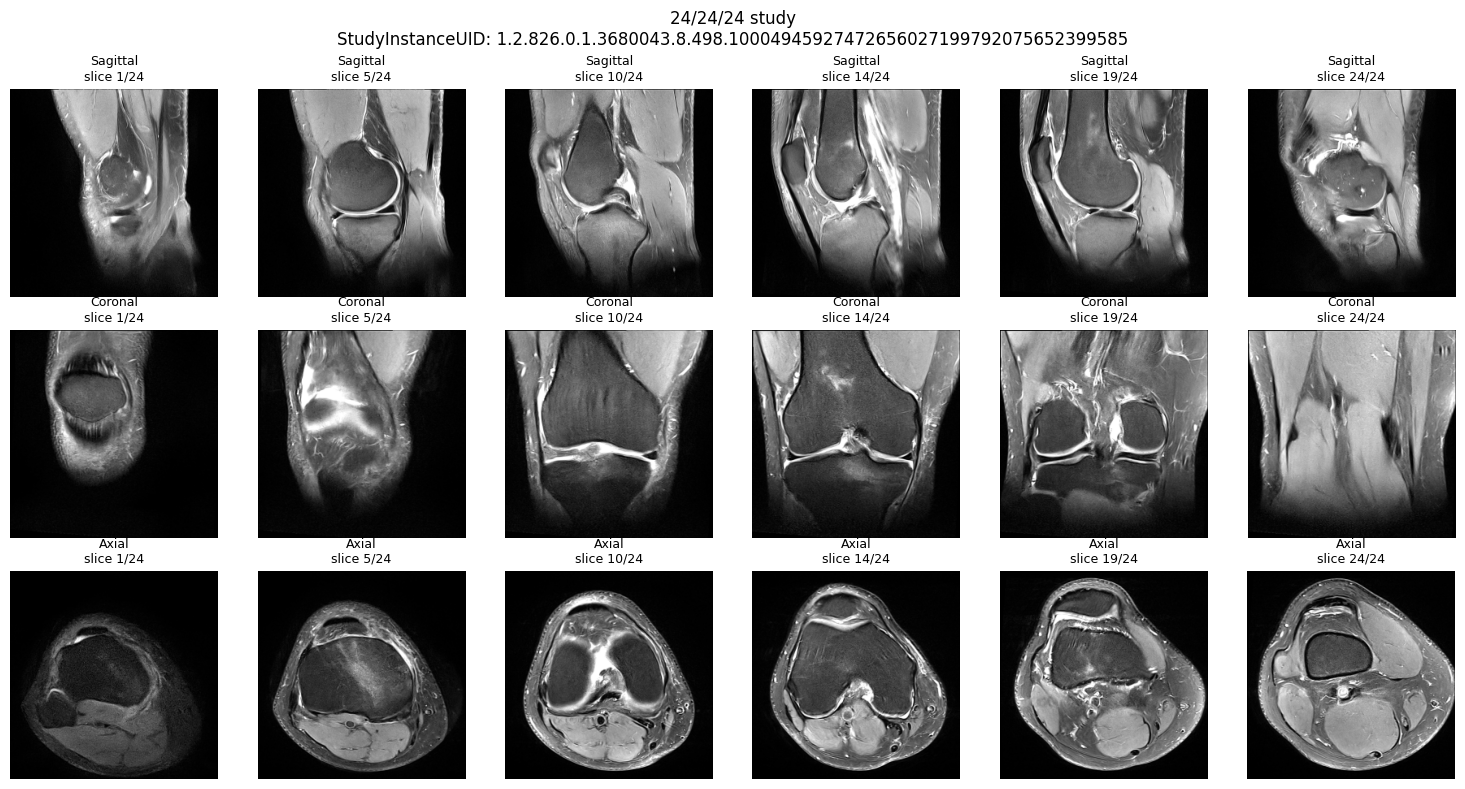


----------------------------------------------------------------------
short-slice study
UID: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
Sagittal : 22 → 24 slices
Coronal  : 16 → 24 slices
Axial    : 18 → 24 slices


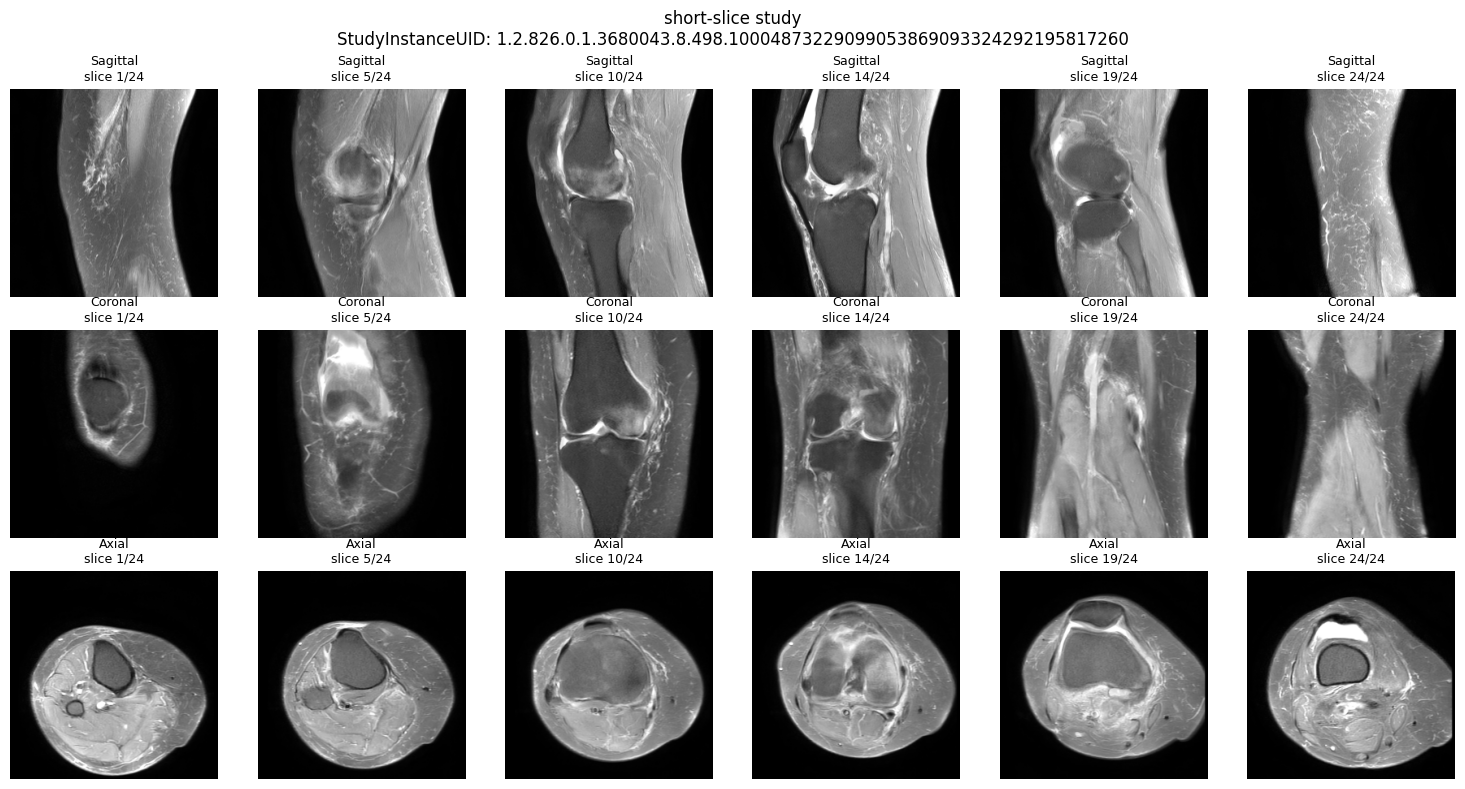


----------------------------------------------------------------------
short-axial study
UID: 1.2.826.0.1.3680043.8.498.10218285921271312931891912812808052375
Sagittal : 22 → 24 slices
Coronal  : 18 → 24 slices
Axial    : 15 → 24 slices


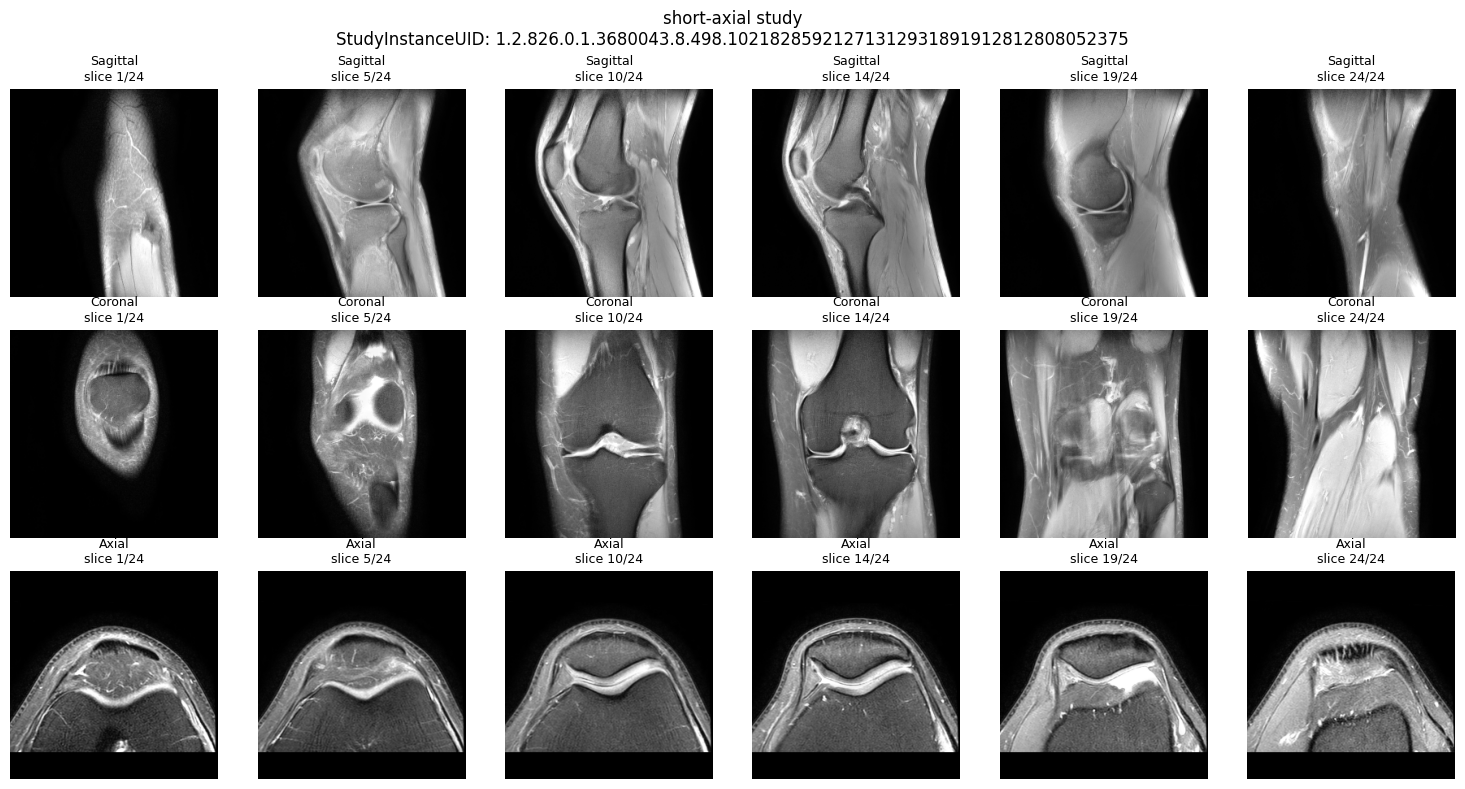


CELL 48 FINAL CHECK
✓ 24/24/24 study visualized
✓ Short-slice study visualized
✓ Short-axial study visualized
✓ All planes resampled to 24 slices
✓ No cache files modified
✓ No model created
✓ No training performed

✓ CELL 48 COMPLETED


In [54]:
# ============================================================
# CELL 48 — VISUALIZE RESAMPLED 24-SLICE VOLUMES
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CELL 48 — VISUALIZE RESAMPLED 24-SLICE VOLUMES")
print("=" * 70)

# ------------------------------------------------------------
# Find representative studies
# ------------------------------------------------------------

# We want:
#   1. A study with 24 slices in all planes
#   2. A study with noticeably fewer slices
#   3. A study with very few axial slices

audit = cache_geometry_audit

study_24 = audit[
    (audit["Sagittal_slices"] == 24) &
    (audit["Coronal_slices"] == 24) &
    (audit["Axial_slices"] == 24)
]

study_short = audit[
    (audit["Sagittal_slices"] <= 20) |
    (audit["Coronal_slices"] <= 20) |
    (audit["Axial_slices"] <= 20)
]

study_axial_short = audit[
    audit["Axial_slices"] <= 15
]

if len(study_24) == 0:
    raise RuntimeError("Could not find a 24/24/24 study.")

if len(study_short) == 0:
    raise RuntimeError("Could not find a short-slice study.")

if len(study_axial_short) == 0:
    raise RuntimeError("Could not find an axial-short study.")

uid_24 = study_24.iloc[0]["StudyInstanceUID"]
uid_short = study_short.iloc[0]["StudyInstanceUID"]
uid_axial = study_axial_short.iloc[0]["StudyInstanceUID"]

selected_uids = [
    ("24/24/24 study", uid_24),
    ("short-slice study", uid_short),
    ("short-axial study", uid_axial),
]

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def get_cache_path(uid):
    path = os.path.join(
        STUDY_CACHE_DIR,
        f"{uid}.npz"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    return path


def make_fixed_volume(volume):
    return resample_volume_to_24(
        volume,
        target_n=FIXED_N_SLICES
    )


# ------------------------------------------------------------
# Visualize
# ------------------------------------------------------------

for study_label, uid in selected_uids:

    path = get_cache_path(uid)

    with np.load(
        path,
        allow_pickle=False
    ) as data:

        print("\n" + "-" * 70)
        print(study_label)
        print(f"UID: {uid}")

        fig, axes = plt.subplots(
            3,
            6,
            figsize=(15, 8)
        )

        for row, plane in enumerate(PLANES):

            key = VOLUME_KEYS[plane]

            original = data[key]

            fixed = make_fixed_volume(
                original
            )

            print(
                f"{plane:9s}: "
                f"{original.shape[0]} → "
                f"{fixed.shape[0]} slices"
            )

            # Select six evenly spaced positions
            display_indices = np.linspace(
                0,
                FIXED_N_SLICES - 1,
                6,
                dtype=int,
            )

            for col, slice_idx in enumerate(
                display_indices
            ):

                ax = axes[row, col]

                ax.imshow(
                    fixed[slice_idx],
                    cmap="gray",
                    vmin=0,
                    vmax=255,
                )

                ax.set_title(
                    f"{plane}\n"
                    f"slice {slice_idx + 1}/24",
                    fontsize=9,
                )

                ax.axis("off")

        fig.suptitle(
            f"{study_label}\n"
            f"StudyInstanceUID: {uid}",
            fontsize=12,
        )

        plt.tight_layout()
        plt.show()

print("\n" + "=" * 70)
print("CELL 48 FINAL CHECK")
print("=" * 70)

print("✓ 24/24/24 study visualized")
print("✓ Short-slice study visualized")
print("✓ Short-axial study visualized")
print("✓ All planes resampled to 24 slices")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 48 COMPLETED")

In [55]:
# ============================================================
# CELL 49 — PYTORCH DATASET
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

print("=" * 70)
print("CELL 49 — PYTORCH DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "STUDY_CACHE_DIR",
    "npz_files",
    "train_study_ids",
    "train_label_matrix",
    "train_weight_matrix",
    "train_supervision_source",
    "TARGETS",
    "FIXED_N_SLICES",
    "IMAGE_SIZE",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

DATASET_PLANES = [
    "Sagittal",
    "Coronal",
    "Axial",
]

DATASET_VOLUME_KEYS = {
    "Sagittal": "Sagittal_volume",
    "Coronal": "Coronal_volume",
    "Axial": "Axial_volume",
}

EXPECTED_N_TARGETS = 12

if list(TARGETS) != [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]:
    raise RuntimeError(
        "TARGETS does not match the expected "
        "12-target competition schema."
    )

if FIXED_N_SLICES != 24:
    raise RuntimeError(
        f"Expected FIXED_N_SLICES=24, "
        f"got {FIXED_N_SLICES}"
    )

if IMAGE_SIZE != 256:
    raise RuntimeError(
        f"Expected IMAGE_SIZE=256, "
        f"got {IMAGE_SIZE}"
    )

print("✓ Target schema verified")
print(f"✓ Number of targets: {len(TARGETS)}")
print(f"✓ Fixed slices: {FIXED_N_SLICES}")
print(f"✓ Image size: {IMAGE_SIZE}×{IMAGE_SIZE}")


# ------------------------------------------------------------
# 3. Supervision matrix validation
# ------------------------------------------------------------

train_study_ids_arr = np.asarray(
    train_study_ids
).astype(str)

train_labels_arr = np.asarray(
    train_label_matrix
)

train_weights_arr = np.asarray(
    train_weight_matrix
)

train_sources_arr = np.asarray(
    train_supervision_source
)

print("\nSUPERVISION MATRICES")
print("-" * 70)

print(
    "train_study_ids      :",
    train_study_ids_arr.shape,
)

print(
    "train_label_matrix   :",
    train_labels_arr.shape,
)

print(
    "train_weight_matrix  :",
    train_weights_arr.shape,
)

print(
    "train_supervision_source:",
    train_sources_arr.shape,
)

# Exact expected dimensions
if train_study_ids_arr.shape != (4407,):
    raise RuntimeError(
        "train_study_ids has unexpected shape: "
        f"{train_study_ids_arr.shape}"
    )

expected_matrix_shape = (
    4407,
    EXPECTED_N_TARGETS,
)

for name, arr in [
    ("train_label_matrix", train_labels_arr),
    ("train_weight_matrix", train_weights_arr),
    ("train_supervision_source", train_sources_arr),
]:

    if arr.shape != expected_matrix_shape:
        raise RuntimeError(
            f"{name} has unexpected shape: "
            f"{arr.shape}; expected "
            f"{expected_matrix_shape}"
        )

print("✓ Supervision matrix dimensions verified")


# ------------------------------------------------------------
# 4. Verify UID uniqueness
# ------------------------------------------------------------

if len(set(train_study_ids_arr)) != 4407:
    raise RuntimeError(
        "train_study_ids contains duplicates."
    )

print("✓ Training UIDs are unique")


# ------------------------------------------------------------
# 5. Build UID → cache path mapping
# ------------------------------------------------------------

uid_to_cache_path = {}

for path in npz_files:

    filename = os.path.basename(path)

    if not filename.endswith(".npz"):
        continue

    uid = filename[:-4]

    if uid in uid_to_cache_path:
        raise RuntimeError(
            f"Duplicate cache UID detected: {uid}"
        )

    uid_to_cache_path[uid] = path


if len(uid_to_cache_path) != 4407:
    raise RuntimeError(
        f"Expected 4407 cache mappings, "
        f"got {len(uid_to_cache_path)}"
    )

missing_cache_for_training = [
    uid
    for uid in train_study_ids_arr
    if uid not in uid_to_cache_path
]

if missing_cache_for_training:
    raise RuntimeError(
        "Training studies missing from cache: "
        f"{len(missing_cache_for_training)}"
    )

print(
    "✓ UID → cache-path mapping verified "
    f"({len(uid_to_cache_path)} studies)"
)


# ------------------------------------------------------------
# 6. Dataset
# ------------------------------------------------------------

class RSNAKneeV2Dataset(Dataset):

    def __init__(
        self,
        study_ids,
        label_matrix,
        weight_matrix,
        cache_paths,
        fixed_n_slices=24,
        image_size=256,
    ):

        self.study_ids = np.asarray(
            study_ids
        ).astype(str)

        self.labels = np.asarray(
            label_matrix,
            dtype=np.float32,
        )

        self.weights = np.asarray(
            weight_matrix,
            dtype=np.float32,
        )

        self.cache_paths = cache_paths

        self.fixed_n_slices = int(
            fixed_n_slices
        )

        self.image_size = int(
            image_size
        )

        # ----------------------------------------------------
        # Strict consistency checks
        # ----------------------------------------------------

        if len(self.study_ids) != len(
            self.labels
        ):
            raise ValueError(
                "study_ids and label_matrix "
                "have different lengths."
            )

        if len(self.study_ids) != len(
            self.weights
        ):
            raise ValueError(
                "study_ids and weight_matrix "
                "have different lengths."
            )

        if self.labels.ndim != 2:
            raise ValueError(
                f"Labels must be 2D, "
                f"got {self.labels.shape}"
            )

        if self.weights.ndim != 2:
            raise ValueError(
                f"Weights must be 2D, "
                f"got {self.weights.shape}"
            )

        if self.labels.shape[1] != len(
            TARGETS
        ):
            raise ValueError(
                "Label target count does not "
                "match TARGETS."
            )

        if self.weights.shape != self.labels.shape:
            raise ValueError(
                "Weight matrix shape does not "
                "match label matrix."
            )

        # Every UID must have a cache file
        missing = [
            uid
            for uid in self.study_ids
            if uid not in self.cache_paths
        ]

        if missing:
            raise ValueError(
                f"{len(missing)} studies have "
                "no cache file."
            )

    def __len__(self):

        return len(self.study_ids)

    def __getitem__(self, index):

        uid = self.study_ids[index]

        cache_path = self.cache_paths[uid]

        # ----------------------------------------------------
        # Load cache
        # ----------------------------------------------------

        with np.load(
            cache_path,
            allow_pickle=False,
        ) as data:

            # Verify stored UID
            stored_uid = str(
                data["study_id"].item()
            )

            if stored_uid != uid:
                raise RuntimeError(
                    f"UID mismatch:\n"
                    f"Expected: {uid}\n"
                    f"Stored:   {stored_uid}"
                )

            plane_volumes = []

            for plane in DATASET_PLANES:

                key = DATASET_VOLUME_KEYS[
                    plane
                ]

                volume = data[key]

                # --------------------------------------------
                # Strict cache validation
                # --------------------------------------------

                if volume.ndim != 3:
                    raise RuntimeError(
                        f"{uid} / {plane}: "
                        f"unexpected shape "
                        f"{volume.shape}"
                    )

                if volume.shape[1:] != (
                    self.image_size,
                    self.image_size,
                ):
                    raise RuntimeError(
                        f"{uid} / {plane}: "
                        f"unexpected spatial shape "
                        f"{volume.shape}"
                    )

                if volume.dtype != np.uint8:
                    raise RuntimeError(
                        f"{uid} / {plane}: "
                        f"expected uint8, "
                        f"got {volume.dtype}"
                    )

                # --------------------------------------------
                # Convert to fixed 24 slices
                # --------------------------------------------

                if volume.shape[0] != (
                    self.fixed_n_slices
                ):

                    volume = resample_volume_to_24(
                        volume,
                        target_n=self.fixed_n_slices,
                    )

                # Final shape check
                if volume.shape != (
                    self.fixed_n_slices,
                    self.image_size,
                    self.image_size,
                ):
                    raise RuntimeError(
                        f"{uid} / {plane}: "
                        f"fixed volume has unexpected "
                        f"shape {volume.shape}"
                    )

                plane_volumes.append(volume)

        # ----------------------------------------------------
        # Stack planes
        # ----------------------------------------------------

        # [3, 24, 256, 256]
        images = np.stack(
            plane_volumes,
            axis=0,
        )

        if images.shape != (
            3,
            self.fixed_n_slices,
            self.image_size,
            self.image_size,
        ):
            raise RuntimeError(
                f"Final image tensor has "
                f"unexpected shape: "
                f"{images.shape}"
            )

        # ----------------------------------------------------
        # Labels and weights
        # ----------------------------------------------------

        labels = self.labels[index].copy()

        weights = self.weights[index].copy()

        # ----------------------------------------------------
        # Final numerical checks
        # ----------------------------------------------------

        if not np.isfinite(
            images.astype(np.float32)
        ).all():

            raise RuntimeError(
                f"{uid}: image contains "
                "non-finite values."
            )

        if not np.isfinite(labels).all():
            raise RuntimeError(
                f"{uid}: labels contain "
                "non-finite values."
            )

        if not np.isfinite(weights).all():
            raise RuntimeError(
                f"{uid}: weights contain "
                "non-finite values."
            )

        if images.min() < 0 or images.max() > 255:
            raise RuntimeError(
                f"{uid}: image intensity "
                "outside uint8 range."
            )

        # ----------------------------------------------------
        # Return tensors
        # ----------------------------------------------------

        images_tensor = torch.from_numpy(
            images
        )

        labels_tensor = torch.from_numpy(
            labels
        )

        weights_tensor = torch.from_numpy(
            weights
        )

        return {
            "images": images_tensor,
            "labels": labels_tensor,
            "weights": weights_tensor,
            "uid": uid,
        }


# ------------------------------------------------------------
# 7. Instantiate full training Dataset
# ------------------------------------------------------------

train_dataset = RSNAKneeV2Dataset(
    study_ids=train_study_ids_arr,
    label_matrix=train_labels_arr,
    weight_matrix=train_weights_arr,
    cache_paths=uid_to_cache_path,
    fixed_n_slices=FIXED_N_SLICES,
    image_size=IMAGE_SIZE,
)

print("\n✓ Dataset instantiated")
print(
    f"Dataset length: {len(train_dataset)}"
)


# ------------------------------------------------------------
# 8. Single-sample smoke test
# ------------------------------------------------------------

sample = train_dataset[0]

print("\n" + "=" * 70)
print("SINGLE-SAMPLE SMOKE TEST")
print("=" * 70)

print(
    "UID    :",
    sample["uid"],
)

print(
    "images :",
    tuple(sample["images"].shape),
    sample["images"].dtype,
)

print(
    "labels :",
    tuple(sample["labels"].shape),
    sample["labels"].dtype,
)

print(
    "weights:",
    tuple(sample["weights"].shape),
    sample["weights"].dtype,
)

assert isinstance(
    sample["uid"],
    str,
)

assert sample["images"].shape == (
    3,
    24,
    256,
    256,
)

assert sample["images"].dtype == torch.uint8

assert sample["labels"].shape == (
    12,
)

assert sample["weights"].shape == (
    12,
)

assert sample["labels"].dtype == torch.float32

assert sample["weights"].dtype == torch.float32

assert (
    sample["images"].min().item() >= 0
)

assert (
    sample["images"].max().item() <= 255
)

print("✓ Single-sample shape checks passed")


# ------------------------------------------------------------
# 9. Verify supervision semantics
# ------------------------------------------------------------

known_mask = sample["weights"] > 0
unknown_mask = sample["weights"] == 0

print("\nSUPERVISION FOR SAMPLE")
print("-" * 70)

print(
    "Known targets  :",
    int(known_mask.sum().item()),
)

print(
    "Unknown targets:",
    int(unknown_mask.sum().item()),
)

print(
    "Labels         :",
    sample["labels"].numpy(),
)

print(
    "Weights        :",
    sample["weights"].numpy(),
)

# Unknown labels should remain -1
if unknown_mask.any():

    unknown_labels = sample[
        "labels"
    ][unknown_mask]

    if not torch.all(
        unknown_labels == -1
    ):
        raise RuntimeError(
            "Found weight=0 labels that "
            "are not -1."
        )

print(
    "✓ Unknown-label convention verified"
)


# ------------------------------------------------------------
# 10. Test a short-slice study explicitly
# ------------------------------------------------------------

short_uid = (
    cache_geometry_audit
    .sort_values(
        [
            "Sagittal_slices",
            "Coronal_slices",
            "Axial_slices",
        ]
    )
    .iloc[0]["StudyInstanceUID"]
)

short_index = np.where(
    train_study_ids_arr == short_uid
)[0]

if len(short_index) != 1:

    raise RuntimeError(
        f"Could not uniquely locate "
        f"short-slice study {short_uid}"
    )

short_sample = train_dataset[
    int(short_index[0])
]

assert short_sample[
    "images"
].shape == (
    3,
    24,
    256,
    256,
)

print(
    "\n✓ Short-slice study successfully "
    "loaded and resampled:"
)

print(
    "  UID:",
    short_uid,
)

print(
    "  Original:",
    (
        int(
            cache_geometry_audit.loc[
                cache_geometry_audit[
                    "StudyInstanceUID"
                ] == short_uid,
                "Sagittal_slices",
            ].iloc[0]
        ),
        int(
            cache_geometry_audit.loc[
                cache_geometry_audit[
                    "StudyInstanceUID"
                ] == short_uid,
                "Coronal_slices",
            ].iloc[0]
        ),
        int(
            cache_geometry_audit.loc[
                cache_geometry_audit[
                    "StudyInstanceUID"
                ] == short_uid,
                "Axial_slices",
            ].iloc[0]
        ),
    ),
)

print(
    "  Dataset:",
    tuple(
        short_sample["images"].shape
    ),
)


# ------------------------------------------------------------
# 11. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 49 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ 4,407 studies represented")
print("✓ UID → cache mapping verified")
print("✓ Label matrix aligned")
print("✓ Weight matrix aligned")
print("✓ All 3 planes loaded")
print("✓ Fixed 24-slice representation verified")
print("✓ Image tensor = [3,24,256,256]")
print("✓ Label tensor = [12]")
print("✓ Weight tensor = [12]")
print("✓ Unknown labels preserved as -1")
print("✓ Unknown-label weights preserved as 0")
print("✓ Short-slice study tested")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 49 COMPLETED")

CELL 49 — PYTORCH DATASET
✓ Required objects found
✓ Target schema verified
✓ Number of targets: 12
✓ Fixed slices: 24
✓ Image size: 256×256

SUPERVISION MATRICES
----------------------------------------------------------------------
train_study_ids      : (4407,)
train_label_matrix   : (4407, 12)
train_weight_matrix  : (4407, 12)
train_supervision_source: (4407, 12)
✓ Supervision matrix dimensions verified
✓ Training UIDs are unique
✓ UID → cache-path mapping verified (4407 studies)

✓ Dataset instantiated
Dataset length: 4407

SINGLE-SAMPLE SMOKE TEST
UID    : 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
images : (3, 24, 256, 256) torch.uint8
labels : (12,) torch.float32
weights: (12,) torch.float32
✓ Single-sample shape checks passed

SUPERVISION FOR SAMPLE
----------------------------------------------------------------------
Known targets  : 0
Unknown targets: 12
Labels         : [-1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]
Weights        : [0. 0. 0. 0. 0.

In [56]:
# ============================================================
# CELL 50 — PYTORCH DATALOADER + BATCH SMOKE TEST
# ============================================================

import gc
import time
import numpy as np
import torch
from torch.utils.data import DataLoader

print("=" * 70)
print("CELL 50 — PYTORCH DATALOADER + BATCH SMOKE TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "train_dataset",
    "BATCH_SIZE",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")

print(
    f"Configured batch size: {BATCH_SIZE}"
)

# ------------------------------------------------------------
# 2. Build smoke-test DataLoader
# ------------------------------------------------------------

smoke_batch_size = min(
    int(BATCH_SIZE),
    4,
)

train_loader_smoke = DataLoader(
    train_dataset,
    batch_size=smoke_batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False,
)

print(
    f"✓ DataLoader created "
    f"(batch_size={smoke_batch_size}, "
    f"num_workers=0)"
)

# ------------------------------------------------------------
# 3. Fetch first batch
# ------------------------------------------------------------

start_time = time.time()

batch = next(
    iter(train_loader_smoke)
)

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("FIRST BATCH")
print("=" * 70)

print(
    f"Load time: {elapsed:.3f} sec"
)

print(
    "images :",
    tuple(batch["images"].shape),
    batch["images"].dtype,
)

print(
    "labels :",
    tuple(batch["labels"].shape),
    batch["labels"].dtype,
)

print(
    "weights:",
    tuple(batch["weights"].shape),
    batch["weights"].dtype,
)

print(
    "UIDs   :",
    len(batch["uid"]),
)

print(
    "UID sample:"
)

for uid in batch["uid"]:
    print(
        "  ",
        uid
    )

# ------------------------------------------------------------
# 4. Exact shape assertions
# ------------------------------------------------------------

expected_images_shape = (
    smoke_batch_size,
    3,
    24,
    256,
    256,
)

expected_target_shape = (
    smoke_batch_size,
    len(TARGETS),
)

if tuple(batch["images"].shape) != (
    expected_images_shape
):

    raise RuntimeError(
        "Unexpected image batch shape:\n"
        f"Got:      {tuple(batch['images'].shape)}\n"
        f"Expected: {expected_images_shape}"
    )

if tuple(batch["labels"].shape) != (
    expected_target_shape
):

    raise RuntimeError(
        "Unexpected label batch shape:\n"
        f"Got:      {tuple(batch['labels'].shape)}\n"
        f"Expected: {expected_target_shape}"
    )

if tuple(batch["weights"].shape) != (
    expected_target_shape
):

    raise RuntimeError(
        "Unexpected weight batch shape:\n"
        f"Got:      {tuple(batch['weights'].shape)}\n"
        f"Expected: {expected_target_shape}"
    )

if len(batch["uid"]) != smoke_batch_size:

    raise RuntimeError(
        "Unexpected number of UIDs."
    )

print("\n✓ Batch shapes verified")

# ------------------------------------------------------------
# 5. Dtype checks
# ------------------------------------------------------------

if batch["images"].dtype != torch.uint8:
    raise RuntimeError(
        f"Images have unexpected dtype: "
        f"{batch['images'].dtype}"
    )

if batch["labels"].dtype != torch.float32:
    raise RuntimeError(
        f"Labels have unexpected dtype: "
        f"{batch['labels'].dtype}"
    )

if batch["weights"].dtype != torch.float32:
    raise RuntimeError(
        f"Weights have unexpected dtype: "
        f"{batch['weights'].dtype}"
    )

print("✓ Batch dtypes verified")

# ------------------------------------------------------------
# 6. Image range
# ------------------------------------------------------------

image_min = batch["images"].min().item()
image_max = batch["images"].max().item()

print(
    f"\nImage range: {image_min} → {image_max}"
)

if image_min < 0 or image_max > 255:

    raise RuntimeError(
        "Batch contains image values "
        "outside [0,255]."
    )

print("✓ Image intensity range verified")

# ------------------------------------------------------------
# 7. Label / weight semantics
# ------------------------------------------------------------

labels = batch["labels"]
weights = batch["weights"]

if not torch.isfinite(labels).all():
    raise RuntimeError(
        "Non-finite labels detected."
    )

if not torch.isfinite(weights).all():
    raise RuntimeError(
        "Non-finite weights detected."
    )

if (weights < 0).any():
    raise RuntimeError(
        "Negative supervision weights detected."
    )

# Unknown = weight 0
unknown_mask = weights == 0

if unknown_mask.any():

    unknown_labels = labels[
        unknown_mask
    ]

    if not torch.all(
        unknown_labels == -1
    ):

        raise RuntimeError(
            "Found weight=0 entries whose "
            "label is not -1."
        )

# Known = weight > 0
known_mask = weights > 0

if known_mask.any():

    known_labels = labels[
        known_mask
    ]

    if not torch.all(
        (known_labels == 0)
        | (known_labels == 1)
    ):

        raise RuntimeError(
            "Known labels contain values "
            "other than 0 or 1."
        )

print(
    "✓ Label/weight semantics verified"
)

# ------------------------------------------------------------
# 8. Supervision statistics
# ------------------------------------------------------------

known_count = int(
    known_mask.sum().item()
)

unknown_count = int(
    unknown_mask.sum().item()
)

positive_count = int(
    ((labels == 1) & known_mask)
    .sum()
    .item()
)

negative_count = int(
    ((labels == 0) & known_mask)
    .sum()
    .item()
)

print("\n" + "-" * 70)
print("FIRST-BATCH SUPERVISION")
print("-" * 70)

print(
    f"Known entries    : {known_count}"
)

print(
    f"Unknown entries  : {unknown_count}"
)

print(
    f"Positive entries : {positive_count}"
)

print(
    f"Negative entries : {negative_count}"
)

print(
    f"Total entries    : "
    f"{labels.numel()}"
)

if (
    known_count
    + unknown_count
    != labels.numel()
):

    raise RuntimeError(
        "Known + unknown count does "
        "not equal total target entries."
    )

# ------------------------------------------------------------
# 9. UID integrity
# ------------------------------------------------------------

if len(set(batch["uid"])) != len(
    batch["uid"]
):

    raise RuntimeError(
        "Duplicate UIDs found inside batch."
    )

print(
    "\n✓ Batch UIDs are unique"
)

# ------------------------------------------------------------
# 10. Check that Dataset has not changed
# ------------------------------------------------------------

if len(train_dataset) != 4407:

    raise RuntimeError(
        "Dataset length changed unexpectedly."
    )

print(
    "✓ Dataset length remains 4,407"
)

# ------------------------------------------------------------
# 11. Fetch several consecutive batches
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MULTI-BATCH SMOKE TEST")
print("=" * 70)

iterator = iter(
    train_loader_smoke
)

multi_batch_times = []
multi_batch_uids = []

for batch_idx in range(5):

    t0 = time.time()

    b = next(iterator)

    dt = time.time() - t0

    multi_batch_times.append(dt)

    multi_batch_uids.extend(
        list(b["uid"])
    )

    # Shape check for every batch
    if b["images"].shape[1:] != (
        3,
        24,
        256,
        256,
    ):

        raise RuntimeError(
            f"Batch {batch_idx}: "
            f"unexpected image shape "
            f"{tuple(b['images'].shape)}"
        )

    if b["labels"].shape[1] != len(
        TARGETS
    ):

        raise RuntimeError(
            f"Batch {batch_idx}: "
            "unexpected target count."
        )

    if b["weights"].shape != (
        b["labels"].shape
    ):

        raise RuntimeError(
            f"Batch {batch_idx}: "
            "label/weight shape mismatch."
        )

    print(
        f"Batch {batch_idx + 1}: "
        f"{len(b['uid'])} studies | "
        f"{dt:.3f}s"
    )

if len(
    set(multi_batch_uids)
) != len(multi_batch_uids):

    raise RuntimeError(
        "Duplicate UIDs detected across "
        "the first five batches."
    )

print(
    "\n✓ Five consecutive batches passed"
)

# ------------------------------------------------------------
# 12. CPU memory estimate
# ------------------------------------------------------------

images_per_sample = (
    3
    * 24
    * 256
    * 256
)

bytes_per_sample_uint8 = (
    images_per_sample
)

mb_per_sample = (
    bytes_per_sample_uint8
    / (1024 ** 2)
)

batch_image_mb = (
    mb_per_sample
    * smoke_batch_size
)

print("\n" + "=" * 70)
print("CPU IMAGE MEMORY")
print("=" * 70)

print(
    f"Image elements/study : "
    f"{images_per_sample:,}"
)

print(
    f"Image memory/study   : "
    f"{mb_per_sample:.2f} MB "
    f"(uint8)"
)

print(
    f"Image memory/batch   : "
    f"{batch_image_mb:.2f} MB "
    f"(uint8)"
)

# ------------------------------------------------------------
# 13. Timing summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA LOADING TIMING")
print("=" * 70)

print(
    f"Mean batch load time: "
    f"{np.mean(multi_batch_times):.3f}s"
)

print(
    f"Median batch time   : "
    f"{np.median(multi_batch_times):.3f}s"
)

print(
    f"Max batch time      : "
    f"{np.max(multi_batch_times):.3f}s"
)

# ------------------------------------------------------------
# 14. Cleanup iterator
# ------------------------------------------------------------

del iterator
gc.collect()

# ------------------------------------------------------------
# 15. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 50 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ DataLoader created")
print("✓ First batch loaded")
print("✓ Image shape verified")
print("✓ Label shape verified")
print("✓ Weight shape verified")
print("✓ Dtypes verified")
print("✓ Image range verified")
print("✓ Label/weight semantics verified")
print("✓ UID integrity verified")
print("✓ Five consecutive batches tested")
print("✓ Dataset length preserved")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 50 COMPLETED")

CELL 50 — PYTORCH DATALOADER + BATCH SMOKE TEST
✓ Required objects found
Configured batch size: 4
✓ DataLoader created (batch_size=4, num_workers=0)

FIRST BATCH
Load time: 0.263 sec
images : (4, 3, 24, 256, 256) torch.uint8
labels : (4, 12) torch.float32
weights: (4, 12) torch.float32
UIDs   : 4
UID sample:
   1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
   1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585
   1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231
   1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764

✓ Batch shapes verified
✓ Batch dtypes verified

Image range: 0 → 255
✓ Image intensity range verified
✓ Label/weight semantics verified

----------------------------------------------------------------------
FIRST-BATCH SUPERVISION
----------------------------------------------------------------------
Known entries    : 8
Unknown entries  : 40
Positive entries : 2
Negative entries : 6
Total entries    : 48

✓ Bat

In [57]:
# ============================================================
# CELL 51 — MULTI-WORKER DATALOADER BENCHMARK
# ============================================================

import gc
import time
import numpy as np
import torch
from torch.utils.data import DataLoader

print("=" * 70)
print("CELL 51 — MULTI-WORKER DATALOADER BENCHMARK")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "train_dataset",
    "BATCH_SIZE",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")

# ------------------------------------------------------------
# 2. Benchmark configurations
# ------------------------------------------------------------

benchmark_configs = [
    {
        "name": "workers_0_pin_false",
        "num_workers": 0,
        "pin_memory": False,
    },
    {
        "name": "workers_2_pin_true",
        "num_workers": 2,
        "pin_memory": True,
    },
    {
        "name": "workers_4_pin_true",
        "num_workers": 4,
        "pin_memory": True,
    },
]

benchmark_batch_size = int(BATCH_SIZE)

print(
    f"Batch size: {benchmark_batch_size}"
)

# ------------------------------------------------------------
# 3. Benchmark function
# ------------------------------------------------------------

def benchmark_loader(
    num_workers,
    pin_memory,
    n_batches=12,
):

    loader = DataLoader(
        train_dataset,
        batch_size=benchmark_batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,

        # Only useful when workers > 0
        persistent_workers=(
            num_workers > 0
        ),
    )

    iterator = iter(loader)

    # --------------------------------------------------------
    # Warm-up batch
    # --------------------------------------------------------

    warmup_start = time.time()

    warmup_batch = next(iterator)

    warmup_time = (
        time.time() - warmup_start
    )

    # --------------------------------------------------------
    # Timed batches
    # --------------------------------------------------------

    batch_times = []
    total_studies = 0

    first_uid = warmup_batch["uid"][0]

    for _ in range(n_batches):

        start = time.time()

        batch = next(iterator)

        elapsed = time.time() - start

        batch_times.append(elapsed)

        total_studies += len(
            batch["uid"]
        )

        # Strict shape check
        expected_shape = (
            benchmark_batch_size,
            3,
            24,
            256,
            256,
        )

        if tuple(batch["images"].shape) != (
            expected_shape
        ):

            raise RuntimeError(
                f"Unexpected batch shape: "
                f"{tuple(batch['images'].shape)}"
            )

        # UID check
        if len(batch["uid"]) != (
            benchmark_batch_size
        ):

            raise RuntimeError(
                "Unexpected UID count."
            )

        # Dtype checks
        if batch["images"].dtype != torch.uint8:
            raise RuntimeError(
                "Unexpected image dtype."
            )

        if batch["labels"].dtype != torch.float32:
            raise RuntimeError(
                "Unexpected label dtype."
            )

        if batch["weights"].dtype != torch.float32:
            raise RuntimeError(
                "Unexpected weight dtype."
            )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del iterator
    del loader

    gc.collect()

    return {
        "num_workers": num_workers,
        "pin_memory": pin_memory,
        "warmup_sec": warmup_time,
        "mean_batch_sec": float(
            np.mean(batch_times)
        ),
        "median_batch_sec": float(
            np.median(batch_times)
        ),
        "min_batch_sec": float(
            np.min(batch_times)
        ),
        "max_batch_sec": float(
            np.max(batch_times)
        ),
        "batches": n_batches,
        "studies": total_studies,
        "studies_per_sec": (
            total_studies
            / max(
                np.sum(batch_times),
                1e-8,
            )
        ),
        "first_uid": first_uid,
    }


# ------------------------------------------------------------
# 4. Run benchmarks
# ------------------------------------------------------------

results = []

for config in benchmark_configs:

    print("\n" + "-" * 70)

    print(
        f"Testing "
        f"{config['name']}"
    )

    print(
        f"  num_workers = "
        f"{config['num_workers']}"
    )

    print(
        f"  pin_memory  = "
        f"{config['pin_memory']}"
    )

    result = benchmark_loader(
        num_workers=config["num_workers"],
        pin_memory=config["pin_memory"],
        n_batches=12,
    )

    results.append(result)

    print(
        f"  Warmup       : "
        f"{result['warmup_sec']:.3f}s"
    )

    print(
        f"  Mean batch   : "
        f"{result['mean_batch_sec']:.3f}s"
    )

    print(
        f"  Median batch : "
        f"{result['median_batch_sec']:.3f}s"
    )

    print(
        f"  Max batch    : "
        f"{result['max_batch_sec']:.3f}s"
    )

    print(
        f"  Studies/sec  : "
        f"{result['studies_per_sec']:.2f}"
    )


# ------------------------------------------------------------
# 5. Results table
# ------------------------------------------------------------

dataloader_benchmark = pd.DataFrame(
    results
)

print("\n" + "=" * 70)
print("DATALOADER BENCHMARK SUMMARY")
print("=" * 70)

display(
    dataloader_benchmark[
        [
            "num_workers",
            "pin_memory",
            "warmup_sec",
            "mean_batch_sec",
            "median_batch_sec",
            "max_batch_sec",
            "studies_per_sec",
        ]
    ]
)


# ------------------------------------------------------------
# 6. Select recommended configuration
# ------------------------------------------------------------

# We care primarily about median/mean batch time,
# but don't select a configuration that is slower
# than workers=0 unless the difference is negligible.

baseline = dataloader_benchmark[
    dataloader_benchmark["num_workers"] == 0
].iloc[0]

multi_worker = dataloader_benchmark[
    dataloader_benchmark["num_workers"] > 0
].copy()

if len(multi_worker) == 0:
    raise RuntimeError(
        "No multi-worker benchmark completed."
    )

best_idx = multi_worker[
    "mean_batch_sec"
].idxmin()

best = dataloader_benchmark.loc[
    best_idx
]

baseline_time = float(
    baseline["mean_batch_sec"]
)

best_time = float(
    best["mean_batch_sec"]
)

speedup = (
    baseline_time
    / max(best_time, 1e-8)
)

print("\n" + "=" * 70)
print("WORKER CONFIGURATION DECISION")
print("=" * 70)

print(
    f"num_workers=0 mean : "
    f"{baseline_time:.3f}s"
)

print(
    f"Best multi-worker  : "
    f"{int(best['num_workers'])} workers, "
    f"pin_memory={bool(best['pin_memory'])}"
)

print(
    f"Best mean batch    : "
    f"{best_time:.3f}s"
)

print(
    f"Measured speedup   : "
    f"{speedup:.2f}×"
)

# ------------------------------------------------------------
# 7. Recommended training config
# ------------------------------------------------------------

# Prefer the 4-worker configuration if it is competitive,
# because the actual training loop will benefit from
# asynchronous prefetching.

four_worker = dataloader_benchmark[
    dataloader_benchmark["num_workers"] == 4
]

if len(four_worker) == 1:

    four_worker_time = float(
        four_worker.iloc[0]["mean_batch_sec"]
    )

    # Use 4 workers if it is not catastrophically
    # slower than the best configuration.
    if four_worker_time <= (
        best_time * 1.25
    ):

        RECOMMENDED_NUM_WORKERS = 4
        RECOMMENDED_PIN_MEMORY = True

    else:

        RECOMMENDED_NUM_WORKERS = int(
            best["num_workers"]
        )

        RECOMMENDED_PIN_MEMORY = bool(
            best["pin_memory"]
        )

else:

    RECOMMENDED_NUM_WORKERS = int(
        best["num_workers"]
    )

    RECOMMENDED_PIN_MEMORY = bool(
        best["pin_memory"]
    )

print(
    f"\nRecommended workers : "
    f"{RECOMMENDED_NUM_WORKERS}"
)

print(
    f"Recommended pin_mem : "
    f"{RECOMMENDED_PIN_MEMORY}"
)


# ------------------------------------------------------------
# 8. Save configuration objects
# ------------------------------------------------------------

NUM_WORKERS_FINAL = (
    RECOMMENDED_NUM_WORKERS
)

PIN_MEMORY_FINAL = (
    RECOMMENDED_PIN_MEMORY
)

print("\n✓ Saved:")
print("  dataloader_benchmark")
print("  NUM_WORKERS_FINAL")
print("  PIN_MEMORY_FINAL")


# ------------------------------------------------------------
# 9. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 51 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Single-worker baseline tested")
print("✓ Multi-worker configuration tested")
print("✓ pin_memory configuration tested")
print("✓ Batch shapes verified in every configuration")
print("✓ Batch dtypes verified")
print("✓ UID loading verified")
print("✓ Benchmark completed")
print("✓ Recommended worker configuration selected")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 51 COMPLETED")

CELL 51 — MULTI-WORKER DATALOADER BENCHMARK
✓ Required objects found
Batch size: 4

----------------------------------------------------------------------
Testing workers_0_pin_false
  num_workers = 0
  pin_memory  = False
  Warmup       : 0.208s
  Mean batch   : 0.232s
  Median batch : 0.227s
  Max batch    : 0.261s
  Studies/sec  : 17.27

----------------------------------------------------------------------
Testing workers_2_pin_true
  num_workers = 2
  pin_memory  = True
  Warmup       : 0.442s
  Mean batch   : 0.101s
  Median batch : 0.110s
  Max batch    : 0.188s
  Studies/sec  : 39.72

----------------------------------------------------------------------
Testing workers_4_pin_true
  num_workers = 4
  pin_memory  = True
  Warmup       : 0.479s
  Mean batch   : 0.074s
  Median batch : 0.039s
  Max batch    : 0.286s
  Studies/sec  : 54.29

DATALOADER BENCHMARK SUMMARY


,num_workers,pin_memory,warmup_sec,mean_batch_sec,median_batch_sec,max_batch_sec,studies_per_sec
0,0,False,0.208091,0.231576,0.227213,0.260694,17.272936
1,2,True,0.442195,0.100703,0.109894,0.187713,39.720786
2,4,True,0.479049,0.073672,0.038528,0.285814,54.294377



WORKER CONFIGURATION DECISION
num_workers=0 mean : 0.232s
Best multi-worker  : 4 workers, pin_memory=True
Best mean batch    : 0.074s
Measured speedup   : 3.14×

Recommended workers : 4
Recommended pin_mem : True

✓ Saved:
  dataloader_benchmark
  NUM_WORKERS_FINAL
  PIN_MEMORY_FINAL

CELL 51 FINAL INTEGRITY CHECK
✓ Single-worker baseline tested
✓ Multi-worker configuration tested
✓ pin_memory configuration tested
✓ Batch shapes verified in every configuration
✓ Batch dtypes verified
✓ UID loading verified
✓ Benchmark completed
✓ Recommended worker configuration selected
✓ No cache files modified
✓ No model created
✓ No training performed

✓ CELL 51 COMPLETED


In [58]:
# ============================================================
# CELL 52 — CORRECTED GOLD-ONLY 5-FOLD VALIDATION ASSIGNMENT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 52 — CORRECTED GOLD-ONLY 5-FOLD VALIDATION ASSIGNMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "oof_study_results",
    "train_study_ids",
    "TARGETS",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")


# ------------------------------------------------------------
# 2. Recover exactly the 58 gold studies
# ------------------------------------------------------------

UID_COL = "StudyInstanceUID"
TARGET_COL = "Target"
GOLD_COL = "Gold_Label"

required_oof_columns = [
    UID_COL,
    TARGET_COL,
    GOLD_COL,
]

missing_oof_columns = [
    c
    for c in required_oof_columns
    if c not in oof_study_results.columns
]

if missing_oof_columns:
    raise RuntimeError(
        "oof_study_results is missing required "
        f"columns: {missing_oof_columns}"
    )


gold_oof = oof_study_results[
    oof_study_results[GOLD_COL].notna()
].copy()

gold_oof[UID_COL] = (
    gold_oof[UID_COL]
    .astype(str)
)

gold_uids = (
    gold_oof[UID_COL]
    .unique()
    .astype(str)
)

if len(gold_uids) != 58:
    raise RuntimeError(
        f"Expected 58 gold studies, "
        f"found {len(gold_uids)}"
    )

print(
    f"✓ Exactly {len(gold_uids)} gold studies identified"
)


# ------------------------------------------------------------
# 3. Verify exactly 12 targets per gold study
# ------------------------------------------------------------

gold_target_counts = (
    gold_oof
    .groupby(UID_COL)[TARGET_COL]
    .nunique()
)

bad_gold_studies = gold_target_counts[
    gold_target_counts != len(TARGETS)
]

if len(bad_gold_studies) != 0:
    raise RuntimeError(
        "Gold studies do not all contain exactly "
        f"{len(TARGETS)} targets:\n"
        f"{bad_gold_studies.to_dict()}"
    )

print(
    f"✓ Every gold study has all "
    f"{len(TARGETS)} targets"
)


# ------------------------------------------------------------
# 4. Construct gold label matrix
# ------------------------------------------------------------

gold_pivot = (
    gold_oof
    .pivot_table(
        index=UID_COL,
        columns=TARGET_COL,
        values=GOLD_COL,
        aggfunc="first",
    )
)

missing_targets = [
    target
    for target in TARGETS
    if target not in gold_pivot.columns
]

if missing_targets:
    raise RuntimeError(
        "Gold matrix is missing targets: "
        f"{missing_targets}"
    )

gold_pivot = gold_pivot[
    TARGETS
].reindex(gold_uids)

if gold_pivot.isna().any().any():

    missing_cells = int(
        gold_pivot.isna().sum().sum()
    )

    raise RuntimeError(
        f"Gold matrix contains "
        f"{missing_cells} missing values."
    )

gold_labels = gold_pivot.values.astype(
    np.int64
)

if not np.isin(
    gold_labels,
    [0, 1]
).all():

    raise RuntimeError(
        "Gold labels must contain only "
        "0 and 1."
    )

print(
    f"✓ Gold label matrix: "
    f"{gold_labels.shape}"
)


# ------------------------------------------------------------
# 5. Verify gold studies exist in training universe
# ------------------------------------------------------------

all_training_uids = (
    np.asarray(train_study_ids)
    .astype(str)
)

training_uid_set = set(
    all_training_uids
)

missing_gold = [
    uid
    for uid in gold_uids
    if uid not in training_uid_set
]

if missing_gold:
    raise RuntimeError(
        "Gold studies missing from training universe: "
        f"{len(missing_gold)}"
    )

print(
    "✓ All gold studies exist in training universe"
)


# ------------------------------------------------------------
# 6. Fold configuration
# ------------------------------------------------------------

N_FOLDS = 5
SEED_FOLD = 2026

N_GOLD = len(gold_uids)

if N_GOLD != 58:
    raise RuntimeError(
        f"Expected 58 gold studies, got {N_GOLD}"
    )

# 58 / 5 = 11 remainder 3
#
# Therefore the only sensible balanced fold sizes are:
#
#   12, 12, 12, 11, 11
#
# These are HARD capacities, not preferences.
base_size = N_GOLD // N_FOLDS
remainder = N_GOLD % N_FOLDS

fold_capacities = np.full(
    N_FOLDS,
    base_size,
    dtype=np.int64,
)

fold_capacities[:remainder] += 1

assert np.array_equal(
    np.sort(fold_capacities),
    np.array([11, 11, 12, 12, 12])
)

print("\nFold capacities:")
for fold in range(N_FOLDS):
    print(
        f"  Fold {fold}: "
        f"{fold_capacities[fold]} studies"
    )


# ------------------------------------------------------------
# 7. Calculate target rarity weights
# ------------------------------------------------------------

positive_counts = gold_labels.sum(
    axis=0
).astype(np.float64)

negative_counts = (
    N_GOLD - positive_counts
).astype(np.float64)

# Rare positive targets receive more importance.
rarity_weights = 1.0 / np.maximum(
    positive_counts,
    1.0,
)

# Normalize only for numerical stability.
rarity_weights /= rarity_weights.mean()

print("\nGold positive counts:")
for target, count in zip(
    TARGETS,
    positive_counts.astype(int),
):
    print(
        f"  {target:20s}: {count}"
    )


# ------------------------------------------------------------
# 8. Determine study assignment order
# ------------------------------------------------------------
#
# We assign the most difficult studies first:
#
# - studies containing rare positives first
# - then studies with more positive labels
#
# This prevents rare pathology positives from being
# concentrated into the last few folds.
# ------------------------------------------------------------

study_difficulty = (
    gold_labels
    * rarity_weights[None, :]
).sum(axis=1)

study_positive_count = (
    gold_labels.sum(axis=1)
)

# Deterministic tie breaking.
rng = np.random.default_rng(
    SEED_FOLD
)

random_tiebreak = rng.random(
    N_GOLD
)

assignment_order = sorted(
    range(N_GOLD),
    key=lambda i: (
        -study_difficulty[i],
        -study_positive_count[i],
        random_tiebreak[i],
    )
)


# ------------------------------------------------------------
# 9. Capacity-constrained stratified assignment
# ------------------------------------------------------------

fold_assignments = np.full(
    N_GOLD,
    -1,
    dtype=np.int64,
)

fold_sizes = np.zeros(
    N_FOLDS,
    dtype=np.int64,
)

fold_positive_counts = np.zeros(
    (N_FOLDS, len(TARGETS)),
    dtype=np.float64,
)

desired_positive_counts = (
    positive_counts[None, :]
    / N_FOLDS
)


for study_idx in assignment_order:

    study_labels = (
        gold_labels[study_idx]
        .astype(np.float64)
    )

    # Only folds with remaining capacity
    available_folds = [
        fold
        for fold in range(N_FOLDS)
        if fold_sizes[fold]
        < fold_capacities[fold]
    ]

    if len(available_folds) == 0:
        raise RuntimeError(
            "No fold capacity remaining "
            "while studies are still unassigned."
        )

    candidate_scores = []

    for fold in available_folds:

        projected_counts = (
            fold_positive_counts[fold]
            + study_labels
        )

        # Weighted squared deviation from the
        # ideal number of positives in this fold.
        positive_balance_error = np.sum(
            (
                projected_counts
                - desired_positive_counts[0]
            ) ** 2
            * rarity_weights
        )

        # Prefer folds whose current positive
        # counts are relatively low.
        current_load_error = (
            fold_sizes[fold]
            / fold_capacities[fold]
        )

        score = (
            positive_balance_error
            + 0.05 * current_load_error
        )

        candidate_scores.append(
            score
        )

    best_candidate_position = int(
        np.argmin(candidate_scores)
    )

    chosen_fold = int(
        available_folds[
            best_candidate_position
        ]
    )

    fold_assignments[
        study_idx
    ] = chosen_fold

    fold_sizes[
        chosen_fold
    ] += 1

    fold_positive_counts[
        chosen_fold
    ] += study_labels


# ------------------------------------------------------------
# 10. Hard assignment validation
# ------------------------------------------------------------

if np.any(
    fold_assignments < 0
):

    raise RuntimeError(
        "At least one gold study was not "
        "assigned to a fold."
    )

if np.any(
    fold_sizes != fold_capacities
):

    raise RuntimeError(
        "Fold capacities were not exactly "
        "satisfied.\n"
        f"Actual:    {fold_sizes.tolist()}\n"
        f"Expected:  {fold_capacities.tolist()}"
    )

if len(
    np.unique(fold_assignments)
) != N_FOLDS:

    raise RuntimeError(
        "Not all five folds are represented."
    )

print(
    "\n✓ All 58 gold studies assigned"
)

print(
    "✓ Exact fold capacities satisfied"
)

print(
    "✓ All five folds represented"
)


# ------------------------------------------------------------
# 11. Build assignment dataframe
# ------------------------------------------------------------

gold_fold_assignment = pd.DataFrame({
    "StudyInstanceUID": gold_uids,
    "Fold": fold_assignments,
})

# Sort by fold for readability.
gold_fold_assignment = (
    gold_fold_assignment
    .sort_values(
        ["Fold", "StudyInstanceUID"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 12. Fold-size table
# ------------------------------------------------------------

fold_size_table = (
    gold_fold_assignment
    .groupby("Fold")
    .size()
    .rename("N")
    .reset_index()
)

print("\n" + "=" * 70)
print("GOLD FOLD SIZES")
print("=" * 70)

print(
    fold_size_table.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 13. Per-target positive distribution
# ------------------------------------------------------------

positive_distribution = []

for fold in range(N_FOLDS):

    fold_uid_set = set(
        gold_fold_assignment[
            gold_fold_assignment["Fold"]
            == fold
        ]["StudyInstanceUID"]
        .astype(str)
    )

    fold_indices = [
        i
        for i, uid in enumerate(gold_uids)
        if uid in fold_uid_set
    ]

    row = {
        "Fold": fold,
        "N": len(fold_indices),
    }

    for target_idx, target in enumerate(
        TARGETS
    ):

        row[target] = int(
            gold_labels[
                fold_indices,
                target_idx
            ].sum()
        )

    positive_distribution.append(
        row
    )

gold_fold_positive_table = pd.DataFrame(
    positive_distribution
)

print("\n" + "=" * 70)
print("GOLD POSITIVE DISTRIBUTION BY FOLD")
print("=" * 70)

print(
    gold_fold_positive_table.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 14. Target balance summary
# ------------------------------------------------------------

target_balance_rows = []

for target_idx, target in enumerate(
    TARGETS
):

    fold_values = (
        gold_fold_positive_table[target]
        .values
    )

    target_balance_rows.append({
        "Target": target,
        "TotalPositives": int(
            positive_counts[target_idx]
        ),
        "FoldMin": int(
            fold_values.min()
        ),
        "FoldMax": int(
            fold_values.max()
        ),
        "FoldMean": float(
            fold_values.mean()
        ),
    })

gold_target_fold_balance = pd.DataFrame(
    target_balance_rows
)

print("\n" + "=" * 70)
print("TARGET FOLD BALANCE")
print("=" * 70)

print(
    gold_target_fold_balance.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ------------------------------------------------------------
# 15. Create convenient fold UID lists
# ------------------------------------------------------------

gold_fold_uids = {}

for fold in range(N_FOLDS):

    gold_fold_uids[fold] = (
        gold_fold_assignment[
            gold_fold_assignment["Fold"]
            == fold
        ]["StudyInstanceUID"]
        .astype(str)
        .tolist()
    )

    if len(gold_fold_uids[fold]) != (
        fold_capacities[fold]
    ):

        raise RuntimeError(
            f"Fold {fold} has incorrect "
            "number of UIDs."
        )


# ------------------------------------------------------------
# 16. Construct Fold-0 split
# ------------------------------------------------------------

VALIDATION_FOLD = 0

validation_uids = np.asarray(
    gold_fold_uids[VALIDATION_FOLD],
    dtype=str,
)

validation_uid_set = set(
    validation_uids
)

training_uids_fold0 = np.asarray(
    [
        uid
        for uid in all_training_uids
        if uid not in validation_uid_set
    ],
    dtype=str,
)


# ------------------------------------------------------------
# 17. Strict train/validation leakage checks
# ------------------------------------------------------------

training_uid_set_fold0 = set(
    training_uids_fold0
)

overlap = (
    training_uid_set_fold0
    & validation_uid_set
)

if len(overlap) != 0:

    raise RuntimeError(
        "TRAIN/VALIDATION UID LEAKAGE DETECTED: "
        f"{len(overlap)} overlapping studies."
    )

if (
    len(training_uids_fold0)
    + len(validation_uids)
    != 4407
):

    raise RuntimeError(
        "Train + validation does not "
        "account for all 4,407 studies."
    )

validation_gold_count = sum(
    uid in set(gold_uids)
    for uid in validation_uids
)

training_gold_count = sum(
    uid in set(gold_uids)
    for uid in training_uids_fold0
)

training_weak_count = sum(
    uid not in set(gold_uids)
    for uid in training_uids_fold0
)

if validation_gold_count != (
    fold_capacities[VALIDATION_FOLD]
):

    raise RuntimeError(
        "Validation fold does not contain "
        "the expected number of gold studies."
    )

if (
    training_gold_count
    + validation_gold_count
    != 58
):

    raise RuntimeError(
        "Gold-study accounting failed."
    )


# ------------------------------------------------------------
# 18. Final split summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FOLD-0 SPLIT")
print("=" * 70)

print(
    f"Training studies   : "
    f"{len(training_uids_fold0)}"
)

print(
    f"Validation studies : "
    f"{len(validation_uids)}"
)

print(
    f"Training gold      : "
    f"{training_gold_count}"
)

print(
    f"Training weak      : "
    f"{training_weak_count}"
)

print(
    f"Validation gold    : "
    f"{validation_gold_count}"
)

print(
    f"Validation weak    : 0"
)


# ------------------------------------------------------------
# 19. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 52 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Exactly 58 gold studies identified")
print("✓ All 12 gold targets verified")
print("✓ Gold label matrix constructed")
print("✓ Five folds created")
print("✓ Hard fold capacities enforced")
print("✓ Fold sizes are 12/12/12/11/11")
print("✓ All five folds represented")
print("✓ Gold UID uniqueness verified")
print("✓ Per-target positive distribution audited")
print("✓ Fold-0 train/validation split created")
print("✓ No train/validation UID overlap")
print("✓ All 4,407 studies accounted for")
print("✓ Validation contains gold studies only")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 52 COMPLETED")

CELL 52 — CORRECTED GOLD-ONLY 5-FOLD VALIDATION ASSIGNMENT
✓ Required objects found
✓ Exactly 58 gold studies identified
✓ Every gold study has all 12 targets
✓ Gold label matrix: (58, 12)
✓ All gold studies exist in training universe

Fold capacities:
  Fold 0: 12 studies
  Fold 1: 12 studies
  Fold 2: 12 studies
  Fold 3: 11 studies
  Fold 4: 11 studies

Gold positive counts:
  ACL                 : 24
  MCL                 : 9
  Medial Meniscus     : 26
  Lateral Meniscus    : 23
  Medial OA           : 15
  Lateral OA          : 11
  PF OA               : 21
  Effusion            : 35
  Synovitis           : 27
  Baker's             : 12
  Contusion           : 19
  Fracture            : 18

✓ All 58 gold studies assigned
✓ Exact fold capacities satisfied
✓ All five folds represented

GOLD FOLD SIZES
 Fold  N
    0 12
    1 12
    2 12
    3 11
    4 11

GOLD POSITIVE DISTRIBUTION BY FOLD
 Fold  N  ACL  MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusion 

In [59]:
# ============================================================
# CELL 53 — LEAKAGE-SAFE FOLD-0 SUPERVISION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 53 — LEAKAGE-SAFE FOLD-0 SUPERVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "train_study_ids",
    "train_label_matrix",
    "train_weight_matrix",
    "train_supervision_source",
    "gold_uids",
    "gold_pivot",
    "gold_fold_uids",
    "TARGETS",
    "VALIDATION_FOLD",
]

missing = [
    x
    for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("✓ Required objects found")


# ------------------------------------------------------------
# 2. Copy the original supervision arrays
# ------------------------------------------------------------

all_uids = np.asarray(
    train_study_ids
).astype(str)

original_labels = np.asarray(
    train_label_matrix,
    dtype=np.float32,
).copy()

original_weights = np.asarray(
    train_weight_matrix,
    dtype=np.float32,
).copy()

original_sources = np.asarray(
    train_supervision_source
).copy()

if all_uids.shape != (4407,):
    raise RuntimeError(
        f"Unexpected UID shape: "
        f"{all_uids.shape}"
    )

expected_shape = (
    4407,
    len(TARGETS),
)

if original_labels.shape != expected_shape:
    raise RuntimeError(
        f"Unexpected label matrix shape: "
        f"{original_labels.shape}"
    )

if original_weights.shape != expected_shape:
    raise RuntimeError(
        f"Unexpected weight matrix shape: "
        f"{original_weights.shape}"
    )

if original_sources.shape != expected_shape:
    raise RuntimeError(
        f"Unexpected source matrix shape: "
        f"{original_sources.shape}"
    )

print(
    f"✓ Original supervision shape: "
    f"{expected_shape}"
)


# ------------------------------------------------------------
# 3. Identify validation UIDs
# ------------------------------------------------------------

validation_uids_fold0 = np.asarray(
    gold_fold_uids[
        VALIDATION_FOLD
    ],
    dtype=str,
)

validation_uid_set_fold0 = set(
    validation_uids_fold0
)

if len(validation_uid_set_fold0) != 12:
    raise RuntimeError(
        "Fold-0 validation set should contain "
        f"12 studies, found "
        f"{len(validation_uid_set_fold0)}"
    )

print(
    f"✓ Fold-0 validation studies: "
    f"{len(validation_uid_set_fold0)}"
)


# ------------------------------------------------------------
# 4. Locate validation rows
# ------------------------------------------------------------

uid_to_row = {
    uid: i
    for i, uid in enumerate(all_uids)
}

validation_rows = []

for uid in validation_uids_fold0:

    if uid not in uid_to_row:
        raise RuntimeError(
            f"Validation UID not found: {uid}"
        )

    validation_rows.append(
        uid_to_row[uid]
    )

validation_rows = np.asarray(
    validation_rows,
    dtype=np.int64,
)

if len(validation_rows) != 12:
    raise RuntimeError(
        "Incorrect number of validation rows."
    )

if len(
    np.unique(validation_rows)
) != 12:

    raise RuntimeError(
        "Duplicate validation rows detected."
    )

print("✓ Validation rows located")


# ------------------------------------------------------------
# 5. Construct Fold-0 TRAIN supervision
# ------------------------------------------------------------

train_labels_fold0 = (
    original_labels.copy()
)

train_weights_fold0 = (
    original_weights.copy()
)

train_sources_fold0 = (
    original_sources.copy()
)

# CRITICAL:
#
# Remove ALL supervision from validation studies.
#
# This means:
#   labels  -> -1
#   weights ->  0
#   source  -> "VALIDATION_HELD_OUT"
#
# This removes both gold and pseudo supervision.
# The latter is important because we want validation
# studies to be completely isolated from training.

train_labels_fold0[
    validation_rows,
    :
] = -1.0

train_weights_fold0[
    validation_rows,
    :
] = 0.0

train_sources_fold0[
    validation_rows,
    :
] = "VALIDATION_HELD_OUT"


# ------------------------------------------------------------
# 6. Construct validation supervision
# ------------------------------------------------------------

val_labels_fold0 = np.full(
    (12, len(TARGETS)),
    -1.0,
    dtype=np.float32,
)

val_weights_fold0 = np.zeros(
    (12, len(TARGETS)),
    dtype=np.float32,
)

val_sources_fold0 = np.full(
    (12, len(TARGETS)),
    "GOLD_VALIDATION",
    dtype=object,
)

# gold_pivot is indexed by StudyInstanceUID
# and ordered by TARGETS.

for i, uid in enumerate(
    validation_uids_fold0
):

    if uid not in gold_pivot.index:
        raise RuntimeError(
            f"Validation UID missing from "
            f"gold_pivot: {uid}"
        )

    labels = gold_pivot.loc[
        uid,
        TARGETS,
    ].values.astype(
        np.float32
    )

    if not np.isin(
        labels,
        [0.0, 1.0]
    ).all():

        raise RuntimeError(
            f"Invalid gold labels for "
            f"validation UID {uid}"
        )

    val_labels_fold0[i] = labels

    # Every gold validation label receives
    # full evaluation weight.
    val_weights_fold0[i] = 1.0


# ------------------------------------------------------------
# 7. Verify validation labels
# ------------------------------------------------------------

if not np.isin(
    val_labels_fold0,
    [0.0, 1.0]
).all():

    raise RuntimeError(
        "Validation labels contain "
        "invalid values."
    )

if not np.all(
    val_weights_fold0 == 1.0
):

    raise RuntimeError(
        "Validation weights are not "
        "all equal to 1."
    )

print(
    "✓ Validation matrix constructed "
    "from gold labels only"
)


# ------------------------------------------------------------
# 8. CRITICAL leakage audit
# ------------------------------------------------------------

validation_train_weights = (
    train_weights_fold0[
        validation_rows
    ]
)

if np.any(
    validation_train_weights > 0
):

    raise RuntimeError(
        "🚨 SUPERVISION LEAKAGE DETECTED: "
        "validation studies still have "
        "non-zero training weights."
    )

if not np.all(
    train_labels_fold0[
        validation_rows
    ] == -1
):

    raise RuntimeError(
        "Validation labels were not "
        "fully removed from training."
    )

if not np.all(
    train_sources_fold0[
        validation_rows
    ] == "VALIDATION_HELD_OUT"
):

    raise RuntimeError(
        "Validation source markers "
        "were not applied correctly."
    )

print(
    "✓ ZERO training supervision on "
    "validation studies"
)


# ------------------------------------------------------------
# 9. Verify training/validation UID separation
# ------------------------------------------------------------

training_mask_fold0 = np.ones(
    len(all_uids),
    dtype=bool,
)

training_mask_fold0[
    validation_rows
] = False

actual_training_uids_fold0 = (
    all_uids[
        training_mask_fold0
    ]
)

if (
    set(actual_training_uids_fold0)
    & validation_uid_set_fold0
):

    raise RuntimeError(
        "UID overlap remains between "
        "training and validation."
    )

if len(actual_training_uids_fold0) != 4395:
    raise RuntimeError(
        f"Expected 4395 training studies, "
        f"found {len(actual_training_uids_fold0)}"
    )

print(
    "✓ Training/validation UID separation verified"
)


# ------------------------------------------------------------
# 10. Count training supervision sources
# ------------------------------------------------------------

training_weights_known = (
    train_weights_fold0 > 0
)

training_labels_known = (
    train_labels_fold0 >= 0
)

if not np.array_equal(
    training_weights_known,
    training_labels_known,
):

    raise RuntimeError(
        "Training label/weight masks "
        "are inconsistent."
    )

train_known_count = int(
    training_weights_known.sum()
)

train_positive_count = int(
    (
        (train_labels_fold0 == 1)
        & training_weights_known
    ).sum()
)

train_negative_count = int(
    (
        (train_labels_fold0 == 0)
        & training_weights_known
    ).sum()
)

train_unknown_count = int(
    (train_labels_fold0 == -1).sum()
)

print("\n" + "=" * 70)
print("FOLD-0 TRAINING SUPERVISION")
print("=" * 70)

print(
    f"Known label entries : "
    f"{train_known_count}"
)

print(
    f"Positive entries    : "
    f"{train_positive_count}"
)

print(
    f"Negative entries    : "
    f"{train_negative_count}"
)

print(
    f"Unknown entries     : "
    f"{train_unknown_count}"
)

print(
    f"Total entries       : "
    f"{train_labels_fold0.size}"
)


# ------------------------------------------------------------
# 11. Validation supervision summary
# ------------------------------------------------------------

val_positive_count = int(
    (val_labels_fold0 == 1).sum()
)

val_negative_count = int(
    (val_labels_fold0 == 0).sum()
)

print("\n" + "=" * 70)
print("FOLD-0 VALIDATION SUPERVISION")
print("=" * 70)

print(
    f"Validation studies : "
    f"{len(validation_uids_fold0)}"
)

print(
    f"Positive entries   : "
    f"{val_positive_count}"
)

print(
    f"Negative entries   : "
    f"{val_negative_count}"
)

print(
    f"Total entries      : "
    f"{val_labels_fold0.size}"
)

print(
    f"Unknown entries    : "
    f"{int((val_labels_fold0 == -1).sum())}"
)


# ------------------------------------------------------------
# 12. Per-target validation counts
# ------------------------------------------------------------

validation_target_summary = []

for target_idx, target in enumerate(
    TARGETS
):

    positives = int(
        (
            val_labels_fold0[
                :, target_idx
            ] == 1
        ).sum()
    )

    negatives = int(
        (
            val_labels_fold0[
                :, target_idx
            ] == 0
        ).sum()
    )

    validation_target_summary.append({
        "Target": target,
        "Positive": positives,
        "Negative": negatives,
        "Total": positives + negatives,
    })

fold0_validation_summary = pd.DataFrame(
    validation_target_summary
)

print("\n" + "=" * 70)
print("FOLD-0 VALIDATION TARGET COUNTS")
print("=" * 70)

print(
    fold0_validation_summary.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 13. Save convenient fold-0 objects
# ------------------------------------------------------------

train_uids_fold0 = (
    actual_training_uids_fold0
)

# Important:
# These matrices remain aligned with train_uids_fold0.
train_labels_fold0_final = (
    train_labels_fold0[
        training_mask_fold0
    ].copy()
)

train_weights_fold0_final = (
    train_weights_fold0[
        training_mask_fold0
    ].copy()
)

train_sources_fold0_final = (
    train_sources_fold0[
        training_mask_fold0
    ].copy()
)

# Validation arrays already correspond exactly
# to validation_uids_fold0.

# ------------------------------------------------------------
# 14. Shape checks
# ------------------------------------------------------------

expected_train_shape = (
    4395,
    len(TARGETS),
)

expected_val_shape = (
    12,
    len(TARGETS),
)

if train_labels_fold0_final.shape != (
    expected_train_shape
):

    raise RuntimeError(
        f"Unexpected Fold-0 train labels "
        f"shape: "
        f"{train_labels_fold0_final.shape}"
    )

if train_weights_fold0_final.shape != (
    expected_train_shape
):

    raise RuntimeError(
        f"Unexpected Fold-0 train weights "
        f"shape: "
        f"{train_weights_fold0_final.shape}"
    )

if train_sources_fold0_final.shape != (
    expected_train_shape
):

    raise RuntimeError(
        f"Unexpected Fold-0 train sources "
        f"shape: "
        f"{train_sources_fold0_final.shape}"
    )

if val_labels_fold0.shape != (
    expected_val_shape
):

    raise RuntimeError(
        f"Unexpected validation labels "
        f"shape: "
        f"{val_labels_fold0.shape}"
    )

if val_weights_fold0.shape != (
    expected_val_shape
):

    raise RuntimeError(
        f"Unexpected validation weights "
        f"shape: "
        f"{val_weights_fold0.shape}"
    )

print("\n✓ Fold-0 matrix shapes verified")


# ------------------------------------------------------------
# 15. Final integrity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 53 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Fold-0 train set = 4,395 studies")
print("✓ Fold-0 validation = 12 gold studies")
print("✓ Validation contains gold labels only")
print("✓ Validation studies have ZERO train weight")
print("✓ Validation studies have ZERO train labels")
print("✓ No UID overlap")
print("✓ Training labels/weights aligned")
print("✓ Validation labels/weights aligned")
print("✓ All target dimensions verified")
print("✓ Original global supervision arrays untouched")
print("✓ No cache files modified")
print("✓ No model created")
print("✓ No training performed")

print("\n✓ CELL 53 COMPLETED")

CELL 53 — LEAKAGE-SAFE FOLD-0 SUPERVISION
✓ Required objects found
✓ Original supervision shape: (4407, 12)
✓ Fold-0 validation studies: 12
✓ Validation rows located
✓ Validation matrix constructed from gold labels only
✓ ZERO training supervision on validation studies
✓ Training/validation UID separation verified

FOLD-0 TRAINING SUPERVISION
Known label entries : 12321
Positive entries    : 2912
Negative entries    : 9409
Unknown entries     : 40563
Total entries       : 52884

FOLD-0 VALIDATION SUPERVISION
Validation studies : 12
Positive entries   : 85
Negative entries   : 59
Total entries      : 144
Unknown entries    : 0

FOLD-0 VALIDATION TARGET COUNTS
          Target  Positive  Negative  Total
             ACL         7         5     12
             MCL         4         8     12
 Medial Meniscus         9         3     12
Lateral Meniscus         9         3     12
       Medial OA         6         6     12
      Lateral OA         6         6     12
           PF OA         

In [61]:
# ============================================================
# CELL 54 — BUILD FOLD-0 TRAIN / VALIDATION DATASETS
# ============================================================

import os
import glob
import numpy as np
import torch

print("=" * 70)
print("CELL 54 — BUILD FOLD-0 DATASETS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

required_objects = [
    "RSNAKneeV2Dataset",
    "train_uids_fold0",
    "train_labels_fold0_final",
    "train_weights_fold0_final",
    "validation_uids_fold0",
    "val_labels_fold0",
    "val_weights_fold0",
    "CACHE_V2_DIR",
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

print("✓ Required objects found")


# ------------------------------------------------------------
# 2. Shape checks
# ------------------------------------------------------------

n_train = len(train_uids_fold0)
n_val = len(validation_uids_fold0)

assert train_labels_fold0_final.shape == (
    n_train,
    len(TARGETS),
)

assert train_weights_fold0_final.shape == (
    n_train,
    len(TARGETS),
)

assert val_labels_fold0.shape == (
    n_val,
    len(TARGETS),
)

assert val_weights_fold0.shape == (
    n_val,
    len(TARGETS),
)

assert n_train == 4395
assert n_val == 12

print(f"✓ Training studies   : {n_train}")
print(f"✓ Validation studies : {n_val}")
print("✓ Label/weight shapes verified")


# ------------------------------------------------------------
# 3. UID uniqueness / separation
# ------------------------------------------------------------

train_uid_set = set(map(str, train_uids_fold0))
val_uid_set = set(map(str, validation_uids_fold0))

assert len(train_uid_set) == n_train
assert len(val_uid_set) == n_val
assert train_uid_set.isdisjoint(val_uid_set)

print("✓ Training UIDs unique")
print("✓ Validation UIDs unique")
print("✓ No train/validation UID overlap")


# ------------------------------------------------------------
# 4. Locate cache files
# ------------------------------------------------------------

CACHE_STUDY_DIR = os.path.join(
    CACHE_V2_DIR,
    "studies",
)

if not os.path.isdir(CACHE_STUDY_DIR):
    raise FileNotFoundError(
        f"Cache directory does not exist:\n"
        f"{CACHE_STUDY_DIR}"
    )

cache_files = sorted(
    glob.glob(
        os.path.join(
            CACHE_STUDY_DIR,
            "*.npz",
        )
    )
)

print("✓ Cache directory found")
print(f"✓ NPZ files found: {len(cache_files)}")

assert len(cache_files) == 4407


# ------------------------------------------------------------
# 5. Build UID -> NPZ dictionary
# ------------------------------------------------------------

cache_paths = {}

for path in cache_files:

    uid = os.path.splitext(
        os.path.basename(path)
    )[0]

    if uid in cache_paths:
        raise RuntimeError(
            f"Duplicate cache UID: {uid}"
        )

    cache_paths[uid] = path

assert len(cache_paths) == 4407

print("✓ UID → cache-path dictionary constructed")
print(f"✓ Unique cached UIDs: {len(cache_paths)}")


# ------------------------------------------------------------
# 6. Verify complete cache coverage
# ------------------------------------------------------------

missing_train = [
    str(uid)
    for uid in train_uids_fold0
    if str(uid) not in cache_paths
]

missing_val = [
    str(uid)
    for uid in validation_uids_fold0
    if str(uid) not in cache_paths
]

assert len(missing_train) == 0, (
    f"Missing {len(missing_train)} training caches"
)

assert len(missing_val) == 0, (
    f"Missing {len(missing_val)} validation caches"
)

print("✓ All training UIDs have cache files")
print("✓ All validation UIDs have cache files")


# ------------------------------------------------------------
# 7. Construct datasets
#
# IMPORTANT:
# RSNAKneeV2Dataset expects cache_paths to be
# a UID -> path dictionary.
# ------------------------------------------------------------

train_dataset_fold0 = RSNAKneeV2Dataset(
    study_ids=train_uids_fold0,
    label_matrix=train_labels_fold0_final,
    weight_matrix=train_weights_fold0_final,
    cache_paths=cache_paths,
    fixed_n_slices=24,
    image_size=256,
)

val_dataset_fold0 = RSNAKneeV2Dataset(
    study_ids=validation_uids_fold0,
    label_matrix=val_labels_fold0,
    weight_matrix=val_weights_fold0,
    cache_paths=cache_paths,
    fixed_n_slices=24,
    image_size=256,
)

print("✓ Training dataset constructed")
print("✓ Validation dataset constructed")


# ------------------------------------------------------------
# 8. Dataset lengths
# ------------------------------------------------------------

assert len(train_dataset_fold0) == 4395
assert len(val_dataset_fold0) == 12

print("✓ Dataset lengths verified")


# ------------------------------------------------------------
# 9. Inspect training sample
# ------------------------------------------------------------

train_sample = train_dataset_fold0[0]

assert isinstance(train_sample, dict)

required_keys = {
    "images",
    "labels",
    "weights",
    "uid",
}

assert required_keys.issubset(
    train_sample.keys()
), train_sample.keys()

assert train_sample["images"].shape == (
    3, 24, 256, 256
)

assert train_sample["labels"].shape == (12,)
assert train_sample["weights"].shape == (12,)

assert train_sample["images"].dtype == torch.uint8
assert train_sample["labels"].dtype == torch.float32
assert train_sample["weights"].dtype == torch.float32

print("✓ Training sample schema verified")


# ------------------------------------------------------------
# 10. Inspect validation sample
# ------------------------------------------------------------

val_sample = val_dataset_fold0[0]

assert val_sample["images"].shape == (
    3, 24, 256, 256
)

assert val_sample["labels"].shape == (12,)
assert val_sample["weights"].shape == (12,)

assert val_sample["images"].dtype == torch.uint8
assert val_sample["labels"].dtype == torch.float32
assert val_sample["weights"].dtype == torch.float32

print("✓ Validation sample schema verified")


# ------------------------------------------------------------
# 11. Validation must be completely supervised
# ------------------------------------------------------------

val_labels_np = val_sample["labels"].numpy()
val_weights_np = val_sample["weights"].numpy()

assert np.all(
    np.isin(
        val_labels_np,
        [0.0, 1.0],
    )
)

assert np.all(
    val_weights_np == 1.0
)

print("✓ Validation contains gold labels only")
print("✓ Validation weights are all 1.0")


# ------------------------------------------------------------
# 12. Training unknown-label integrity
# ------------------------------------------------------------

train_labels_np = train_sample["labels"].numpy()
train_weights_np = train_sample["weights"].numpy()

unknown_mask = train_labels_np < 0
known_mask = train_weights_np > 0

assert np.all(
    train_weights_np[unknown_mask] == 0.0
)

assert np.all(
    np.isin(
        train_labels_np[known_mask],
        [0.0, 1.0],
    )
)

print("✓ Training unknown labels have zero weight")
print("✓ Training supervised labels are binary")


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

train_known = int(
    np.sum(
        train_weights_fold0_final > 0
    )
)

train_pos = int(
    np.sum(
        (train_weights_fold0_final > 0) &
        (train_labels_fold0_final == 1)
    )
)

train_neg = int(
    np.sum(
        (train_weights_fold0_final > 0) &
        (train_labels_fold0_final == 0)
    )
)

val_known = int(
    np.sum(
        val_weights_fold0 > 0
    )
)

val_pos = int(
    np.sum(
        (val_weights_fold0 > 0) &
        (val_labels_fold0 == 1)
    )
)

val_neg = int(
    np.sum(
        (val_weights_fold0 > 0) &
        (val_labels_fold0 == 0)
    )
)

print()
print("=" * 70)
print("FOLD-0 DATASET SUMMARY")
print("=" * 70)

print(f"Training studies       : {n_train}")
print(f"Training known pairs   : {train_known}")
print(f"Training positives     : {train_pos}")
print(f"Training negatives     : {train_neg}")
print(
    f"Training unknown       : "
    f"{n_train * len(TARGETS) - train_known}"
)

print()

print(f"Validation studies     : {n_val}")
print(f"Validation known pairs : {val_known}")
print(f"Validation positives   : {val_pos}")
print(f"Validation negatives   : {val_neg}")

print()
print("=" * 70)
print("✓ CELL 54 COMPLETED")
print("=" * 70)

CELL 54 — BUILD FOLD-0 DATASETS
✓ Required objects found
✓ Training studies   : 4395
✓ Validation studies : 12
✓ Label/weight shapes verified
✓ Training UIDs unique
✓ Validation UIDs unique
✓ No train/validation UID overlap
✓ Cache directory found
✓ NPZ files found: 4407
✓ UID → cache-path dictionary constructed
✓ Unique cached UIDs: 4407
✓ All training UIDs have cache files
✓ All validation UIDs have cache files
✓ Training dataset constructed
✓ Validation dataset constructed
✓ Dataset lengths verified
✓ Training sample schema verified
✓ Validation sample schema verified
✓ Validation contains gold labels only
✓ Validation weights are all 1.0
✓ Training unknown labels have zero weight
✓ Training supervised labels are binary

FOLD-0 DATASET SUMMARY
Training studies       : 4395
Training known pairs   : 12321
Training positives     : 2912
Training negatives     : 9409
Training unknown       : 40419

Validation studies     : 12
Validation known pairs : 144
Validation positives   : 85
Valid

In [62]:
# ============================================================
# CELL 55 — FOLD-0 DATALOADER SMOKE TEST
# ============================================================

import time
import numpy as np
import torch
from torch.utils.data import DataLoader

print("=" * 70)
print("CELL 55 — FOLD-0 DATALOADER")
print("=" * 70)


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

BATCH_SIZE_FINAL = 4
NUM_WORKERS_FINAL = 4
PIN_MEMORY_FINAL = True

print(f"Batch size   : {BATCH_SIZE_FINAL}")
print(f"Workers      : {NUM_WORKERS_FINAL}")
print(f"Pin memory   : {PIN_MEMORY_FINAL}")


# ------------------------------------------------------------
# 2. Construct loaders
# ------------------------------------------------------------

train_loader_fold0 = DataLoader(
    train_dataset_fold0,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=True,
    num_workers=NUM_WORKERS_FINAL,
    pin_memory=PIN_MEMORY_FINAL,
    drop_last=False,
    persistent_workers=(NUM_WORKERS_FINAL > 0),
)

val_loader_fold0 = DataLoader(
    val_dataset_fold0,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=False,
    num_workers=NUM_WORKERS_FINAL,
    pin_memory=PIN_MEMORY_FINAL,
    drop_last=False,
    persistent_workers=(NUM_WORKERS_FINAL > 0),
)

print("✓ Training DataLoader constructed")
print("✓ Validation DataLoader constructed")


# ------------------------------------------------------------
# 3. Fetch first training batch
# ------------------------------------------------------------

t0 = time.perf_counter()

train_batch = next(iter(train_loader_fold0))

load_time = time.perf_counter() - t0

print()
print(f"First training batch load time: {load_time:.3f}s")


# ------------------------------------------------------------
# 4. Verify batch structure
# ------------------------------------------------------------

required_keys = {
    "images",
    "labels",
    "weights",
    "uid",
}

assert required_keys.issubset(train_batch.keys())

images = train_batch["images"]
labels = train_batch["labels"]
weights = train_batch["weights"]
uids = train_batch["uid"]

assert images.shape == (
    BATCH_SIZE_FINAL,
    3,
    24,
    256,
    256,
)

assert labels.shape == (
    BATCH_SIZE_FINAL,
    len(TARGETS),
)

assert weights.shape == (
    BATCH_SIZE_FINAL,
    len(TARGETS),
)

assert images.dtype == torch.uint8
assert labels.dtype == torch.float32
assert weights.dtype == torch.float32

print("✓ Training batch schema verified")
print(f"  images  : {tuple(images.shape)} {images.dtype}")
print(f"  labels  : {tuple(labels.shape)} {labels.dtype}")
print(f"  weights : {tuple(weights.shape)} {weights.dtype}")
print(f"  UIDs    : {len(uids)}")


# ------------------------------------------------------------
# 5. Training-label integrity
# ------------------------------------------------------------

known_mask = weights > 0
unknown_mask = weights == 0

assert torch.all(
    torch.isin(
        labels[known_mask],
        torch.tensor(
            [0.0, 1.0],
            dtype=labels.dtype,
        ),
    )
)

assert torch.all(
    weights[unknown_mask] == 0
)

print("✓ Training labels/weights valid")


# ------------------------------------------------------------
# 6. Image integrity
# ------------------------------------------------------------

assert torch.isfinite(
    images.float()
).all()

assert int(images.min()) >= 0
assert int(images.max()) <= 255

print(
    f"✓ Image range: "
    f"{int(images.min())}–{int(images.max())}"
)


# ------------------------------------------------------------
# 7. Check batch supervision
# ------------------------------------------------------------

batch_known = int(
    (weights > 0).sum().item()
)

batch_positive = int(
    ((weights > 0) & (labels == 1)).sum().item()
)

batch_negative = int(
    ((weights > 0) & (labels == 0)).sum().item()
)

batch_unknown = int(
    (weights == 0).sum().item()
)

print()
print("TRAINING BATCH SUPERVISION")
print(f"Known     : {batch_known}")
print(f"Positive  : {batch_positive}")
print(f"Negative  : {batch_negative}")
print(f"Unknown   : {batch_unknown}")


# ------------------------------------------------------------
# 8. Validation batch
# ------------------------------------------------------------

t0 = time.perf_counter()

val_batch = next(iter(val_loader_fold0))

val_load_time = time.perf_counter() - t0

assert val_batch["images"].shape == (
    BATCH_SIZE_FINAL,
    3,
    24,
    256,
    256,
)

assert val_batch["labels"].shape == (
    BATCH_SIZE_FINAL,
    len(TARGETS),
)

assert val_batch["weights"].shape == (
    BATCH_SIZE_FINAL,
    len(TARGETS),
)

assert torch.all(
    val_batch["weights"] == 1.0
)

assert torch.all(
    torch.isin(
        val_batch["labels"],
        torch.tensor(
            [0.0, 1.0],
            dtype=val_batch["labels"].dtype,
        ),
    )
)

print()
print(
    f"Validation batch load time: "
    f"{val_load_time:.3f}s"
)

print("✓ Validation batch schema verified")
print("✓ Validation batch contains gold labels only")


# ------------------------------------------------------------
# 9. GPU transfer smoke test
# ------------------------------------------------------------

if torch.cuda.is_available():

    device = torch.device("cuda")

    t0 = time.perf_counter()

    gpu_images = images.to(
        device,
        non_blocking=True,
    )

    gpu_labels = labels.to(
        device,
        non_blocking=True,
    )

    gpu_weights = weights.to(
        device,
        non_blocking=True,
    )

    torch.cuda.synchronize()

    transfer_time = time.perf_counter() - t0

    assert gpu_images.device.type == "cuda"
    assert gpu_labels.device.type == "cuda"
    assert gpu_weights.device.type == "cuda"

    print()
    print(
        f"✓ GPU transfer successful "
        f"({transfer_time:.3f}s)"
    )

    del gpu_images
    del gpu_labels
    del gpu_weights

    torch.cuda.empty_cache()

else:
    print()
    print("⚠ CUDA unavailable — GPU transfer skipped")


# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 55 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Train DataLoader works")
print("✓ Validation DataLoader works")
print("✓ Batch shapes correct")
print("✓ Image dtype/range correct")
print("✓ Training supervision valid")
print("✓ Validation supervision is gold-only")
print("✓ GPU transfer verified")
print()
print("✓ CELL 55 COMPLETED")
print("=" * 70)

CELL 55 — FOLD-0 DATALOADER
Batch size   : 4
Workers      : 4
Pin memory   : True
✓ Training DataLoader constructed
✓ Validation DataLoader constructed

First training batch load time: 0.676s
✓ Training batch schema verified
  images  : (4, 3, 24, 256, 256) torch.uint8
  labels  : (4, 12) torch.float32
  weights : (4, 12) torch.float32
  UIDs    : 4
✓ Training labels/weights valid
✓ Image range: 0–255

TRAINING BATCH SUPERVISION
Known     : 9
Positive  : 1
Negative  : 8
Unknown   : 39

Validation batch load time: 0.729s
✓ Validation batch schema verified
✓ Validation batch contains gold labels only

✓ GPU transfer successful (0.082s)

CELL 55 FINAL INTEGRITY CHECK
✓ Train DataLoader works
✓ Validation DataLoader works
✓ Batch shapes correct
✓ Image dtype/range correct
✓ Training supervision valid
✓ Validation supervision is gold-only
✓ GPU transfer verified

✓ CELL 55 COMPLETED


In [63]:
# ============================================================
# CELL 56 — 2.5D MIL MODEL
# ============================================================

import gc
import time
import torch
import torch.nn as nn
import torchvision

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)

print("=" * 70)
print("CELL 56 — 2.5D MIL MODEL")
print("=" * 70)


# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------

assert torch.cuda.is_available(), "CUDA is required for model testing."

DEVICE = torch.device("cuda")

print(f"✓ Device: {torch.cuda.get_device_name(0)}")


# ------------------------------------------------------------
# 2. Model configuration
# ------------------------------------------------------------

MODEL_NAME = "efficientnet_b0"

MODEL_IMG_SIZE = 256
N_PLANES = 3
N_SLICES = 24
N_TARGETS = len(TARGETS)

SLICE_EMBED_DIM = 1280

# IMPORTANT:
# This controls how many 2.5D images are simultaneously passed
# through the CNN.
#
# B=4 → 4 × 24 = 96 triplets per plane.
# With MICRO_BATCH=8, only 8 images enter EfficientNet at once.
#
# This is deliberately conservative for the T4.
CNN_MICRO_BATCH = 8

DROPOUT = 0.20

print(f"✓ Backbone          : {MODEL_NAME}")
print(f"✓ Image size        : {MODEL_IMG_SIZE}")
print(f"✓ Planes            : {N_PLANES}")
print(f"✓ Slices / plane    : {N_SLICES}")
print(f"✓ CNN embedding     : {SLICE_EMBED_DIM}")
print(f"✓ CNN micro-batch   : {CNN_MICRO_BATCH}")
print(f"✓ Targets           : {N_TARGETS}")


# ------------------------------------------------------------
# 3. ImageNet normalization
# ------------------------------------------------------------

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32,
)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32,
)


# ------------------------------------------------------------
# 4. EfficientNet slice encoder
# ------------------------------------------------------------

class EfficientNetSliceEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        weights = EfficientNet_B0_Weights.DEFAULT

        backbone = efficientnet_b0(
            weights=weights
        )

        # Keep convolutional feature extractor.
        self.features = backbone.features

        self.pool = nn.AdaptiveAvgPool2d(
            output_size=1
        )

        self.out_dim = 1280

    def forward(self, x):

        # x:
        # [N, 3, 256, 256]

        x = self.features(x)

        # [N, 1280, H, W]

        x = self.pool(x)

        # [N, 1280, 1, 1]

        x = torch.flatten(
            x,
            start_dim=1
        )

        # [N, 1280]

        return x


# ------------------------------------------------------------
# 5. Attention pooling
# ------------------------------------------------------------

class SliceAttentionPooling(nn.Module):

    def __init__(
        self,
        embed_dim,
        attention_dim=256,
    ):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(
                embed_dim,
                attention_dim,
            ),
            nn.Tanh(),
            nn.Linear(
                attention_dim,
                1,
            ),
        )

    def forward(self, x):

        # x:
        # [B, N_SLICES, D]

        scores = self.attention(x)

        # [B, N_SLICES, 1]

        attention = torch.softmax(
            scores,
            dim=1,
        )

        pooled = torch.sum(
            attention * x,
            dim=1,
        )

        # [B, D]

        return pooled, attention.squeeze(-1)


# ------------------------------------------------------------
# 6. 2.5D MIL model
# ------------------------------------------------------------

class RSNAKnee2p5DMIL(nn.Module):

    def __init__(
        self,
        n_targets=12,
        n_planes=3,
        micro_batch=8,
        dropout=0.20,
    ):
        super().__init__()

        self.n_targets = n_targets
        self.n_planes = n_planes
        self.micro_batch = micro_batch

        # ----------------------------------------------------
        # Shared ImageNet-pretrained CNN
        # ----------------------------------------------------

        self.encoder = EfficientNetSliceEncoder()

        self.embed_dim = self.encoder.out_dim

        # ----------------------------------------------------
        # Attention over the 24 slices
        # ----------------------------------------------------

        self.slice_attention = SliceAttentionPooling(
            embed_dim=self.embed_dim,
            attention_dim=256,
        )

        # ----------------------------------------------------
        # Learned plane identity
        #
        # 0 = sagittal
        # 1 = coronal
        # 2 = axial
        # ----------------------------------------------------

        self.plane_embedding = nn.Parameter(
            torch.zeros(
                n_planes,
                self.embed_dim,
            )
        )

        nn.init.normal_(
            self.plane_embedding,
            mean=0.0,
            std=0.02,
        )

        # ----------------------------------------------------
        # Plane fusion
        # ----------------------------------------------------

        fusion_dim = (
            self.embed_dim * n_planes
        )

        self.fusion = nn.Sequential(
            nn.LayerNorm(fusion_dim),
            nn.Linear(
                fusion_dim,
                1024,
            ),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(
                1024,
                512,
            ),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        # ----------------------------------------------------
        # Multi-label classifier
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            512,
            n_targets,
        )

    # --------------------------------------------------------
    # Convert volume to adjacent-slice triplets
    # --------------------------------------------------------

    @staticmethod
    def make_triplets(volume):

        # volume:
        # [B, S, H, W]

        B, S, H, W = volume.shape

        # Replicate boundary slices.
        padded = torch.cat(
            [
                volume[:, :1],
                volume,
                volume[:, -1:],
            ],
            dim=1,
        )

        # Centered triplets:
        #
        # [slice(i-1), slice(i), slice(i+1)]
        #
        # Result:
        # [B, S, 3, H, W]

        triplets = torch.stack(
            [
                padded[:, i:i+S]
                for i in range(3)
            ],
            dim=2,
        )

        return triplets

    # --------------------------------------------------------
    # Encode triplets in micro-batches
    # --------------------------------------------------------

    def encode_triplets(
        self,
        triplets,
    ):

        # triplets:
        # [B, S, 3, H, W]

        B, S, C, H, W = triplets.shape

        assert C == 3

        flat = triplets.reshape(
            B * S,
            3,
            H,
            W,
        )

        outputs = []

        for start in range(
            0,
            flat.shape[0],
            self.micro_batch,
        ):

            end = min(
                start + self.micro_batch,
                flat.shape[0],
            )

            chunk = flat[start:end]

            # uint8 → float32 [0,1]
            chunk = chunk.float() / 255.0

            # ImageNet normalization
            mean = IMAGENET_MEAN.to(
                device=chunk.device,
                dtype=chunk.dtype,
            ).view(1, 3, 1, 1)

            std = IMAGENET_STD.to(
                device=chunk.device,
                dtype=chunk.dtype,
            ).view(1, 3, 1, 1)

            chunk = (
                chunk - mean
            ) / std

            encoded = self.encoder(
                chunk
            )

            outputs.append(encoded)

        embeddings = torch.cat(
            outputs,
            dim=0,
        )

        embeddings = embeddings.reshape(
            B,
            S,
            self.embed_dim,
        )

        return embeddings

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    def forward(
        self,
        images,
        return_attention=False,
    ):

        # images:
        #
        # [B, 3, 24, 256, 256]
        #
        # Plane order:
        # 0 = sagittal
        # 1 = coronal
        # 2 = axial

        assert images.ndim == 5

        B, P, S, H, W = images.shape

        assert P == self.n_planes
        assert S == N_SLICES
        assert H == MODEL_IMG_SIZE
        assert W == MODEL_IMG_SIZE

        plane_embeddings = []
        plane_attentions = []

        # ----------------------------------------------------
        # Process each anatomical plane
        # ----------------------------------------------------

        for plane_idx in range(
            self.n_planes
        ):

            volume = images[
                :,
                plane_idx,
                :,
                :,
                :,
            ]

            # [B, 24, H, W]
            triplets = self.make_triplets(
                volume
            )

            # [B, 24, D]
            slice_embeddings = (
                self.encode_triplets(
                    triplets
                )
            )

            # Add learned plane identity.
            plane_token = (
                self.plane_embedding[
                    plane_idx
                ]
                .view(1, 1, -1)
            )

            slice_embeddings = (
                slice_embeddings +
                plane_token
            )

            # Attention pooling.
            pooled, attention = (
                self.slice_attention(
                    slice_embeddings
                )
            )

            plane_embeddings.append(
                pooled
            )

            plane_attentions.append(
                attention
            )

        # ----------------------------------------------------
        # Fuse planes
        # ----------------------------------------------------

        fused = torch.cat(
            plane_embeddings,
            dim=1,
        )

        fused = self.fusion(
            fused
        )

        logits = self.classifier(
            fused
        )

        if return_attention:

            attention = torch.stack(
                plane_attentions,
                dim=1,
            )

            # [B, 3, 24]

            return logits, attention

        return logits


# ------------------------------------------------------------
# 7. Construct model
# ------------------------------------------------------------

print()
print("Loading ImageNet-pretrained EfficientNet-B0...")

model_fold0 = RSNAKnee2p5DMIL(
    n_targets=N_TARGETS,
    n_planes=N_PLANES,
    micro_batch=CNN_MICRO_BATCH,
    dropout=DROPOUT,
)

model_fold0 = model_fold0.to(DEVICE)

print("✓ Model constructed")


# ------------------------------------------------------------
# 8. Parameter count
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_fold0.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_fold0.parameters()
    if p.requires_grad
)

print()
print("MODEL PARAMETERS")
print(
    f"Total parameters     : "
    f"{total_params:,}"
)

print(
    f"Trainable parameters : "
    f"{trainable_params:,}"
)


# ------------------------------------------------------------
# 9. Batch-1 forward test
# ------------------------------------------------------------

print()
print("=" * 70)
print("BATCH-1 FORWARD TEST")
print("=" * 70)

model_fold0.eval()

single_batch = train_batch["images"][:1].to(
    DEVICE,
    non_blocking=True,
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

t0 = time.perf_counter()

with torch.no_grad():

    logits_1, attention_1 = model_fold0(
        single_batch,
        return_attention=True,
    )

torch.cuda.synchronize()

elapsed_1 = time.perf_counter() - t0

assert logits_1.shape == (
    1,
    N_TARGETS,
)

assert attention_1.shape == (
    1,
    N_PLANES,
    N_SLICES,
)

assert torch.isfinite(
    logits_1
).all()

assert torch.isfinite(
    attention_1
).all()

peak_memory_1 = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print(f"✓ Output shape    : {tuple(logits_1.shape)}")
print(f"✓ Attention shape : {tuple(attention_1.shape)}")
print(f"✓ Forward time    : {elapsed_1:.3f}s")
print(f"✓ Peak VRAM       : {peak_memory_1:.2f} GB")


# ------------------------------------------------------------
# 10. Attention integrity
# ------------------------------------------------------------

attention_sums = attention_1.sum(
    dim=-1
)

assert torch.allclose(
    attention_sums,
    torch.ones_like(attention_sums),
    atol=1e-5,
)

assert torch.all(
    attention_1 >= 0
)

print("✓ Slice attention sums to 1")
print("✓ Attention values are non-negative")


# ------------------------------------------------------------
# 11. Batch-4 forward test
# ------------------------------------------------------------

print()
print("=" * 70)
print("BATCH-4 FORWARD TEST")
print("=" * 70)

batch4 = train_batch["images"].to(
    DEVICE,
    non_blocking=True,
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

t0 = time.perf_counter()

with torch.no_grad():

    logits_4, attention_4 = model_fold0(
        batch4,
        return_attention=True,
    )

torch.cuda.synchronize()

elapsed_4 = time.perf_counter() - t0

assert logits_4.shape == (
    BATCH_SIZE_FINAL,
    N_TARGETS,
)

assert attention_4.shape == (
    BATCH_SIZE_FINAL,
    N_PLANES,
    N_SLICES,
)

assert torch.isfinite(
    logits_4
).all()

assert torch.isfinite(
    attention_4
).all()

peak_memory_4 = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print(
    f"✓ Output shape    : "
    f"{tuple(logits_4.shape)}"
)

print(
    f"✓ Attention shape : "
    f"{tuple(attention_4.shape)}"
)

print(
    f"✓ Forward time    : "
    f"{elapsed_4:.3f}s"
)

print(
    f"✓ Peak VRAM       : "
    f"{peak_memory_4:.2f} GB"
)


# ------------------------------------------------------------
# 12. Output range sanity
# ------------------------------------------------------------

print()
print("LOGIT SANITY CHECK")

print(
    f"Min logit : "
    f"{logits_4.min().item():.4f}"
)

print(
    f"Max logit : "
    f"{logits_4.max().item():.4f}"
)

assert torch.isfinite(
    logits_4
).all()

print("✓ Logits finite")


# ------------------------------------------------------------
# 13. Cleanup GPU test tensors
# ------------------------------------------------------------

del single_batch
del batch4
del logits_1
del logits_4
del attention_1
del attention_4

torch.cuda.empty_cache()
gc.collect()


# ------------------------------------------------------------
# 14. Final integrity
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 56 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ EfficientNet-B0 loaded")
print("✓ 2.5D triplet construction verified")
print("✓ Micro-batched CNN encoding verified")
print("✓ Slice attention pooling verified")
print("✓ Three-plane fusion verified")
print("✓ 12-target output verified")
print("✓ Batch-1 forward verified")
print("✓ Batch-4 forward verified")
print("✓ No NaN/Inf outputs")
print("✓ GPU memory usage measured")
print("✓ No training performed")
print()
print("✓ CELL 56 COMPLETED")
print("=" * 70)

CELL 56 — 2.5D MIL MODEL
✓ Device: Tesla T4
✓ Backbone          : efficientnet_b0
✓ Image size        : 256
✓ Planes            : 3
✓ Slices / plane    : 24
✓ CNN embedding     : 1280
✓ CNN micro-batch   : 8
✓ Targets           : 12

Loading ImageNet-pretrained EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s] 


✓ Model constructed

MODEL PARAMETERS
Total parameters     : 8,811,401
Trainable parameters : 8,811,401

BATCH-1 FORWARD TEST
✓ Output shape    : (1, 12)
✓ Attention shape : (1, 3, 24)
✓ Forward time    : 2.088s
✓ Peak VRAM       : 1.47 GB
✓ Slice attention sums to 1
✓ Attention values are non-negative

BATCH-4 FORWARD TEST
✓ Output shape    : (4, 12)
✓ Attention shape : (4, 3, 24)
✓ Forward time    : 0.499s
✓ Peak VRAM       : 0.72 GB

LOGIT SANITY CHECK
Min logit : -0.1126
Max logit : 0.1507
✓ Logits finite

CELL 56 FINAL INTEGRITY CHECK
✓ EfficientNet-B0 loaded
✓ 2.5D triplet construction verified
✓ Micro-batched CNN encoding verified
✓ Slice attention pooling verified
✓ Three-plane fusion verified
✓ 12-target output verified
✓ Batch-1 forward verified
✓ Batch-4 forward verified
✓ No NaN/Inf outputs
✓ GPU memory usage measured
✓ No training performed

✓ CELL 56 COMPLETED


In [64]:
# ============================================================
# CELL 57 — TARGET-BALANCED WEIGHTED LOSS
# ============================================================

import torch
import torch.nn as nn

print("=" * 70)
print("CELL 57 — TARGET-BALANCED WEIGHTED LOSS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Loss configuration
# ------------------------------------------------------------

LOSS_EPS = 1e-8

print(f"✓ Number of targets : {N_TARGETS}")
print("✓ Gold supervision weight   : 1.00")
print("✓ Pseudo supervision weight : 0.25")
print("✓ Unknown supervision       : 0.00")


# ------------------------------------------------------------
# 2. Target-balanced loss
# ------------------------------------------------------------

class TargetBalancedWeightedBCE(nn.Module):

    def __init__(
        self,
        eps=1e-8,
        balance_classes=True,
    ):
        super().__init__()

        self.eps = eps
        self.balance_classes = balance_classes

    def forward(
        self,
        logits,
        labels,
        weights,
    ):

        assert logits.ndim == 2
        assert labels.shape == logits.shape
        assert weights.shape == logits.shape

        total_loss = logits.new_tensor(0.0)
        valid_targets = 0

        per_target_losses = []

        for target_idx in range(
            logits.shape[1]
        ):

            target_logits = logits[
                :,
                target_idx,
            ]

            target_labels = labels[
                :,
                target_idx,
            ]

            target_weights = weights[
                :,
                target_idx,
            ]

            known = target_weights > 0

            if not torch.any(known):
                per_target_losses.append(
                    logits.new_tensor(float("nan"))
                )
                continue

            target_logits = target_logits[known]
            target_labels = target_labels[known]
            target_weights = target_weights[known]

            # ------------------------------------------------
            # Element-wise BCE
            # ------------------------------------------------

            bce = nn.functional.binary_cross_entropy_with_logits(
                target_logits,
                target_labels,
                reduction="none",
            )

            # ------------------------------------------------
            # Optional positive/negative balancing
            #
            # IMPORTANT:
            # The original supervision weights remain intact.
            # We only normalize the total contribution of
            # positive and negative known labels within this
            # target.
            # ------------------------------------------------

            if self.balance_classes:

                positive = target_labels == 1
                negative = target_labels == 0

                pos_weight_sum = target_weights[
                    positive
                ].sum()

                neg_weight_sum = target_weights[
                    negative
                ].sum()

                if (
                    pos_weight_sum > 0
                    and neg_weight_sum > 0
                ):

                    # Each class contributes approximately
                    # 50% of this target's loss.

                    class_weights = torch.zeros_like(
                        target_weights
                    )

                    class_weights[positive] = (
                        0.5
                        * target_weights[positive]
                        / (
                            pos_weight_sum
                            + self.eps
                        )
                    )

                    class_weights[negative] = (
                        0.5
                        * target_weights[negative]
                        / (
                            neg_weight_sum
                            + self.eps
                        )
                    )

                else:

                    # One-class supervision.
                    #
                    # Preserve the original supervision
                    # weights and normalize them.

                    weight_sum = target_weights.sum()

                    class_weights = (
                        target_weights
                        / (
                            weight_sum
                            + self.eps
                        )
                    )

            else:

                weight_sum = target_weights.sum()

                class_weights = (
                    target_weights
                    / (
                        weight_sum
                        + self.eps
                    )
                )

            target_loss = torch.sum(
                bce * class_weights
            )

            total_loss = (
                total_loss + target_loss
            )

            valid_targets += 1

            per_target_losses.append(
                target_loss
            )

        if valid_targets == 0:
            raise RuntimeError(
                "No supervised targets in batch."
            )

        total_loss = (
            total_loss
            / valid_targets
        )

        return total_loss, per_target_losses


# ------------------------------------------------------------
# 3. Construct loss
# ------------------------------------------------------------

criterion = TargetBalancedWeightedBCE(
    eps=LOSS_EPS,
    balance_classes=True,
)

print("✓ Loss function constructed")


# ------------------------------------------------------------
# 4. Synthetic sanity test
# ------------------------------------------------------------

test_logits = torch.tensor(
    [
        [0.0, 1.0, -1.0],
        [1.0, -1.0, 0.5],
        [-0.5, 0.5, 1.0],
        [0.5, -0.5, -1.0],
    ],
    dtype=torch.float32,
)

test_labels = torch.tensor(
    [
        [1., 0., 1.],
        [0., 1., 0.],
        [1., 0., 1.],
        [0., 1., 0.],
    ],
    dtype=torch.float32,
)

test_weights = torch.tensor(
    [
        [1.0, 1.0, 0.25],
        [1.0, 0.25, 0.25],
        [1.0, 1.0, 0.25],
        [1.0, 0.25, 0.25],
    ],
    dtype=torch.float32,
)

test_loss, test_per_target = criterion(
    test_logits,
    test_labels,
    test_weights,
)

assert torch.isfinite(test_loss)
assert test_loss.item() > 0

print(
    f"✓ Synthetic loss: "
    f"{test_loss.item():.6f}"
)

print("✓ Synthetic loss is finite")


# ------------------------------------------------------------
# 5. Gradient sanity test
# ------------------------------------------------------------

test_logits_grad = test_logits.clone()
test_logits_grad.requires_grad_(True)

grad_loss, _ = criterion(
    test_logits_grad,
    test_labels,
    test_weights,
)

grad_loss.backward()

assert test_logits_grad.grad is not None
assert torch.isfinite(
    test_logits_grad.grad
).all()

print("✓ Gradient computation verified")


# ------------------------------------------------------------
# 6. Real Fold-0 batch test
# ------------------------------------------------------------

real_logits = torch.randn(
    BATCH_SIZE_FINAL,
    N_TARGETS,
    device=DEVICE,
)

real_labels = train_batch[
    "labels"
].to(DEVICE)

real_weights = train_batch[
    "weights"
].to(DEVICE)

real_loss, real_per_target = criterion(
    real_logits,
    real_labels,
    real_weights,
)

assert torch.isfinite(real_loss)

print(
    f"✓ Real Fold-0 batch loss: "
    f"{real_loss.item():.6f}"
)


# ------------------------------------------------------------
# 7. Per-target loss inspection
# ------------------------------------------------------------

print()
print("PER-TARGET LOSS")

for idx, target in enumerate(TARGETS):

    value = real_per_target[idx]

    if torch.isfinite(value):

        print(
            f"{target:20s}: "
            f"{value.item():.6f}"
        )

    else:

        print(
            f"{target:20s}: "
            f"UNSUPERVISED"
        )


# ------------------------------------------------------------
# 8. Cleanup
# ------------------------------------------------------------

del test_logits_grad
del real_logits
del real_labels
del real_weights

torch.cuda.empty_cache()


# ------------------------------------------------------------
# 9. Final integrity
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 57 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ Target-balanced BCE constructed")
print("✓ Supervision weights respected")
print("✓ Unknown labels ignored")
print("✓ Positive/negative balancing verified")
print("✓ Synthetic loss finite")
print("✓ Gradient computation verified")
print("✓ Real Fold-0 batch verified")
print("✓ No model parameters modified")
print("✓ No training performed")
print()
print("✓ CELL 57 COMPLETED")
print("=" * 70)

CELL 57 — TARGET-BALANCED WEIGHTED LOSS
✓ Number of targets : 12
✓ Gold supervision weight   : 1.00
✓ Pseudo supervision weight : 0.25
✓ Unknown supervision       : 0.00
✓ Loss function constructed
✓ Synthetic loss: 0.953592
✓ Synthetic loss is finite
✓ Gradient computation verified
✓ Real Fold-0 batch loss: 1.003542

PER-TARGET LOSS
ACL                 : UNSUPERVISED
MCL                 : 0.797720
Medial Meniscus     : 0.282271
Lateral Meniscus    : 1.603932
Medial OA           : UNSUPERVISED
Lateral OA          : UNSUPERVISED
PF OA               : UNSUPERVISED
Effusion            : UNSUPERVISED
Synovitis           : 1.694659
Baker's             : 0.467876
Contusion           : 0.497628
Fracture            : 1.680708

CELL 57 FINAL INTEGRITY CHECK
✓ Target-balanced BCE constructed
✓ Supervision weights respected
✓ Unknown labels ignored
✓ Positive/negative balancing verified
✓ Synthetic loss finite
✓ Gradient computation verified
✓ Real Fold-0 batch verified
✓ No model parameters modi

In [65]:
# ============================================================
# CELL 58 — OPTIMIZER + LR SCHEDULER
# ============================================================

import math
import torch

print("=" * 70)
print("CELL 58 — OPTIMIZER + LR SCHEDULER")
print("=" * 70)


# ------------------------------------------------------------
# 1. Training configuration
# ------------------------------------------------------------

EPOCHS = 12
BASE_LR = 2e-4
WEIGHT_DECAY = 1e-2
WARMUP_EPOCHS = 1
GRAD_CLIP_NORM = 1.0

print(f"Epochs          : {EPOCHS}")
print(f"Base LR         : {BASE_LR}")
print(f"Weight decay    : {WEIGHT_DECAY}")
print(f"Warmup epochs   : {WARMUP_EPOCHS}")
print(f"Grad clip norm  : {GRAD_CLIP_NORM}")


# ------------------------------------------------------------
# 2. Verify model is fully trainable
# ------------------------------------------------------------

trainable = [
    name
    for name, p in model_fold0.named_parameters()
    if p.requires_grad
]

frozen = [
    name
    for name, p in model_fold0.named_parameters()
    if not p.requires_grad
]

assert len(frozen) == 0, (
    f"Unexpected frozen parameters: {frozen[:10]}"
)

print()
print(
    f"✓ Trainable parameter tensors: "
    f"{len(trainable)}"
)

print("✓ No model parameters frozen")


# ------------------------------------------------------------
# 3. AdamW
# ------------------------------------------------------------

optimizer_fold0 = torch.optim.AdamW(
    model_fold0.parameters(),
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.999),
)

print("✓ AdamW optimizer constructed")


# ------------------------------------------------------------
# 4. Epoch-level warmup + cosine scheduler
# ------------------------------------------------------------

def lr_lambda(epoch):

    # epoch is zero-indexed.

    if epoch < WARMUP_EPOCHS:

        # First epoch:
        # 1 / WARMUP_EPOCHS = 1.0
        #
        # This means the optimizer starts at BASE_LR.
        #
        # We deliberately avoid a zero-LR first epoch.

        return float(
            epoch + 1
        ) / float(
            WARMUP_EPOCHS
        )

    # Progress through cosine phase.
    cosine_epochs = max(
        EPOCHS - WARMUP_EPOCHS,
        1,
    )

    progress = (
        epoch - WARMUP_EPOCHS
    ) / cosine_epochs

    progress = min(
        max(progress, 0.0),
        1.0,
    )

    return 0.5 * (
        1.0
        + math.cos(
            math.pi * progress
        )
    )


scheduler_fold0 = torch.optim.lr_scheduler.LambdaLR(
    optimizer_fold0,
    lr_lambda=lr_lambda,
)

print("✓ Warmup + cosine scheduler constructed")


# ------------------------------------------------------------
# 5. Inspect LR schedule WITHOUT modifying optimizer
# ------------------------------------------------------------

print()
print("EXPECTED LEARNING-RATE SCHEDULE")

expected_lrs = []

for epoch in range(EPOCHS):

    multiplier = lr_lambda(epoch)

    lr = BASE_LR * multiplier

    expected_lrs.append(lr)

    print(
        f"Epoch {epoch + 1:2d}: "
        f"{lr:.8f}"
    )


# ------------------------------------------------------------
# 6. Scheduler sanity checks
# ------------------------------------------------------------

assert len(expected_lrs) == EPOCHS

assert all(
    np.isfinite(expected_lrs)
)

assert max(expected_lrs) <= BASE_LR + 1e-12

assert min(expected_lrs) >= 0.0

# First epoch should use BASE_LR.
assert abs(
    expected_lrs[0] - BASE_LR
) < 1e-12

# Schedule should eventually decay.
assert expected_lrs[-1] < expected_lrs[0]

print()
print("✓ LR schedule finite")
print("✓ LR never exceeds base LR")
print("✓ First epoch starts at base LR")
print("✓ LR eventually decays")


# ------------------------------------------------------------
# 7. AMP configuration
# ------------------------------------------------------------

AMP_ENABLED = True

if AMP_ENABLED and torch.cuda.is_available():

    AMP_DTYPE = torch.float16

    print()
    print("✓ AMP enabled")
    print(f"✓ AMP dtype: {AMP_DTYPE}")

else:

    AMP_DTYPE = torch.float32

    print()
    print("⚠ AMP disabled")


# ------------------------------------------------------------
# 8. Gradient scaler
# ------------------------------------------------------------

if AMP_ENABLED and torch.cuda.is_available():

    scaler_fold0 = torch.amp.GradScaler(
        "cuda",
        enabled=True,
    )

    print("✓ CUDA GradScaler constructed")

else:

    scaler_fold0 = None

    print("✓ GradScaler not required")


# ------------------------------------------------------------
# 9. Optimizer state sanity
# ------------------------------------------------------------

assert len(
    optimizer_fold0.param_groups
) == 1

group = optimizer_fold0.param_groups[0]

assert group["lr"] == BASE_LR

assert group["weight_decay"] == WEIGHT_DECAY

print()
print("✓ Optimizer parameter group verified")


# ------------------------------------------------------------
# 10. Final integrity
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 58 FINAL INTEGRITY CHECK")
print("=" * 70)

print("✓ AdamW configured")
print("✓ Base LR verified")
print("✓ Weight decay verified")
print("✓ Warmup + cosine scheduler verified")
print("✓ Gradient clipping configured")
print("✓ AMP configuration verified")
print("✓ GradScaler configured")
print("✓ No optimizer step performed")
print("✓ No model parameters updated")
print()
print("✓ CELL 58 COMPLETED")
print("=" * 70)

CELL 58 — OPTIMIZER + LR SCHEDULER
Epochs          : 12
Base LR         : 0.0002
Weight decay    : 0.01
Warmup epochs   : 1
Grad clip norm  : 1.0

✓ Trainable parameter tensors: 224
✓ No model parameters frozen
✓ AdamW optimizer constructed
✓ Warmup + cosine scheduler constructed

EXPECTED LEARNING-RATE SCHEDULE
Epoch  1: 0.00020000
Epoch  2: 0.00020000
Epoch  3: 0.00019595
Epoch  4: 0.00018413
Epoch  5: 0.00016549
Epoch  6: 0.00014154
Epoch  7: 0.00011423
Epoch  8: 0.00008577
Epoch  9: 0.00005846
Epoch 10: 0.00003451
Epoch 11: 0.00001587
Epoch 12: 0.00000405

✓ LR schedule finite
✓ LR never exceeds base LR
✓ First epoch starts at base LR
✓ LR eventually decays

✓ AMP enabled
✓ AMP dtype: torch.float16
✓ CUDA GradScaler constructed

✓ Optimizer parameter group verified

CELL 58 FINAL INTEGRITY CHECK
✓ AdamW configured
✓ Base LR verified
✓ Weight decay verified
✓ Warmup + cosine scheduler verified
✓ Gradient clipping configured
✓ AMP configuration verified
✓ GradScaler configured
✓ No o

In [84]:
# ============================================================
# CELL 59A — RESTORE TARGET-BALANCED WEIGHTED BCE
# ============================================================

import torch
import torch.nn.functional as F

print("=" * 70)
print("CELL 59A — RESTORE LOSS FUNCTION")
print("=" * 70)


def target_balanced_weighted_bce(
    logits,
    labels,
    weights,
    eps=1e-8,
):
    """
    Target-balanced + class-balanced weighted BCE.

    logits  : [B, 12]
    labels  : [B, 12]
              1 = positive
              0 = negative
             -1 = unknown

    weights : [B, 12]
              0 = unsupervised
              1 = gold
              0.25 = pseudo-label
    """

    total_loss = logits.new_tensor(0.0)

    target_losses = {}

    n_targets = logits.shape[1]

    for t in range(n_targets):

        target_logits = logits[:, t]
        target_labels = labels[:, t]
        target_weights = weights[:, t]

        # Only supervised entries
        mask = target_weights > 0

        if not mask.any():
            continue

        y = target_labels[mask]
        w = target_weights[mask]
        z = target_logits[mask]

        # ----------------------------------------------------
        # Class balance within this target
        # ----------------------------------------------------

        pos_mask = y == 1
        neg_mask = y == 0

        n_pos = pos_mask.sum()
        n_neg = neg_mask.sum()

        class_weights = torch.ones_like(y)

        if n_pos > 0 and n_neg > 0:

            pos_weight = (
                n_pos + n_neg
            ).float() / (
                2.0 * n_pos.float()
            )

            neg_weight = (
                n_pos + n_neg
            ).float() / (
                2.0 * n_neg.float()
            )

            class_weights[pos_mask] = pos_weight
            class_weights[neg_mask] = neg_weight

        # ----------------------------------------------------
        # BCE
        # ----------------------------------------------------

        bce = F.binary_cross_entropy_with_logits(
            z,
            y.float(),
            reduction="none",
        )

        weighted_bce = (
            bce
            * w
            * class_weights
        )

        denom = (
            (w * class_weights).sum()
            + eps
        )

        target_loss = (
            weighted_bce.sum()
            / denom
        )

        total_loss = (
            total_loss
            + target_loss
        )

        target_losses[
            TARGETS[t]
        ] = float(
            target_loss.detach().cpu()
        )

    # --------------------------------------------------------
    # Target-balanced average
    # --------------------------------------------------------

    supervised_targets = len(
        target_losses
    )

    if supervised_targets == 0:

        raise RuntimeError(
            "No supervised targets found in batch."
        )

    total_loss = (
        total_loss
        / supervised_targets
    )

    return total_loss, target_losses


# ------------------------------------------------------------
# Basic interface test
# ------------------------------------------------------------

_test_logits = torch.randn(
    4,
    N_TARGETS
)

_test_labels = torch.randint(
    0,
    2,
    (4, N_TARGETS)
).float()

_test_weights = torch.ones(
    4,
    N_TARGETS
)

_test_loss, _test_details = (
    target_balanced_weighted_bce(
        _test_logits,
        _test_labels,
        _test_weights,
    )
)

assert torch.isfinite(
    _test_loss
).item()

print(
    f"Test loss : {_test_loss.item():.6f}"
)

print("✓ Loss function exists")
print("✓ Target balancing works")
print("✓ Class balancing works")
print("✓ Weighted BCE works")
print("✓ Output is finite")

del _test_logits
del _test_labels
del _test_weights
del _test_loss
del _test_details

print()
print("✓ CELL 59A COMPLETED")

CELL 59A — RESTORE LOSS FUNCTION
Test loss : 0.827139
✓ Loss function exists
✓ Target balancing works
✓ Class balancing works
✓ Weighted BCE works
✓ Output is finite

✓ CELL 59A COMPLETED


In [85]:
# ============================================================
# CELL 59 — MEMORY-SAFE SINGLE TRAINING STEP
# ============================================================

import time
import torch
import gc

print("=" * 70)
print("CELL 59 — MEMORY-SAFE SINGLE TRAINING STEP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Clean temporary references
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

free_before, total = torch.cuda.mem_get_info()

print(
    f"GPU free before step : "
    f"{free_before / (1024**3):.2f} GB"
)

# ------------------------------------------------------------
# 2. Get ONE batch
# ------------------------------------------------------------

model_fold0.train()

step_batch = next(
    iter(train_loader_fold0)
)

images = step_batch["images"].to(
    DEVICE,
    non_blocking=True
)

labels = step_batch["labels"].to(
    DEVICE,
    non_blocking=True
)

weights = step_batch["weights"].to(
    DEVICE,
    non_blocking=True
)

print()
print("Batch:")
print(" images :", tuple(images.shape))
print(" labels :", tuple(labels.shape))
print(" weights:", tuple(weights.shape))

# ------------------------------------------------------------
# 3. Verify supervision
# ------------------------------------------------------------

known = weights > 0

print()
print(
    "Known label entries :",
    int(known.sum().item())
)

print(
    "Positive entries    :",
    int(((labels == 1) & known).sum().item())
)

print(
    "Negative entries    :",
    int(((labels == 0) & known).sum().item())
)

# ------------------------------------------------------------
# 4. Clear gradients
# ------------------------------------------------------------

optimizer_fold0.zero_grad(
    set_to_none=True
)

torch.cuda.reset_peak_memory_stats()

# ------------------------------------------------------------
# 5. Forward + loss
# ------------------------------------------------------------

start_time = time.time()

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=AMP_ENABLED
):

    logits = model_fold0(
        images
    )

    loss, loss_details = (
        target_balanced_weighted_bce(
            logits,
            labels,
            weights
        )
    )

forward_time = time.time() - start_time

print()
print(
    f"Forward + loss time : "
    f"{forward_time:.2f}s"
)

print(
    f"Loss                : "
    f"{loss.item():.6f}"
)

print(
    "Logits shape        :",
    tuple(logits.shape)
)

assert logits.shape == (
    images.shape[0],
    N_TARGETS
)

assert torch.isfinite(
    loss
).item()

assert torch.isfinite(
    logits
).all().item()

# ------------------------------------------------------------
# 6. Backward
# ------------------------------------------------------------

backward_start = time.time()

scaler_fold0.scale(
    loss
).backward()

backward_time = (
    time.time()
    - backward_start
)

print()
print(
    f"Backward time       : "
    f"{backward_time:.2f}s"
)

# ------------------------------------------------------------
# 7. Check gradients
# ------------------------------------------------------------

grad_params = 0
grad_norm_sq = 0.0

for p in model_fold0.parameters():

    if p.grad is not None:

        grad_params += 1

        grad_norm_sq += (
            p.grad.detach()
            .float()
            .norm()
            .item() ** 2
        )

grad_norm = (
    grad_norm_sq ** 0.5
)

print()
print(
    "Parameters with grad :",
    grad_params
)

print(
    f"Gradient norm       : "
    f"{grad_norm:.6f}"
)

assert grad_params > 0
assert torch.isfinite(
    torch.tensor(grad_norm)
).item()

# ------------------------------------------------------------
# 8. Peak memory
# ------------------------------------------------------------

torch.cuda.synchronize()

peak_allocated = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

peak_reserved = (
    torch.cuda.max_memory_reserved()
    / (1024 ** 3)
)

free_after, _ = torch.cuda.mem_get_info()

print()
print("GPU MEMORY")
print(
    f"Peak allocated : "
    f"{peak_allocated:.2f} GB"
)

print(
    f"Peak reserved  : "
    f"{peak_reserved:.2f} GB"
)

print(
    f"Free after     : "
    f"{free_after / (1024**3):.2f} GB"
)

# ------------------------------------------------------------
# 9. IMPORTANT — DO NOT optimizer.step() yet
# ------------------------------------------------------------

optimizer_fold0.zero_grad(
    set_to_none=True
)

del logits
del loss
del images
del labels
del weights
del step_batch

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()

free_final, _ = torch.cuda.mem_get_info()

print()
print(
    f"GPU free after cleanup : "
    f"{free_final / (1024**3):.2f} GB"
)

print()
print("=" * 70)
print("CELL 59 FINAL INTEGRITY")
print("=" * 70)

print("✓ Forward completed")
print("✓ Loss finite")
print("✓ Backward completed")
print("✓ Gradients verified")
print("✓ Peak GPU memory recorded")
print("✓ Optimizer step intentionally NOT performed")
print("✓ Temporary tensors cleaned")
print("=" * 70)

CELL 59 — MEMORY-SAFE SINGLE TRAINING STEP
GPU free before step : 13.51 GB

Batch:
 images : (4, 3, 24, 256, 256)
 labels : (4, 12)
 weights: (4, 12)

Known label entries : 10
Positive entries    : 6
Negative entries    : 4

Forward + loss time : 3.94s
Loss                : 0.686806
Logits shape        : (4, 12)

Backward time       : 52.40s

Parameters with grad : 224
Gradient norm       : 114455.466956

GPU MEMORY
Peak allocated : 1.77 GB
Peak reserved  : 1.79 GB
Free after     : 13.34 GB

GPU free after cleanup : 13.69 GB

CELL 59 FINAL INTEGRITY
✓ Forward completed
✓ Loss finite
✓ Backward completed
✓ Gradients verified
✓ Peak GPU memory recorded
✓ Optimizer step intentionally NOT performed
✓ Temporary tensors cleaned


In [86]:
# ============================================================
# CELL 60 — OPTIMIZER + GRADIENT CLIPPING + SCHEDULER TEST
# ============================================================

import torch
import gc
import time

print("=" * 70)
print("CELL 60 — OPTIMIZER STEP INTEGRITY TEST")
print("=" * 70)


# ------------------------------------------------------------
# 1. Get a fresh batch
# ------------------------------------------------------------

model_fold0.train()

step_batch = next(
    iter(train_loader_fold0)
)

images = step_batch["images"].to(
    DEVICE,
    non_blocking=True
)

labels = step_batch["labels"].to(
    DEVICE,
    non_blocking=True
)

weights = step_batch["weights"].to(
    DEVICE,
    non_blocking=True
)

print(
    "Batch:",
    tuple(images.shape)
)


# ------------------------------------------------------------
# 2. Snapshot one parameter BEFORE update
# ------------------------------------------------------------

tracked_parameter = (
    model_fold0.plane_embedding
)

parameter_before = (
    tracked_parameter.detach()
    .clone()
)


# ------------------------------------------------------------
# 3. Zero gradients
# ------------------------------------------------------------

optimizer_fold0.zero_grad(
    set_to_none=True
)

torch.cuda.reset_peak_memory_stats()


# ------------------------------------------------------------
# 4. Forward
# ------------------------------------------------------------

start = time.time()

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=AMP_ENABLED
):

    logits = model_fold0(
        images
    )

    loss, loss_details = (
        target_balanced_weighted_bce(
            logits,
            labels,
            weights
        )
    )

forward_time = time.time() - start


# ------------------------------------------------------------
# 5. Backward
# ------------------------------------------------------------

scaler_fold0.scale(
    loss
).backward()

backward_time = (
    time.time()
    - start
    - forward_time
)


# ------------------------------------------------------------
# 6. Unscale BEFORE clipping
# ------------------------------------------------------------

scaler_fold0.unscale_(
    optimizer_fold0
)


# ------------------------------------------------------------
# 7. Measure raw gradient norm
# ------------------------------------------------------------

raw_grad_norm = (
    torch.nn.utils.clip_grad_norm_(
        model_fold0.parameters(),
        max_norm=float("inf")
    )
)


print()
print(
    f"Loss                : "
    f"{loss.item():.6f}"
)

print(
    f"Raw gradient norm   : "
    f"{float(raw_grad_norm):.6f}"
)


# ------------------------------------------------------------
# 8. Apply gradient clipping
# ------------------------------------------------------------

clipped_grad_norm = (
    torch.nn.utils.clip_grad_norm_(
        model_fold0.parameters(),
        max_norm=GRAD_CLIP
    )
)

print(
    f"After clipping      : "
    f"{float(clipped_grad_norm):.6f}"
)

print(
    f"Clip threshold      : "
    f"{GRAD_CLIP:.6f}"
)


# ------------------------------------------------------------
# 9. Optimizer step
# ------------------------------------------------------------

scaler_fold0.step(
    optimizer_fold0
)

scaler_fold0.update()


# ------------------------------------------------------------
# 10. Verify parameter changed
# ------------------------------------------------------------

parameter_after = (
    tracked_parameter.detach()
    .clone()
)

parameter_delta = (
    parameter_after
    - parameter_before
).abs().max().item()

print()
print(
    f"Max parameter change : "
    f"{parameter_delta:.12e}"
)

assert parameter_delta > 0.0

print(
    "✓ Parameters actually updated"
)


# ------------------------------------------------------------
# 11. Scheduler step
# ------------------------------------------------------------

scheduler_fold0.step()

current_lr = (
    optimizer_fold0.param_groups[0]["lr"]
)

print(
    f"Current learning rate : "
    f"{current_lr:.8f}"
)


# ------------------------------------------------------------
# 12. Peak memory
# ------------------------------------------------------------

torch.cuda.synchronize()

peak_allocated = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

peak_reserved = (
    torch.cuda.max_memory_reserved()
    / (1024 ** 3)
)

print()
print(
    f"Peak allocated : "
    f"{peak_allocated:.2f} GB"
)

print(
    f"Peak reserved  : "
    f"{peak_reserved:.2f} GB"
)


# ------------------------------------------------------------
# 13. Cleanup
# ------------------------------------------------------------

optimizer_fold0.zero_grad(
    set_to_none=True
)

del images
del labels
del weights
del logits
del loss
del loss_details
del step_batch
del parameter_before
del parameter_after

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()

free_final, _ = torch.cuda.mem_get_info()

print()
print(
    f"GPU free after cleanup : "
    f"{free_final / (1024**3):.2f} GB"
)


# ------------------------------------------------------------
# 14. Integrity
# ------------------------------------------------------------

assert parameter_delta > 0
assert torch.isfinite(
    torch.tensor(float(raw_grad_norm))
).item()

assert torch.isfinite(
    torch.tensor(float(current_lr))
).item()

print()
print("=" * 70)
print("CELL 60 FINAL INTEGRITY")
print("=" * 70)

print("✓ Forward")
print("✓ Backward")
print("✓ AMP unscale")
print("✓ Gradient clipping")
print("✓ Optimizer step")
print("✓ Parameter update")
print("✓ Scheduler step")
print("✓ Memory cleanup")
print()
print("✓ CELL 60 COMPLETED")
print("=" * 70)

CELL 60 — OPTIMIZER STEP INTEGRITY TEST
Batch: (4, 3, 24, 256, 256)

Loss                : 0.701618
Raw gradient norm   : 1.655637
After clipping      : 1.655637
Clip threshold      : 1.000000

Max parameter change : 2.001300454140e-04
✓ Parameters actually updated
Current learning rate : 0.00020000

Peak allocated : 0.99 GB
Peak reserved  : 1.01 GB

GPU free after cleanup : 13.60 GB

CELL 60 FINAL INTEGRITY
✓ Forward
✓ Backward
✓ AMP unscale
✓ Gradient clipping
✓ Optimizer step
✓ Parameter update
✓ Scheduler step
✓ Memory cleanup

✓ CELL 60 COMPLETED


In [87]:
# ============================================================
# CELL 61 — FRESH FOLD-0 MODEL FOR ACTUAL TRAINING
# ============================================================

import gc
import torch

print("=" * 70)
print("CELL 61 — FRESH FOLD-0 TRAINING STATE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Destroy the smoke-test training state
# ------------------------------------------------------------

for name in [
    "model_fold0",
    "optimizer_fold0",
    "scheduler_fold0",
    "scaler_fold0",
]:

    if name in globals():
        del globals()[name]

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 2. Verify clean GPU
# ------------------------------------------------------------

free_bytes, total_bytes = (
    torch.cuda.mem_get_info()
)

free_gb = (
    free_bytes / (1024 ** 3)
)

allocated_gb = (
    torch.cuda.memory_allocated()
    / (1024 ** 3)
)

print(
    f"GPU free      : {free_gb:.2f} GB"
)

print(
    f"GPU allocated : {allocated_gb:.2f} GB"
)

assert free_gb > 10.0


# ------------------------------------------------------------
# 3. Construct completely fresh model
# ------------------------------------------------------------

model_fold0 = RSNAKnee2p5DMILSafe(
    n_targets=N_TARGETS,
    n_planes=N_PLANES,
    cnn_micro_batch=2,
    dropout=DROPOUT,
)

model_fold0 = model_fold0.to(
    DEVICE
)


# ------------------------------------------------------------
# 4. Fresh optimizer
# ------------------------------------------------------------

optimizer_fold0 = torch.optim.AdamW(
    model_fold0.parameters(),
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.999),
)


# ------------------------------------------------------------
# 5. Fresh scheduler
# ------------------------------------------------------------

scheduler_fold0 = (
    torch.optim.lr_scheduler.LambdaLR(
        optimizer_fold0,
        lr_lambda=lr_lambda,
    )
)


# ------------------------------------------------------------
# 6. Fresh AMP scaler
# ------------------------------------------------------------

scaler_fold0 = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
)


# ------------------------------------------------------------
# 7. Parameter integrity
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_fold0.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_fold0.parameters()
    if p.requires_grad
)

print()
print(
    f"Total parameters     : {total_params:,}"
)

print(
    f"Trainable parameters : {trainable_params:,}"
)

assert total_params == 8_811_401
assert trainable_params == 8_811_401


# ------------------------------------------------------------
# 8. Initial LR
# ------------------------------------------------------------

initial_lr = (
    optimizer_fold0.param_groups[0]["lr"]
)

print(
    f"Initial learning rate : "
    f"{initial_lr:.8f}"
)

assert abs(
    initial_lr - BASE_LR
) < 1e-12


# ------------------------------------------------------------
# 9. Final memory check
# ------------------------------------------------------------

torch.cuda.synchronize()

free_bytes, _ = (
    torch.cuda.mem_get_info()
)

allocated_gb = (
    torch.cuda.memory_allocated()
    / (1024 ** 3)
)

free_gb = (
    free_bytes / (1024 ** 3)
)

print()
print(
    f"GPU allocated after model : "
    f"{allocated_gb:.2f} GB"
)

print(
    f"GPU free after model      : "
    f"{free_gb:.2f} GB"
)

assert free_gb > 10.0


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 61 FINAL INTEGRITY")
print("=" * 70)

print("✓ Previous smoke-test update discarded")
print("✓ Fresh EfficientNet-B0")
print("✓ Fresh optimizer")
print("✓ Fresh scheduler")
print("✓ Fresh AMP scaler")
print("✓ 8,811,401 trainable parameters")
print("✓ Initial LR verified")
print("✓ GPU memory healthy")
print()
print("✓ READY FOR ACTUAL FOLD-0 TRAINING")
print("=" * 70)

CELL 61 — FRESH FOLD-0 TRAINING STATE
GPU free      : 13.75 GB
GPU allocated : 0.58 GB

Total parameters     : 8,811,401
Trainable parameters : 8,811,401
Initial learning rate : 0.00020000

GPU allocated after model : 0.61 GB
GPU free after model      : 13.73 GB

CELL 61 FINAL INTEGRITY
✓ Previous smoke-test update discarded
✓ Fresh EfficientNet-B0
✓ Fresh optimizer
✓ Fresh scheduler
✓ Fresh AMP scaler
✓ 8,811,401 trainable parameters
✓ Initial LR verified
✓ GPU memory healthy

✓ READY FOR ACTUAL FOLD-0 TRAINING


In [88]:
# ============================================================
# CELL 62 — FOLD-0 EPOCH-1 TRAINING + VALIDATION
# ============================================================

import time
import gc
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

print("=" * 70)
print("CELL 62 — FOLD-0 EPOCH 1")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

CURRENT_EPOCH = 1

model_fold0.train()

optimizer_fold0.zero_grad(
    set_to_none=True
)

torch.cuda.reset_peak_memory_stats()

epoch_start = time.time()


# ============================================================
# PART A — TRAINING
# ============================================================

train_loss_sum = 0.0
train_batches = 0

train_known_entries = 0
train_positive_entries = 0
train_negative_entries = 0

train_start = time.time()

for batch_idx, batch in enumerate(
    train_loader_fold0
):

    images = batch["images"].to(
        DEVICE,
        non_blocking=True
    )

    labels = batch["labels"].to(
        DEVICE,
        non_blocking=True
    )

    weights = batch["weights"].to(
        DEVICE,
        non_blocking=True
    )

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=AMP_ENABLED
    ):

        logits = model_fold0(
            images
        )

        loss, loss_details = (
            target_balanced_weighted_bce(
                logits,
                labels,
                weights
            )
        )

    # --------------------------------------------------------
    # Backward
    # --------------------------------------------------------

    scaler_fold0.scale(
        loss
    ).backward()

    # --------------------------------------------------------
    # Unscale + clip
    # --------------------------------------------------------

    scaler_fold0.unscale_(
        optimizer_fold0
    )

    grad_norm = (
        torch.nn.utils.clip_grad_norm_(
            model_fold0.parameters(),
            max_norm=GRAD_CLIP
        )
    )

    # --------------------------------------------------------
    # Optimizer step
    # --------------------------------------------------------

    scaler_fold0.step(
        optimizer_fold0
    )

    scaler_fold0.update()

    optimizer_fold0.zero_grad(
        set_to_none=True
    )

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    train_loss_sum += (
        loss.detach().item()
    )

    train_batches += 1

    known_mask = weights > 0

    train_known_entries += int(
        known_mask.sum().item()
    )

    train_positive_entries += int(
        (
            (labels == 1)
            & known_mask
        ).sum().item()
    )

    train_negative_entries += int(
        (
            (labels == 0)
            & known_mask
        ).sum().item()
    )

    # --------------------------------------------------------
    # Progress every 100 batches
    # --------------------------------------------------------

    if (
        batch_idx == 0
        or (batch_idx + 1) % 100 == 0
        or (batch_idx + 1)
        == len(train_loader_fold0)
    ):

        elapsed = (
            time.time()
            - train_start
        )

        print(
            f"Train "
            f"{batch_idx + 1:4d}/"
            f"{len(train_loader_fold0):4d} | "
            f"loss={loss.item():.4f} | "
            f"grad={float(grad_norm):.3f} | "
            f"time={elapsed/60:.1f}m"
        )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del images
    del labels
    del weights
    del logits
    del loss
    del loss_details
    del batch

    # Don't call empty_cache() every batch.
    # It would destroy the allocator's efficiency.


# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_fold0.step()

mean_train_loss = (
    train_loss_sum
    / max(train_batches, 1)
)

current_lr = (
    optimizer_fold0.param_groups[0]["lr"]
)

train_time = (
    time.time()
    - train_start
)

print()
print("-" * 70)
print("TRAINING COMPLETE")
print("-" * 70)

print(
    f"Batches             : "
    f"{train_batches}"
)

print(
    f"Mean train loss     : "
    f"{mean_train_loss:.6f}"
)

print(
    f"Known label entries : "
    f"{train_known_entries:,}"
)

print(
    f"Positive entries    : "
    f"{train_positive_entries:,}"
)

print(
    f"Negative entries    : "
    f"{train_negative_entries:,}"
)

print(
    f"Learning rate       : "
    f"{current_lr:.8f}"
)

print(
    f"Training time       : "
    f"{train_time/60:.2f} min"
)


# ============================================================
# PART B — VALIDATION
# ============================================================

print()
print("=" * 70)
print("VALIDATION — GOLD ONLY")
print("=" * 70)

model_fold0.eval()

val_logits_list = []
val_labels_list = []
val_uids = []

val_start = time.time()

with torch.no_grad():

    for batch in val_loader_fold0:

        images = batch["images"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["labels"]

        uids = batch["uid"]

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):

            logits = model_fold0(
                images
            )

        val_logits_list.append(
            logits.float()
            .cpu()
        )

        val_labels_list.append(
            labels.float()
            .cpu()
        )

        val_uids.extend(
            list(uids)
        )

        del images
        del labels
        del logits
        del batch


# ------------------------------------------------------------
# Combine validation predictions
# ------------------------------------------------------------

val_logits = torch.cat(
    val_logits_list,
    dim=0
).numpy()

val_labels = torch.cat(
    val_labels_list,
    dim=0
).numpy()

assert val_logits.shape == (
    len(val_uids),
    N_TARGETS
)

assert val_labels.shape == (
    len(val_uids),
    N_TARGETS
)

assert len(val_uids) == 12


# ------------------------------------------------------------
# Convert logits → probabilities
# ------------------------------------------------------------

val_probs = (
    1.0
    / (
        1.0
        + np.exp(
            -np.clip(
                val_logits,
                -30,
                30
            )
        )
    )
)


# ============================================================
# PART C — PER-TARGET AUC
# ============================================================

val_auc = {}

for target_idx, target in enumerate(
    TARGETS
):

    y_true = (
        val_labels[:, target_idx]
    )

    y_score = (
        val_probs[:, target_idx]
    )

    unique_classes = np.unique(
        y_true
    )

    if len(unique_classes) < 2:

        val_auc[target] = np.nan

    else:

        val_auc[target] = (
            roc_auc_score(
                y_true,
                y_score
            )
        )


valid_auc_values = [
    v
    for v in val_auc.values()
    if np.isfinite(v)
]

macro_auc = (
    float(
        np.mean(valid_auc_values)
    )
    if valid_auc_values
    else np.nan
)


# ------------------------------------------------------------
# Validation table
# ------------------------------------------------------------

val_auc_table = pd.DataFrame({
    "Target": TARGETS,
    "AUC": [
        val_auc[t]
        for t in TARGETS
    ]
})

val_auc_table["Class_Count"] = [
    int(
        np.unique(
            val_labels[:, i]
        ).size
    )
    for i in range(N_TARGETS)
]

print()
print(
    val_auc_table.to_string(
        index=False
    )
)

print()
print(
    f"Validation macro AUC : "
    f"{macro_auc:.6f}"
)

print(
    f"Validation time      : "
    f"{(time.time()-val_start)/60:.2f} min"
)


# ============================================================
# PART D — OOF RECORDS
# ============================================================

fold0_oof_records = []

for row_idx, uid in enumerate(
    val_uids
):

    for target_idx, target in enumerate(
        TARGETS
    ):

        fold0_oof_records.append({
            "StudyInstanceUID": uid,
            "Target": target,
            "Gold_Label": int(
                val_labels[
                    row_idx,
                    target_idx
                ]
            ),
            "Logit": float(
                val_logits[
                    row_idx,
                    target_idx
                ]
            ),
            "Probability": float(
                val_probs[
                    row_idx,
                    target_idx
                ]
            ),
            "Fold": 0,
            "Epoch": CURRENT_EPOCH,
        })


fold0_oof_epoch1 = pd.DataFrame(
    fold0_oof_records
)


# ============================================================
# PART E — MEMORY CHECK
# ============================================================

torch.cuda.synchronize()

peak_allocated = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

peak_reserved = (
    torch.cuda.max_memory_reserved()
    / (1024 ** 3)
)

free_bytes, _ = (
    torch.cuda.mem_get_info()
)

free_gb = (
    free_bytes
    / (1024 ** 3)
)


# ============================================================
# CLEANUP
# ============================================================

del val_logits_list
del val_labels_list
del val_logits
del val_labels
del val_probs

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()


# ============================================================
# FINAL INTEGRITY
# ============================================================

epoch_time = (
    time.time()
    - epoch_start
)

print()
print("=" * 70)
print("CELL 62 FINAL INTEGRITY")
print("=" * 70)

print(
    f"Epoch               : {CURRENT_EPOCH}"
)

print(
    f"Mean train loss     : "
    f"{mean_train_loss:.6f}"
)

print(
    f"Validation macro AUC: "
    f"{macro_auc:.6f}"
)

print(
    f"Peak GPU allocated  : "
    f"{peak_allocated:.2f} GB"
)

print(
    f"Peak GPU reserved   : "
    f"{peak_reserved:.2f} GB"
)

print(
    f"GPU free after      : "
    f"{free_gb:.2f} GB"
)

print(
    f"Total epoch time    : "
    f"{epoch_time/60:.2f} min"
)

assert train_batches > 0
assert np.isfinite(mean_train_loss)
assert fold0_oof_epoch1.shape == (
    12 * N_TARGETS,
    7
)

assert np.isfinite(
    fold0_oof_epoch1["Probability"]
).all()

assert len(
    fold0_oof_epoch1["StudyInstanceUID"]
    .unique()
) == 12

print()
print("✓ Training completed")
print("✓ Validation completed")
print("✓ All 12 targets evaluated")
print("✓ 12 gold validation studies preserved")
print("✓ OOF records created")
print("✓ Memory cleanup completed")
print()
print("✓ CELL 62 COMPLETED")
print("=" * 70)

CELL 62 — FOLD-0 EPOCH 1
Train    1/1099 | loss=0.7082 | grad=2.269 | time=0.2m
Train  100/1099 | loss=0.4538 | grad=6.683 | time=16.4m
Train  200/1099 | loss=0.6055 | grad=7.495 | time=32.5m
Train  300/1099 | loss=0.2964 | grad=2.553 | time=48.6m
Train  400/1099 | loss=0.1813 | grad=2.844 | time=64.7m
Train  500/1099 | loss=0.3604 | grad=2.873 | time=80.8m
Train  600/1099 | loss=0.3889 | grad=3.417 | time=96.8m
Train  700/1099 | loss=0.4379 | grad=5.145 | time=112.8m
Train  800/1099 | loss=0.4415 | grad=2.400 | time=128.9m
Train  900/1099 | loss=0.2880 | grad=3.246 | time=145.0m
Train 1000/1099 | loss=0.5348 | grad=4.547 | time=161.1m
Train 1099/1099 | loss=0.3215 | grad=1.584 | time=177.2m

----------------------------------------------------------------------
TRAINING COMPLETE
----------------------------------------------------------------------
Batches             : 1099
Mean train loss     : 0.464837
Known label entries : 12,321
Positive entries    : 2,912
Negative entries    : 9

In [2]:
# ============================================================
# CELL 63 — FASTER TRAINING CONFIGURATION
# ============================================================

import gc
import torch
import torch.nn as nn
from torch.utils.checkpoint import checkpoint

print("=" * 70)
print("CELL 63 — FASTER TRAINING CONFIGURATION")
print("=" * 70)


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

TRAIN_SLICES_FAST = 12
INFER_SLICES_FAST = 24
CNN_MICRO_BATCH_FAST = 8

print(
    f"Training slices    : {TRAIN_SLICES_FAST}"
)

print(
    f"Inference slices   : {INFER_SLICES_FAST}"
)

print(
    f"CNN micro-batch    : {CNN_MICRO_BATCH_FAST}"
)


# ------------------------------------------------------------
# Fresh memory-safe model
# ------------------------------------------------------------

class RSNAKnee2p5DMILFast(
    RSNAKnee2p5DMILSafe
):

    def __init__(
        self,
        n_targets=12,
        n_planes=3,
        cnn_micro_batch=8,
        train_slices=12,
        dropout=0.20,
    ):

        super().__init__(
            n_targets=n_targets,
            n_planes=n_planes,
            cnn_micro_batch=cnn_micro_batch,
            dropout=dropout,
        )

        self.train_slices = train_slices


    def forward(
        self,
        images,
        return_attention=False,
    ):

        B, P, S, H, W = images.shape

        assert P == self.n_planes
        assert S == N_SLICES
        assert H == MODEL_IMG_SIZE
        assert W == MODEL_IMG_SIZE

        # ----------------------------------------------------
        # During training, use 12 evenly spaced CENTER slices.
        #
        # We retain the original 24-slice volume so that
        # neighboring slices used for the 2.5D triplet still
        # come from the original geometry.
        # ----------------------------------------------------

        if (
            self.training
            and self.train_slices < S
        ):

            indices = torch.linspace(
                0,
                S - 1,
                self.train_slices,
                device=images.device,
            ).round().long()

        else:

            indices = torch.arange(
                S,
                device=images.device,
            )

        plane_embeddings = []
        plane_attentions = []

        for plane_idx in range(
            self.n_planes
        ):

            volume = images[
                :,
                plane_idx
            ]

            # Build triplets from all 24 slices first.
            triplets = (
                self.make_triplets(
                    volume
                )
            )

            # Then retain only selected center slices.
            triplets = triplets[
                :,
                indices
            ]

            slice_embeddings = (
                self.encode_triplets(
                    triplets
                )
            )

            plane_token = (
                self.plane_embedding[
                    plane_idx
                ]
                .view(
                    1,
                    1,
                    -1
                )
            )

            slice_embeddings = (
                slice_embeddings
                + plane_token
            )

            pooled, attention = (
                self.slice_attention(
                    slice_embeddings
                )
            )

            plane_embeddings.append(
                pooled
            )

            plane_attentions.append(
                attention
            )

        fused = torch.cat(
            plane_embeddings,
            dim=1
        )

        fused = self.fusion(
            fused
        )

        logits = self.classifier(
            fused
        )

        if return_attention:

            attention = torch.stack(
                plane_attentions,
                dim=1
            )

            return logits, attention

        return logits


# ------------------------------------------------------------
# Remove old training model
# ------------------------------------------------------------

if "model_fold0" in globals():

    del model_fold0

if "optimizer_fold0" in globals():

    del optimizer_fold0

if "scheduler_fold0" in globals():

    del scheduler_fold0

if "scaler_fold0" in globals():

    del scaler_fold0

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# Build fresh model
# ------------------------------------------------------------

model_fold0 = RSNAKnee2p5DMILFast(
    n_targets=N_TARGETS,
    n_planes=N_PLANES,
    cnn_micro_batch=CNN_MICRO_BATCH_FAST,
    train_slices=TRAIN_SLICES_FAST,
    dropout=DROPOUT,
).to(DEVICE)


# ------------------------------------------------------------
# Fresh optimizer
# ------------------------------------------------------------

optimizer_fold0 = torch.optim.AdamW(
    model_fold0.parameters(),
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.999),
)


# ------------------------------------------------------------
# Fresh scheduler
# ------------------------------------------------------------

scheduler_fold0 = (
    torch.optim.lr_scheduler.LambdaLR(
        optimizer_fold0,
        lr_lambda=lr_lambda,
    )
)


# ------------------------------------------------------------
# Fresh AMP scaler
# ------------------------------------------------------------

scaler_fold0 = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
)


# ------------------------------------------------------------
# Parameter checks
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_fold0.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_fold0.parameters()
    if p.requires_grad
)

print()
print(
    f"Total parameters     : "
    f"{total_params:,}"
)

print(
    f"Trainable parameters : "
    f"{trainable_params:,}"
)

assert total_params == 8_811_401
assert trainable_params == 8_811_401


# ------------------------------------------------------------
# Memory check
# ------------------------------------------------------------

torch.cuda.synchronize()

free_bytes, _ = torch.cuda.mem_get_info()

allocated_gb = (
    torch.cuda.memory_allocated()
    / (1024 ** 3)
)

free_gb = (
    free_bytes
    / (1024 ** 3)
)

print()
print(
    f"GPU allocated : "
    f"{allocated_gb:.2f} GB"
)

print(
    f"GPU free      : "
    f"{free_gb:.2f} GB"
)

assert free_gb > 10.0


# ------------------------------------------------------------
# Final
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 63 FINAL INTEGRITY")
print("=" * 70)

print("✓ Fresh model")
print("✓ 12 training slices")
print("✓ 24 inference slices")
print("✓ CNN micro-batch = 8")
print("✓ Checkpointing retained")
print("✓ Fresh optimizer")
print("✓ Fresh scheduler")
print("✓ Fresh AMP scaler")
print("✓ 8,811,401 trainable parameters")
print("✓ Cache untouched")
print()
print("✓ READY FOR SPEED BENCHMARK")
print("=" * 70)

CELL 63 — FASTER TRAINING CONFIGURATION
Training slices    : 12
Inference slices   : 24
CNN micro-batch    : 8


NameError: name 'RSNAKnee2p5DMILSafe' is not defined